In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:

import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))


TensorFlow version: 2.20.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [3]:

# ==========================================
# STEP K2: CHECK KAGGLE STORAGE
# ==========================================

import os
import shutil

for folder in ["/kaggle/input", "/kaggle/working"]:
    total, used, free = shutil.disk_usage(folder)

    print(f"\nFolder: {folder}")
    print(f"Total space: {total / (1024**3):.2f} GB")
    print(f"Free space: {free / (1024**3):.2f} GB")

print("\nExisting input datasets:")
print(os.listdir("/kaggle/input"))



Folder: /kaggle/input
Total space: 19.52 GB
Free space: 19.50 GB

Folder: /kaggle/working
Total space: 19.52 GB
Free space: 19.50 GB

Existing input datasets:
[]


In [4]:

# ==========================================
# STEP K9: LOCATE KAGGLE INPUT FILES
# ==========================================

import os

print("===== KAGGLE INPUT DATASETS =====")

for dataset_name in os.listdir("/kaggle/input"):

    dataset_path = os.path.join(
        "/kaggle/input", dataset_name
    )

    print(f"\nDataset: {dataset_name}")

    for root, dirs, files in os.walk(dataset_path):

        relative_path = os.path.relpath(
            root, dataset_path
        )

        print(
            f"Folder: {relative_path} | "
            f"Files: {len(files)}"
        )

        for filename in files[:5]:
            print("  ", filename)

        # Only inspect the first two folder levels
        depth = len(
            os.path.relpath(root, dataset_path).split(os.sep)
        )

        if depth >= 2:
            dirs[:] = []

print("\nFile inspection complete.")
print("No training was performed.")


===== KAGGLE INPUT DATASETS =====

Dataset: datasets
Folder: . | Files: 0
Folder: blourdhuraju | Files: 0
Folder: blourdhuraju/dogs-vs-cats-classification | Files: 0
Folder: habibhsh | Files: 0
Folder: habibhsh/applied-ai-midterm-project | Files: 0

File inspection complete.
No training was performed.


In [5]:

# ==========================================
# STEP K10: FIND PROJECT ZIP AND IMAGE FILES
# ==========================================

import os

print("===== KAGGLE DATASET FILE LOCATIONS =====")

for root, dirs, files in os.walk("/kaggle/input"):

    # Show ZIP files and Python scripts
    for filename in files:
        if filename.lower().endswith((".zip", ".py", ".csv")):
            print(os.path.join(root, filename))

    # Show image folders without printing thousands of files
    image_count = sum(
        filename.lower().endswith((".jpg", ".jpeg", ".png"))
        for filename in files
    )

    if image_count > 0:
        print(f"IMAGE FOLDER: {root} ({image_count} images)")

print("\nInspection complete.")
print("No files were modified.")


===== KAGGLE DATASET FILE LOCATIONS =====
/kaggle/input/datasets/blourdhuraju/dogs-vs-cats-classification/dogs-vs-cats-classification/dataset_info.csv
IMAGE FOLDER: /kaggle/input/datasets/blourdhuraju/dogs-vs-cats-classification/dogs-vs-cats-classification/test/cats (1248 images)
IMAGE FOLDER: /kaggle/input/datasets/blourdhuraju/dogs-vs-cats-classification/dogs-vs-cats-classification/test/dogs (1247 images)
IMAGE FOLDER: /kaggle/input/datasets/blourdhuraju/dogs-vs-cats-classification/dogs-vs-cats-classification/train/cats (9977 images)
IMAGE FOLDER: /kaggle/input/datasets/blourdhuraju/dogs-vs-cats-classification/dogs-vs-cats-classification/train/dogs (9966 images)
IMAGE FOLDER: /kaggle/input/datasets/blourdhuraju/dogs-vs-cats-classification/dogs-vs-cats-classification/validation/cats (1247 images)
IMAGE FOLDER: /kaggle/input/datasets/blourdhuraju/dogs-vs-cats-classification/dogs-vs-cats-classification/validation/dogs (1245 images)
/kaggle/input/datasets/habibhsh/applied-ai-midterm-proj

In [6]:

# ==========================================
# STEP K11: RESTORE MIDTERM PROJECT
# ==========================================

import os
import sys
import shutil

SOURCE_DIR = (
    "/kaggle/input/datasets/habibhsh/"
    "applied-ai-midterm-project/Applied_AI_Midterm"
)

PROJECT_DIR = "/kaggle/working/Applied_AI_Midterm"

# Copy the existing project only if not already restored
if not os.path.exists(PROJECT_DIR):
    shutil.copytree(SOURCE_DIR, PROJECT_DIR)
    print("Project copied successfully.")
else:
    print("Project already exists; keeping existing files.")

# Make our existing Python modules importable
if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)

# Import the modules we created in Colab
import data_pipeline
import srgan_models

# Dataset source
DATASET_DIR = (
    "/kaggle/input/datasets/blourdhuraju/"
    "dogs-vs-cats-classification/"
    "dogs-vs-cats-classification"
)

print("\n===== KAGGLE PROJECT RESTORATION =====")
print("Project folder exists:", os.path.isdir(PROJECT_DIR))
print("Original dataset exists:", os.path.isdir(DATASET_DIR))
print("Model A results exist:", os.path.isfile(
    os.path.join(PROJECT_DIR, "model_A_test_results.csv")
))
print("SRGAN generator module imported:", hasattr(
    srgan_models, "build_generator"
))
print("SRGAN discriminator module imported:", hasattr(
    srgan_models, "build_discriminator"
))
print("Repaired images:", len(os.listdir(
    os.path.join(PROJECT_DIR, "Repaired_Images")
)))

print("\nProject restored. No training performed.")


Project copied successfully.

===== KAGGLE PROJECT RESTORATION =====
Project folder exists: True
Original dataset exists: True
Model A results exist: True
SRGAN generator module imported: True
SRGAN discriminator module imported: True
Repaired images: 6

Project restored. No training performed.


In [7]:

# ==========================================
# STEP K12: UPDATE DATASET PATHS FOR KAGGLE
# ==========================================

import os
import pandas as pd

csv_files = [
    "train_split.csv",
    "model_train_split.csv",
    "validation_split.csv",
    "test_split.csv"
]

def convert_to_kaggle_path(old_path):
    old_path = str(old_path).replace("\\", "/")

    # Handle the six repaired images
    if "/Repaired_Images/" in old_path:
        filename = os.path.basename(old_path)
        return os.path.join(
            PROJECT_DIR, "Repaired_Images", filename
        )

    # Preserve dataset folder structure
    marker = "dogs-vs-cats-classification/"

    if marker in old_path:
        relative_path = old_path.split(marker, 1)[1]
        return os.path.join(DATASET_DIR, relative_path)

    # Already converted or unexpected path
    return old_path


print("===== KAGGLE DATASET PATH CONVERSION =====")

for csv_name in csv_files:
    csv_path = os.path.join(PROJECT_DIR, csv_name)

    df = pd.read_csv(csv_path)

    assert "filepath" in df.columns

    df["filepath"] = df["filepath"].apply(
        convert_to_kaggle_path
    )

    missing = [
        p for p in df["filepath"]
        if not os.path.isfile(p)
    ]

    print(
        f"{csv_name}: {len(df)} rows | "
        f"Missing files: {len(missing)}"
    )

    if missing:
        print("First missing example:", missing[0])
        raise FileNotFoundError(
            f"{csv_name} contains missing image paths."
        )

    df.to_csv(csv_path, index=False)

print("\nAll CSV paths updated successfully.")
print("Original split assignments preserved.")
print("No training performed.")


===== KAGGLE DATASET PATH CONVERSION =====
train_split.csv: 17451 rows | Missing files: 0
model_train_split.csv: 15705 rows | Missing files: 0
validation_split.csv: 1746 rows | Missing files: 0
test_split.csv: 7479 rows | Missing files: 0

All CSV paths updated successfully.
Original split assignments preserved.
No training performed.


In [8]:

# ==========================================
# STEP K13: INITIALIZE SRGAN MODELS
# ==========================================

import os
import sys
import tensorflow as tf
import pandas as pd
import srgan_models

# Reproducibility
tf.keras.utils.set_random_seed(42)

# Load original splits with updated Kaggle paths
model_train_df = pd.read_csv(
    os.path.join(PROJECT_DIR, "model_train_split.csv")
)

val_df = pd.read_csv(
    os.path.join(PROJECT_DIR, "validation_split.csv")
)

test_df = pd.read_csv(
    os.path.join(PROJECT_DIR, "test_split.csv")
)

# Initialize SRGAN networks
generator = srgan_models.build_generator(
    num_residual_blocks=8
)

discriminator = srgan_models.build_discriminator()

print("===== KAGGLE SRGAN INITIALIZATION =====")
print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

print("\nGenerator parameters:", generator.count_params())
print("Discriminator parameters:", discriminator.count_params())

print("\nTraining images:", len(model_train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

print("\nSRGAN models initialized successfully.")
print("No training performed.")


I0000 00:00:1792514226.487589      50 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792514226.490978      50 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


===== KAGGLE SRGAN INITIALIZATION =====
TensorFlow version: 2.20.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]

Generator parameters: 959427
Discriminator parameters: 5219137

Training images: 15705
Validation images: 1746
Testing images: 7479

SRGAN models initialized successfully.
No training performed.


In [10]:

# ==========================================
# STEP K14: RESTORE VGG19 FEATURE EXTRACTOR
# ==========================================

import tensorflow as tf

# Load pretrained VGG19
vgg_base = tf.keras.applications.VGG19(
    include_top=False,
    weights="imagenet",
    input_shape=(128, 128, 3)
)

# Extract perceptual features from block5_conv4
vgg_features = tf.keras.Model(
    inputs=vgg_base.input,
    outputs=vgg_base.get_layer("block5_conv4").output,
    name="VGG19_Feature_Extractor"
)

# Freeze VGG19 weights
vgg_base.trainable = False
vgg_features.trainable = False

print("===== KAGGLE VGG19 INITIALIZATION =====")
print("Feature extractor:", vgg_features.name)
print("Feature output shape:", vgg_features.output_shape)
print("Trainable:", vgg_features.trainable)
print("Feature extractor parameters:", vgg_features.count_params())

print("\nVGG19 restored successfully.")
print("No training performed.")


80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
===== KAGGLE VGG19 INITIALIZATION =====
Feature extractor: VGG19_Feature_Extractor
Feature output shape: (None, 8, 8, 512)
Trainable: False
Feature extractor parameters: 20024384

VGG19 restored successfully.
No training performed.


In [11]:

# ==========================================
# STEP K15: RESTORE SRGAN IMAGE PIPELINE
# ==========================================

import tensorflow as tf

SRGAN_BATCH_SIZE = 8
AUTOTUNE = tf.data.AUTOTUNE

def load_srgan_pair(path):

    image_bytes = tf.io.read_file(path)

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    # Original high-resolution image
    hr_image = tf.image.resize(
        image,
        [128, 128],
        method="bicubic"
    )

    hr_image = tf.clip_by_value(
        tf.cast(hr_image, tf.float32) / 255.0,
        0.0, 1.0
    )

    # Low-resolution input
    lr_image = tf.image.resize(
        hr_image,
        [32, 32],
        method="area"
    )

    lr_image = tf.clip_by_value(
        lr_image,
        0.0, 1.0
    )

    return lr_image, hr_image


def create_srgan_dataset(dataframe, training=False):

    paths = dataframe["filepath"].astype(str).values

    dataset = tf.data.Dataset.from_tensor_slices(paths)

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(paths),
            seed=42
        )

    dataset = dataset.map(
        load_srgan_pair,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(SRGAN_BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


srgan_train_dataset = create_srgan_dataset(
    model_train_df, training=True
)

srgan_val_dataset = create_srgan_dataset(
    val_df, training=False
)

# Verify one batch
lr_batch, hr_batch = next(iter(srgan_train_dataset))

print("===== KAGGLE SRGAN DATASET =====")
print("Training images:", len(model_train_df))
print("Validation images:", len(val_df))
print("Batch size:", SRGAN_BATCH_SIZE)
print("LR shape:", lr_batch.shape)
print("HR shape:", hr_batch.shape)
print("LR range:",
      float(tf.reduce_min(lr_batch)),
      float(tf.reduce_max(lr_batch)))
print("HR range:",
      float(tf.reduce_min(hr_batch)),
      float(tf.reduce_max(hr_batch)))

print("\nSRGAN image pipeline restored.")
print("No training performed.")


===== KAGGLE SRGAN DATASET =====
Training images: 15705
Validation images: 1746
Batch size: 8
LR shape: (8, 32, 32, 3)
HR shape: (8, 128, 128, 3)
LR range: 0.03484828397631645 1.0
HR range: 0.0 1.0

SRGAN image pipeline restored.
No training performed.


In [12]:

# ==========================================
# STEP K16: RESTORE SRGAN TRAINING FUNCTION
# ==========================================

import tensorflow as tf

# Optimizers
generator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=1e-4,
    beta_1=0.9,
    beta_2=0.999
)

discriminator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=1e-4,
    beta_1=0.9,
    beta_2=0.999
)

# Initialize optimizer variables for checkpoint recovery
generator_optimizer.build(generator.trainable_variables)
discriminator_optimizer.build(discriminator.trainable_variables)

adversarial_bce = tf.keras.losses.BinaryCrossentropy()

vgg_features.trainable = False


@tf.function
def srgan_train_step(lr_images, hr_images):

    with tf.GradientTape(persistent=True) as tape:

        generated_images = generator(
            lr_images, training=True
        )

        real_predictions = discriminator(
            hr_images, training=True
        )

        fake_predictions = discriminator(
            generated_images, training=True
        )

        # Discriminator loss
        d_loss = 0.5 * (
            adversarial_bce(
                tf.ones_like(real_predictions),
                real_predictions
            )
            +
            adversarial_bce(
                tf.zeros_like(fake_predictions),
                fake_predictions
            )
        )

        # VGG19 perceptual features
        real_features = vgg_features(
            tf.keras.applications.vgg19.preprocess_input(
                hr_images * 255.0
            ),
            training=False
        )

        fake_features = vgg_features(
            tf.keras.applications.vgg19.preprocess_input(
                generated_images * 255.0
            ),
            training=False
        )

        perceptual_loss = tf.reduce_mean(
            tf.square(real_features - fake_features)
        )

        # Pixel reconstruction loss
        pixel_loss = tf.reduce_mean(
            tf.square(hr_images - generated_images)
        )

        # Generator adversarial loss
        adversarial_loss = adversarial_bce(
            tf.ones_like(fake_predictions),
            fake_predictions
        )

        g_loss = (
            perceptual_loss
            + 0.001 * pixel_loss
            + 0.001 * adversarial_loss
        )

    g_gradients = tape.gradient(
        g_loss, generator.trainable_variables
    )

    d_gradients = tape.gradient(
        d_loss, discriminator.trainable_variables
    )

    del tape

    generator_optimizer.apply_gradients(
        zip(g_gradients, generator.trainable_variables)
    )

    discriminator_optimizer.apply_gradients(
        zip(d_gradients, discriminator.trainable_variables)
    )

    return {
        "generator_loss": g_loss,
        "discriminator_loss": d_loss,
        "perceptual_loss": perceptual_loss,
        "pixel_loss": pixel_loss,
        "adversarial_loss": adversarial_loss
    }


print("===== KAGGLE SRGAN TRAINING FUNCTION =====")
print("Generator optimizer ready:",
      generator_optimizer.built)
print("Discriminator optimizer ready:",
      discriminator_optimizer.built)
print("VGG19 frozen:", not vgg_features.trainable)
print("GPU available:",
      bool(tf.config.list_physical_devices("GPU")))
print("Training function restored successfully.")
print("No training performed.")


===== KAGGLE SRGAN TRAINING FUNCTION =====
Generator optimizer ready: True
Discriminator optimizer ready: True
VGG19 frozen: True
GPU available: True
Training function restored successfully.
No training performed.


In [14]:

# ==========================================
# STEP K17: CONFIGURE SRGAN CHECKPOINTS
# ==========================================

import os
import tensorflow as tf

checkpoint_dir = os.path.join(
    PROJECT_DIR, "SRGAN_Checkpoints"
)

os.makedirs(checkpoint_dir, exist_ok=True)

# Track SRGAN progress
completed_epoch = tf.Variable(
    0, dtype=tf.int64,
    trainable=False, name="completed_epoch"
)

completed_batch = tf.Variable(
    0, dtype=tf.int64,
    trainable=False, name="completed_batch"
)

global_step = tf.Variable(
    0, dtype=tf.int64,
    trainable=False, name="global_step"
)

# Store all trainable networks, optimizer states,
# and progress counters in one checkpoint
srgan_checkpoint = tf.train.Checkpoint(
    epoch=completed_epoch,
    batch=completed_batch,
    global_step=global_step,
    generator=generator,
    discriminator=discriminator,
    generator_optimizer=generator_optimizer,
    discriminator_optimizer=discriminator_optimizer
)

checkpoint_manager = tf.train.CheckpointManager(
    srgan_checkpoint,
    directory=checkpoint_dir,
    max_to_keep=5,
    checkpoint_name="srgan"
)

# Restore if a checkpoint already exists
latest = checkpoint_manager.latest_checkpoint

if latest:
    srgan_checkpoint.restore(
        latest
    ).assert_existing_objects_matched()

    print("Restored checkpoint:", latest)
else:
    print("No previous SRGAN checkpoint found.")
    print("Starting from epoch 0.")

print("\n===== KAGGLE SRGAN CHECKPOINT STATUS =====")
print("Completed epochs:", int(completed_epoch.numpy()))
print("Completed batches:", int(completed_batch.numpy()))
print("Total training steps:", int(global_step.numpy()))
print("Checkpoint directory:", checkpoint_dir)
print("Generator optimizer ready:", generator_optimizer.built)
print("Discriminator optimizer ready:", discriminator_optimizer.built)

print("\nCheckpoint system configured.")
print("No training performed.")


No previous SRGAN checkpoint found.
Starting from epoch 0.

===== KAGGLE SRGAN CHECKPOINT STATUS =====
Completed epochs: 0
Completed batches: 0
Total training steps: 0
Checkpoint directory: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints
Generator optimizer ready: True
Discriminator optimizer ready: True

Checkpoint system configured.
No training performed.


In [15]:

# ==========================================
# STEP K18: DETERMINISTIC TRAINING DATASET
# ==========================================

import numpy as np
import tensorflow as tf

SRGAN_SEED = 42

def create_srgan_epoch_dataset(dataframe, epoch_number):

    paths = dataframe["filepath"].astype(str).to_numpy()

    # Same randomized order whenever an epoch is resumed
    rng = np.random.default_rng(
        SRGAN_SEED + int(epoch_number)
    )

    shuffled_paths = paths[
        rng.permutation(len(paths))
    ]

    dataset = tf.data.Dataset.from_tensor_slices(
        shuffled_paths
    )

    dataset = dataset.map(
        load_srgan_pair,
        num_parallel_calls=tf.data.AUTOTUNE,
        deterministic=True
    )

    dataset = dataset.batch(
        SRGAN_BATCH_SIZE,
        drop_remainder=False
    )

    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


# Verify repeatability without reading all image files
paths = model_train_df["filepath"].astype(str).to_numpy()

rng_a = np.random.default_rng(SRGAN_SEED + 1)
rng_b = np.random.default_rng(SRGAN_SEED + 1)

order_a = paths[rng_a.permutation(len(paths))]
order_b = paths[rng_b.permutation(len(paths))]

assert np.array_equal(order_a, order_b)

print("===== REPRODUCIBLE TRAINING DATASET =====")
print("Training images:", len(paths))
print("Batch size:", SRGAN_BATCH_SIZE)
print("Batches per epoch:",
      int(np.ceil(len(paths) / SRGAN_BATCH_SIZE)))
print("Repeatable image order:", True)
print("Completed epochs:", int(completed_epoch.numpy()))
print("Completed batches:", int(completed_batch.numpy()))

print("\nDeterministic dataset configured.")
print("No training performed.")


===== REPRODUCIBLE TRAINING DATASET =====
Training images: 15705
Batch size: 8
Batches per epoch: 1964
Repeatable image order: True
Completed epochs: 0
Completed batches: 0

Deterministic dataset configured.
No training performed.


In [16]:

# ==========================================
# STEP K19: CHECK BACKUP OPTIONS
# ==========================================

import importlib.util
import os

print("===== KAGGLE BACKUP OPTIONS =====")

packages = [
    "google.auth",
    "googleapiclient",
    "pydrive2",
    "kagglehub"
]

for package in packages:
    try:
        available = (
            importlib.util.find_spec(package) is not None
        )
    except (ModuleNotFoundError, ValueError):
        available = False

    print(f"{package}: {'Available' if available else 'Not installed'}")

print("\nCheckpoint folder exists:",
      os.path.isdir(checkpoint_dir))

print("Current checkpoint:",
      checkpoint_manager.latest_checkpoint)

print("Completed epochs:", int(completed_epoch.numpy()))
print("Completed batches:", int(completed_batch.numpy()))

print("\nBackup inspection complete.")
print("No training performed.")


===== KAGGLE BACKUP OPTIONS =====
google.auth: Available
googleapiclient: Available
pydrive2: Available
kagglehub: Available

Checkpoint folder exists: True
Current checkpoint: None
Completed epochs: 0
Completed batches: 0

Backup inspection complete.
No training performed.


In [17]:

# ==========================================
# STEP K20: TEST SRGAN CHECKPOINT RECOVERY
# ==========================================

import os
import tempfile
import numpy as np
import tensorflow as tf

print("===== KAGGLE CHECKPOINT RECOVERY TEST =====")

with tempfile.TemporaryDirectory() as temp_dir:

    # Create independent temporary models
    test_generator = srgan_models.build_generator(
        num_residual_blocks=8
    )
    test_discriminator = srgan_models.build_discriminator()

    # Copy current official model weights
    test_generator.set_weights(generator.get_weights())
    test_discriminator.set_weights(discriminator.get_weights())

    test_g_optimizer = tf.keras.optimizers.Adam(1e-4)
    test_d_optimizer = tf.keras.optimizers.Adam(1e-4)

    test_g_optimizer.build(test_generator.trainable_variables)
    test_d_optimizer.build(test_discriminator.trainable_variables)

    test_epoch = tf.Variable(4, dtype=tf.int64)
    test_batch = tf.Variable(350, dtype=tf.int64)
    test_step = tf.Variable(8206, dtype=tf.int64)

    test_checkpoint = tf.train.Checkpoint(
        epoch=test_epoch,
        batch=test_batch,
        global_step=test_step,
        generator=test_generator,
        discriminator=test_discriminator,
        generator_optimizer=test_g_optimizer,
        discriminator_optimizer=test_d_optimizer
    )

    original_generator_weights = [
        w.numpy().copy() for w in test_generator.weights
    ]
    original_discriminator_weights = [
        w.numpy().copy() for w in test_discriminator.weights
    ]

    saved_path = test_checkpoint.save(
        os.path.join(temp_dir, "test")
    )

    # Simulate new runtime with fresh model objects
    restored_generator = srgan_models.build_generator(
        num_residual_blocks=8
    )
    restored_discriminator = srgan_models.build_discriminator()

    restored_g_optimizer = tf.keras.optimizers.Adam(1e-4)
    restored_d_optimizer = tf.keras.optimizers.Adam(1e-4)

    restored_g_optimizer.build(
        restored_generator.trainable_variables
    )
    restored_d_optimizer.build(
        restored_discriminator.trainable_variables
    )

    restored_epoch = tf.Variable(0, dtype=tf.int64)
    restored_batch = tf.Variable(0, dtype=tf.int64)
    restored_step = tf.Variable(0, dtype=tf.int64)

    restored_checkpoint = tf.train.Checkpoint(
        epoch=restored_epoch,
        batch=restored_batch,
        global_step=restored_step,
        generator=restored_generator,
        discriminator=restored_discriminator,
        generator_optimizer=restored_g_optimizer,
        discriminator_optimizer=restored_d_optimizer
    )

    restored_checkpoint.restore(saved_path).assert_consumed()

    # Verify every model weight
    for original, restored in zip(
        original_generator_weights,
        restored_generator.weights
    ):
        np.testing.assert_array_equal(
            original, restored.numpy()
        )

    for original, restored in zip(
        original_discriminator_weights,
        restored_discriminator.weights
    ):
        np.testing.assert_array_equal(
            original, restored.numpy()
        )

    assert int(restored_epoch.numpy()) == 4
    assert int(restored_batch.numpy()) == 350
    assert int(restored_step.numpy()) == 8206

    print("Generator weights restored: PASS")
    print("Discriminator weights restored: PASS")
    print("Epoch restored:", int(restored_epoch.numpy()))
    print("Batch restored:", int(restored_batch.numpy()))
    print("Global step restored:", int(restored_step.numpy()))

print("\nKaggle checkpoint restoration test PASSED!")
print("Official SRGAN models unchanged.")
print("Official completed epochs:", int(completed_epoch.numpy()))
print("No training performed.")


===== KAGGLE CHECKPOINT RECOVERY TEST =====
Generator weights restored: PASS
Discriminator weights restored: PASS
Epoch restored: 4
Batch restored: 350
Global step restored: 8206

Kaggle checkpoint restoration test PASSED!
Official SRGAN models unchanged.
Official completed epochs: 0
No training performed.


In [18]:

# ==========================================
# STEP K21: CHECK PERSISTENT BACKUP READINESS
# ==========================================

import os
import shutil

print("===== KAGGLE CHECKPOINT BACKUP READINESS =====")

working_dir = "/kaggle/working"

total, used, free = shutil.disk_usage(working_dir)

print("Working directory:", working_dir)
print("Free space (GB):", round(free / (1024**3), 2))
print("Checkpoint directory:", checkpoint_dir)
print("Checkpoint folder exists:", os.path.isdir(checkpoint_dir))

print("Current checkpoint:", checkpoint_manager.latest_checkpoint)
print("Completed epochs:", int(completed_epoch.numpy()))
print("Completed batches:", int(completed_batch.numpy()))

print("\nBackup storage inspection complete.")
print("No training performed.")


===== KAGGLE CHECKPOINT BACKUP READINESS =====
Working directory: /kaggle/working
Free space (GB): 19.36
Checkpoint directory: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints
Checkpoint folder exists: True
Current checkpoint: None
Completed epochs: 0
Completed batches: 0

Backup storage inspection complete.
No training performed.


In [21]:

# ==========================================
# STEP K22: KAGGLE RESUMABLE SRGAN TRAINING
# ==========================================

PROJECT_DIR = "/kaggle/working/Applied_AI_Midterm"
import os
import csv
import time
import numpy as np

SRGAN_TOTAL_EPOCHS = 150
SRGAN_SAVE_EVERY_BATCHES = 100

srgan_history_file = os.path.join(
    PROJECT_DIR, "srgan_training_history.csv"
)

def train_srgan_resumable(max_epochs=150, max_batches=None):

    total_batches = int(
        np.ceil(len(model_train_df) / SRGAN_BATCH_SIZE)
    )

    starting_epoch = int(completed_epoch.numpy()) + 1
    batches_this_call = 0

    print("===== KAGGLE SRGAN TRAINING =====")
    print("Starting epoch:", starting_epoch)
    print("Completed batches:", int(completed_batch.numpy()))
    print("Target epochs:", max_epochs)
    print("Batches per epoch:", total_batches)

    for epoch in range(starting_epoch, max_epochs + 1):

        start_time = time.time()

        # Recreate the exact image ordering for this epoch
        epoch_dataset = create_srgan_epoch_dataset(
            model_train_df, epoch
        )

        skip_batches = (
            int(completed_batch.numpy())
            if epoch == starting_epoch
            else 0
        )

        epoch_dataset = epoch_dataset.skip(skip_batches)

        loss_totals = {
            "generator_loss": 0.0,
            "discriminator_loss": 0.0,
            "perceptual_loss": 0.0,
            "pixel_loss": 0.0,
            "adversarial_loss": 0.0
        }

        batches_processed = 0

        for batch_index, (lr_images, hr_images) in enumerate(
            epoch_dataset, start=skip_batches + 1
        ):

            losses = srgan_train_step(lr_images, hr_images)

            for key in loss_totals:
                loss_totals[key] += float(losses[key].numpy())

            completed_batch.assign(batch_index)
            global_step.assign_add(1)

            batches_processed += 1
            batches_this_call += 1

            if batch_index % 100 == 0:
                print(
                    f"Epoch {epoch}/{max_epochs} | "
                    f"Batch {batch_index}/{total_batches} | "
                    f"G: {float(losses['generator_loss']):.3f} | "
                    f"D: {float(losses['discriminator_loss']):.3f}"
                )

            if batch_index % SRGAN_SAVE_EVERY_BATCHES == 0:
                path = checkpoint_manager.save()
                print("Checkpoint saved:", path)

            # Controlled pause for recovery testing
            if (
                max_batches is not None
                and batches_this_call >= max_batches
                and batch_index < total_batches
            ):
                path = checkpoint_manager.save()

                print("\nControlled training pause.")
                print("Checkpoint saved:", path)
                print("Completed batches:", int(completed_batch.numpy()))
                return

        # Entire epoch completed
        completed_epoch.assign(epoch)
        completed_batch.assign(0)

        path = checkpoint_manager.save()

        duration_minutes = (
            time.time() - start_time
        ) / 60.0

        # Store training metrics
        needs_header = not os.path.exists(
            srgan_history_file
        )

        with open(srgan_history_file, "a", newline="") as f:

            writer = csv.writer(f)

            if needs_header:
                writer.writerow([
                    "epoch",
                    "generator_loss",
                    "discriminator_loss",
                    "perceptual_loss",
                    "pixel_loss",
                    "adversarial_loss",
                    "minutes"
                ])

            writer.writerow([
                epoch,
                *[
                    loss_totals[key] / max(1, batches_processed)
                    for key in loss_totals
                ],
                duration_minutes
            ])

        print(
            f"\nEpoch {epoch}/{max_epochs} completed "
            f"in {duration_minutes:.1f} minutes"
        )
        print("Checkpoint:", path)

        if (
            max_batches is not None
            and batches_this_call >= max_batches
        ):
            print("Controlled pause after completed epoch.")
            return

    print("\nTraining completed through epoch", max_epochs)


print("===== KAGGLE TRAINING LOOP STATUS =====")
print("Target epochs:", SRGAN_TOTAL_EPOCHS)
print("Checkpoint every:", SRGAN_SAVE_EVERY_BATCHES, "batches")
print("Completed epochs:", int(completed_epoch.numpy()))
print("Completed batches:", int(completed_batch.numpy()))
print("Training function ready.")
print("No training performed.")


===== KAGGLE TRAINING LOOP STATUS =====
Target epochs: 150
Checkpoint every: 100 batches
Completed epochs: 11
Completed batches: 0
Training function ready.
No training performed.


In [20]:

# ==========================================
# STEP K23: FIRST OFFICIAL SRGAN TRAINING TEST
# ==========================================

print("===== FIRST OFFICIAL KAGGLE SRGAN TRAINING =====")

# Train two batches, save a checkpoint, then pause
train_srgan_resumable(
    max_epochs=150,
    max_batches=2
)

print("\n===== CHECKPOINT VERIFICATION =====")
print("Completed epochs:", int(completed_epoch.numpy()))
print("Completed batches:", int(completed_batch.numpy()))
print("Total training steps:", int(global_step.numpy()))

print(
    "Generator optimizer steps:",
    int(generator_optimizer.iterations.numpy())
)

print(
    "Discriminator optimizer steps:",
    int(discriminator_optimizer.iterations.numpy())
)

print(
    "Latest checkpoint:",
    checkpoint_manager.latest_checkpoint
)

assert int(completed_epoch.numpy()) == 0
assert int(completed_batch.numpy()) == 2
assert int(global_step.numpy()) == 2

assert int(generator_optimizer.iterations.numpy()) == 2
assert int(discriminator_optimizer.iterations.numpy()) == 2

assert checkpoint_manager.latest_checkpoint is not None

print("\nTwo training batches completed and checkpoint saved.")


===== FIRST OFFICIAL KAGGLE SRGAN TRAINING =====
===== KAGGLE SRGAN TRAINING =====
Starting epoch: 1
Completed batches: 0
Target epochs: 150
Batches per epoch: 1964

Controlled training pause.
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1
Completed batches: 2

===== CHECKPOINT VERIFICATION =====
Completed epochs: 0
Completed batches: 2
Total training steps: 2
Generator optimizer steps: 2
Discriminator optimizer steps: 2
Latest checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1

Two training batches completed and checkpoint saved.


In [21]:

# ==========================================
# STEP K24: VERIFY REAL SRGAN CHECKPOINT
# ==========================================

import numpy as np
import tensorflow as tf

print("===== REAL SRGAN CHECKPOINT RECOVERY =====")

latest_path = checkpoint_manager.latest_checkpoint
assert latest_path is not None, "No checkpoint found!"

# Build separate models for restoration
check_generator = srgan_models.build_generator(
    num_residual_blocks=8
)
check_discriminator = srgan_models.build_discriminator()

check_g_optimizer = tf.keras.optimizers.Adam(
    learning_rate=1e-4, beta_1=0.9, beta_2=0.999
)
check_d_optimizer = tf.keras.optimizers.Adam(
    learning_rate=1e-4, beta_1=0.9, beta_2=0.999
)

check_g_optimizer.build(check_generator.trainable_variables)
check_d_optimizer.build(check_discriminator.trainable_variables)

check_epoch = tf.Variable(0, dtype=tf.int64)
check_batch = tf.Variable(0, dtype=tf.int64)
check_global_step = tf.Variable(0, dtype=tf.int64)

check_checkpoint = tf.train.Checkpoint(
    epoch=check_epoch,
    batch=check_batch,
    global_step=check_global_step,
    generator=check_generator,
    discriminator=check_discriminator,
    generator_optimizer=check_g_optimizer,
    discriminator_optimizer=check_d_optimizer
)

check_checkpoint.restore(latest_path).assert_consumed()

# Verify all model weights
for original, restored in zip(
    generator.weights, check_generator.weights
):
    np.testing.assert_array_equal(
        original.numpy(), restored.numpy()
    )

for original, restored in zip(
    discriminator.weights, check_discriminator.weights
):
    np.testing.assert_array_equal(
        original.numpy(), restored.numpy()
    )

# Verify all optimizer states, including Adam momentum
for original, restored in zip(
    generator_optimizer.variables,
    check_g_optimizer.variables
):
    np.testing.assert_array_equal(
        original.numpy(), restored.numpy()
    )

for original, restored in zip(
    discriminator_optimizer.variables,
    check_d_optimizer.variables
):
    np.testing.assert_array_equal(
        original.numpy(), restored.numpy()
    )

assert int(check_epoch.numpy()) == 0
assert int(check_batch.numpy()) == 2
assert int(check_global_step.numpy()) == 2
assert int(check_g_optimizer.iterations.numpy()) == 2
assert int(check_d_optimizer.iterations.numpy()) == 2

print("Generator weights: RESTORED")
print("Discriminator weights: RESTORED")
print("Generator Adam state: RESTORED")
print("Discriminator Adam state: RESTORED")
print("Completed epochs:", int(check_epoch.numpy()))
print("Completed batches:", int(check_batch.numpy()))
print("Global steps:", int(check_global_step.numpy()))

print("\nREAL CHECKPOINT RECOVERY TEST PASSED!")
print("No additional training performed.")


===== REAL SRGAN CHECKPOINT RECOVERY =====
Generator weights: RESTORED
Discriminator weights: RESTORED
Generator Adam state: RESTORED
Discriminator Adam state: RESTORED
Completed epochs: 0
Completed batches: 2
Global steps: 2

REAL CHECKPOINT RECOVERY TEST PASSED!
No additional training performed.


In [22]:

# ==========================================
# STEP K25: CREATE PORTABLE SRGAN BACKUP
# ==========================================

import os
import shutil
import zipfile

print("===== SRGAN CHECKPOINT BACKUP =====")

assert checkpoint_manager.latest_checkpoint is not None

backup_path = "/kaggle/working/SRGAN_Checkpoints_Backup.zip"

# Archive the complete checkpoint directory,
# including the TensorFlow checkpoint metadata.
with zipfile.ZipFile(
    backup_path, "w", compression=zipfile.ZIP_DEFLATED
) as archive:

    for root, dirs, files in os.walk(checkpoint_dir):
        for filename in files:

            file_path = os.path.join(root, filename)

            relative_path = os.path.relpath(
                file_path,
                os.path.dirname(checkpoint_dir)
            )

            archive.write(file_path, relative_path)

# Verify the ZIP is readable
with zipfile.ZipFile(backup_path, "r") as archive:
    bad_file = archive.testzip()
    assert bad_file is None, f"Corrupted archive entry: {bad_file}"
    archived_files = archive.namelist()

assert any(name.endswith(".index") for name in archived_files)
assert any(name.endswith(".data-00000-of-00001") for name in archived_files)
assert any(name.endswith("/checkpoint") for name in archived_files)

print("Backup created:", backup_path)
print("Backup size (MB):",
      round(os.path.getsize(backup_path) / 1024**2, 2))
print("Files included:", len(archived_files))
print("Completed epochs:", int(completed_epoch.numpy()))
print("Completed batches:", int(completed_batch.numpy()))
print("Global steps:", int(global_step.numpy()))
print("ZIP integrity: PASSED")
print("\nNo additional training performed.")


===== SRGAN CHECKPOINT BACKUP =====
Backup created: /kaggle/working/SRGAN_Checkpoints_Backup.zip
Backup size (MB): 65.08
Files included: 3
Completed epochs: 0
Completed batches: 2
Global steps: 2
ZIP integrity: PASSED

No additional training performed.


In [23]:

# STEP K26: DOWNLOAD SRGAN CHECKPOINT

from IPython.display import FileLink, display
import os

backup_path = "/kaggle/working/SRGAN_Checkpoints_Backup.zip"

assert os.path.isfile(backup_path)

print("Checkpoint backup is ready.")
print("Size:", round(os.path.getsize(backup_path)/1024**2, 2), "MB")

display(FileLink(backup_path))


Checkpoint backup is ready.
Size: 65.08 MB


/kaggle/working/SRGAN_Checkpoints_Backup.zip

In [24]:

# ==========================================
# STEP K27: VERIFY PORTABLE CHECKPOINT BACKUP
# ==========================================

import os
import zipfile
import tempfile
import tensorflow as tf

backup_path = "/kaggle/working/SRGAN_Checkpoints_Backup.zip"

print("===== PORTABLE BACKUP VERIFICATION =====")

with tempfile.TemporaryDirectory() as temp_dir:

    with zipfile.ZipFile(backup_path, "r") as archive:
        assert archive.testzip() is None
        archive.extractall(temp_dir)

    restored_directory = os.path.join(
        temp_dir, "SRGAN_Checkpoints"
    )

    restored_path = tf.train.latest_checkpoint(
        restored_directory
    )

    assert restored_path is not None, (
        "No restorable checkpoint found in ZIP."
    )

    # Inspect the checkpoint without modifying official models
    variables = dict(tf.train.list_variables(restored_path))

    print("Checkpoint found:", os.path.basename(restored_path))
    print("Checkpoint variables:", len(variables))
    print("Generator stored:",
          any("generator/" in key for key in variables))
    print("Discriminator stored:",
          any("discriminator/" in key for key in variables))
    print("Generator optimizer stored:",
          any("generator_optimizer/" in key for key in variables))
    print("Discriminator optimizer stored:",
          any("discriminator_optimizer/" in key for key in variables))

print("\nBackup ZIP verification complete.")
print("Official completed epochs:", int(completed_epoch.numpy()))
print("Official completed batches:", int(completed_batch.numpy()))
print("No training performed.")


===== PORTABLE BACKUP VERIFICATION =====
Checkpoint found: srgan-1
Checkpoint variables: 420
Generator stored: True
Discriminator stored: True
Generator optimizer stored: True
Discriminator optimizer stored: True

Backup ZIP verification complete.
Official completed epochs: 0
Official completed batches: 2
No training performed.


In [25]:

# ==========================================
# STEP K28: TEST RESUMING SRGAN TRAINING
# ==========================================

print("===== SRGAN TRAINING RESUME TEST =====")

# Verify starting position
assert int(completed_epoch.numpy()) == 0
assert int(completed_batch.numpy()) == 2
assert int(global_step.numpy()) == 2

print("Resuming epoch:", int(completed_epoch.numpy()) + 1)
print("Starting after batch:", int(completed_batch.numpy()))

# Process three additional batches and pause
train_srgan_resumable(
    max_epochs=150,
    max_batches=3
)

print("\n===== RESUME TEST RESULTS =====")
print("Completed epochs:", int(completed_epoch.numpy()))
print("Completed batches:", int(completed_batch.numpy()))
print("Total training steps:", int(global_step.numpy()))
print("Generator optimizer steps:",
      int(generator_optimizer.iterations.numpy()))
print("Discriminator optimizer steps:",
      int(discriminator_optimizer.iterations.numpy()))
print("Latest checkpoint:",
      checkpoint_manager.latest_checkpoint)

assert int(completed_batch.numpy()) == 5
assert int(global_step.numpy()) == 5
assert int(generator_optimizer.iterations.numpy()) == 5
assert int(discriminator_optimizer.iterations.numpy()) == 5

print("\nSUCCESS: Training continued from batch 3 to batch 5.")


===== SRGAN TRAINING RESUME TEST =====
Resuming epoch: 1
Starting after batch: 2
===== KAGGLE SRGAN TRAINING =====
Starting epoch: 1
Completed batches: 2
Target epochs: 150
Batches per epoch: 1964

Controlled training pause.
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-2
Completed batches: 5

===== RESUME TEST RESULTS =====
Completed epochs: 0
Completed batches: 5
Total training steps: 5
Generator optimizer steps: 5
Discriminator optimizer steps: 5
Latest checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-2

SUCCESS: Training continued from batch 3 to batch 5.


In [26]:

# ==========================================
# STEP K29: REUSABLE CHECKPOINT BACKUP
# ==========================================

import os
import zipfile
from datetime import datetime

def create_srgan_backup():

    latest = checkpoint_manager.latest_checkpoint

    if latest is None:
        raise RuntimeError("No SRGAN checkpoint available.")

    epoch = int(completed_epoch.numpy())
    batch = int(completed_batch.numpy())

    backup_name = (
        f"SRGAN_Backup_E{epoch:03d}_B{batch:04d}.zip"
    )

    backup_path = os.path.join(
        "/kaggle/working",
        backup_name
    )

    # Archive the entire checkpoint directory
    with zipfile.ZipFile(
        backup_path, "w",
        compression=zipfile.ZIP_DEFLATED
    ) as archive:

        for root, dirs, files in os.walk(checkpoint_dir):
            for filename in files:

                file_path = os.path.join(root, filename)

                relative_path = os.path.relpath(
                    file_path,
                    os.path.dirname(checkpoint_dir)
                )

                archive.write(file_path, relative_path)

    # Check archive integrity
    with zipfile.ZipFile(backup_path, "r") as archive:
        assert archive.testzip() is None

    print("===== SRGAN BACKUP CREATED =====")
    print("Completed epochs:", epoch)
    print("Completed batches:", batch)
    print("Global steps:", int(global_step.numpy()))
    print("Latest checkpoint:", latest)
    print("Backup file:", backup_path)
    print("Size (MB):",
          round(os.path.getsize(backup_path) / 1024**2, 2))

    return backup_path


print("Reusable checkpoint backup function is ready.")
print("No training performed.")


Reusable checkpoint backup function is ready.
No training performed.


In [27]:

# ==========================================
# STEP K30: COMPLETE FIRST SRGAN EPOCH
# ==========================================

import time

print("===== OFFICIAL SRGAN TRAINING =====")
print("Resuming epoch:", int(completed_epoch.numpy()) + 1)
print("Resuming after batch:", int(completed_batch.numpy()))

assert int(completed_epoch.numpy()) == 0
assert int(completed_batch.numpy()) == 5
assert int(global_step.numpy()) == 5

start_time = time.time()

# Finish epoch 1 and stop automatically.
train_srgan_resumable(
    max_epochs=1
)

elapsed_minutes = (time.time() - start_time) / 60

print("\n===== FIRST EPOCH RESULTS =====")
print("Completed epochs:", int(completed_epoch.numpy()))
print("Completed batches:", int(completed_batch.numpy()))
print("Total training steps:", int(global_step.numpy()))
print("Elapsed minutes:", round(elapsed_minutes, 2))
print("Latest checkpoint:", checkpoint_manager.latest_checkpoint)

assert int(completed_epoch.numpy()) == 1
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 1964

print("\nSUCCESS: SRGAN EPOCH 1/150 COMPLETED!")


===== OFFICIAL SRGAN TRAINING =====
Resuming epoch: 1
Resuming after batch: 5
===== KAGGLE SRGAN TRAINING =====
Starting epoch: 1
Completed batches: 5
Target epochs: 1
Batches per epoch: 1964


Corrupt JPEG data: 252 extraneous bytes before marker 0xd9


Epoch 1/1 | Batch 100/1964 | G: 89.689 | D: 0.012
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-3
Epoch 1/1 | Batch 200/1964 | G: 115.844 | D: 0.006
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-4


Corrupt JPEG data: 1153 extraneous bytes before marker 0xd9


Epoch 1/1 | Batch 300/1964 | G: 91.911 | D: 0.002
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-5


...

Epoch 1/1 | Batch 1300/1964 | G: 77.992 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-15
Epoch 1/1 | Batch 1400/1964 | G: 85.611 | D: 0.001
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-16
Epoch 1/1 | Batch 1500/1964 | G: 97.153 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-17
Epoch 1/1 | Batch 1600/1964 | G: 92.176 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-18
Epoch 1/1 | Batch 1700/1964 | G: 82.288 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-19


Corrupt JPEG data: 214 extraneous bytes before marker 0xd9


Epoch 1/1 | Batch 1800/1964 | G: 101.113 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-20


Corrupt JPEG data: 2226 extraneous bytes before marker 0xd9


Epoch 1/1 | Batch 1900/1964 | G: 94.390 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-21

Epoch 1/1 completed in 10.3 minutes
Checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-22

Training completed through epoch 1

===== FIRST EPOCH RESULTS =====
Completed epochs: 1
Completed batches: 0
Total training steps: 1964
Elapsed minutes: 10.29
Latest checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-22

SUCCESS: SRGAN EPOCH 1/150 COMPLETED!


In [28]:

# ==========================================
# STEP K31: BACK UP COMPLETED EPOCH 1
# ==========================================

assert int(completed_epoch.numpy()) == 1
assert int(completed_batch.numpy()) == 0

backup_path = create_srgan_backup()

print("\n===== EPOCH 1 BACKUP =====")
print("Backup created successfully.")
print("File:", backup_path)
print("Latest checkpoint:", checkpoint_manager.latest_checkpoint)
print("Completed epochs:", int(completed_epoch.numpy()))


===== SRGAN BACKUP CREATED =====
Completed epochs: 1
Completed batches: 0
Global steps: 1964
Latest checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-22
Backup file: /kaggle/working/SRGAN_Backup_E001_B0000.zip
Size (MB): 324.58

===== EPOCH 1 BACKUP =====
Backup created successfully.
File: /kaggle/working/SRGAN_Backup_E001_B0000.zip
Latest checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-22
Completed epochs: 1


In [29]:

import os

backup_path = "/kaggle/working/SRGAN_Backup_E001_B0000.zip"

print("===== EPOCH 1 BACKUP STATUS =====")

if os.path.isfile(backup_path):
    print("Backup exists: YES")
    print("File:", backup_path)
    print("Size (MB):",
          round(os.path.getsize(backup_path) / 1024**2, 2))
else:
    print("Backup exists: NO")

print("\nFiles in /kaggle/working:")
for filename in os.listdir("/kaggle/working"):
    print(" -", filename)


===== EPOCH 1 BACKUP STATUS =====
Backup exists: YES
File: /kaggle/working/SRGAN_Backup_E001_B0000.zip
Size (MB): 324.58

Files in /kaggle/working:
 - SRGAN_Checkpoints_Backup.zip
 - .virtual_documents
 - SRGAN_Backup_E001_B0000.zip
 - Applied_AI_Midterm


===== SRGAN VISUAL INSPECTION =====


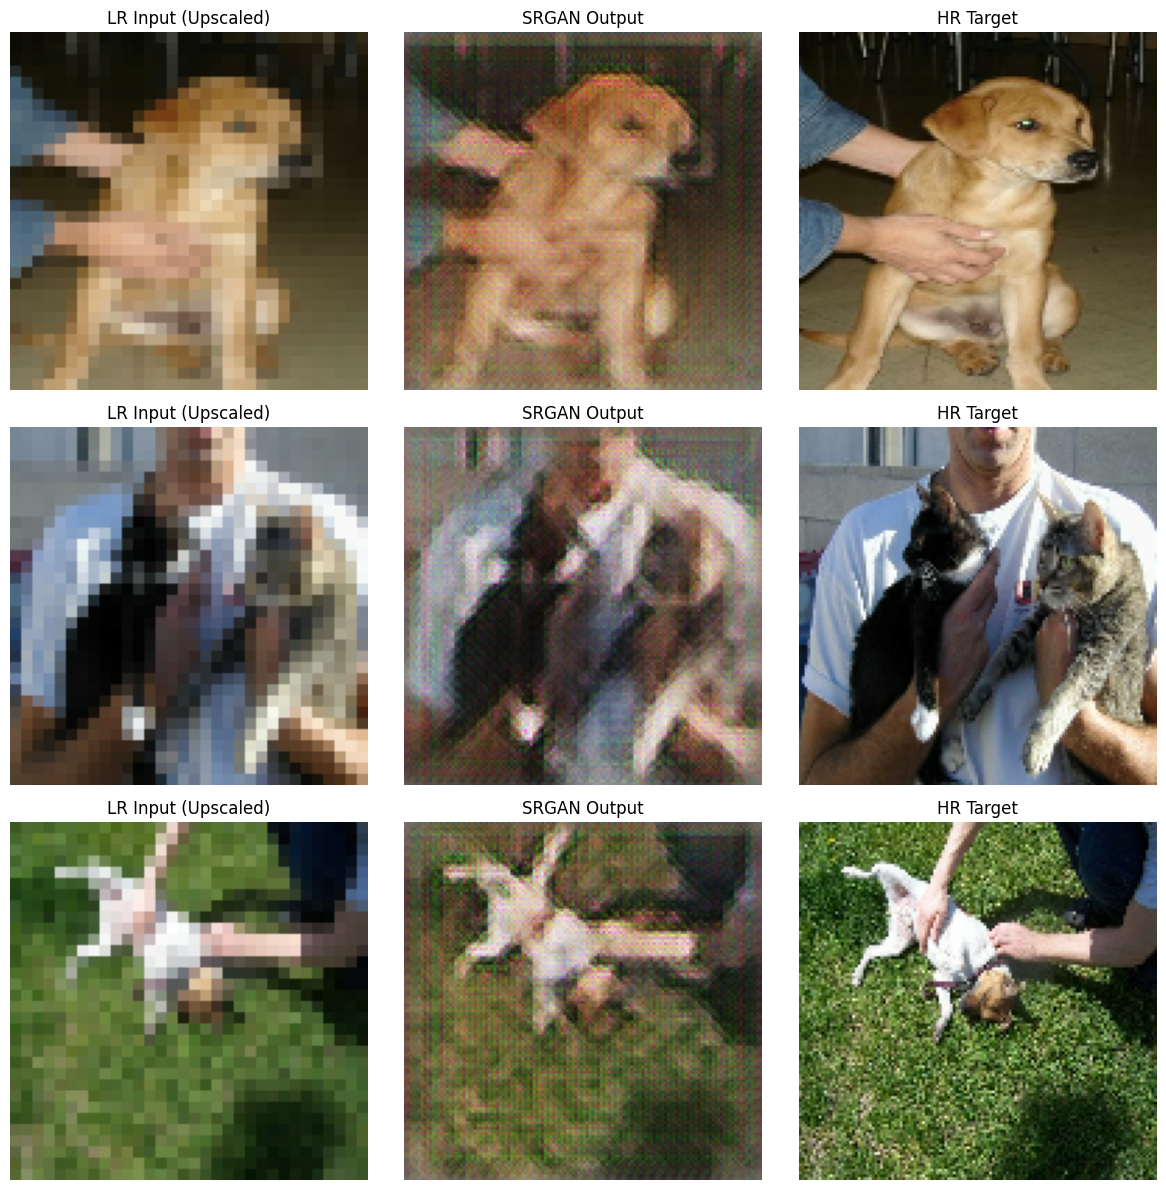

Figure saved to: /kaggle/working/Applied_AI_Midterm/srgan_epoch1_visual_check.png
Completed epochs: 1
Latest checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-22
No training performed.


In [30]:
# ==========================================
# STEP K33: VISUALIZE SRGAN OUTPUTS
# ==========================================

import os
import matplotlib.pyplot as plt
import tensorflow as tf
import numpy as np

print("===== SRGAN VISUAL INSPECTION =====")

# Take a few validation samples
num_examples = 3
sample_paths = val_df["filepath"].iloc[:num_examples].tolist()

lr_list = []
hr_list = []

for path in sample_paths:
    lr_img, hr_img = load_srgan_pair(path)
    lr_list.append(lr_img)
    hr_list.append(hr_img)

lr_batch = tf.stack(lr_list, axis=0)
hr_batch = tf.stack(hr_list, axis=0)

# Generate SRGAN outputs
sr_batch = generator(lr_batch, training=False)

# For display: upscale LR input to 128x128
lr_display = tf.image.resize(lr_batch, [128, 128], method="nearest")

# Clip all images to valid range
lr_display = tf.clip_by_value(lr_display, 0.0, 1.0)
sr_batch = tf.clip_by_value(sr_batch, 0.0, 1.0)
hr_batch = tf.clip_by_value(hr_batch, 0.0, 1.0)

# Plot
fig, axes = plt.subplots(num_examples, 3, figsize=(12, 4 * num_examples))

if num_examples == 1:
    axes = np.expand_dims(axes, axis=0)

for i in range(num_examples):
    axes[i, 0].imshow(lr_display[i].numpy())
    axes[i, 0].set_title("LR Input (Upscaled)")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(sr_batch[i].numpy())
    axes[i, 1].set_title("SRGAN Output")
    axes[i, 1].axis("off")

    axes[i, 2].imshow(hr_batch[i].numpy())
    axes[i, 2].set_title("HR Target")
    axes[i, 2].axis("off")

plt.tight_layout()

# Save figure
figure_path = os.path.join(PROJECT_DIR, "srgan_epoch1_visual_check.png")
plt.savefig(figure_path, dpi=150, bbox_inches="tight")
plt.show()

print("Figure saved to:", figure_path)
print("Completed epochs:", int(completed_epoch.numpy()))
print("Latest checkpoint:", checkpoint_manager.latest_checkpoint)
print("No training performed.")

In [31]:

# ==========================================
# STEP K34: SRGAN QUALITY CHECK
# ==========================================

import tensorflow as tf
import numpy as np

print("===== SRGAN EPOCH 1 QUALITY EVALUATION =====")

evaluation_dataset = (
    srgan_val_dataset
    .unbatch()
    .take(100)
    .batch(8)
)

results = {
    "bicubic_psnr": [],
    "bicubic_ssim": [],
    "srgan_psnr": [],
    "srgan_ssim": []
}

for lr_images, hr_images in evaluation_dataset:

    # Standard bicubic upscaling
    bicubic_images = tf.image.resize(
        lr_images,
        [128, 128],
        method="bicubic"
    )

    bicubic_images = tf.clip_by_value(
        bicubic_images, 0.0, 1.0
    )

    # SRGAN enhancement
    sr_images = generator(
        lr_images, training=False
    )

    sr_images = tf.clip_by_value(
        sr_images, 0.0, 1.0
    )

    results["bicubic_psnr"].extend(
        tf.image.psnr(
            hr_images, bicubic_images, max_val=1.0
        ).numpy()
    )

    results["bicubic_ssim"].extend(
        tf.image.ssim(
            hr_images, bicubic_images, max_val=1.0
        ).numpy()
    )

    results["srgan_psnr"].extend(
        tf.image.psnr(
            hr_images, sr_images, max_val=1.0
        ).numpy()
    )

    results["srgan_ssim"].extend(
        tf.image.ssim(
            hr_images, sr_images, max_val=1.0
        ).numpy()
    )

print("\nBicubic PSNR:", round(np.mean(results["bicubic_psnr"]), 3))
print("SRGAN PSNR:", round(np.mean(results["srgan_psnr"]), 3))
print("Bicubic SSIM:", round(np.mean(results["bicubic_ssim"]), 4))
print("SRGAN SSIM:", round(np.mean(results["srgan_ssim"]), 4))

print("\nCompleted epochs:", int(completed_epoch.numpy()))
print("No training performed.")


===== SRGAN EPOCH 1 QUALITY EVALUATION =====



Bicubic PSNR: 23.105
SRGAN PSNR: 17.541
Bicubic SSIM: 0.6402
SRGAN SSIM: 0.3833

Completed epochs: 1
No training performed.


In [32]:

# ==========================================
# STEP K35: DISCRIMINATOR BALANCE DIAGNOSTIC
# ==========================================

import tensorflow as tf
import numpy as np

print("===== SRGAN DISCRIMINATOR DIAGNOSTIC =====")

# Use one validation batch
lr_images, hr_images = next(iter(srgan_val_dataset))

# Generator prediction
generated_images = generator(
    lr_images, training=False
)

# Discriminator predictions
real_predictions = discriminator(
    hr_images, training=False
)

fake_predictions = discriminator(
    generated_images, training=False
)

real_scores = real_predictions.numpy().flatten()
fake_scores = fake_predictions.numpy().flatten()

print("Real-image discriminator scores:")
print(np.round(real_scores, 4))

print("\nGenerated-image discriminator scores:")
print(np.round(fake_scores, 4))

print("\nMean real-image score:",
      round(float(np.mean(real_scores)), 4))

print("Mean generated-image score:",
      round(float(np.mean(fake_scores)), 4))

print("\nCompleted epochs:", int(completed_epoch.numpy()))
print("No training performed.")


===== SRGAN DISCRIMINATOR DIAGNOSTIC =====
Real-image discriminator scores:
[0.     0.0016 0.0131 0.0908 0.     0.     0.0001 0.    ]

Generated-image discriminator scores:
[0.3208 0.0846 0.1798 0.5126 0.3171 0.013  0.4866 0.162 ]

Mean real-image score: 0.0132
Mean generated-image score: 0.2596

Completed epochs: 1
No training performed.


In [33]:

# ==========================================
# STEP K36: DISCRIMINATOR BATCHNORM DIAGNOSTIC
# ==========================================

import tensorflow as tf
import numpy as np

print("===== DISCRIMINATOR MODE COMPARISON =====")

# Use the same validation images
lr_images, hr_images = next(iter(srgan_val_dataset))
fake_images = generator(lr_images, training=False)

# Preserve every discriminator variable, including
# BatchNormalization moving statistics.
saved_discriminator_weights = [
    w.numpy().copy() for w in discriminator.weights
]

# Inference mode
real_inference = discriminator(
    hr_images, training=False
).numpy().flatten()

fake_inference = discriminator(
    fake_images, training=False
).numpy().flatten()

# Training mode: may update BatchNormalization statistics,
# which we restore immediately afterward.
try:
    real_training = discriminator(
        hr_images, training=True
    ).numpy().flatten()

    fake_training = discriminator(
        fake_images, training=True
    ).numpy().flatten()

finally:
    # Restore the exact original discriminator state
    discriminator.set_weights(saved_discriminator_weights)

print("\nINFERENCE MODE (training=False)")
print("Mean real score:", round(np.mean(real_inference), 4))
print("Mean fake score:", round(np.mean(fake_inference), 4))

print("\nTRAINING MODE (training=True)")
print("Mean real score:", round(np.mean(real_training), 4))
print("Mean fake score:", round(np.mean(fake_training), 4))

# Verify original discriminator state is unchanged
for original, current in zip(
    saved_discriminator_weights,
    discriminator.weights
):
    np.testing.assert_array_equal(
        original, current.numpy()
    )

print("\nDiscriminator weights and statistics preserved: True")
print("Completed epochs:", int(completed_epoch.numpy()))
print("No training performed.")


===== DISCRIMINATOR MODE COMPARISON =====

INFERENCE MODE (training=False)
Mean real score: 0.0132
Mean fake score: 0.2596

TRAINING MODE (training=True)
Mean real score: 0.9969
Mean fake score: 0.0063

Discriminator weights and statistics preserved: True
Completed epochs: 1
No training performed.


In [34]:

# ==========================================
# STEP K37: INSPECT BATCHNORM STATISTICS
# ==========================================

import numpy as np
import tensorflow as tf

print("===== DISCRIMINATOR BATCHNORM STATISTICS =====")

bn_layers = [
    layer for layer in discriminator.layers
    if isinstance(layer, tf.keras.layers.BatchNormalization)
]

print("Number of BatchNormalization layers:", len(bn_layers))

for i, layer in enumerate(bn_layers, start=1):

    moving_mean = layer.moving_mean.numpy()
    moving_var = layer.moving_variance.numpy()

    assert np.all(np.isfinite(moving_mean))
    assert np.all(np.isfinite(moving_var))

    print(f"\nBatchNorm layer {i}: {layer.name}")
    print("Moving mean range:",
          round(float(np.min(moving_mean)), 4),
          "to",
          round(float(np.max(moving_mean)), 4))

    print("Moving variance range:",
          round(float(np.min(moving_var)), 4),
          "to",
          round(float(np.max(moving_var)), 4))

    print("Moving variance average:",
          round(float(np.mean(moving_var)), 4))

print("\nBatchNorm statistics inspection complete.")
print("Completed epochs:", int(completed_epoch.numpy()))
print("No training performed.")


===== DISCRIMINATOR BATCHNORM STATISTICS =====
Number of BatchNormalization layers: 7

BatchNorm layer 1: batch_normalization_17
Moving mean range: -0.2784 to 0.3827
Moving variance range: 0.0002 to 0.0302
Moving variance average: 0.0043

BatchNorm layer 2: batch_normalization_18
Moving mean range: -0.4837 to 0.5418
Moving variance range: 0.049 to 1.0384
Moving variance average: 0.2254

BatchNorm layer 3: batch_normalization_19
Moving mean range: -0.6931 to 1.1151
Moving variance range: 0.2138 to 3.2344
Moving variance average: 0.7696

BatchNorm layer 4: batch_normalization_20
Moving mean range: -0.8619 to 0.9406
Moving variance range: 0.2163 to 1.7772
Moving variance average: 0.5251

BatchNorm layer 5: batch_normalization_21
Moving mean range: -1.346 to 1.4062
Moving variance range: 0.5949 to 4.5181
Moving variance average: 1.6052

BatchNorm layer 6: batch_normalization_22
Moving mean range: -1.1987 to 1.0139
Moving variance range: 0.4 to 3.6574
Moving variance average: 1.4852

BatchN

In [35]:

# ==========================================
# STEP K38: BATCHNORM UPDATE DIAGNOSTIC
# ==========================================

import numpy as np
import tensorflow as tf

print("===== BATCHNORM UPDATE DIAGNOSTIC =====")

lr_images, hr_images = next(iter(srgan_val_dataset))
fake_images = generator(lr_images, training=False)

# Preserve all discriminator state
original_weights = [
    w.numpy().copy() for w in discriminator.weights
]

def evaluate_after_bn_update(update_images):
    try:
        # Update BatchNorm statistics using the selected batch
        _ = discriminator(update_images, training=True)

        # Evaluate both image types using inference statistics
        real_score = float(tf.reduce_mean(
            discriminator(hr_images, training=False)
        ).numpy())

        fake_score = float(tf.reduce_mean(
            discriminator(fake_images, training=False)
        ).numpy())

        return real_score, fake_score

    finally:
        discriminator.set_weights(original_weights)


real_updated = evaluate_after_bn_update(hr_images)
fake_updated = evaluate_after_bn_update(fake_images)

print("\nAfter real-image BN update:")
print("Mean real score:", round(real_updated[0], 4))
print("Mean fake score:", round(real_updated[1], 4))

print("\nAfter generated-image BN update:")
print("Mean real score:", round(fake_updated[0], 4))
print("Mean fake score:", round(fake_updated[1], 4))

# Confirm original weights remain unchanged
for old, current in zip(original_weights, discriminator.weights):
    np.testing.assert_array_equal(old, current.numpy())

print("\nOriginal discriminator state preserved: True")
print("Completed epochs:", int(completed_epoch.numpy()))
print("No training performed.")


===== BATCHNORM UPDATE DIAGNOSTIC =====

After real-image BN update:
Mean real score: 0.019
Mean fake score: 0.3246

After generated-image BN update:
Mean real score: 0.0146
Mean fake score: 0.268

Original discriminator state preserved: True
Completed epochs: 1
No training performed.


In [36]:

# ==========================================
# STEP K39: ADJUST DISCRIMINATOR LEARNING RATE
# ==========================================

import tensorflow as tf

print("===== SRGAN LEARNING RATE ADJUSTMENT =====")

# Confirm the saved training progress
assert int(completed_epoch.numpy()) == 1
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 1964

old_g_lr = float(generator_optimizer.learning_rate.numpy())
old_d_lr = float(discriminator_optimizer.learning_rate.numpy())

print("Previous generator LR:", old_g_lr)
print("Previous discriminator LR:", old_d_lr)

# Keep generator LR unchanged
generator_optimizer.learning_rate.assign(1e-4)

# Reduce discriminator LR by a factor of 10
discriminator_optimizer.learning_rate.assign(1e-5)

print("\nUpdated generator LR:",
      float(generator_optimizer.learning_rate.numpy()))

print("Updated discriminator LR:",
      float(discriminator_optimizer.learning_rate.numpy()))

print("\nCompleted epochs:", int(completed_epoch.numpy()))
print("Completed batches:", int(completed_batch.numpy()))
print("Optimizer states retained: True")
print("No training performed.")


===== SRGAN LEARNING RATE ADJUSTMENT =====
Previous generator LR: 9.999999747378752e-05
Previous discriminator LR: 9.999999747378752e-05

Updated generator LR: 9.999999747378752e-05
Updated discriminator LR: 9.999999747378752e-06

Completed epochs: 1
Completed batches: 0
Optimizer states retained: True
No training performed.


In [37]:

# ==========================================
# STEP K40: SAVE UPDATED SRGAN CONFIGURATION
# ==========================================

print("===== SAVE SRGAN LEARNING RATE UPDATE =====")

assert int(completed_epoch.numpy()) == 1
assert int(completed_batch.numpy()) == 0

assert abs(
    float(generator_optimizer.learning_rate.numpy()) - 1e-4
) < 1e-8

assert abs(
    float(discriminator_optimizer.learning_rate.numpy()) - 1e-5
) < 1e-8

# Save models, optimizers, and training progress
updated_checkpoint = checkpoint_manager.save()

print("Checkpoint saved:", updated_checkpoint)
print("Completed epochs:", int(completed_epoch.numpy()))
print("Completed batches:", int(completed_batch.numpy()))
print("Generator LR:", float(generator_optimizer.learning_rate.numpy()))
print("Discriminator LR:", float(discriminator_optimizer.learning_rate.numpy()))
print("No training performed.")


===== SAVE SRGAN LEARNING RATE UPDATE =====
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-23
Completed epochs: 1
Completed batches: 0
Generator LR: 9.999999747378752e-05
Discriminator LR: 9.999999747378752e-06
No training performed.


In [38]:

# ==========================================
# STEP K41: CONTROLLED EPOCH 2 TRAINING
# ==========================================

print("===== EPOCH 2 CONTROLLED TRAINING =====")

assert int(completed_epoch.numpy()) == 1
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 1964

print("Generator LR:",
      float(generator_optimizer.learning_rate.numpy()))
print("Discriminator LR:",
      float(discriminator_optimizer.learning_rate.numpy()))

# Train 200 batches and pause automatically
train_srgan_resumable(
    max_epochs=150,
    max_batches=200
)

print("\n===== TRAINING STATUS =====")
print("Completed epochs:", int(completed_epoch.numpy()))
print("Completed batches in epoch 2:",
      int(completed_batch.numpy()))
print("Global steps:", int(global_step.numpy()))
print("Latest checkpoint:",
      checkpoint_manager.latest_checkpoint)

assert int(completed_epoch.numpy()) == 1
assert int(completed_batch.numpy()) == 200
assert int(global_step.numpy()) == 2164

print("\nControlled epoch 2 training completed successfully.")


===== EPOCH 2 CONTROLLED TRAINING =====
Generator LR: 9.999999747378752e-05
Discriminator LR: 9.999999747378752e-06
===== KAGGLE SRGAN TRAINING =====
Starting epoch: 2
Completed batches: 0
Target epochs: 150
Batches per epoch: 1964
Epoch 2/150 | Batch 100/1964 | G: 78.760 | D: 0.002
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-24


Corrupt JPEG data: 65 extraneous bytes before marker 0xd9


Epoch 2/150 | Batch 200/1964 | G: 61.837 | D: 0.001
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-25

Controlled training pause.
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-26
Completed batches: 200

===== TRAINING STATUS =====
Completed epochs: 1
Completed batches in epoch 2: 200
Global steps: 2164
Latest checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-26

Controlled epoch 2 training completed successfully.


In [39]:

# ==========================================
# STEP K42: COMPLETE SRGAN EPOCH 2
# ==========================================

import time

print("===== COMPLETE SRGAN EPOCH 2 =====")

assert int(completed_epoch.numpy()) == 1
assert int(completed_batch.numpy()) == 200
assert int(global_step.numpy()) == 2164

start_time = time.time()

# Resume at batch 201 and finish epoch 2
train_srgan_resumable(max_epochs=2)

elapsed = (time.time() - start_time) / 60

print("\n===== EPOCH 2 RESULTS =====")
print("Completed epochs:", int(completed_epoch.numpy()))
print("Completed batches:", int(completed_batch.numpy()))
print("Total training steps:", int(global_step.numpy()))
print("Elapsed minutes:", round(elapsed, 2))
print("Latest checkpoint:", checkpoint_manager.latest_checkpoint)

assert int(completed_epoch.numpy()) == 2
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 3928

print("\nSUCCESS: EPOCH 2/150 COMPLETED!")


===== COMPLETE SRGAN EPOCH 2 =====
===== KAGGLE SRGAN TRAINING =====
Starting epoch: 2
Completed batches: 200
Target epochs: 2
Batches per epoch: 1964


Corrupt JPEG data: 65 extraneous bytes before marker 0xd9


Epoch 2/2 | Batch 300/1964 | G: 85.405 | D: 0.002
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-27
Epoch 2/2 | Batch 400/1964 | G: 65.683 | D: 0.002
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-28
Epoch 2/2 | Batch 500/1964 | G: 68.150 | D: 0.001
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-29
Epoch 2/2 | Batch 600/1964 | G: 65.379 | D: 0.001
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-30


Corrupt JPEG data: 99 extraneous bytes before marker 0xd9
Corrupt JPEG data: 2226 extraneous bytes before marker 0xd9


Epoch 2/2 | Batch 700/1964 | G: 65.438 | D: 0.001
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-31


...

Epoch 2/2 | Batch 1100/1964 | G: 81.060 | D: 0.002
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-35
Epoch 2/2 | Batch 1200/1964 | G: 55.910 | D: 0.002
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-36


Corrupt JPEG data: 1153 extraneous bytes before marker 0xd9


Epoch 2/2 | Batch 1300/1964 | G: 56.467 | D: 0.001
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-37
Epoch 2/2 | Batch 1400/1964 | G: 72.444 | D: 0.001
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-38
Epoch 2/2 | Batch 1500/1964 | G: 58.930 | D: 0.001
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-39
Epoch 2/2 | Batch 1600/1964 | G: 62.701 | D: 0.001
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-40
Epoch 2/2 | Batch 1700/1964 | G: 60.871 | D: 0.001
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-41


Corrupt JPEG data: 239 extraneous bytes before marker 0xd9


Epoch 2/2 | Batch 1800/1964 | G: 66.351 | D: 0.001
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-42
Epoch 2/2 | Batch 1900/1964 | G: 68.329 | D: 0.001
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-43

Epoch 2/2 completed in 14.4 minutes
Checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-44

Training completed through epoch 2

===== EPOCH 2 RESULTS =====
Completed epochs: 2
Completed batches: 0
Total training steps: 3928
Elapsed minutes: 14.38
Latest checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-44

SUCCESS: EPOCH 2/150 COMPLETED!


In [40]:

# ==========================================
# STEP K43: EPOCH 2 QUALITY COMPARISON
# ==========================================

import tensorflow as tf
import numpy as np

print("===== SRGAN EPOCH 2 QUALITY EVALUATION =====")

assert int(completed_epoch.numpy()) == 2

# Use the same first 100 validation images
evaluation_dataset = (
    srgan_val_dataset
    .unbatch()
    .take(100)
    .batch(8)
)

bicubic_psnr = []
bicubic_ssim = []
srgan_psnr = []
srgan_ssim = []

for lr_images, hr_images in evaluation_dataset:

    bicubic = tf.image.resize(
        lr_images, [128, 128], method="bicubic"
    )
    bicubic = tf.clip_by_value(bicubic, 0.0, 1.0)

    enhanced = generator(lr_images, training=False)
    enhanced = tf.clip_by_value(enhanced, 0.0, 1.0)

    bicubic_psnr.extend(
        tf.image.psnr(hr_images, bicubic, max_val=1.0).numpy()
    )
    bicubic_ssim.extend(
        tf.image.ssim(hr_images, bicubic, max_val=1.0).numpy()
    )

    srgan_psnr.extend(
        tf.image.psnr(hr_images, enhanced, max_val=1.0).numpy()
    )
    srgan_ssim.extend(
        tf.image.ssim(hr_images, enhanced, max_val=1.0).numpy()
    )

print("\n===== QUALITY COMPARISON =====")
print("Bicubic PSNR:", round(float(np.mean(bicubic_psnr)), 3))
print("SRGAN PSNR:", round(float(np.mean(srgan_psnr)), 3))
print("Bicubic SSIM:", round(float(np.mean(bicubic_ssim)), 4))
print("SRGAN SSIM:", round(float(np.mean(srgan_ssim)), 4))

print("\nPrevious epoch 1 SRGAN results:")
print("PSNR: 17.541")
print("SSIM: 0.3833")

print("\nCompleted epochs:", int(completed_epoch.numpy()))
print("No training performed.")


===== SRGAN EPOCH 2 QUALITY EVALUATION =====



===== QUALITY COMPARISON =====
Bicubic PSNR: 23.105
SRGAN PSNR: 18.911
Bicubic SSIM: 0.6402
SRGAN SSIM: 0.4344

Previous epoch 1 SRGAN results:
PSNR: 17.541
SSIM: 0.3833

Completed epochs: 2
No training performed.


In [41]:

# ==========================================
# STEP K44: BACK UP SRGAN EPOCH 2
# ==========================================

assert int(completed_epoch.numpy()) == 2
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 3928

backup_path = create_srgan_backup()

print("\n===== EPOCH 2 BACKUP =====")
print("Completed epochs:", int(completed_epoch.numpy()))
print("Latest checkpoint:", checkpoint_manager.latest_checkpoint)
print("Backup ZIP:", backup_path)
print("Ready to download through Kaggle Output panel.")


===== SRGAN BACKUP CREATED =====
Completed epochs: 2
Completed batches: 0
Global steps: 3928
Latest checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-44
Backup file: /kaggle/working/SRGAN_Backup_E002_B0000.zip
Size (MB): 324.53

===== EPOCH 2 BACKUP =====
Completed epochs: 2
Latest checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-44
Backup ZIP: /kaggle/working/SRGAN_Backup_E002_B0000.zip
Ready to download through Kaggle Output panel.


In [42]:

# ==========================================
# STEP K46: TRAIN SRGAN THROUGH EPOCH 5
# ==========================================

import time

print("===== SRGAN EPOCHS 3 TO 5 =====")

# Verify that we are resuming correctly
assert int(completed_epoch.numpy()) == 2
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 3928

assert checkpoint_manager.latest_checkpoint is not None

print("Starting epoch:", int(completed_epoch.numpy()) + 1)
print("Target epoch: 5")
print("Generator LR:",
      float(generator_optimizer.learning_rate.numpy()))
print("Discriminator LR:",
      float(discriminator_optimizer.learning_rate.numpy()))

start_time = time.time()

# Resume existing training through epoch 5
train_srgan_resumable(max_epochs=5)

elapsed_minutes = (time.time() - start_time) / 60

print("\n===== TRAINING RESULTS =====")
print("Completed epochs:", int(completed_epoch.numpy()))
print("Completed batches:", int(completed_batch.numpy()))
print("Total gradient steps:", int(global_step.numpy()))
print("Elapsed minutes:", round(elapsed_minutes, 2))
print("Latest checkpoint:",
      checkpoint_manager.latest_checkpoint)

assert int(completed_epoch.numpy()) == 5
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 9820

print("\nSUCCESS: SRGAN COMPLETED 5 OF 150 EPOCHS!")


===== SRGAN EPOCHS 3 TO 5 =====
Starting epoch: 3
Target epoch: 5
Generator LR: 9.999999747378752e-05
Discriminator LR: 9.999999747378752e-06
===== KAGGLE SRGAN TRAINING =====
Starting epoch: 3
Completed batches: 0
Target epochs: 5
Batches per epoch: 1964
Epoch 3/5 | Batch 100/1964 | G: 94.791 | D: 0.001
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-45
Epoch 3/5 | Batch 200/1964 | G: 53.322 | D: 0.001
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-46


Corrupt JPEG data: 1153 extraneous bytes before marker 0xd9


Epoch 3/5 | Batch 300/1964 | G: 47.431 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-47


Corrupt JPEG data: 214 extraneous bytes before marker 0xd9


Epoch 3/5 | Batch 400/1964 | G: 61.266 | D: 0.002
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-48
Epoch 3/5 | Batch 500/1964 | G: 69.098 | D: 0.001
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-49


...

Epoch 5/5 | Batch 800/1964 | G: 50.394 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-92
Epoch 5/5 | Batch 900/1964 | G: 74.390 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-93
Epoch 5/5 | Batch 1000/1964 | G: 55.422 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-94


Corrupt JPEG data: 214 extraneous bytes before marker 0xd9


Epoch 5/5 | Batch 1100/1964 | G: 60.900 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-95
Epoch 5/5 | Batch 1200/1964 | G: 46.580 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-96
Epoch 5/5 | Batch 1300/1964 | G: 49.636 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-97
Epoch 5/5 | Batch 1400/1964 | G: 57.432 | D: 0.001
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-98


Corrupt JPEG data: 396 extraneous bytes before marker 0xd9
Corrupt JPEG data: 252 extraneous bytes before marker 0xd9


Epoch 5/5 | Batch 1500/1964 | G: 65.583 | D: 0.001
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-99
Epoch 5/5 | Batch 1600/1964 | G: 53.559 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-100
Epoch 5/5 | Batch 1700/1964 | G: 60.703 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-101
Epoch 5/5 | Batch 1800/1964 | G: 48.636 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-102
Epoch 5/5 | Batch 1900/1964 | G: 56.163 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-103

Epoch 5/5 completed in 7.8 minutes
Checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-104

Training completed through epoch 5

===== TRAINING RESULTS =====
Completed epochs: 5
Completed batches: 0
Total gradient steps: 9820
Elapsed minutes: 23.36
Latest checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/s

In [43]:

# ==========================================
# STEP K47: EPOCH 5 QUALITY EVALUATION
# ==========================================

import tensorflow as tf
import numpy as np

print("===== SRGAN EPOCH 5 QUALITY EVALUATION =====")

assert int(completed_epoch.numpy()) == 5
assert int(completed_batch.numpy()) == 0

evaluation_dataset = (
    srgan_val_dataset
    .unbatch()
    .take(100)
    .batch(8)
)

srgan_psnr = []
srgan_ssim = []

for lr_images, hr_images in evaluation_dataset:

    enhanced = generator(lr_images, training=False)
    enhanced = tf.clip_by_value(enhanced, 0.0, 1.0)

    srgan_psnr.extend(
        tf.image.psnr(hr_images, enhanced, max_val=1.0).numpy()
    )

    srgan_ssim.extend(
        tf.image.ssim(hr_images, enhanced, max_val=1.0).numpy()
    )

epoch5_psnr = float(np.mean(srgan_psnr))
epoch5_ssim = float(np.mean(srgan_ssim))

print("\n===== QUALITY COMPARISON =====")
print(f"{'Method':<20} {'PSNR (dB)':>12} {'SSIM':>10}")
print("-" * 44)
print(f"{'Bicubic':<20} {23.105:>12.3f} {0.6402:>10.4f}")
print(f"{'SRGAN Epoch 1':<20} {17.541:>12.3f} {0.3833:>10.4f}")
print(f"{'SRGAN Epoch 2':<20} {18.911:>12.3f} {0.4344:>10.4f}")
print(f"{'SRGAN Epoch 5':<20} {epoch5_psnr:>12.3f} {epoch5_ssim:>10.4f}")

print("\nCompleted epochs:", int(completed_epoch.numpy()))
print("No training performed.")


===== SRGAN EPOCH 5 QUALITY EVALUATION =====



===== QUALITY COMPARISON =====
Method                  PSNR (dB)       SSIM
--------------------------------------------
Bicubic                    23.105     0.6402
SRGAN Epoch 1              17.541     0.3833
SRGAN Epoch 2              18.911     0.4344
SRGAN Epoch 5              19.820     0.4483

Completed epochs: 5
No training performed.


In [44]:

# ==========================================
# STEP K48: BACK UP SRGAN EPOCH 5
# ==========================================

assert int(completed_epoch.numpy()) == 5
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 9820

backup_path = create_srgan_backup()

print("\n===== EPOCH 5 BACKUP =====")
print("Completed epochs:", int(completed_epoch.numpy()))
print("Global steps:", int(global_step.numpy()))
print("Latest checkpoint:", checkpoint_manager.latest_checkpoint)
print("Backup ZIP:", backup_path)
print("Ready to download through Kaggle Output panel.")


===== SRGAN BACKUP CREATED =====
Completed epochs: 5
Completed batches: 0
Global steps: 9820
Latest checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-104
Backup file: /kaggle/working/SRGAN_Backup_E005_B0000.zip
Size (MB): 325.04

===== EPOCH 5 BACKUP =====
Completed epochs: 5
Global steps: 9820
Latest checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-104
Backup ZIP: /kaggle/working/SRGAN_Backup_E005_B0000.zip
Ready to download through Kaggle Output panel.


In [45]:

# ==========================================
# STEP K50: TRAIN SRGAN THROUGH EPOCH 10
# ==========================================

import time

print("===== SRGAN EPOCHS 6 TO 10 =====")

# Verify that training will resume from epoch 6
assert int(completed_epoch.numpy()) == 5
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 9820

assert checkpoint_manager.latest_checkpoint is not None

# Verify the intended learning rates
assert abs(float(generator_optimizer.learning_rate.numpy()) - 1e-4) < 1e-8
assert abs(float(discriminator_optimizer.learning_rate.numpy()) - 1e-5) < 1e-8

print("Starting epoch:", int(completed_epoch.numpy()) + 1)
print("Target epoch: 10")
print("Generator LR:", float(generator_optimizer.learning_rate.numpy()))
print("Discriminator LR:", float(discriminator_optimizer.learning_rate.numpy()))

start_time = time.time()

# Resume from the saved progress and finish epoch 10
train_srgan_resumable(max_epochs=10)

elapsed_minutes = (time.time() - start_time) / 60

print("\n===== TRAINING RESULTS =====")
print("Completed epochs:", int(completed_epoch.numpy()))
print("Completed batches:", int(completed_batch.numpy()))
print("Total gradient steps:", int(global_step.numpy()))
print("Elapsed minutes:", round(elapsed_minutes, 2))
print("Latest checkpoint:", checkpoint_manager.latest_checkpoint)

assert int(completed_epoch.numpy()) == 10
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 19640

print("\nSUCCESS: SRGAN COMPLETED 10 OF 150 EPOCHS!")


===== SRGAN EPOCHS 6 TO 10 =====
Starting epoch: 6
Target epoch: 10
Generator LR: 9.999999747378752e-05
Discriminator LR: 9.999999747378752e-06
===== KAGGLE SRGAN TRAINING =====
Starting epoch: 6
Completed batches: 0
Target epochs: 10
Batches per epoch: 1964


Corrupt JPEG data: 65 extraneous bytes before marker 0xd9


Epoch 6/10 | Batch 100/1964 | G: 59.285 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-105
Epoch 6/10 | Batch 200/1964 | G: 53.797 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-106
Epoch 6/10 | Batch 300/1964 | G: 50.299 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-107
Epoch 6/10 | Batch 400/1964 | G: 57.430 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-108
Epoch 6/10 | Batch 500/1964 | G: 51.488 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-109


Corrupt JPEG data: 2226 extraneous bytes before marker 0xd9


Epoch 6/10 | Batch 600/1964 | G: 44.105 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-110
Epoch 6/10 | Batch 700/1964 | G: 40.879 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-111
Epoch 6/10 | Batch 800/1964 | G: 44.969 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-112


...

Epoch 10/10 | Batch 1600/1964 | G: 49.621 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-200
Epoch 10/10 | Batch 1700/1964 | G: 42.149 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-201
Epoch 10/10 | Batch 1800/1964 | G: 38.850 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-202


Corrupt JPEG data: 99 extraneous bytes before marker 0xd9


Epoch 10/10 | Batch 1900/1964 | G: 48.512 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-203


Corrupt JPEG data: 214 extraneous bytes before marker 0xd9



Epoch 10/10 completed in 7.8 minutes
Checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-204

Training completed through epoch 10

===== TRAINING RESULTS =====
Completed epochs: 10
Completed batches: 0
Total gradient steps: 19640
Elapsed minutes: 40.52
Latest checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-204

SUCCESS: SRGAN COMPLETED 10 OF 150 EPOCHS!


In [46]:

# ==========================================
# STEP K51: EPOCH 10 QUALITY EVALUATION
# ==========================================

import tensorflow as tf
import numpy as np

print("===== SRGAN EPOCH 10 QUALITY EVALUATION =====")

assert int(completed_epoch.numpy()) == 10
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 19640

evaluation_dataset = (
    srgan_val_dataset
    .unbatch()
    .take(100)
    .batch(8)
)

srgan_psnr = []
srgan_ssim = []

for lr_images, hr_images in evaluation_dataset:

    enhanced = generator(lr_images, training=False)
    enhanced = tf.clip_by_value(enhanced, 0.0, 1.0)

    srgan_psnr.extend(
        tf.image.psnr(
            hr_images, enhanced, max_val=1.0
        ).numpy()
    )

    srgan_ssim.extend(
        tf.image.ssim(
            hr_images, enhanced, max_val=1.0
        ).numpy()
    )

epoch10_psnr = float(np.mean(srgan_psnr))
epoch10_ssim = float(np.mean(srgan_ssim))

print("\n===== QUALITY COMPARISON =====")
print(f"{'Method':<20} {'PSNR (dB)':>12} {'SSIM':>10}")
print("-" * 44)

results = [
    ("Bicubic", 23.105, 0.6402),
    ("SRGAN Epoch 1", 17.541, 0.3833),
    ("SRGAN Epoch 2", 18.911, 0.4344),
    ("SRGAN Epoch 5", 19.820, 0.4483),
    ("SRGAN Epoch 10", epoch10_psnr, epoch10_ssim),
]

for name, psnr, ssim in results:
    print(f"{name:<20} {psnr:>12.3f} {ssim:>10.4f}")

print("\nCompleted epochs:", int(completed_epoch.numpy()))
print("No training performed.")


===== SRGAN EPOCH 10 QUALITY EVALUATION =====



===== QUALITY COMPARISON =====
Method                  PSNR (dB)       SSIM
--------------------------------------------
Bicubic                    23.105     0.6402
SRGAN Epoch 1              17.541     0.3833
SRGAN Epoch 2              18.911     0.4344
SRGAN Epoch 5              19.820     0.4483
SRGAN Epoch 10             19.807     0.4278

Completed epochs: 10
No training performed.


In [47]:

# ==========================================
# STEP K52: BACK UP SRGAN EPOCH 10
# ==========================================

print("===== BACK UP SRGAN EPOCH 10 =====")

assert int(completed_epoch.numpy()) == 10
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 19640

backup_path = create_srgan_backup()

print("\n===== EPOCH 10 BACKUP =====")
print("Completed epochs:", int(completed_epoch.numpy()))
print("Total gradient steps:", int(global_step.numpy()))
print("Latest checkpoint:", checkpoint_manager.latest_checkpoint)
print("Backup ZIP:", backup_path)
print("Ready to download through Kaggle Output panel.")


===== BACK UP SRGAN EPOCH 10 =====
===== SRGAN BACKUP CREATED =====
Completed epochs: 10
Completed batches: 0
Global steps: 19640
Latest checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-204
Backup file: /kaggle/working/SRGAN_Backup_E010_B0000.zip
Size (MB): 325.63

===== EPOCH 10 BACKUP =====
Completed epochs: 10
Total gradient steps: 19640
Latest checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-204
Backup ZIP: /kaggle/working/SRGAN_Backup_E010_B0000.zip
Ready to download through Kaggle Output panel.


===== SRGAN EPOCH 10 VISUAL INSPECTION =====


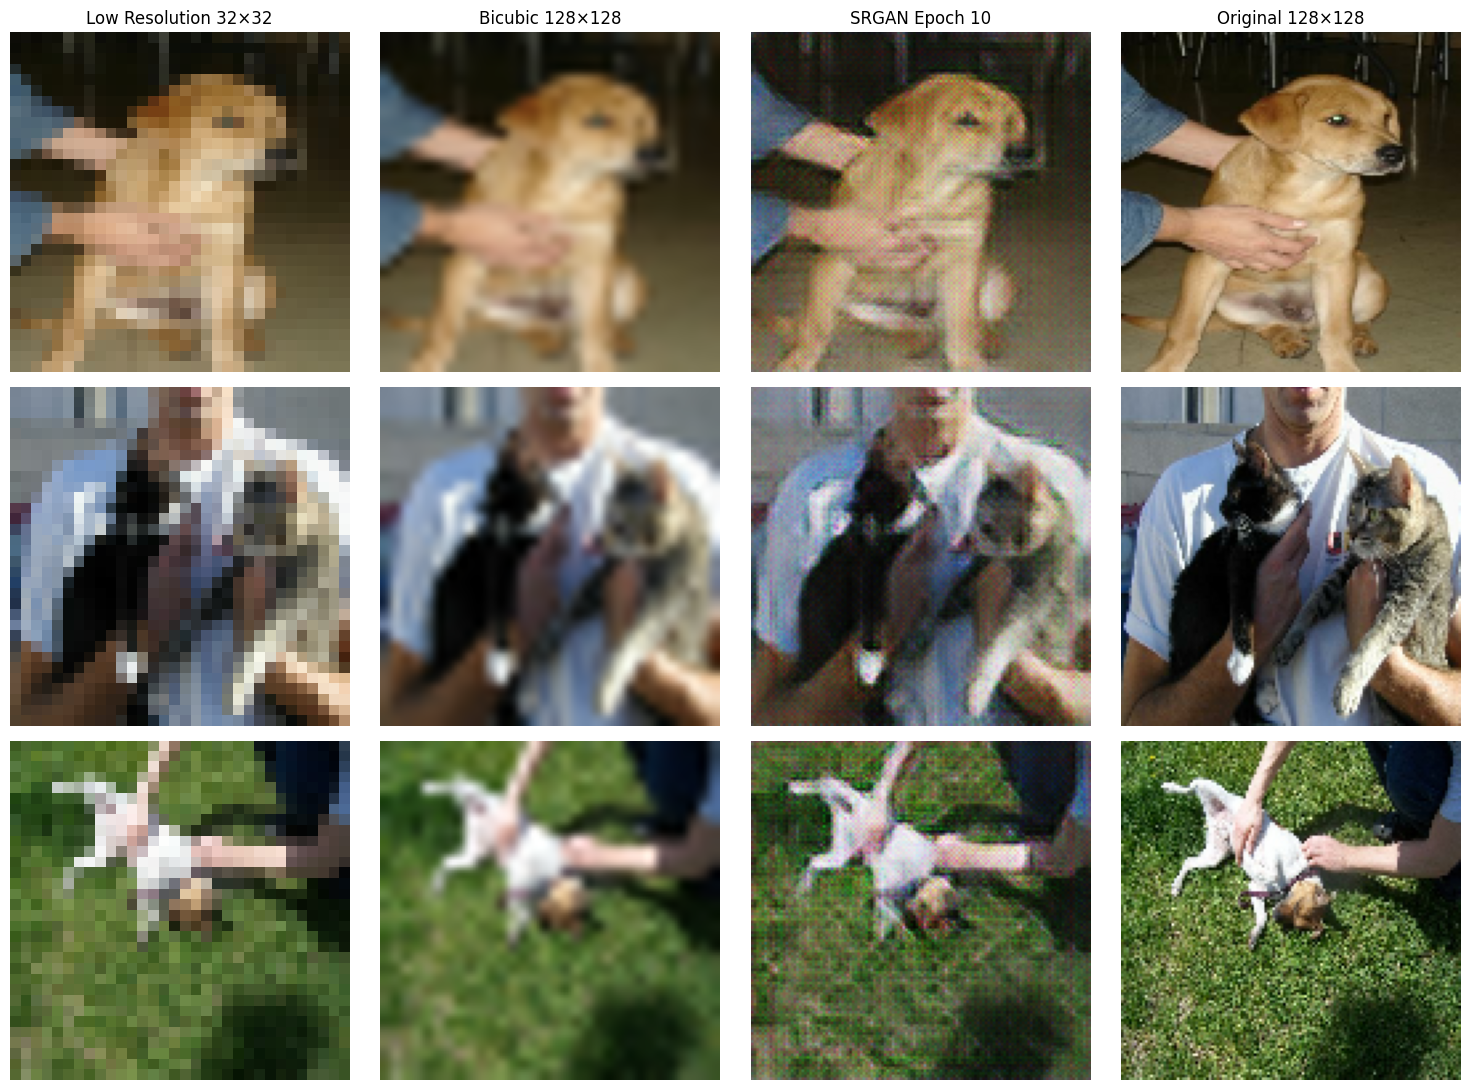


Saved visual comparison: /kaggle/working/Applied_AI_Midterm/srgan_epoch10_visual_check.png
Completed epochs: 10
No training performed.


In [48]:

# ==========================================
# STEP K54: VISUALIZE SRGAN EPOCH 10
# ==========================================

import tensorflow as tf
import matplotlib.pyplot as plt
import os

print("===== SRGAN EPOCH 10 VISUAL INSPECTION =====")

assert int(completed_epoch.numpy()) == 10

# Use the same first three validation images
lr_images, hr_images = next(iter(srgan_val_dataset))

lr_images = lr_images[:3]
hr_images = hr_images[:3]

# Generate enhanced images without training
sr_images = generator(lr_images, training=False)
sr_images = tf.clip_by_value(sr_images, 0.0, 1.0)

# Bicubic baseline
bicubic_images = tf.image.resize(
    lr_images,
    [128, 128],
    method="bicubic"
)
bicubic_images = tf.clip_by_value(
    bicubic_images, 0.0, 1.0
)

fig, axes = plt.subplots(3, 4, figsize=(15, 11))

column_titles = [
    "Low Resolution 32×32",
    "Bicubic 128×128",
    "SRGAN Epoch 10",
    "Original 128×128"
]

for col, title in enumerate(column_titles):
    axes[0, col].set_title(title, fontsize=12)

for i in range(3):
    images = [
        lr_images[i].numpy(),
        bicubic_images[i].numpy(),
        sr_images[i].numpy(),
        hr_images[i].numpy()
    ]

    for j, img in enumerate(images):
        axes[i, j].imshow(img, vmin=0, vmax=1)
        axes[i, j].axis("off")

plt.tight_layout()

output_path = (
    "/kaggle/working/Applied_AI_Midterm/"
    "srgan_epoch10_visual_check.png"
)

plt.savefig(output_path, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

print("\nSaved visual comparison:", output_path)
print("Completed epochs:", int(completed_epoch.numpy()))
print("No training performed.")


In [49]:

# ==========================================
# STEP K55: INSPECT GENERATOR LOSS COMPONENTS
# ==========================================

import tensorflow as tf

print("===== GENERATOR LOSS COMPONENT DIAGNOSTIC =====")

assert int(completed_epoch.numpy()) == 10

lr_images, hr_images = next(iter(srgan_val_dataset))

fake_images = generator(lr_images, training=False)

# VGG19 perceptual features
real_features = vgg_features(
    tf.keras.applications.vgg19.preprocess_input(
        hr_images * 255.0
    ),
    training=False
)

fake_features = vgg_features(
    tf.keras.applications.vgg19.preprocess_input(
        fake_images * 255.0
    ),
    training=False
)

perceptual_loss = tf.reduce_mean(
    tf.square(real_features - fake_features)
)

pixel_loss = tf.reduce_mean(
    tf.square(hr_images - fake_images)
)

fake_predictions = discriminator(
    fake_images,
    training=False
)

adversarial_loss = tf.reduce_mean(
    tf.keras.losses.binary_crossentropy(
        tf.ones_like(fake_predictions),
        fake_predictions
    )
)

print("\nRaw losses:")
print("Perceptual:", float(perceptual_loss.numpy()))
print("Pixel:", float(pixel_loss.numpy()))
print("Adversarial:", float(adversarial_loss.numpy()))

print("\nWeighted contributions:")
print("Perceptual:", float(perceptual_loss.numpy()))
print("Pixel × 0.001:", float((0.001 * pixel_loss).numpy()))
print("Adversarial × 0.001:",
      float((0.001 * adversarial_loss).numpy()))

print("\nCompleted epochs:", int(completed_epoch.numpy()))
print("No training performed.")


===== GENERATOR LOSS COMPONENT DIAGNOSTIC =====

Raw losses:
Perceptual: 49.838768005371094
Pixel: 0.010547824203968048
Adversarial: 1.756476879119873

Weighted contributions:
Perceptual: 49.838768005371094
Pixel × 0.001: 1.0547824786044657e-05
Adversarial × 0.001: 0.0017564769368618727

Completed epochs: 10
No training performed.


In [50]:

# ==========================================
# STEP K56: GENERATOR GRADIENT DIAGNOSTIC
# ==========================================

import tensorflow as tf
import numpy as np

print("===== GENERATOR GRADIENT CONTRIBUTIONS =====")

assert int(completed_epoch.numpy()) == 10

lr_images, hr_images = next(iter(srgan_val_dataset))

with tf.GradientTape(persistent=True) as tape:

    fake_images = generator(lr_images, training=False)

    real_features = vgg_features(
        tf.keras.applications.vgg19.preprocess_input(
            hr_images * 255.0
        ),
        training=False
    )

    fake_features = vgg_features(
        tf.keras.applications.vgg19.preprocess_input(
            fake_images * 255.0
        ),
        training=False
    )

    perceptual_loss = tf.reduce_mean(
        tf.square(real_features - fake_features)
    )

    pixel_loss = tf.reduce_mean(
        tf.square(hr_images - fake_images)
    )

    fake_predictions = discriminator(
        fake_images,
        training=False
    )

    adversarial_loss = tf.reduce_mean(
        tf.keras.losses.binary_crossentropy(
            tf.ones_like(fake_predictions),
            fake_predictions
        )
    )

weights = generator.trainable_variables

def gradient_norm(loss):
    gradients = tape.gradient(loss, weights)
    gradients = [g for g in gradients if g is not None]
    return float(tf.linalg.global_norm(gradients).numpy())

perceptual_grad = gradient_norm(perceptual_loss)
pixel_grad = gradient_norm(pixel_loss)
adversarial_grad = gradient_norm(adversarial_loss)

del tape

print("\nRaw gradient norms:")
print("Perceptual:", perceptual_grad)
print("Pixel:", pixel_grad)
print("Adversarial:", adversarial_grad)

print("\nCurrent weighted gradient norms:")
print("Perceptual:", perceptual_grad)
print("Pixel × 0.001:", pixel_grad * 0.001)
print("Adversarial × 0.001:", adversarial_grad * 0.001)

print("\nCompleted epochs:", int(completed_epoch.numpy()))
print("No training performed.")


===== GENERATOR GRADIENT CONTRIBUTIONS =====

Raw gradient norms:
Perceptual: 538.578857421875
Pixel: 0.19793209433555603
Adversarial: 63.496402740478516

Current weighted gradient norms:
Perceptual: 538.578857421875
Pixel × 0.001: 0.00019793209433555602
Adversarial × 0.001: 0.06349640274047852

Completed epochs: 10
No training performed.


In [51]:

# ==========================================
# STEP K57: COMPARE GENERATOR LOSS WEIGHTS
# ==========================================

print("===== PROPOSED GENERATOR LOSS BALANCE =====")

# Gradient norms measured in Step K56
gradients = {
    "Perceptual": 538.578857421875,
    "Pixel": 0.19793209433555603,
    "Adversarial": 63.496402740478516
}

current_weights = {
    "Perceptual": 1.0,
    "Pixel": 0.001,
    "Adversarial": 0.001
}

proposed_weights = {
    "Perceptual": 0.01,
    "Pixel": 10.0,
    "Adversarial": 0.001
}

print(f"{'Component':<15} {'Current norm':>15} {'Proposed norm':>15}")
print("-" * 48)

for name, grad_norm in gradients.items():
    current = grad_norm * current_weights[name]
    proposed = grad_norm * proposed_weights[name]

    print(f"{name:<15} {current:>15.6f} {proposed:>15.6f}")

print("\nCompleted epochs:", int(completed_epoch.numpy()))
print("No training performed.")


===== PROPOSED GENERATOR LOSS BALANCE =====
Component          Current norm   Proposed norm
------------------------------------------------
Perceptual           538.578857        5.385789
Pixel                  0.000198        1.979321
Adversarial            0.063496        0.063496

Completed epochs: 10
No training performed.


In [52]:

# ==========================================
# STEP K58: INSPECT EXISTING TRAINING FUNCTION
# ==========================================

import inspect

print("===== CURRENT SRGAN TRAINING FUNCTION =====")

try:
    print(inspect.getsource(srgan_train_step))
except (OSError, TypeError):
    print(
        "Source unavailable through inspect. "
        "Please copy the original training cell."
    )

print("\nCompleted epochs:", int(completed_epoch.numpy()))
print("Completed batches:", int(completed_batch.numpy()))
print("Latest checkpoint:", checkpoint_manager.latest_checkpoint)
print("No training performed.")


===== CURRENT SRGAN TRAINING FUNCTION =====
@tf.function
def srgan_train_step(lr_images, hr_images):

    with tf.GradientTape(persistent=True) as tape:

        generated_images = generator(
            lr_images, training=True
        )

        real_predictions = discriminator(
            hr_images, training=True
        )

        fake_predictions = discriminator(
            generated_images, training=True
        )

        # Discriminator loss
        d_loss = 0.5 * (
            adversarial_bce(
                tf.ones_like(real_predictions),
                real_predictions
            )
            +
            adversarial_bce(
                tf.zeros_like(fake_predictions),
                fake_predictions
            )
        )

        # VGG19 perceptual features
        real_features = vgg_features(
            tf.keras.applications.vgg19.preprocess_input(
                hr_images * 255.0
            ),
            training=False
        )

        fake_features = vg

In [53]:

# ==========================================
# STEP K59: UPDATE GENERATOR LOSS WEIGHTS
# ==========================================

import tensorflow as tf

print("===== UPDATE SRGAN GENERATOR LOSS =====")

assert int(completed_epoch.numpy()) == 10
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 19640

# Revised experimental loss weights
SRGAN_PERCEPTUAL_WEIGHT = 0.01
SRGAN_PIXEL_WEIGHT = 10.0
SRGAN_ADVERSARIAL_WEIGHT = 0.001

@tf.function
def srgan_train_step(lr_images, hr_images):

    with tf.GradientTape(persistent=True) as tape:

        generated_images = generator(
            lr_images, training=True
        )

        real_predictions = discriminator(
            hr_images, training=True
        )

        fake_predictions = discriminator(
            generated_images, training=True
        )

        # Discriminator loss: unchanged
        d_loss = 0.5 * (
            adversarial_bce(
                tf.ones_like(real_predictions),
                real_predictions
            )
            +
            adversarial_bce(
                tf.zeros_like(fake_predictions),
                fake_predictions
            )
        )

        # VGG19 perceptual features
        real_features = vgg_features(
            tf.keras.applications.vgg19.preprocess_input(
                hr_images * 255.0
            ),
            training=False
        )

        fake_features = vgg_features(
            tf.keras.applications.vgg19.preprocess_input(
                generated_images * 255.0
            ),
            training=False
        )

        perceptual_loss = tf.reduce_mean(
            tf.square(real_features - fake_features)
        )

        # Pixel reconstruction loss
        pixel_loss = tf.reduce_mean(
            tf.square(hr_images - generated_images)
        )

        # Generator adversarial loss
        adversarial_loss = adversarial_bce(
            tf.ones_like(fake_predictions),
            fake_predictions
        )

        # Revised generator objective
        g_loss = (
            SRGAN_PERCEPTUAL_WEIGHT * perceptual_loss
            + SRGAN_PIXEL_WEIGHT * pixel_loss
            + SRGAN_ADVERSARIAL_WEIGHT * adversarial_loss
        )

    g_gradients = tape.gradient(
        g_loss, generator.trainable_variables
    )

    d_gradients = tape.gradient(
        d_loss, discriminator.trainable_variables
    )

    del tape

    generator_optimizer.apply_gradients(
        zip(g_gradients, generator.trainable_variables)
    )

    discriminator_optimizer.apply_gradients(
        zip(d_gradients, discriminator.trainable_variables)
    )

    return {
        "generator_loss": g_loss,
        "discriminator_loss": d_loss,
        "perceptual_loss": perceptual_loss,
        "pixel_loss": pixel_loss,
        "adversarial_loss": adversarial_loss
    }

print("Updated generator loss weights:")
print("Perceptual:", SRGAN_PERCEPTUAL_WEIGHT)
print("Pixel:", SRGAN_PIXEL_WEIGHT)
print("Adversarial:", SRGAN_ADVERSARIAL_WEIGHT)

print("\nGenerator and discriminator weights retained.")
print("Optimizer states retained.")
print("Completed epochs:", int(completed_epoch.numpy()))
print("No training performed.")


===== UPDATE SRGAN GENERATOR LOSS =====
Updated generator loss weights:
Perceptual: 0.01
Pixel: 10.0
Adversarial: 0.001

Generator and discriminator weights retained.
Optimizer states retained.
Completed epochs: 10
No training performed.


In [54]:

# ==========================================
# STEP K60: TEST REVISED SRGAN LOSS
# ==========================================

print("===== EPOCH 11 CONTROLLED TRAINING =====")

assert int(completed_epoch.numpy()) == 10
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 19640

print("Generator loss weights:")
print("Perceptual:", SRGAN_PERCEPTUAL_WEIGHT)
print("Pixel:", SRGAN_PIXEL_WEIGHT)
print("Adversarial:", SRGAN_ADVERSARIAL_WEIGHT)

# Resume from epoch 11 and train 200 batches
train_srgan_resumable(
    max_epochs=150,
    max_batches=200
)

print("\n===== TRAINING STATUS =====")
print("Completed epochs:", int(completed_epoch.numpy()))
print("Completed batches:", int(completed_batch.numpy()))
print("Global steps:", int(global_step.numpy()))
print("Latest checkpoint:", checkpoint_manager.latest_checkpoint)

assert int(completed_epoch.numpy()) == 10
assert int(completed_batch.numpy()) == 200
assert int(global_step.numpy()) == 19840

print("\nSUCCESS: 200 BATCHES COMPLETED WITH REVISED LOSS!")


===== EPOCH 11 CONTROLLED TRAINING =====
Generator loss weights:
Perceptual: 0.01
Pixel: 10.0
Adversarial: 0.001
===== KAGGLE SRGAN TRAINING =====
Starting epoch: 11
Completed batches: 0
Target epochs: 150
Batches per epoch: 1964
Epoch 11/150 | Batch 100/1964 | G: 0.644 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-205
Epoch 11/150 | Batch 200/1964 | G: 0.645 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-206

Controlled training pause.
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-207
Completed batches: 200

===== TRAINING STATUS =====
Completed epochs: 10
Completed batches: 200
Global steps: 19840
Latest checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-207

SUCCESS: 200 BATCHES COMPLETED WITH REVISED LOSS!


In [55]:

# ==========================================
# STEP K61: COMPLETE SRGAN EPOCH 11
# ==========================================

import time

print("===== COMPLETE SRGAN EPOCH 11 =====")

# Verify existing progress
assert int(completed_epoch.numpy()) == 10
assert int(completed_batch.numpy()) == 200
assert int(global_step.numpy()) == 19840

# Verify revised generator loss weights
assert SRGAN_PERCEPTUAL_WEIGHT == 0.01
assert SRGAN_PIXEL_WEIGHT == 10.0
assert SRGAN_ADVERSARIAL_WEIGHT == 0.001

start_time = time.time()

# Resume from batch 201 and finish epoch 11
train_srgan_resumable(max_epochs=11)

elapsed = (time.time() - start_time) / 60

print("\n===== EPOCH 11 RESULTS =====")
print("Completed epochs:", int(completed_epoch.numpy()))
print("Completed batches:", int(completed_batch.numpy()))
print("Total gradient steps:", int(global_step.numpy()))
print("Elapsed minutes:", round(elapsed, 2))
print("Latest checkpoint:", checkpoint_manager.latest_checkpoint)

assert int(completed_epoch.numpy()) == 11
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 21604

print("\nSUCCESS: EPOCH 11/150 COMPLETED!")


===== COMPLETE SRGAN EPOCH 11 =====
===== KAGGLE SRGAN TRAINING =====
Starting epoch: 11
Completed batches: 200
Target epochs: 11
Batches per epoch: 1964
Epoch 11/11 | Batch 300/1964 | G: 0.483 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-208
Epoch 11/11 | Batch 400/1964 | G: 0.605 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-209
Epoch 11/11 | Batch 500/1964 | G: 0.546 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-210
Epoch 11/11 | Batch 600/1964 | G: 0.599 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-211
Epoch 11/11 | Batch 700/1964 | G: 0.580 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-212
Epoch 11/11 | Batch 800/1964 | G: 0.631 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-213


Corrupt JPEG data: 239 extraneous bytes before marker 0xd9


Epoch 11/11 | Batch 900/1964 | G: 0.520 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-214


Corrupt JPEG data: 396 extraneous bytes before marker 0xd9


Epoch 11/11 | Batch 1000/1964 | G: 0.472 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-215


...

Epoch 11/11 | Batch 1600/1964 | G: 0.449 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-221
Epoch 11/11 | Batch 1700/1964 | G: 0.561 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-222


Corrupt JPEG data: 99 extraneous bytes before marker 0xd9


Epoch 11/11 | Batch 1800/1964 | G: 0.462 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-223


Corrupt JPEG data: 65 extraneous bytes before marker 0xd9


Epoch 11/11 | Batch 1900/1964 | G: 0.475 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-224

Epoch 11/11 completed in 7.2 minutes
Checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-225

Training completed through epoch 11

===== EPOCH 11 RESULTS =====
Completed epochs: 11
Completed batches: 0
Total gradient steps: 21604
Elapsed minutes: 7.18
Latest checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-225

SUCCESS: EPOCH 11/150 COMPLETED!


In [56]:

# ==========================================
# STEP K62: EPOCH 11 QUALITY EVALUATION
# ==========================================

import tensorflow as tf
import numpy as np

print("===== SRGAN EPOCH 11 QUALITY EVALUATION =====")

assert int(completed_epoch.numpy()) == 11
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 21604

evaluation_dataset = (
    srgan_val_dataset
    .unbatch()
    .take(100)
    .batch(8)
)

srgan_psnr = []
srgan_ssim = []

for lr_images, hr_images in evaluation_dataset:

    enhanced = generator(lr_images, training=False)
    enhanced = tf.clip_by_value(enhanced, 0.0, 1.0)

    srgan_psnr.extend(
        tf.image.psnr(
            hr_images, enhanced, max_val=1.0
        ).numpy()
    )

    srgan_ssim.extend(
        tf.image.ssim(
            hr_images, enhanced, max_val=1.0
        ).numpy()
    )

epoch11_psnr = float(np.mean(srgan_psnr))
epoch11_ssim = float(np.mean(srgan_ssim))

print("\n===== QUALITY COMPARISON =====")
print(f"{'Method':<22} {'PSNR (dB)':>12} {'SSIM':>10}")
print("-" * 46)

results = [
    ("Bicubic", 23.105, 0.6402),
    ("SRGAN Epoch 5", 19.820, 0.4483),
    ("SRGAN Epoch 10", 19.807, 0.4278),
    ("SRGAN Epoch 11", epoch11_psnr, epoch11_ssim),
]

for name, psnr, ssim in results:
    print(f"{name:<22} {psnr:>12.3f} {ssim:>10.4f}")

print("\nChange from epoch 10:")
print("PSNR:", round(epoch11_psnr - 19.807, 3), "dB")
print("SSIM:", round(epoch11_ssim - 0.4278, 4))

print("\nCompleted epochs:", int(completed_epoch.numpy()))
print("No training performed.")


===== SRGAN EPOCH 11 QUALITY EVALUATION =====



===== QUALITY COMPARISON =====
Method                    PSNR (dB)       SSIM
----------------------------------------------
Bicubic                      23.105     0.6402
SRGAN Epoch 5                19.820     0.4483
SRGAN Epoch 10               19.807     0.4278
SRGAN Epoch 11               21.111     0.4944

Change from epoch 10:
PSNR: 1.304 dB
SSIM: 0.0666

Completed epochs: 11
No training performed.


In [57]:
# ==========================================
# STEP K63: BACK UP SRGAN EPOCH 11
# ==========================================

print("===== BACK UP SRGAN EPOCH 11 =====")

assert int(completed_epoch.numpy()) == 11
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 21604

backup_path = create_srgan_backup()

print("\n===== EPOCH 11 BACKUP =====")
print("Completed epochs:", int(completed_epoch.numpy()))
print("Total gradient steps:", int(global_step.numpy()))
print("Latest checkpoint:", checkpoint_manager.latest_checkpoint)
print("Backup ZIP:", backup_path)
print("Ready to download through Kaggle Output panel.")

===== BACK UP SRGAN EPOCH 11 =====
===== SRGAN BACKUP CREATED =====
Completed epochs: 11
Completed batches: 0
Global steps: 21604
Latest checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-225
Backup file: /kaggle/working/SRGAN_Backup_E011_B0000.zip
Size (MB): 325.73

===== EPOCH 11 BACKUP =====
Completed epochs: 11
Total gradient steps: 21604
Latest checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-225
Backup ZIP: /kaggle/working/SRGAN_Backup_E011_B0000.zip
Ready to download through Kaggle Output panel.


In [1]:

print("Kaggle kernel is responding")


Kaggle kernel is responding


In [2]:

# ==========================================
# STEP K64: CHECK RESTORATION FILES
# ==========================================

from pathlib import Path

print("===== SRGAN RESTORATION FILE CHECK =====")

project_dir = Path("/kaggle/working/Applied_AI_Midterm")

input_project = Path(
    "/kaggle/input/datasets/habibhsh/"
    "applied-ai-midterm-project/Applied_AI_Midterm"
)

print("Working project exists:", project_dir.exists())
print("Input project exists:", input_project.exists())

if input_project.exists():
    print("\nInput project files:")
    for p in sorted(input_project.iterdir()):
        print(" ", p.name)

print("\nZIP backups currently in /kaggle/working:")
for p in sorted(Path("/kaggle/working").glob("*.zip")):
    print(" ", p.name)

print("\nFile check completed. No training performed.")


===== SRGAN RESTORATION FILE CHECK =====
Working project exists: False
Input project exists: True

Input project files:
  Model_A_Checkpoints
  Repaired_Images
  data_pipeline.py
  dataset_verification.pkl
  model_A_test_results.csv
  model_train_split.csv
  model_train_split.csv.original.bak
  srgan_models.py
  test_split.csv
  test_split.csv.original.bak
  train_split.csv
  train_split.csv.original.bak
  validation_split.csv
  validation_split.csv.original.bak

ZIP backups currently in /kaggle/working:

File check completed. No training performed.


In [3]:

# ==========================================
# STEP K65: RESTORE WORKING PROJECT
# ==========================================

from pathlib import Path
import shutil
import sys

print("===== RESTORE WORKING PROJECT =====")

source = Path(
    "/kaggle/input/datasets/habibhsh/"
    "applied-ai-midterm-project/Applied_AI_Midterm"
)

destination = Path(
    "/kaggle/working/Applied_AI_Midterm"
)

assert source.is_dir(), "Input project dataset not found."

# Avoid overwriting any existing work
if not destination.exists():
    shutil.copytree(source, destination)
    print("Project copied successfully.")
else:
    print("Working project already exists. No files overwritten.")

if str(destination) not in sys.path:
    sys.path.insert(0, str(destination))

print("\nVerification:")
print("Working project exists:", destination.is_dir())
print("Data pipeline exists:", (destination / "data_pipeline.py").exists())
print("SRGAN models exist:", (destination / "srgan_models.py").exists())
print("Model A checkpoints exist:",
      (destination / "Model_A_Checkpoints").is_dir())

print("\nNo model training performed.")


===== RESTORE WORKING PROJECT =====
Project copied successfully.

Verification:
Working project exists: True
Data pipeline exists: True
SRGAN models exist: True
Model A checkpoints exist: True

No model training performed.


In [4]:

# ==========================================
# STEP K67: LOCATE UPLOADED SRGAN BACKUP
# ==========================================

from pathlib import Path

print("===== LOCATE SRGAN EPOCH 11 BACKUP =====")

backup_files = []

for file in Path("/kaggle/input").rglob("*"):
    if file.is_file() and (
        "SRGAN_Backup_E011" in file.name
        or "srgan-backup-e011" in file.name.lower()
    ):
        backup_files.append(file)

print("Matching files:", len(backup_files))

for file in backup_files:
    print("Path:", file)
    print("Size (MB):", round(file.stat().st_size / (1024**2), 2))

print("\nNo files modified.")
print("No training performed.")


===== LOCATE SRGAN EPOCH 11 BACKUP =====
Matching files: 0

No files modified.
No training performed.


In [6]:

# ==========================================
# STEP K68: INSPECT UPLOADED BACKUP DATASET
# ==========================================

from pathlib import Path

print("===== INSPECT KAGGLE INPUT DATASETS =====")

input_root = Path("/kaggle/input")

for dataset in sorted(input_root.iterdir()):
    print("\nDATASET:", dataset)

    if "e011" in dataset.name.lower() or "srgan" in dataset.name.lower():
        print("Backup dataset found!")

        files = sorted(dataset.rglob("*"))

        print("Total entries:", len(files))

        for file in files[:40]:
            print(
                "FILE:" if file.is_file() else "FOLDER:",
                file.relative_to(dataset)
            )

print("\nNo files modified.")
print("No training performed.")


===== INSPECT KAGGLE INPUT DATASETS =====

DATASET: /kaggle/input/datasets

No files modified.
No training performed.


In [7]:

# ==========================================
# STEP K69: FIND EPOCH 11 BACKUP DATASET
# ==========================================

from pathlib import Path

print("===== FIND SRGAN BACKUP DATASET =====")

root = Path("/kaggle/input/datasets")

if not root.exists():
    print("Dataset directory not found.")
else:
    for path in sorted(root.rglob("*")):
        if "srgan" in str(path).lower() or "e011" in str(path).lower():
            print(
                "FILE:" if path.is_file() else "FOLDER:",
                path
            )
            if path.is_file():
                print(
                    "Size (MB):",
                    round(path.stat().st_size / (1024 ** 2), 2)
                )

print("\nNo files modified.")
print("No training performed.")


===== FIND SRGAN BACKUP DATASET =====
FILE: /kaggle/input/datasets/habibhsh/applied-ai-midterm-project/Applied_AI_Midterm/srgan_models.py
Size (MB): 0.0
FOLDER: /kaggle/input/datasets/habibhsh/srgan-backup-e011-b0000
FOLDER: /kaggle/input/datasets/habibhsh/srgan-backup-e011-b0000/SRGAN_Checkpoints
FILE: /kaggle/input/datasets/habibhsh/srgan-backup-e011-b0000/SRGAN_Checkpoints/checkpoint
Size (MB): 0.0
FILE: /kaggle/input/datasets/habibhsh/srgan-backup-e011-b0000/SRGAN_Checkpoints/srgan-221.data-00000-of-00001
Size (MB): 70.72
FILE: /kaggle/input/datasets/habibhsh/srgan-backup-e011-b0000/SRGAN_Checkpoints/srgan-221.index
Size (MB): 0.02
FILE: /kaggle/input/datasets/habibhsh/srgan-backup-e011-b0000/SRGAN_Checkpoints/srgan-222.data-00000-of-00001
Size (MB): 70.72
FILE: /kaggle/input/datasets/habibhsh/srgan-backup-e011-b0000/SRGAN_Checkpoints/srgan-222.index
Size (MB): 0.02
FILE: /kaggle/input/datasets/habibhsh/srgan-backup-e011-b0000/SRGAN_Checkpoints/srgan-223.data-00000-of-00001
Size (M

In [8]:

# ==========================================
# STEP K70: RESTORE SRGAN CHECKPOINT FILES
# ==========================================

from pathlib import Path
import shutil

print("===== RESTORE EPOCH 11 CHECKPOINT FILES =====")

source = Path(
    "/kaggle/input/datasets/habibhsh/"
    "srgan-backup-e011-b0000/SRGAN_Checkpoints"
)

destination = Path(
    "/kaggle/working/Applied_AI_Midterm/"
    "SRGAN_Checkpoints"
)

assert source.is_dir(), "Backup checkpoint folder not found."
assert (source / "srgan-225.index").is_file()
assert (source / "srgan-225.data-00000-of-00001").is_file()

# Copy only if the destination has no checkpoint folder
assert not destination.exists(), (
    "Destination already exists. Check before overwriting."
)

shutil.copytree(source, destination)

print("Checkpoint files copied successfully.")
print("Destination:", destination)

print("\nRestored checkpoint files:")
for file in sorted(destination.iterdir()):
    print(" ", file.name)

print("\nLatest checkpoint files present:",
      (destination / "srgan-225.index").exists()
      and
      (destination / "srgan-225.data-00000-of-00001").exists())

print("No training performed.")


===== RESTORE EPOCH 11 CHECKPOINT FILES =====
Checkpoint files copied successfully.
Destination: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints

Restored checkpoint files:
  checkpoint
  srgan-221.data-00000-of-00001
  srgan-221.index
  srgan-222.data-00000-of-00001
  srgan-222.index
  srgan-223.data-00000-of-00001
  srgan-223.index
  srgan-224.data-00000-of-00001
  srgan-224.index
  srgan-225.data-00000-of-00001
  srgan-225.index

Latest checkpoint files present: True
No training performed.


In [9]:

# ==========================================
# STEP K71: CHECK SRGAN MODEL DEFINITIONS
# ==========================================

import sys
import inspect
from pathlib import Path

print("===== CHECK SRGAN MODEL DEFINITIONS =====")

project_dir = Path(
    "/kaggle/working/Applied_AI_Midterm"
)

if str(project_dir) not in sys.path:
    sys.path.insert(0, str(project_dir))

import srgan_models

print("Module loaded:", srgan_models.__file__)

for name in dir(srgan_models):
    if (
        "generator" in name.lower()
        or "discriminator" in name.lower()
    ):
        obj = getattr(srgan_models, name)

        if inspect.isfunction(obj):
            print("\nFunction:", name)
            print("Signature:", inspect.signature(obj))

print("\nNo models trained or modified.")


===== CHECK SRGAN MODEL DEFINITIONS =====
Module loaded: /kaggle/working/Applied_AI_Midterm/srgan_models.py

Function: build_discriminator
Signature: ()

Function: build_generator
Signature: (num_residual_blocks=8)

Function: discriminator_block
Signature: (x, filters, strides=1, use_bn=True)

No models trained or modified.


In [11]:

# ==========================================
# STEP K72: REBUILD SRGAN MODELS
# ==========================================

import tensorflow as tf
from srgan_models import build_generator, build_discriminator

print("===== REBUILD SRGAN MODELS =====")

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

# Rebuild original architectures
generator = build_generator(num_residual_blocks=8)
discriminator = build_discriminator()

print("\n===== GENERATOR =====")
print("Parameters:", generator.count_params())
print("Input shape:", generator.input_shape)
print("Output shape:", generator.output_shape)

print("\n===== DISCRIMINATOR =====")
print("Parameters:", discriminator.count_params())
print("Input shape:", discriminator.input_shape)
print("Output shape:", discriminator.output_shape)

# Verify compatibility with original architectures
assert generator.count_params() == 959427
assert discriminator.count_params() == 5219137

print("\nOriginal architectures reconstructed successfully.")
print("Checkpoint not yet loaded.")
print("No training performed.")


===== REBUILD SRGAN MODELS =====
TensorFlow version: 2.20.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]

===== GENERATOR =====
Parameters: 959427
Input shape: (None, 32, 32, 3)
Output shape: (None, 128, 128, 3)

===== DISCRIMINATOR =====
Parameters: 5219137
Input shape: (None, 128, 128, 3)
Output shape: (None, 1)

Original architectures reconstructed successfully.
Checkpoint not yet loaded.
No training performed.


In [12]:

# ==========================================
# STEP K73: RECREATE SRGAN CHECKPOINT OBJECTS
# ==========================================

import tensorflow as tf
from pathlib import Path

print("===== RECREATE SRGAN CHECKPOINT OBJECTS =====")

# Recreate original Adam optimizers
generator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=1e-4,
    beta_1=0.9,
    beta_2=0.999
)

discriminator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=1e-5,
    beta_1=0.9,
    beta_2=0.999
)

# Create optimizer variables before restoration
generator_optimizer.build(generator.trainable_variables)
discriminator_optimizer.build(discriminator.trainable_variables)

# Recreate checkpoint counters
completed_epoch = tf.Variable(
    0, dtype=tf.int64, trainable=False
)

completed_batch = tf.Variable(
    0, dtype=tf.int64, trainable=False
)

global_step = tf.Variable(
    0, dtype=tf.int64, trainable=False
)

# Locate restored checkpoint directory
checkpoint_dir = Path(
    "/kaggle/working/Applied_AI_Midterm/"
    "SRGAN_Checkpoints"
)

assert (checkpoint_dir / "srgan-225.index").is_file()

# Recreate checkpoint with original object names
checkpoint = tf.train.Checkpoint(
    epoch=completed_epoch,
    batch=completed_batch,
    global_step=global_step,
    generator=generator,
    discriminator=discriminator,
    generator_optimizer=generator_optimizer,
    discriminator_optimizer=discriminator_optimizer
)

checkpoint_manager = tf.train.CheckpointManager(
    checkpoint,
    directory=str(checkpoint_dir),
    max_to_keep=5,
    checkpoint_name="srgan"
)

print("Latest available checkpoint:",
      checkpoint_manager.latest_checkpoint)

print("Generator optimizer variables:",
      len(generator_optimizer.variables))

print("Discriminator optimizer variables:",
      len(discriminator_optimizer.variables))

print("\nCheckpoint objects ready for restoration.")
print("No training performed.")


===== RECREATE SRGAN CHECKPOINT OBJECTS =====
Latest available checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-225
Generator optimizer variables: 176
Discriminator optimizer variables: 70

Checkpoint objects ready for restoration.
No training performed.


In [13]:

# ==========================================
# STEP K74: RESTORE SRGAN EPOCH 11
# ==========================================

import tensorflow as tf

print("===== RESTORE SRGAN EPOCH 11 =====")

checkpoint_path = (
    "/kaggle/working/Applied_AI_Midterm/"
    "SRGAN_Checkpoints/srgan-225"
)

# Restore model weights, optimizers, and counters
restore_status = checkpoint.restore(checkpoint_path)

# Verify all existing checkpoint objects were restored
restore_status.assert_existing_objects_matched()

print("Checkpoint restored:", checkpoint_path)

print("\n===== RESTORED TRAINING PROGRESS =====")
print("Completed epochs:", int(completed_epoch.numpy()))
print("Completed batches:", int(completed_batch.numpy()))
print("Global steps:", int(global_step.numpy()))

print("\n===== RESTORED LEARNING RATES =====")
print("Generator LR:",
      float(generator_optimizer.learning_rate.numpy()))
print("Discriminator LR:",
      float(discriminator_optimizer.learning_rate.numpy()))

print("\n===== OPTIMIZER STATES =====")
print("Generator optimizer iterations:",
      int(generator_optimizer.iterations.numpy()))

print("Discriminator optimizer iterations:",
      int(discriminator_optimizer.iterations.numpy()))

# Verify exact training progress
assert int(completed_epoch.numpy()) == 11
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 21604

assert int(generator_optimizer.iterations.numpy()) == 21604
assert int(discriminator_optimizer.iterations.numpy()) == 21604

print("\nSUCCESS: EPOCH 11 TRAINING STATE RESTORED!")
print("No training performed.")


===== RESTORE SRGAN EPOCH 11 =====
Checkpoint restored: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-225

===== RESTORED TRAINING PROGRESS =====
Completed epochs: 11
Completed batches: 0
Global steps: 21604

===== RESTORED LEARNING RATES =====
Generator LR: 9.999999747378752e-05
Discriminator LR: 9.999999747378752e-06

===== OPTIMIZER STATES =====
Generator optimizer iterations: 21604
Discriminator optimizer iterations: 21604

SUCCESS: EPOCH 11 TRAINING STATE RESTORED!
No training performed.


In [14]:

# ==========================================
# STEP K75: VERIFY RESTORED DATASET PATHS
# ==========================================

from pathlib import Path
import pandas as pd

print("===== VERIFY SRGAN DATASET PATHS =====")

project_dir = Path(
    "/kaggle/working/Applied_AI_Midterm"
)

csv_files = [
    "model_train_split.csv",
    "validation_split.csv",
    "test_split.csv"
]

for filename in csv_files:

    csv_path = project_dir / filename

    assert csv_path.exists(), f"Missing: {filename}"

    df = pd.read_csv(csv_path)

    print("\nFile:", filename)
    print("Rows:", len(df))
    print("Columns:", list(df.columns))

    print("First row:")
    print(df.iloc[0].to_dict())

print("\nNo files modified.")
print("No training performed.")


===== VERIFY SRGAN DATASET PATHS =====

File: model_train_split.csv
Rows: 15705
Columns: ['filepath', 'label']
First row:
{'filepath': '/content/drive/MyDrive/CNN_Assignment/dogs-vs-cats-classification/train/dogs/dog_train_01240.jpg', 'label': 1}

File: validation_split.csv
Rows: 1746
Columns: ['filepath', 'label']
First row:
{'filepath': '/content/drive/MyDrive/CNN_Assignment/dogs-vs-cats-classification/train/dogs/dog_train_04958.jpg', 'label': 1}

File: test_split.csv
Rows: 7479
Columns: ['filepath', 'label']
First row:
{'filepath': '/content/drive/MyDrive/CNN_Assignment/dogs-vs-cats-classification/train/dogs/dog_train_02395.jpg', 'label': 1}

No files modified.
No training performed.


In [15]:

# ==========================================
# STEP K76: RESTORE KAGGLE IMAGE PATHS
# ==========================================

from pathlib import Path
import pandas as pd

print("===== RESTORE KAGGLE DATASET PATHS =====")

project_dir = Path("/kaggle/working/Applied_AI_Midterm")

image_root = Path(
    "/kaggle/input/datasets/blourdhuraju/"
    "dogs-vs-cats-classification/"
    "dogs-vs-cats-classification"
)

repaired_root = project_dir / "Repaired_Images"

print("Original image dataset exists:", image_root.is_dir())
print("Repaired images folder exists:", repaired_root.is_dir())

assert image_root.is_dir(), "Kaggle image dataset not found."

csv_files = [
    "model_train_split.csv",
    "validation_split.csv",
    "test_split.csv"
]

# Build a filename index once
image_index = {}

for root in [image_root, repaired_root]:
    if root.is_dir():
        for path in root.rglob("*"):
            if path.is_file() and path.suffix.lower() in (
                ".jpg", ".jpeg", ".png"
            ):
                image_index.setdefault(path.name, []).append(path)

# Resolve every image before changing any CSV
updated_data = {}

for filename in csv_files:
    csv_path = project_dir / filename
    df = pd.read_csv(csv_path)

    resolved_paths = []
    missing = []
    ambiguous = []

    for old_path in df["filepath"]:
        name = Path(old_path).name
        candidates = image_index.get(name, [])

        if not candidates:
            missing.append(name)
            resolved_paths.append(None)
        elif len(candidates) > 1:
            ambiguous.append(name)
            resolved_paths.append(None)
        else:
            resolved_paths.append(str(candidates[0]))

    print(
        filename,
        "| Rows:", len(df),
        "| Missing:", len(missing),
        "| Ambiguous:", len(ambiguous)
    )

    assert not missing, f"Missing images: {missing[:10]}"
    assert not ambiguous, f"Ambiguous filenames: {ambiguous[:10]}"

    df["filepath"] = resolved_paths
    updated_data[filename] = df

# Save only after all three splits pass validation
for filename, df in updated_data.items():
    df.to_csv(project_dir / filename, index=False)

print("\nSUCCESS: All dataset paths restored.")
print("No model training performed.")


===== RESTORE KAGGLE DATASET PATHS =====
Original image dataset exists: True
Repaired images folder exists: True
model_train_split.csv | Rows: 15705 | Missing: 0 | Ambiguous: 0
validation_split.csv | Rows: 1746 | Missing: 0 | Ambiguous: 0
test_split.csv | Rows: 7479 | Missing: 0 | Ambiguous: 0

SUCCESS: All dataset paths restored.
No model training performed.


In [16]:

# ==========================================
# STEP K77: REBUILD SRGAN DATASETS
# ==========================================

import tensorflow as tf
import pandas as pd
import numpy as np
from pathlib import Path

print("===== REBUILD SRGAN DATASETS =====")

project_dir = Path("/kaggle/working/Applied_AI_Midterm")

model_train_df = pd.read_csv(
    project_dir / "model_train_split.csv"
)

val_df = pd.read_csv(
    project_dir / "validation_split.csv"
)

test_df = pd.read_csv(
    project_dir / "test_split.csv"
)

SRGAN_BATCH_SIZE = 8

def load_srgan_pair(filepath):
    image_bytes = tf.io.read_file(filepath)

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])
    image = tf.image.convert_image_dtype(
        image, tf.float32
    )

    hr_image = tf.image.resize(
        image, [128, 128], method="bicubic"
    )
    hr_image = tf.clip_by_value(hr_image, 0.0, 1.0)

    lr_image = tf.image.resize(
        hr_image, [32, 32], method="area"
    )
    lr_image = tf.clip_by_value(lr_image, 0.0, 1.0)

    return lr_image, hr_image

def create_srgan_epoch_dataset(df, epoch_number):
    rng = np.random.default_rng(42 + epoch_number)

    paths = df["filepath"].to_numpy()
    paths = paths[rng.permutation(len(paths))]

    dataset = tf.data.Dataset.from_tensor_slices(paths)

    dataset = dataset.map(
        load_srgan_pair,
        num_parallel_calls=tf.data.AUTOTUNE,
        deterministic=True
    )

    dataset = dataset.batch(SRGAN_BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset

srgan_val_dataset = (
    tf.data.Dataset.from_tensor_slices(
        val_df["filepath"].to_numpy()
    )
    .map(
        load_srgan_pair,
        num_parallel_calls=tf.data.AUTOTUNE
    )
    .batch(SRGAN_BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

# Verify one validation batch
lr_images, hr_images = next(iter(srgan_val_dataset))

print("Training images:", len(model_train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))

print("\nLR batch shape:", lr_images.shape)
print("HR batch shape:", hr_images.shape)

assert lr_images.shape == (8, 32, 32, 3)
assert hr_images.shape == (8, 128, 128, 3)

print("\nSRGAN datasets reconstructed successfully.")
print("Completed epochs:", int(completed_epoch.numpy()))
print("No training performed.")


===== REBUILD SRGAN DATASETS =====
Training images: 15705
Validation images: 1746
Test images: 7479

LR batch shape: (8, 32, 32, 3)
HR batch shape: (8, 128, 128, 3)

SRGAN datasets reconstructed successfully.
Completed epochs: 11
No training performed.


In [17]:

# ==========================================
# STEP K78: RESTORE VGG19 FEATURE EXTRACTOR
# ==========================================

import tensorflow as tf

print("===== RESTORE VGG19 PERCEPTUAL NETWORK =====")

vgg_base = tf.keras.applications.VGG19(
    include_top=False,
    weights="imagenet",
    input_shape=(128, 128, 3)
)

vgg_features = tf.keras.Model(
    inputs=vgg_base.input,
    outputs=vgg_base.get_layer("block5_conv4").output,
    name="vgg19_perceptual_features"
)

vgg_features.trainable = False

# Verify output shape using the existing validation batch
features = vgg_features(
    tf.keras.applications.vgg19.preprocess_input(
        hr_images * 255.0
    ),
    training=False
)

print("VGG19 feature output shape:", features.shape)
print("VGG19 trainable:", vgg_features.trainable)

assert features.shape == (8, 8, 8, 512)
assert vgg_features.trainable is False

print("\nVGG19 perceptual network restored successfully.")
print("Completed epochs:", int(completed_epoch.numpy()))
print("No SRGAN training performed.")


===== RESTORE VGG19 PERCEPTUAL NETWORK =====
80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
VGG19 feature output shape: (8, 8, 8, 512)
VGG19 trainable: False

VGG19 perceptual network restored successfully.
Completed epochs: 11
No SRGAN training performed.


In [18]:

# ==========================================
# STEP K79: RESTORE REVISED SRGAN TRAINING
# ==========================================

import tensorflow as tf

print("===== RESTORE REVISED SRGAN TRAINING =====")

assert int(completed_epoch.numpy()) == 11
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 21604

SRGAN_PERCEPTUAL_WEIGHT = 0.01
SRGAN_PIXEL_WEIGHT = 10.0
SRGAN_ADVERSARIAL_WEIGHT = 0.001

adversarial_bce = tf.keras.losses.BinaryCrossentropy(
    from_logits=False
)

@tf.function
def srgan_train_step(lr_images, hr_images):

    with tf.GradientTape(persistent=True) as tape:

        generated_images = generator(
            lr_images, training=True
        )

        real_predictions = discriminator(
            hr_images, training=True
        )

        fake_predictions = discriminator(
            generated_images, training=True
        )

        d_loss = 0.5 * (
            adversarial_bce(
                tf.ones_like(real_predictions),
                real_predictions
            )
            +
            adversarial_bce(
                tf.zeros_like(fake_predictions),
                fake_predictions
            )
        )

        real_features = vgg_features(
            tf.keras.applications.vgg19.preprocess_input(
                hr_images * 255.0
            ),
            training=False
        )

        fake_features = vgg_features(
            tf.keras.applications.vgg19.preprocess_input(
                generated_images * 255.0
            ),
            training=False
        )

        perceptual_loss = tf.reduce_mean(
            tf.square(real_features - fake_features)
        )

        pixel_loss = tf.reduce_mean(
            tf.square(hr_images - generated_images)
        )

        adversarial_loss = adversarial_bce(
            tf.ones_like(fake_predictions),
            fake_predictions
        )

        g_loss = (
            SRGAN_PERCEPTUAL_WEIGHT * perceptual_loss
            + SRGAN_PIXEL_WEIGHT * pixel_loss
            + SRGAN_ADVERSARIAL_WEIGHT * adversarial_loss
        )

    g_gradients = tape.gradient(
        g_loss, generator.trainable_variables
    )

    d_gradients = tape.gradient(
        d_loss, discriminator.trainable_variables
    )

    del tape

    generator_optimizer.apply_gradients(
        zip(g_gradients, generator.trainable_variables)
    )

    discriminator_optimizer.apply_gradients(
        zip(d_gradients, discriminator.trainable_variables)
    )

    return {
        "generator_loss": g_loss,
        "discriminator_loss": d_loss,
        "perceptual_loss": perceptual_loss,
        "pixel_loss": pixel_loss,
        "adversarial_loss": adversarial_loss
    }

print("Perceptual weight:", SRGAN_PERCEPTUAL_WEIGHT)
print("Pixel weight:", SRGAN_PIXEL_WEIGHT)
print("Adversarial weight:", SRGAN_ADVERSARIAL_WEIGHT)

print("\nCompleted epochs:", int(completed_epoch.numpy()))
print("Global steps:", int(global_step.numpy()))
print("Training function restored. No training performed.")


===== RESTORE REVISED SRGAN TRAINING =====
Perceptual weight: 0.01
Pixel weight: 10.0
Adversarial weight: 0.001

Completed epochs: 11
Global steps: 21604
Training function restored. No training performed.


In [19]:

# ==========================================
# STEP K80: CHECK TRAINING CONTROLLER
# ==========================================

print("===== CHECK RESUMABLE TRAINING CONTROLLER =====")

controller_available = (
    "train_srgan_resumable" in globals()
)

print("Training controller available:", controller_available)

if controller_available:
    import inspect

    print(
        "Function signature:",
        inspect.signature(train_srgan_resumable)
    )
else:
    print(
        "The controller needs to be restored "
        "from the original notebook cell."
    )

print("\nCompleted epochs:", int(completed_epoch.numpy()))
print("Completed batches:", int(completed_batch.numpy()))
print("Global steps:", int(global_step.numpy()))
print("Latest checkpoint:", checkpoint_manager.latest_checkpoint)
print("No training performed.")


===== CHECK RESUMABLE TRAINING CONTROLLER =====
Training controller available: False
The controller needs to be restored from the original notebook cell.

Completed epochs: 11
Completed batches: 0
Global steps: 21604
Latest checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-225
No training performed.


In [22]:

# ==========================================
# STEP K83: FINAL SRGAN RECOVERY CHECK
# ==========================================

print("===== FINAL SRGAN RECOVERY CHECK =====")

assert int(completed_epoch.numpy()) == 11
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 21604

assert int(generator_optimizer.iterations.numpy()) == 21604
assert int(discriminator_optimizer.iterations.numpy()) == 21604

assert abs(float(generator_optimizer.learning_rate.numpy()) - 1e-4) < 1e-8
assert abs(float(discriminator_optimizer.learning_rate.numpy()) - 1e-5) < 1e-8

assert SRGAN_PERCEPTUAL_WEIGHT == 0.01
assert SRGAN_PIXEL_WEIGHT == 10.0
assert SRGAN_ADVERSARIAL_WEIGHT == 0.001

assert len(model_train_df) == 15705
assert len(val_df) == 1746

assert callable(srgan_train_step)
assert callable(train_srgan_resumable)
assert callable(create_srgan_epoch_dataset)

assert checkpoint_manager.latest_checkpoint.endswith("srgan-225")

print("Checkpoint:", checkpoint_manager.latest_checkpoint)
print("Completed epochs:", int(completed_epoch.numpy()))
print("Global steps:", int(global_step.numpy()))
print("Loss weights: 0.01 / 10.0 / 0.001")
print("Dataset: Ready")
print("Training controller: Ready")

print("\nSUCCESS: READY TO RESUME FROM EPOCH 12")
print("No training performed.")


===== FINAL SRGAN RECOVERY CHECK =====
Checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-225
Completed epochs: 11
Global steps: 21604
Loss weights: 0.01 / 10.0 / 0.001
Dataset: Ready
Training controller: Ready

SUCCESS: READY TO RESUME FROM EPOCH 12
No training performed.


In [23]:

# ==========================================
# STEP K84: RESUME SRGAN THROUGH EPOCH 15
# ==========================================

import time

print("===== RESUME SRGAN EPOCHS 12 TO 15 =====")

# Verify recovery state
assert int(completed_epoch.numpy()) == 11
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 21604

assert checkpoint_manager.latest_checkpoint.endswith("srgan-225")

print("Starting epoch:", int(completed_epoch.numpy()) + 1)
print("Target epoch: 15")
print("Generator LR:",
      float(generator_optimizer.learning_rate.numpy()))
print("Discriminator LR:",
      float(discriminator_optimizer.learning_rate.numpy()))

print("Generator loss weights:",
      SRGAN_PERCEPTUAL_WEIGHT,
      SRGAN_PIXEL_WEIGHT,
      SRGAN_ADVERSARIAL_WEIGHT)

start_time = time.time()

# Continue existing training, without repeating epochs
train_srgan_resumable(max_epochs=15)

elapsed_minutes = (time.time() - start_time) / 60

print("\n===== TRAINING RESULTS =====")
print("Completed epochs:", int(completed_epoch.numpy()))
print("Completed batches:", int(completed_batch.numpy()))
print("Total gradient steps:", int(global_step.numpy()))
print("Elapsed minutes:", round(elapsed_minutes, 2))
print("Latest checkpoint:",
      checkpoint_manager.latest_checkpoint)

assert int(completed_epoch.numpy()) == 15
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 29460

print("\nSUCCESS: SRGAN COMPLETED 15 OF 150 EPOCHS!")


===== RESUME SRGAN EPOCHS 12 TO 15 =====
Starting epoch: 12
Target epoch: 15
Generator LR: 9.999999747378752e-05
Discriminator LR: 9.999999747378752e-06
Generator loss weights: 0.01 10.0 0.001
===== KAGGLE SRGAN TRAINING =====
Starting epoch: 12
Completed batches: 0
Target epochs: 15
Batches per epoch: 1964


Corrupt JPEG data: 1153 extraneous bytes before marker 0xd9
Corrupt JPEG data: 99 extraneous bytes before marker 0xd9


Epoch 12/15 | Batch 100/1964 | G: 0.465 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-226
Epoch 12/15 | Batch 200/1964 | G: 0.547 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-227
Epoch 12/15 | Batch 300/1964 | G: 0.527 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-228
Epoch 12/15 | Batch 400/1964 | G: 0.516 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-229


Corrupt JPEG data: 252 extraneous bytes before marker 0xd9


Epoch 12/15 | Batch 500/1964 | G: 0.507 | D: 0.001
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-230
Epoch 12/15 | Batch 600/1964 | G: 0.591 | D: 0.007
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-231


...

Epoch 15/15 | Batch 1700/1964 | G: 0.522 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-302
Epoch 15/15 | Batch 1800/1964 | G: 0.666 | D: 0.005
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-303


Corrupt JPEG data: 252 extraneous bytes before marker 0xd9


Epoch 15/15 | Batch 1900/1964 | G: 0.514 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-304


Corrupt JPEG data: 1153 extraneous bytes before marker 0xd9



Epoch 15/15 completed in 7.5 minutes
Checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-305

Training completed through epoch 15

===== TRAINING RESULTS =====
Completed epochs: 15
Completed batches: 0
Total gradient steps: 29460
Elapsed minutes: 30.26
Latest checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-305

SUCCESS: SRGAN COMPLETED 15 OF 150 EPOCHS!


In [24]:

# ==========================================
# STEP K85: EPOCH 15 QUALITY EVALUATION
# ==========================================

import tensorflow as tf
import numpy as np

print("===== SRGAN EPOCH 15 QUALITY EVALUATION =====")

assert int(completed_epoch.numpy()) == 15
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 29460

evaluation_dataset = (
    srgan_val_dataset
    .unbatch()
    .take(100)
    .batch(8)
)

srgan_psnr = []
srgan_ssim = []

for lr_images, hr_images in evaluation_dataset:

    enhanced = generator(lr_images, training=False)
    enhanced = tf.clip_by_value(enhanced, 0.0, 1.0)

    srgan_psnr.extend(
        tf.image.psnr(
            hr_images, enhanced, max_val=1.0
        ).numpy()
    )

    srgan_ssim.extend(
        tf.image.ssim(
            hr_images, enhanced, max_val=1.0
        ).numpy()
    )

epoch15_psnr = float(np.mean(srgan_psnr))
epoch15_ssim = float(np.mean(srgan_ssim))

print("\n===== QUALITY COMPARISON =====")
print(f"{'Method':<22} {'PSNR (dB)':>12} {'SSIM':>10}")
print("-" * 46)

results = [
    ("Bicubic", 23.105, 0.6402),
    ("SRGAN Epoch 10", 19.807, 0.4278),
    ("SRGAN Epoch 11", 21.111, 0.4944),
    ("SRGAN Epoch 15", epoch15_psnr, epoch15_ssim),
]

for name, psnr, ssim in results:
    print(f"{name:<22} {psnr:>12.3f} {ssim:>10.4f}")

print("\nChange from epoch 11:")
print("PSNR:", round(epoch15_psnr - 21.111, 3), "dB")
print("SSIM:", round(epoch15_ssim - 0.4944, 4))

print("\nCompleted epochs:", int(completed_epoch.numpy()))
print("No training performed.")


===== SRGAN EPOCH 15 QUALITY EVALUATION =====



===== QUALITY COMPARISON =====
Method                    PSNR (dB)       SSIM
----------------------------------------------
Bicubic                      23.105     0.6402
SRGAN Epoch 10               19.807     0.4278
SRGAN Epoch 11               21.111     0.4944
SRGAN Epoch 15               21.800     0.5695

Change from epoch 11:
PSNR: 0.689 dB
SSIM: 0.0751

Completed epochs: 15
No training performed.


In [25]:

# ==========================================
# STEP K86: BACK UP SRGAN EPOCH 15
# ==========================================

import os
import zipfile
from pathlib import Path

print("===== BACK UP SRGAN EPOCH 15 =====")

assert int(completed_epoch.numpy()) == 15
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 29460

checkpoint_folder = Path(
    "/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints"
)

backup_path = Path(
    "/kaggle/working/SRGAN_Backup_E015_B0000.zip"
)

assert checkpoint_manager.latest_checkpoint.endswith("srgan-305")
assert (checkpoint_folder / "srgan-305.index").is_file()

# Package checkpoints without altering them
with zipfile.ZipFile(
    backup_path, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for file in sorted(checkpoint_folder.rglob("*")):
        if file.is_file():
            archive.write(
                file,
                arcname=str(file.relative_to(checkpoint_folder.parent))
            )

# Verify that the ZIP is readable
with zipfile.ZipFile(backup_path) as archive:
    assert archive.testzip() is None
    assert any(
        name.endswith("srgan-305.index")
        for name in archive.namelist()
    )

print("Backup created:", backup_path)
print("Size (MB):", round(backup_path.stat().st_size / (1024**2), 2))
print("Completed epochs:", int(completed_epoch.numpy()))
print("Latest checkpoint:", checkpoint_manager.latest_checkpoint)
print("No training performed.")


===== BACK UP SRGAN EPOCH 15 =====
Backup created: /kaggle/working/SRGAN_Backup_E015_B0000.zip
Size (MB): 324.85
Completed epochs: 15
Latest checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-305
No training performed.


In [26]:

# ==========================================
# STEP K87: TRAIN SRGAN THROUGH EPOCH 25
# ==========================================

import time

print("===== SRGAN EPOCHS 16 TO 25 =====")

assert int(completed_epoch.numpy()) == 15
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 29460

assert SRGAN_PERCEPTUAL_WEIGHT == 0.01
assert SRGAN_PIXEL_WEIGHT == 10.0
assert SRGAN_ADVERSARIAL_WEIGHT == 0.001

assert checkpoint_manager.latest_checkpoint.endswith("srgan-305")

print("Starting epoch:", int(completed_epoch.numpy()) + 1)
print("Target epoch: 25")

start_time = time.time()

train_srgan_resumable(max_epochs=25)

elapsed = (time.time() - start_time) / 60

print("\n===== TRAINING RESULTS =====")
print("Completed epochs:", int(completed_epoch.numpy()))
print("Completed batches:", int(completed_batch.numpy()))
print("Total gradient steps:", int(global_step.numpy()))
print("Elapsed minutes:", round(elapsed, 2))
print("Latest checkpoint:", checkpoint_manager.latest_checkpoint)

assert int(completed_epoch.numpy()) == 25
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 49100

print("\nSUCCESS: SRGAN COMPLETED 25 OF 150 EPOCHS!")


===== SRGAN EPOCHS 16 TO 25 =====
Starting epoch: 16
Target epoch: 25
===== KAGGLE SRGAN TRAINING =====
Starting epoch: 16
Completed batches: 0
Target epochs: 25
Batches per epoch: 1964
Epoch 16/25 | Batch 100/1964 | G: 0.555 | D: 0.001
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-306
Epoch 16/25 | Batch 200/1964 | G: 0.424 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-307
Epoch 16/25 | Batch 300/1964 | G: 0.510 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-308
Epoch 16/25 | Batch 400/1964 | G: 0.525 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-309
Epoch 16/25 | Batch 500/1964 | G: 0.700 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-310


Corrupt JPEG data: 239 extraneous bytes before marker 0xd9


Epoch 16/25 | Batch 600/1964 | G: 0.560 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-311
Epoch 16/25 | Batch 700/1964 | G: 0.525 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-312
Epoch 16/25 | Batch 800/1964 | G: 0.542 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-313


Corrupt JPEG data: 1153 extraneous bytes before marker 0xd9


Epoch 16/25 | Batch 900/1964 | G: 0.646 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-314
Epoch 16/25 | Batch 1000/1964 | G: 0.529 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-315


...

Epoch 25/25 | Batch 1700/1964 | G: 0.350 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-502


Corrupt JPEG data: 1153 extraneous bytes before marker 0xd9


Epoch 25/25 | Batch 1800/1964 | G: 0.526 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-503


Corrupt JPEG data: 2226 extraneous bytes before marker 0xd9


Epoch 25/25 | Batch 1900/1964 | G: 0.314 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-504

Epoch 25/25 completed in 7.5 minutes
Checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-505

Training completed through epoch 25

===== TRAINING RESULTS =====
Completed epochs: 25
Completed batches: 0
Total gradient steps: 49100
Elapsed minutes: 74.52
Latest checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-505

SUCCESS: SRGAN COMPLETED 25 OF 150 EPOCHS!


In [27]:

# ==========================================
# STEP K88: EPOCH 25 QUALITY EVALUATION
# ==========================================

import tensorflow as tf
import numpy as np

print("===== SRGAN EPOCH 25 QUALITY EVALUATION =====")

assert int(completed_epoch.numpy()) == 25
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 49100

evaluation_dataset = (
    srgan_val_dataset
    .unbatch()
    .take(100)
    .batch(8)
)

srgan_psnr = []
srgan_ssim = []

for lr_images, hr_images in evaluation_dataset:

    enhanced = generator(lr_images, training=False)
    enhanced = tf.clip_by_value(enhanced, 0.0, 1.0)

    srgan_psnr.extend(
        tf.image.psnr(
            hr_images, enhanced, max_val=1.0
        ).numpy()
    )

    srgan_ssim.extend(
        tf.image.ssim(
            hr_images, enhanced, max_val=1.0
        ).numpy()
    )

epoch25_psnr = float(np.mean(srgan_psnr))
epoch25_ssim = float(np.mean(srgan_ssim))

print("\n===== QUALITY COMPARISON =====")
print(f"{'Method':<22} {'PSNR (dB)':>12} {'SSIM':>10}")
print("-" * 46)

results = [
    ("Bicubic", 23.105, 0.6402),
    ("SRGAN Epoch 10", 19.807, 0.4278),
    ("SRGAN Epoch 11", 21.111, 0.4944),
    ("SRGAN Epoch 15", 21.800, 0.5695),
    ("SRGAN Epoch 25", epoch25_psnr, epoch25_ssim),
]

for name, psnr, ssim in results:
    print(f"{name:<22} {psnr:>12.3f} {ssim:>10.4f}")

print("\nChange from epoch 15:")
print("PSNR:", round(epoch25_psnr - 21.800, 3), "dB")
print("SSIM:", round(epoch25_ssim - 0.5695, 4))

print("\nCompleted epochs:", int(completed_epoch.numpy()))
print("No training performed.")


===== SRGAN EPOCH 25 QUALITY EVALUATION =====



===== QUALITY COMPARISON =====
Method                    PSNR (dB)       SSIM
----------------------------------------------
Bicubic                      23.105     0.6402
SRGAN Epoch 10               19.807     0.4278
SRGAN Epoch 11               21.111     0.4944
SRGAN Epoch 15               21.800     0.5695
SRGAN Epoch 25               22.478     0.6036

Change from epoch 15:
PSNR: 0.678 dB
SSIM: 0.0341

Completed epochs: 25
No training performed.


In [28]:

# ==========================================
# STEP K89: BACK UP SRGAN EPOCH 25
# ==========================================

import zipfile
from pathlib import Path

print("===== BACK UP SRGAN EPOCH 25 =====")

assert int(completed_epoch.numpy()) == 25
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 49100

checkpoint_folder = Path(
    "/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints"
)

backup_path = Path(
    "/kaggle/working/SRGAN_Backup_E025_B0000.zip"
)

assert checkpoint_manager.latest_checkpoint.endswith("srgan-505")
assert (checkpoint_folder / "srgan-505.index").is_file()

with zipfile.ZipFile(
    backup_path, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for file in sorted(checkpoint_folder.rglob("*")):
        if file.is_file():
            archive.write(
                file,
                arcname=str(file.relative_to(checkpoint_folder.parent))
            )

with zipfile.ZipFile(backup_path) as archive:
    assert archive.testzip() is None
    assert "SRGAN_Checkpoints/srgan-505.index" in archive.namelist()
    assert "SRGAN_Checkpoints/srgan-505.data-00000-of-00001" in archive.namelist()

print("Backup created:", backup_path)
print("Size (MB):", round(backup_path.stat().st_size / (1024**2), 2))
print("Completed epochs:", int(completed_epoch.numpy()))
print("Latest checkpoint:", checkpoint_manager.latest_checkpoint)
print("No training performed.")


===== BACK UP SRGAN EPOCH 25 =====
Backup created: /kaggle/working/SRGAN_Backup_E025_B0000.zip
Size (MB): 325.01
Completed epochs: 25
Latest checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-505
No training performed.


In [29]:

# ==========================================
# STEP K91: TRAIN SRGAN THROUGH EPOCH 35
# ==========================================

import time

print("===== SRGAN EPOCHS 26 TO 35 =====")

# Verify existing training progress
assert int(completed_epoch.numpy()) == 25
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 49100

assert checkpoint_manager.latest_checkpoint.endswith("srgan-505")

# Verify revised generator loss configuration
assert SRGAN_PERCEPTUAL_WEIGHT == 0.01
assert SRGAN_PIXEL_WEIGHT == 10.0
assert SRGAN_ADVERSARIAL_WEIGHT == 0.001

assert abs(float(generator_optimizer.learning_rate.numpy()) - 1e-4) < 1e-8
assert abs(float(discriminator_optimizer.learning_rate.numpy()) - 1e-5) < 1e-8

print("Starting epoch:", int(completed_epoch.numpy()) + 1)
print("Target epoch: 35")

start_time = time.time()

# Continue training without repeating completed epochs
train_srgan_resumable(max_epochs=35)

elapsed_minutes = (time.time() - start_time) / 60

print("\n===== TRAINING RESULTS =====")
print("Completed epochs:", int(completed_epoch.numpy()))
print("Completed batches:", int(completed_batch.numpy()))
print("Total gradient steps:", int(global_step.numpy()))
print("Elapsed minutes:", round(elapsed_minutes, 2))
print("Latest checkpoint:", checkpoint_manager.latest_checkpoint)

assert int(completed_epoch.numpy()) == 35
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 68740

print("\nSUCCESS: SRGAN COMPLETED 35 OF 150 EPOCHS!")


===== SRGAN EPOCHS 26 TO 35 =====
Starting epoch: 26
Target epoch: 35
===== KAGGLE SRGAN TRAINING =====
Starting epoch: 26
Completed batches: 0
Target epochs: 35
Batches per epoch: 1964
Epoch 26/35 | Batch 100/1964 | G: 0.433 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-506
Epoch 26/35 | Batch 200/1964 | G: 0.392 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-507


Corrupt JPEG data: 1153 extraneous bytes before marker 0xd9


Epoch 26/35 | Batch 300/1964 | G: 0.418 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-508
Epoch 26/35 | Batch 400/1964 | G: 0.449 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-509
Epoch 26/35 | Batch 500/1964 | G: 0.428 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-510
Epoch 26/35 | Batch 600/1964 | G: 0.331 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-511
Epoch 26/35 | Batch 700/1964 | G: 0.349 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-512
Epoch 26/35 | Batch 800/1964 | G: 0.431 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-513
Epoch 26/35 | Batch 900/1964 | G: 0.388 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-514


Corrupt JPEG data: 252 extraneous bytes before marker 0xd9


Epoch 26/35 | Batch 1000/1964 | G: 0.538 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-515


...

Epoch 35/35 | Batch 900/1964 | G: 0.361 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-694
Epoch 35/35 | Batch 1000/1964 | G: 0.380 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-695
Epoch 35/35 | Batch 1100/1964 | G: 0.388 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-696
Epoch 35/35 | Batch 1200/1964 | G: 0.427 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-697
Epoch 35/35 | Batch 1300/1964 | G: 0.418 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-698


Corrupt JPEG data: 65 extraneous bytes before marker 0xd9


Epoch 35/35 | Batch 1400/1964 | G: 0.337 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-699
Epoch 35/35 | Batch 1500/1964 | G: 0.320 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-700
Epoch 35/35 | Batch 1600/1964 | G: 0.370 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-701
Epoch 35/35 | Batch 1700/1964 | G: 0.371 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-702
Epoch 35/35 | Batch 1800/1964 | G: 0.360 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-703
Epoch 35/35 | Batch 1900/1964 | G: 0.415 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-704


Corrupt JPEG data: 214 extraneous bytes before marker 0xd9



Epoch 35/35 completed in 7.4 minutes
Checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-705

Training completed through epoch 35

===== TRAINING RESULTS =====
Completed epochs: 35
Completed batches: 0
Total gradient steps: 68740
Elapsed minutes: 74.43
Latest checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-705

SUCCESS: SRGAN COMPLETED 35 OF 150 EPOCHS!


In [30]:

# ==========================================
# STEP K92: EPOCH 35 QUALITY EVALUATION
# ==========================================

import tensorflow as tf
import numpy as np

print("===== SRGAN EPOCH 35 QUALITY EVALUATION =====")

assert int(completed_epoch.numpy()) == 35
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 68740

evaluation_dataset = (
    srgan_val_dataset
    .unbatch()
    .take(100)
    .batch(8)
)

srgan_psnr = []
srgan_ssim = []

for lr_images, hr_images in evaluation_dataset:

    enhanced = generator(lr_images, training=False)
    enhanced = tf.clip_by_value(enhanced, 0.0, 1.0)

    srgan_psnr.extend(
        tf.image.psnr(
            hr_images, enhanced, max_val=1.0
        ).numpy()
    )

    srgan_ssim.extend(
        tf.image.ssim(
            hr_images, enhanced, max_val=1.0
        ).numpy()
    )

epoch35_psnr = float(np.mean(srgan_psnr))
epoch35_ssim = float(np.mean(srgan_ssim))

print("\n===== QUALITY COMPARISON =====")
print(f"{'Method':<22} {'PSNR (dB)':>12} {'SSIM':>10}")
print("-" * 46)

results = [
    ("Bicubic", 23.105, 0.6402),
    ("SRGAN Epoch 15", 21.800, 0.5695),
    ("SRGAN Epoch 25", 22.478, 0.6036),
    ("SRGAN Epoch 35", epoch35_psnr, epoch35_ssim),
]

for name, psnr, ssim in results:
    print(f"{name:<22} {psnr:>12.3f} {ssim:>10.4f}")

print("\nChange from epoch 25:")
print("PSNR:", round(epoch35_psnr - 22.478, 3), "dB")
print("SSIM:", round(epoch35_ssim - 0.6036, 4))

print("\nCompleted epochs:", int(completed_epoch.numpy()))
print("No training performed.")


===== SRGAN EPOCH 35 QUALITY EVALUATION =====



===== QUALITY COMPARISON =====
Method                    PSNR (dB)       SSIM
----------------------------------------------
Bicubic                      23.105     0.6402
SRGAN Epoch 15               21.800     0.5695
SRGAN Epoch 25               22.478     0.6036
SRGAN Epoch 35               22.634     0.6162

Change from epoch 25:
PSNR: 0.156 dB
SSIM: 0.0126

Completed epochs: 35
No training performed.


In [31]:

# ==========================================
# STEP K93: BACK UP SRGAN EPOCH 35
# ==========================================

import zipfile
from pathlib import Path

print("===== BACK UP SRGAN EPOCH 35 =====")

assert int(completed_epoch.numpy()) == 35
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 68740

checkpoint_folder = Path(
    "/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints"
)

backup_path = Path(
    "/kaggle/working/SRGAN_Backup_E035_B0000.zip"
)

assert checkpoint_manager.latest_checkpoint.endswith("srgan-705")

with zipfile.ZipFile(
    backup_path, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for file in sorted(checkpoint_folder.rglob("*")):
        if file.is_file():
            archive.write(
                file,
                arcname=str(file.relative_to(checkpoint_folder.parent))
            )

with zipfile.ZipFile(backup_path) as archive:
    assert archive.testzip() is None
    assert "SRGAN_Checkpoints/srgan-705.index" in archive.namelist()
    assert "SRGAN_Checkpoints/srgan-705.data-00000-of-00001" in archive.namelist()

print("Backup created:", backup_path)
print("Size (MB):", round(backup_path.stat().st_size / (1024**2), 2))
print("Completed epochs:", int(completed_epoch.numpy()))
print("Latest checkpoint:", checkpoint_manager.latest_checkpoint)
print("No training performed.")


===== BACK UP SRGAN EPOCH 35 =====
Backup created: /kaggle/working/SRGAN_Backup_E035_B0000.zip
Size (MB): 324.59
Completed epochs: 35
Latest checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-705
No training performed.


In [32]:
from pathlib import Path

backup = Path("/kaggle/working/SRGAN_Backup_E035_B0000.zip")

print("Backup exists:", backup.exists())

if backup.exists():
    print("File:", backup)
    print("Size (MB):", round(backup.stat().st_size / 1024**2, 2))
else:
    print("Backup is not currently available in /kaggle/working.")

Backup exists: True
File: /kaggle/working/SRGAN_Backup_E035_B0000.zip
Size (MB): 324.59


In [33]:
from IPython.display import FileLink, display

display(FileLink("/kaggle/working/SRGAN_Backup_E035_B0000.zip"))

/kaggle/working/SRGAN_Backup_E035_B0000.zip

In [34]:

# ==========================================
# STEP K95: TRAIN SRGAN THROUGH EPOCH 50
# ==========================================

import time

print("===== SRGAN EPOCHS 36 TO 50 =====")

# Confirm exact recovery position
assert int(completed_epoch.numpy()) == 35
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 68740

assert checkpoint_manager.latest_checkpoint.endswith("srgan-705")

# Verify existing training configuration
assert SRGAN_PERCEPTUAL_WEIGHT == 0.01
assert SRGAN_PIXEL_WEIGHT == 10.0
assert SRGAN_ADVERSARIAL_WEIGHT == 0.001

assert abs(float(generator_optimizer.learning_rate.numpy()) - 1e-4) < 1e-8
assert abs(float(discriminator_optimizer.learning_rate.numpy()) - 1e-5) < 1e-8

print("Starting epoch:", int(completed_epoch.numpy()) + 1)
print("Target epoch: 50")

start_time = time.time()

# Continue from epoch 36 without repeating earlier epochs
train_srgan_resumable(max_epochs=50)

elapsed_minutes = (time.time() - start_time) / 60

print("\n===== TRAINING RESULTS =====")
print("Completed epochs:", int(completed_epoch.numpy()))
print("Completed batches:", int(completed_batch.numpy()))
print("Total gradient steps:", int(global_step.numpy()))
print("Elapsed minutes:", round(elapsed_minutes, 2))
print("Latest checkpoint:", checkpoint_manager.latest_checkpoint)

assert int(completed_epoch.numpy()) == 50
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 98200

print("\nSUCCESS: SRGAN COMPLETED 50 OF 150 EPOCHS!")


===== SRGAN EPOCHS 36 TO 50 =====
Starting epoch: 36
Target epoch: 50
===== KAGGLE SRGAN TRAINING =====
Starting epoch: 36
Completed batches: 0
Target epochs: 50
Batches per epoch: 1964


Corrupt JPEG data: 252 extraneous bytes before marker 0xd9


Epoch 36/50 | Batch 100/1964 | G: 0.572 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-706
Epoch 36/50 | Batch 200/1964 | G: 0.380 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-707


Corrupt JPEG data: 65 extraneous bytes before marker 0xd9


Epoch 36/50 | Batch 300/1964 | G: 0.486 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-708
Epoch 36/50 | Batch 400/1964 | G: 0.365 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-709
Epoch 36/50 | Batch 500/1964 | G: 0.390 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-710


...

Epoch 50/50 | Batch 1600/1964 | G: 0.321 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1001


Corrupt JPEG data: 2226 extraneous bytes before marker 0xd9


Epoch 50/50 | Batch 1700/1964 | G: 0.304 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1002


Corrupt JPEG data: 214 extraneous bytes before marker 0xd9


Epoch 50/50 | Batch 1800/1964 | G: 0.289 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1003
Epoch 50/50 | Batch 1900/1964 | G: 0.267 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1004

Epoch 50/50 completed in 7.4 minutes
Checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1005

Training completed through epoch 50

===== TRAINING RESULTS =====
Completed epochs: 50
Completed batches: 0
Total gradient steps: 98200
Elapsed minutes: 111.61
Latest checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1005

SUCCESS: SRGAN COMPLETED 50 OF 150 EPOCHS!


In [35]:

# ==========================================
# STEP K96: BACK UP SRGAN EPOCH 50
# ==========================================

import zipfile
from pathlib import Path

print("===== BACK UP SRGAN EPOCH 50 =====")

assert int(completed_epoch.numpy()) == 50
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 98200

checkpoint_folder = Path(
    "/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints"
)

backup_path = Path(
    "/kaggle/working/SRGAN_Backup_E050_B0000.zip"
)

assert checkpoint_manager.latest_checkpoint.endswith("srgan-1005")

with zipfile.ZipFile(
    backup_path, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for file in sorted(checkpoint_folder.rglob("*")):
        if file.is_file():
            archive.write(
                file,
                arcname=str(file.relative_to(checkpoint_folder.parent))
            )

with zipfile.ZipFile(backup_path) as archive:
    assert archive.testzip() is None
    assert "SRGAN_Checkpoints/srgan-1005.index" in archive.namelist()
    assert "SRGAN_Checkpoints/srgan-1005.data-00000-of-00001" in archive.namelist()

print("Backup created:", backup_path)
print("Size (MB):", round(backup_path.stat().st_size / (1024**2), 2))
print("Completed epochs:", int(completed_epoch.numpy()))
print("Latest checkpoint:", checkpoint_manager.latest_checkpoint)
print("No training performed.")


===== BACK UP SRGAN EPOCH 50 =====
Backup created: /kaggle/working/SRGAN_Backup_E050_B0000.zip
Size (MB): 325.18
Completed epochs: 50
Latest checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1005
No training performed.


In [36]:

# ==========================================
# STEP K98: EPOCH 50 QUALITY EVALUATION
# ==========================================

import tensorflow as tf
import numpy as np

print("===== SRGAN EPOCH 50 QUALITY EVALUATION =====")

assert int(completed_epoch.numpy()) == 50
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 98200

evaluation_dataset = (
    srgan_val_dataset
    .unbatch()
    .take(100)
    .batch(8)
)

srgan_psnr = []
srgan_ssim = []

for lr_images, hr_images in evaluation_dataset:
    enhanced = generator(lr_images, training=False)
    enhanced = tf.clip_by_value(enhanced, 0.0, 1.0)

    srgan_psnr.extend(
        tf.image.psnr(
            hr_images, enhanced, max_val=1.0
        ).numpy()
    )

    srgan_ssim.extend(
        tf.image.ssim(
            hr_images, enhanced, max_val=1.0
        ).numpy()
    )

epoch50_psnr = float(np.mean(srgan_psnr))
epoch50_ssim = float(np.mean(srgan_ssim))

print("\n===== QUALITY COMPARISON =====")
print(f"{'Method':<22} {'PSNR (dB)':>12} {'SSIM':>10}")
print("-" * 46)

results = [
    ("Bicubic", 23.105, 0.6402),
    ("SRGAN Epoch 25", 22.478, 0.6036),
    ("SRGAN Epoch 35", 22.634, 0.6162),
    ("SRGAN Epoch 50", epoch50_psnr, epoch50_ssim),
]

for name, psnr, ssim in results:
    print(f"{name:<22} {psnr:>12.3f} {ssim:>10.4f}")

print("\nChange from epoch 35:")
print("PSNR:", round(epoch50_psnr - 22.634, 3), "dB")
print("SSIM:", round(epoch50_ssim - 0.6162, 4))

print("\nCompleted epochs:", int(completed_epoch.numpy()))
print("No training performed.")


===== SRGAN EPOCH 50 QUALITY EVALUATION =====



===== QUALITY COMPARISON =====
Method                    PSNR (dB)       SSIM
----------------------------------------------
Bicubic                      23.105     0.6402
SRGAN Epoch 25               22.478     0.6036
SRGAN Epoch 35               22.634     0.6162
SRGAN Epoch 50               22.654     0.6148

Change from epoch 35:
PSNR: 0.02 dB
SSIM: -0.0014

Completed epochs: 50
No training performed.


In [ ]:

# ==========================================
# STEP K99: OVERNIGHT SRGAN TRAINING TO 150
# ==========================================

import time

print("===== OVERNIGHT SRGAN TRAINING =====")

assert int(completed_epoch.numpy()) == 50
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 98200
assert checkpoint_manager.latest_checkpoint.endswith("srgan-1005")

# Verify the revised training configuration
assert SRGAN_PERCEPTUAL_WEIGHT == 0.01
assert SRGAN_PIXEL_WEIGHT == 10.0
assert SRGAN_ADVERSARIAL_WEIGHT == 0.001

assert abs(float(generator_optimizer.learning_rate.numpy()) - 1e-4) < 1e-8
assert abs(float(discriminator_optimizer.learning_rate.numpy()) - 1e-5) < 1e-8

print("Starting epoch:", int(completed_epoch.numpy()) + 1)
print("Target epoch: 150")
print("Checkpoints saved every 100 batches and each epoch.")

start_time = time.time()

# Continue existing training toward epoch 150
train_srgan_resumable(max_epochs=150)

elapsed_minutes = (time.time() - start_time) / 60

print("\n===== OVERNIGHT TRAINING RESULTS =====")
print("Completed epochs:", int(completed_epoch.numpy()))
print("Completed batches:", int(completed_batch.numpy()))
print("Total gradient steps:", int(global_step.numpy()))
print("Elapsed minutes:", round(elapsed_minutes, 2))
print("Latest checkpoint:", checkpoint_manager.latest_checkpoint)

if int(completed_epoch.numpy()) == 150:
    assert int(completed_batch.numpy()) == 0
    assert int(global_step.numpy()) == 294600
    print("\nSUCCESS: SRGAN COMPLETED ALL 150 EPOCHS!")
else:
    print("\nTraining stopped before epoch 150.")


===== OVERNIGHT SRGAN TRAINING =====
Starting epoch: 51
Target epoch: 150
Checkpoints saved every 100 batches and each epoch.
===== KAGGLE SRGAN TRAINING =====
Starting epoch: 51
Completed batches: 0
Target epochs: 150
Batches per epoch: 1964


Corrupt JPEG data: 396 extraneous bytes before marker 0xd9
Corrupt JPEG data: 2226 extraneous bytes before marker 0xd9


Epoch 51/150 | Batch 100/1964 | G: 0.341 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1006
Epoch 51/150 | Batch 200/1964 | G: 0.219 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1007


Corrupt JPEG data: 1153 extraneous bytes before marker 0xd9


Epoch 51/150 | Batch 300/1964 | G: 0.272 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1008
Epoch 51/150 | Batch 400/1964 | G: 0.366 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1009
Epoch 51/150 | Batch 500/1964 | G: 0.299 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1010
Epoch 51/150 | Batch 600/1964 | G: 0.294 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1011
Epoch 51/150 | Batch 700/1964 | G: 0.280 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1012


...

Epoch 100/150 | Batch 700/1964 | G: 0.311 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1992
Epoch 100/150 | Batch 800/1964 | G: 0.243 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1993


Corrupt JPEG data: 252 extraneous bytes before marker 0xd9


Epoch 100/150 | Batch 900/1964 | G: 0.250 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1994


Corrupt JPEG data: 239 extraneous bytes before marker 0xd9


Epoch 100/150 | Batch 1000/1964 | G: 0.236 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1995
Epoch 100/150 | Batch 1100/1964 | G: 0.209 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1996
Epoch 100/150 | Batch 1200/1964 | G: 0.288 | D: 0.000
Checkpoint saved: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1997


In [1]:
from pathlib import Path

folder = Path(
    "/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints"
)

print("===== CHECK OVERNIGHT CHECKPOINTS =====")
print("Checkpoint folder exists:", folder.exists())

if folder.exists():
    files = sorted(folder.glob("srgan-*.index"))
    print("Number of checkpoint files:", len(files))
    print("Checkpoint names:")
    for f in files:
        print(" ", f.name)
else:
    print("Checkpoint folder not found.")

print("\nPreviously downloaded backup: Epoch 50")

===== CHECK OVERNIGHT CHECKPOINTS =====
Checkpoint folder exists: False
Checkpoint folder not found.

Previously downloaded backup: Epoch 50


In [2]:
from pathlib import Path

print("===== RECOVERY FILE CHECK =====")

locations = [
    Path("/kaggle/working/SRGAN_Backup_E050_B0000.zip"),
    Path("/kaggle/input"),
]

for location in locations:
    print(f"\n{location}")
    print("Exists:", location.exists())

    if location.is_dir():
        matches = list(location.rglob("SRGAN_Backup_E050_B0000.zip"))
        print("Matching backup files:", [str(p) for p in matches[:5]])

    elif location.is_file():
        print("Size (MB):", round(location.stat().st_size / 1024**2, 2))

===== RECOVERY FILE CHECK =====

/kaggle/working/SRGAN_Backup_E050_B0000.zip
Exists: False

/kaggle/input
Exists: True
Matching backup files: []


In [3]:
from pathlib import Path

print("===== STEP K104: LOCATE EPOCH 50 BACKUP =====")

input_dir = Path("/kaggle/input")

matches = sorted(input_dir.rglob("srgan-1005.index"))

print("Matching epoch 50 checkpoints:", len(matches))

for path in matches:
    print("\nCheckpoint index:", path)
    print("Checkpoint directory:", path.parent)

    data_file = path.with_name(
        "srgan-1005.data-00000-of-00001"
    )
    print("Checkpoint data exists:", data_file.is_file())

if not matches:
    print("\nNo extracted checkpoint found.")
    print("Checking for uploaded ZIP files:")

    for path in input_dir.rglob("*.zip"):
        print(path)

===== STEP K104: LOCATE EPOCH 50 BACKUP =====
Matching epoch 50 checkpoints: 1

Checkpoint index: /kaggle/input/datasets/habibhsh/srgan-backup-e050-b0000/SRGAN_Checkpoints/srgan-1005.index
Checkpoint directory: /kaggle/input/datasets/habibhsh/srgan-backup-e050-b0000/SRGAN_Checkpoints
Checkpoint data exists: True


In [4]:
# ==========================================
# STEP K105: RESTORE PROJECT + EPOCH 50 FILES
# ==========================================

from pathlib import Path
import shutil

print("===== STEP K105: RESTORE PROJECT + EPOCH 50 FILES =====")

input_dir = Path("/kaggle/input")
working_project = Path("/kaggle/working/Applied_AI_Midterm")
working_ckpt_dir = working_project / "SRGAN_Checkpoints"

# ------------------------------------------
# Locate the project dataset
# ------------------------------------------
project_roots = sorted(
    p for p in input_dir.rglob("Applied_AI_Midterm")
    if p.is_dir()
)

assert len(project_roots) > 0, "Applied_AI_Midterm project folder not found in /kaggle/input"

project_source = project_roots[0]

print("Project source:", project_source)
print("Working project:", working_project)

# ------------------------------------------
# Copy full project folder to /kaggle/working
# ------------------------------------------
if working_project.exists():
    shutil.rmtree(working_project)

shutil.copytree(project_source, working_project)

print("Project copied successfully.")

# ------------------------------------------
# Locate the epoch 50 checkpoint folder
# ------------------------------------------
ckpt_index_matches = sorted(input_dir.rglob("srgan-1005.index"))
assert len(ckpt_index_matches) > 0, "srgan-1005.index not found"

checkpoint_source_dir = ckpt_index_matches[0].parent
print("Checkpoint source dir:", checkpoint_source_dir)

# ------------------------------------------
# Replace working checkpoint folder
# ------------------------------------------
if working_ckpt_dir.exists():
    shutil.rmtree(working_ckpt_dir)

shutil.copytree(checkpoint_source_dir, working_ckpt_dir)

print("Checkpoint folder copied successfully.")

# ------------------------------------------
# Verification
# ------------------------------------------
print("\n===== VERIFICATION =====")
print("Working project exists:", working_project.exists())
print("data_pipeline.py exists:", (working_project / "data_pipeline.py").is_file())
print("srgan_models.py exists:", (working_project / "srgan_models.py").is_file())
print("model_train_split.csv exists:", (working_project / "model_train_split.csv").is_file())
print("validation_split.csv exists:", (working_project / "validation_split.csv").is_file())
print("test_split.csv exists:", (working_project / "test_split.csv").is_file())

print("\nWorking checkpoint files:")
for f in sorted(working_ckpt_dir.iterdir()):
    print(" ", f.name)

assert (working_ckpt_dir / "srgan-1005.index").is_file()
assert (working_ckpt_dir / "srgan-1005.data-00000-of-00001").is_file()

print("\nSUCCESS: Project and epoch 50 checkpoint restored to /kaggle/working")
print("No training performed.")

===== STEP K105: RESTORE PROJECT + EPOCH 50 FILES =====
Project source: /kaggle/input/datasets/habibhsh/applied-ai-midterm-project/Applied_AI_Midterm
Working project: /kaggle/working/Applied_AI_Midterm
Project copied successfully.
Checkpoint source dir: /kaggle/input/datasets/habibhsh/srgan-backup-e050-b0000/SRGAN_Checkpoints
Checkpoint folder copied successfully.

===== VERIFICATION =====
Working project exists: True
data_pipeline.py exists: True
srgan_models.py exists: True
model_train_split.csv exists: True
validation_split.csv exists: True
test_split.csv exists: True

Working checkpoint files:
  checkpoint
  srgan-1001.data-00000-of-00001
  srgan-1001.index
  srgan-1002.data-00000-of-00001
  srgan-1002.index
  srgan-1003.data-00000-of-00001
  srgan-1003.index
  srgan-1004.data-00000-of-00001
  srgan-1004.index
  srgan-1005.data-00000-of-00001
  srgan-1005.index

SUCCESS: Project and epoch 50 checkpoint restored to /kaggle/working
No training performed.


In [5]:

# ==========================================
# STEP K106: REBUILD SRGAN MODELS
# ==========================================

import sys
import tensorflow as tf
from pathlib import Path

PROJECT_DIR = "/kaggle/working/Applied_AI_Midterm"

if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)

from srgan_models import build_generator, build_discriminator

print("===== STEP K106: REBUILD SRGAN MODELS =====")

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

generator = build_generator(num_residual_blocks=8)
discriminator = build_discriminator()

# Initialize model variables without training
dummy_lr = tf.zeros((1, 32, 32, 3), dtype=tf.float32)
dummy_hr = tf.zeros((1, 128, 128, 3), dtype=tf.float32)

generated = generator(dummy_lr, training=False)
discriminator_output = discriminator(dummy_hr, training=False)

print("\nGenerator output shape:", generated.shape)
print("Discriminator output shape:", discriminator_output.shape)

print("\nGenerator parameters:", generator.count_params())
print("Discriminator parameters:", discriminator.count_params())

assert tuple(generated.shape) == (1, 128, 128, 3)
assert generator.count_params() == 959427
assert discriminator.count_params() == 5219137

print("\nSUCCESS: SRGAN architectures rebuilt.")
print("Checkpoint weights have NOT been restored yet.")
print("No training performed.")


===== STEP K106: REBUILD SRGAN MODELS =====
TensorFlow version: 2.20.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


I0000 00:00:1792588616.326949      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792588616.330534      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5



Generator output shape: (1, 128, 128, 3)
Discriminator output shape: (1, 1)

Generator parameters: 959427
Discriminator parameters: 5219137

SUCCESS: SRGAN architectures rebuilt.
Checkpoint weights have NOT been restored yet.
No training performed.


In [6]:

# ==========================================
# STEP K107: RESTORE EPOCH 50 CHECKPOINT
# ==========================================

import tensorflow as tf

print("===== STEP K107: RESTORE EPOCH 50 =====")

checkpoint_dir = (
    "/kaggle/working/Applied_AI_Midterm/"
    "SRGAN_Checkpoints"
)

# Rebuild original optimizer configuration
generator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=1e-4,
    beta_1=0.9,
    beta_2=0.999
)

discriminator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=1e-5,
    beta_1=0.9,
    beta_2=0.999
)

# Initialize optimizer variables so momentum can be restored
generator_optimizer.build(generator.trainable_variables)
discriminator_optimizer.build(discriminator.trainable_variables)

# Restore original training counters
completed_epoch = tf.Variable(
    0, dtype=tf.int64, trainable=False
)
completed_batch = tf.Variable(
    0, dtype=tf.int64, trainable=False
)
global_step = tf.Variable(
    0, dtype=tf.int64, trainable=False
)

checkpoint = tf.train.Checkpoint(
    epoch=completed_epoch,
    batch=completed_batch,
    global_step=global_step,
    generator=generator,
    discriminator=discriminator,
    generator_optimizer=generator_optimizer,
    discriminator_optimizer=discriminator_optimizer
)

checkpoint_manager = tf.train.CheckpointManager(
    checkpoint,
    directory=checkpoint_dir,
    max_to_keep=5,
    checkpoint_name="srgan"
)

restore_path = checkpoint_manager.latest_checkpoint

print("Restoring:", restore_path)

assert restore_path is not None
assert restore_path.endswith("srgan-1005")

status = checkpoint.restore(restore_path)
status.assert_existing_objects_matched()

print("\n===== RESTORED TRAINING STATE =====")
print("Completed epochs:", int(completed_epoch.numpy()))
print("Completed batches:", int(completed_batch.numpy()))
print("Total gradient steps:", int(global_step.numpy()))

print("Generator optimizer iterations:",
      int(generator_optimizer.iterations.numpy()))

print("Discriminator optimizer iterations:",
      int(discriminator_optimizer.iterations.numpy()))

print("Generator learning rate:",
      float(generator_optimizer.learning_rate.numpy()))

print("Discriminator learning rate:",
      float(discriminator_optimizer.learning_rate.numpy()))

assert int(completed_epoch.numpy()) == 50
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 98200

assert int(generator_optimizer.iterations.numpy()) == 98200
assert int(discriminator_optimizer.iterations.numpy()) == 98200

print("\nSUCCESS: EPOCH 50 CHECKPOINT RESTORED!")
print("Next training epoch: 51")
print("No training performed.")


===== STEP K107: RESTORE EPOCH 50 =====
Restoring: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1005

===== RESTORED TRAINING STATE =====
Completed epochs: 50
Completed batches: 0
Total gradient steps: 98200
Generator optimizer iterations: 98200
Discriminator optimizer iterations: 98200
Generator learning rate: 9.999999747378752e-05
Discriminator learning rate: 9.999999747378752e-06

SUCCESS: EPOCH 50 CHECKPOINT RESTORED!
Next training epoch: 51
No training performed.


In [8]:

# ==========================================
# STEP K108B: FAST SRGAN DATA PIPELINE
# ==========================================

from pathlib import Path
import pandas as pd
import numpy as np
import tensorflow as tf

print("===== STEP K108B: FAST DATA PIPELINE =====")

PROJECT_DIR = "/kaggle/working/Applied_AI_Midterm"

model_train_df = pd.read_csv(
    f"{PROJECT_DIR}/model_train_split.csv"
)
val_df = pd.read_csv(
    f"{PROJECT_DIR}/validation_split.csv"
)
test_df = pd.read_csv(
    f"{PROJECT_DIR}/test_split.csv"
)

image_root = Path(
    "/kaggle/input/datasets/blourdhuraju/"
    "dogs-vs-cats-classification/"
    "dogs-vs-cats-classification"
)

repaired_root = Path(PROJECT_DIR) / "Repaired_Images"

# Scan files ONCE instead of once per image
image_index = {}

for root in [image_root, repaired_root]:
    if root.exists():
        for path in root.rglob("*"):
            if path.is_file():
                image_index[path.name] = str(path)

print("Indexed image files:", len(image_index))

def fast_restore_path(original_path):
    original_path = str(original_path)

    if Path(original_path).is_file():
        return original_path

    filename = Path(original_path).name
    return image_index.get(filename, original_path)

for name, df in [
    ("Train", model_train_df),
    ("Validation", val_df),
    ("Test", test_df),
]:
    assert "filepath" in df.columns

    df["filepath"] = df["filepath"].map(
        fast_restore_path
    )

    missing = sum(
        not Path(path).is_file()
        for path in df["filepath"]
    )

    print(
        f"{name}: {len(df):,} images | "
        f"Missing: {missing}"
    )

    assert missing == 0, (
        f"{name}: {missing} images missing"
    )

SRGAN_BATCH_SIZE = 8

def load_srgan_pair(filepath):
    image_bytes = tf.io.read_file(filepath)

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )
    image.set_shape([None, None, 3])

    image = tf.image.convert_image_dtype(
        image, tf.float32
    )

    hr = tf.image.resize(
        image, (128, 128), method="bicubic"
    )
    hr = tf.clip_by_value(hr, 0.0, 1.0)

    lr = tf.image.resize(
        hr, (32, 32), method="area"
    )
    lr = tf.clip_by_value(lr, 0.0, 1.0)

    return lr, hr

def create_srgan_epoch_dataset(df, epoch_number):
    rng = np.random.default_rng(42 + int(epoch_number))
    shuffled_indices = rng.permutation(len(df))

    paths = df.iloc[shuffled_indices][
        "filepath"
    ].astype(str).tolist()

    dataset = tf.data.Dataset.from_tensor_slices(paths)

    return (
        dataset.map(
            load_srgan_pair,
            num_parallel_calls=tf.data.AUTOTUNE
        )
        .batch(SRGAN_BATCH_SIZE)
        .prefetch(tf.data.AUTOTUNE)
    )

srgan_val_dataset = (
    tf.data.Dataset.from_tensor_slices(
        val_df["filepath"].astype(str).tolist()
    )
    .map(
        load_srgan_pair,
        num_parallel_calls=tf.data.AUTOTUNE
    )
    .batch(SRGAN_BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

lr_batch, hr_batch = next(iter(srgan_val_dataset))

print("\nLR shape:", lr_batch.shape)
print("HR shape:", hr_batch.shape)

assert tuple(lr_batch.shape[1:]) == (32, 32, 3)
assert tuple(hr_batch.shape[1:]) == (128, 128, 3)

print("\nSUCCESS: DATA PIPELINE RESTORED.")
print("Completed SRGAN epochs:", int(completed_epoch.numpy()))
print("No training performed.")


===== STEP K108B: FAST DATA PIPELINE =====
Indexed image files: 24937
Train: 15,705 images | Missing: 0
Validation: 1,746 images | Missing: 0
Test: 7,479 images | Missing: 0

LR shape: (8, 32, 32, 3)
HR shape: (8, 128, 128, 3)

SUCCESS: DATA PIPELINE RESTORED.
Completed SRGAN epochs: 50
No training performed.


In [9]:

# ==========================================
# STEP K109: RESTORE VGG19 PERCEPTUAL NETWORK
# ==========================================

import tensorflow as tf

print("===== STEP K109: RESTORE VGG19 =====")

vgg = tf.keras.applications.VGG19(
    include_top=False,
    weights="imagenet",
    input_shape=(128, 128, 3)
)

vgg_features = tf.keras.Model(
    inputs=vgg.input,
    outputs=vgg.get_layer("block5_conv4").output,
    name="vgg19_perceptual_features"
)

vgg_features.trainable = False

# Check the original SRGAN feature dimensions
dummy_image = tf.zeros(
    (1, 128, 128, 3),
    dtype=tf.float32
)

preprocessed = tf.keras.applications.vgg19.preprocess_input(
    dummy_image * 255.0
)

features = vgg_features(
    preprocessed,
    training=False
)

print("VGG19 output shape:", features.shape)
print("Trainable variables:", len(vgg_features.trainable_variables))

assert tuple(features.shape) == (1, 8, 8, 512)
assert len(vgg_features.trainable_variables) == 0

print("\nSUCCESS: VGG19 FEATURE EXTRACTOR RESTORED.")
print("Completed SRGAN epochs:", int(completed_epoch.numpy()))
print("No training performed.")


===== STEP K109: RESTORE VGG19 =====
80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
VGG19 output shape: (1, 8, 8, 512)
Trainable variables: 0

SUCCESS: VGG19 FEATURE EXTRACTOR RESTORED.
Completed SRGAN epochs: 50
No training performed.


In [11]:

# ==========================================
# STEP K110: RESTORE SRGAN TRAINING STEP
# ==========================================

import tensorflow as tf

print("===== STEP K110: RESTORE TRAINING LOSS =====")

SRGAN_PERCEPTUAL_WEIGHT = 0.01
SRGAN_PIXEL_WEIGHT = 10.0
SRGAN_ADVERSARIAL_WEIGHT = 0.001

bce = tf.keras.losses.BinaryCrossentropy()

@tf.function
def srgan_train_step(lr, hr):

    with tf.GradientTape() as generator_tape, \
         tf.GradientTape() as discriminator_tape:

        sr = generator(lr, training=True)

        real_predictions = discriminator(
            hr, training=True
        )
        fake_predictions = discriminator(
            sr, training=True
        )

        real_loss = bce(
            tf.ones_like(real_predictions),
            real_predictions
        )

        fake_loss = bce(
            tf.zeros_like(fake_predictions),
            fake_predictions
        )

        discriminator_loss = real_loss + fake_loss

        sr_preprocessed = (
            tf.keras.applications.vgg19.preprocess_input(
                sr * 255.0
            )
        )

        hr_preprocessed = (
            tf.keras.applications.vgg19.preprocess_input(
                hr * 255.0
            )
        )

        sr_features = vgg_features(
            sr_preprocessed, training=False
        )

        hr_features = vgg_features(
            hr_preprocessed, training=False
        )

        perceptual_loss = tf.reduce_mean(
            tf.square(hr_features - sr_features)
        )

        pixel_loss = tf.reduce_mean(
            tf.square(hr - sr)
        )

        adversarial_loss = bce(
            tf.ones_like(fake_predictions),
            fake_predictions
        )

        generator_loss = (
            SRGAN_PERCEPTUAL_WEIGHT * perceptual_loss
            + SRGAN_PIXEL_WEIGHT * pixel_loss
            + SRGAN_ADVERSARIAL_WEIGHT * adversarial_loss
        )

    generator_gradients = generator_tape.gradient(
        generator_loss,
        generator.trainable_variables
    )

    discriminator_gradients = discriminator_tape.gradient(
        discriminator_loss,
        discriminator.trainable_variables
    )

    generator_optimizer.apply_gradients(
        zip(
            generator_gradients,
            generator.trainable_variables
        )
    )

    discriminator_optimizer.apply_gradients(
        zip(
            discriminator_gradients,
            discriminator.trainable_variables
        )
    )

    return {
        "generator_loss": generator_loss,
        "discriminator_loss": discriminator_loss,
        "perceptual_loss": perceptual_loss,
        "pixel_loss": pixel_loss,
        "adversarial_loss": adversarial_loss,
    }

print("Loss weights configured.")
print("Training function created.")
print("Completed epochs:", int(completed_epoch.numpy()))
print("Optimizer steps:", int(generator_optimizer.iterations.numpy()))
print("No training performed.")

assert int(completed_epoch.numpy()) == 50
assert int(generator_optimizer.iterations.numpy()) == 98200

print("\nSUCCESS: SRGAN TRAINING STEP RESTORED.")


===== STEP K110: RESTORE TRAINING LOSS =====
Loss weights configured.
Training function created.
Completed epochs: 50
Optimizer steps: 98200
No training performed.

SUCCESS: SRGAN TRAINING STEP RESTORED.


In [12]:

# ==========================================
# STEP K111: RESTORE RESUMABLE TRAINING
# ==========================================

import time
import pandas as pd
from pathlib import Path

print("===== STEP K111: RESTORE TRAINING CONTROLLER =====")

PROJECT_DIR = "/kaggle/working/Applied_AI_Midterm"
history_path = Path(PROJECT_DIR) / "srgan_training_history.csv"

def train_srgan_resumable(max_epochs=150, max_batches=None):

    history_rows = []

    if history_path.exists():
        history_rows = pd.read_csv(history_path).to_dict("records")

    processed_batches = 0

    while int(completed_epoch.numpy()) < max_epochs:

        epoch_number = int(completed_epoch.numpy()) + 1
        starting_batch = int(completed_batch.numpy())

        epoch_dataset = create_srgan_epoch_dataset(
            model_train_df,
            epoch_number
        )

        epoch_start = time.time()
        batch_losses = []

        print(
            f"\n===== EPOCH {epoch_number}/{max_epochs} =====",
            flush=True
        )

        for batch_index, (lr, hr) in enumerate(epoch_dataset):

            if batch_index < starting_batch:
                continue

            losses = srgan_train_step(lr, hr)

            global_step.assign_add(1)
            completed_batch.assign(batch_index + 1)

            batch_losses.append({
                key: float(value.numpy())
                for key, value in losses.items()
            })

            processed_batches += 1

            if (batch_index + 1) % 100 == 0:
                saved_path = checkpoint_manager.save()

                print(
                    f"Epoch {epoch_number} | "
                    f"Batch {batch_index + 1} | "
                    f"G={float(losses['generator_loss']):.4f} | "
                    f"D={float(losses['discriminator_loss']):.4f} | "
                    f"Checkpoint={saved_path}",
                    flush=True
                )

            if (
                max_batches is not None
                and processed_batches >= max_batches
            ):
                checkpoint_manager.save()
                print("Batch limit reached; checkpoint saved.")
                return

        # Mark epoch complete before saving
        completed_epoch.assign(epoch_number)
        completed_batch.assign(0)

        saved_path = checkpoint_manager.save()

        epoch_minutes = (time.time() - epoch_start) / 60

        if batch_losses:
            averages = pd.DataFrame(batch_losses).mean().to_dict()
        else:
            averages = {}

        history_rows.append({
            "epoch": epoch_number,
            "minutes": epoch_minutes,
            **averages
        })

        pd.DataFrame(history_rows).to_csv(
            history_path,
            index=False
        )

        print(
            f"Epoch {epoch_number} completed "
            f"in {epoch_minutes:.2f} minutes. "
            f"Checkpoint: {saved_path}",
            flush=True
        )

    print("\nTraining completed through epoch", int(completed_epoch.numpy()))

# ------------------------------------------
# Verify restored state
# ------------------------------------------

assert int(completed_epoch.numpy()) == 50
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 98200

assert callable(srgan_train_step)
assert callable(create_srgan_epoch_dataset)
assert checkpoint_manager.latest_checkpoint.endswith("srgan-1005")

print("Training controller restored.")
print("Completed epochs:", int(completed_epoch.numpy()))
print("Next epoch:", int(completed_epoch.numpy()) + 1)
print("Latest checkpoint:", checkpoint_manager.latest_checkpoint)
print("No training performed.")

print("\nSUCCESS: READY TO RESUME SRGAN!")


===== STEP K111: RESTORE TRAINING CONTROLLER =====
Training controller restored.
Completed epochs: 50
Next epoch: 51
Latest checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1005
No training performed.

SUCCESS: READY TO RESUME SRGAN!


In [13]:

# ==========================================
# STEP K112: RESUME SRGAN TO EPOCH 60
# ==========================================

import time

print("===== STEP K112: TRAIN EPOCHS 51–60 =====")

assert int(completed_epoch.numpy()) == 50
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 98200

assert checkpoint_manager.latest_checkpoint.endswith("srgan-1005")

assert SRGAN_PERCEPTUAL_WEIGHT == 0.01
assert SRGAN_PIXEL_WEIGHT == 10.0
assert SRGAN_ADVERSARIAL_WEIGHT == 0.001

print("Starting epoch:", int(completed_epoch.numpy()) + 1)
print("Target epoch: 60")

start_time = time.time()

train_srgan_resumable(max_epochs=60)

elapsed_minutes = (time.time() - start_time) / 60

print("\n===== TRAINING RESULTS =====")
print("Completed epochs:", int(completed_epoch.numpy()))
print("Completed batches:", int(completed_batch.numpy()))
print("Total gradient steps:", int(global_step.numpy()))
print("Elapsed minutes:", round(elapsed_minutes, 2))
print("Latest checkpoint:", checkpoint_manager.latest_checkpoint)

assert int(completed_epoch.numpy()) == 60
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 117840

print("\nSUCCESS: SRGAN COMPLETED 60 OF 150 EPOCHS!")


===== STEP K112: TRAIN EPOCHS 51–60 =====
Starting epoch: 51
Target epoch: 60

===== EPOCH 51/60 =====


Corrupt JPEG data: 396 extraneous bytes before marker 0xd9
Corrupt JPEG data: 2226 extraneous bytes before marker 0xd9


Epoch 51 | Batch 100 | G=0.3429 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1006
Epoch 51 | Batch 200 | G=0.2195 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1007


Corrupt JPEG data: 1153 extraneous bytes before marker 0xd9


Epoch 51 | Batch 300 | G=0.2760 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1008
Epoch 51 | Batch 400 | G=0.3651 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1009
Epoch 51 | Batch 500 | G=0.2975 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1010
Epoch 51 | Batch 600 | G=0.2917 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1011
Epoch 51 | Batch 700 | G=0.2866 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1012


...

Epoch 60 | Batch 1500 | G=0.2492 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1200


Corrupt JPEG data: 252 extraneous bytes before marker 0xd9


Epoch 60 | Batch 1600 | G=0.3527 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1201
Epoch 60 | Batch 1700 | G=0.3192 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1202


Corrupt JPEG data: 2226 extraneous bytes before marker 0xd9
Corrupt JPEG data: 65 extraneous bytes before marker 0xd9


Epoch 60 | Batch 1800 | G=0.2793 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1203
Epoch 60 | Batch 1900 | G=0.3252 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1204
Epoch 60 completed in 8.04 minutes. Checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1205

Training completed through epoch 60

===== TRAINING RESULTS =====
Completed epochs: 60
Completed batches: 0
Total gradient steps: 117840
Elapsed minutes: 83.31
Latest checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1205

SUCCESS: SRGAN COMPLETED 60 OF 150 EPOCHS!


In [14]:

# ==========================================
# STEP K113: BACK UP SRGAN EPOCH 60
# ==========================================

import zipfile
from pathlib import Path
from IPython.display import FileLink, display

print("===== STEP K113: BACK UP EPOCH 60 =====")

assert int(completed_epoch.numpy()) == 60
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 117840

checkpoint_folder = Path(
    "/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints"
)

backup_path = Path(
    "/kaggle/working/SRGAN_Backup_E060_B0000.zip"
)

assert checkpoint_manager.latest_checkpoint.endswith("srgan-1205")

with zipfile.ZipFile(
    backup_path, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for file in sorted(checkpoint_folder.rglob("*")):
        if file.is_file():
            archive.write(
                file,
                arcname=str(file.relative_to(checkpoint_folder.parent))
            )

with zipfile.ZipFile(backup_path) as archive:
    assert archive.testzip() is None
    assert "SRGAN_Checkpoints/srgan-1205.index" in archive.namelist()
    assert "SRGAN_Checkpoints/srgan-1205.data-00000-of-00001" in archive.namelist()

print("Backup created:", backup_path)
print("Size (MB):", round(backup_path.stat().st_size / 1024**2, 2))
print("Completed epochs:", int(completed_epoch.numpy()))
print("Latest checkpoint:", checkpoint_manager.latest_checkpoint)
print("No training performed.")

print("\nDownload your backup using this link:")
display(FileLink(str(backup_path)))


===== STEP K113: BACK UP EPOCH 60 =====
Backup created: /kaggle/working/SRGAN_Backup_E060_B0000.zip
Size (MB): 325.13
Completed epochs: 60
Latest checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1205
No training performed.

Download your backup using this link:


/kaggle/working/SRGAN_Backup_E060_B0000.zip

In [15]:

# ==========================================
# STEP K114: TRAIN SRGAN THROUGH EPOCH 75
# ==========================================

import time

print("===== STEP K114: TRAIN EPOCHS 61–75 =====")

assert int(completed_epoch.numpy()) == 60
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 117840
assert checkpoint_manager.latest_checkpoint.endswith("srgan-1205")

# Verify revised generator loss weights
assert SRGAN_PERCEPTUAL_WEIGHT == 0.01
assert SRGAN_PIXEL_WEIGHT == 10.0
assert SRGAN_ADVERSARIAL_WEIGHT == 0.001

print("Starting epoch:", int(completed_epoch.numpy()) + 1)
print("Target epoch: 75")

start_time = time.time()

# Resume without repeating completed epochs
train_srgan_resumable(max_epochs=75)

elapsed_minutes = (time.time() - start_time) / 60

print("\n===== TRAINING RESULTS =====")
print("Completed epochs:", int(completed_epoch.numpy()))
print("Completed batches:", int(completed_batch.numpy()))
print("Total gradient steps:", int(global_step.numpy()))
print("Elapsed minutes:", round(elapsed_minutes, 2))
print("Latest checkpoint:", checkpoint_manager.latest_checkpoint)

assert int(completed_epoch.numpy()) == 75
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 147300

print("\nSUCCESS: SRGAN COMPLETED 75 OF 150 EPOCHS!")


===== STEP K114: TRAIN EPOCHS 61–75 =====
Starting epoch: 61
Target epoch: 75

===== EPOCH 61/75 =====


Corrupt JPEG data: 65 extraneous bytes before marker 0xd9


Epoch 61 | Batch 100 | G=0.2974 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1206
Epoch 61 | Batch 200 | G=0.3017 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1207
Epoch 61 | Batch 300 | G=0.2386 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1208


Corrupt JPEG data: 2226 extraneous bytes before marker 0xd9


Epoch 61 | Batch 400 | G=0.3374 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1209
Epoch 61 | Batch 500 | G=0.3019 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1210
Epoch 61 | Batch 600 | G=0.2739 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1211
Epoch 61 | Batch 700 | G=0.3918 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1212
Epoch 61 | Batch 800 | G=0.3007 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1213
Epoch 61 | Batch 900 | G=0.2868 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1214
Epoch 61 | Batch 1000 | G=0.3322 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1215
Epoch 61 | Batch 1100 | G=0.3014 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1216
Epoch 61 | Batch 1200 | G=0.3062 | D=0

...

Epoch 75 | Batch 1500 | G=0.2568 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1500
Epoch 75 | Batch 1600 | G=0.2043 | D=0.0002 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1501


Corrupt JPEG data: 2226 extraneous bytes before marker 0xd9
Corrupt JPEG data: 239 extraneous bytes before marker 0xd9


Epoch 75 | Batch 1700 | G=0.2350 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1502


Corrupt JPEG data: 396 extraneous bytes before marker 0xd9


Epoch 75 | Batch 1800 | G=0.3321 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1503
Epoch 75 | Batch 1900 | G=0.2280 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1504
Epoch 75 completed in 8.04 minutes. Checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1505

Training completed through epoch 75

===== TRAINING RESULTS =====
Completed epochs: 75
Completed batches: 0
Total gradient steps: 147300
Elapsed minutes: 120.68
Latest checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1505

SUCCESS: SRGAN COMPLETED 75 OF 150 EPOCHS!


In [16]:

# ==========================================
# STEP K115: BACK UP SRGAN EPOCH 75
# ==========================================

import zipfile
from pathlib import Path
from IPython.display import FileLink, display

print("===== STEP K115: BACK UP EPOCH 75 =====")

assert int(completed_epoch.numpy()) == 75
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 147300

checkpoint_folder = Path(
    "/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints"
)

backup_path = Path(
    "/kaggle/working/SRGAN_Backup_E075_B0000.zip"
)

assert checkpoint_manager.latest_checkpoint.endswith("srgan-1505")

with zipfile.ZipFile(
    backup_path, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for file in sorted(checkpoint_folder.rglob("*")):
        if file.is_file():
            archive.write(
                file,
                arcname=str(file.relative_to(checkpoint_folder.parent))
            )

with zipfile.ZipFile(backup_path) as archive:
    assert archive.testzip() is None
    assert "SRGAN_Checkpoints/srgan-1505.index" in archive.namelist()
    assert "SRGAN_Checkpoints/srgan-1505.data-00000-of-00001" in archive.namelist()

print("Backup created:", backup_path)
print("Size (MB):", round(backup_path.stat().st_size / 1024**2, 2))
print("Completed epochs:", int(completed_epoch.numpy()))
print("Latest checkpoint:", checkpoint_manager.latest_checkpoint)
print("No training performed.")

print("\nDownload your backup:")
display(FileLink(str(backup_path)))


===== STEP K115: BACK UP EPOCH 75 =====
Backup created: /kaggle/working/SRGAN_Backup_E075_B0000.zip
Size (MB): 324.89
Completed epochs: 75
Latest checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1505
No training performed.

Download your backup:


/kaggle/working/SRGAN_Backup_E075_B0000.zip

In [17]:
# ==========================================
# STEP K116: CHECK SESSION BEFORE TRAINING
# ==========================================

print("===== KAGGLE SESSION CHECK =====")

from pathlib import Path

print("Completed epochs:", int(completed_epoch.numpy()))
print("Completed batches:", int(completed_batch.numpy()))
print("Total gradient steps:", int(global_step.numpy()))

print("Latest checkpoint:", checkpoint_manager.latest_checkpoint)

print("Generator optimizer steps:",
      int(generator_optimizer.iterations.numpy()))

print("Discriminator optimizer steps:",
      int(discriminator_optimizer.iterations.numpy()))

print("Available GPUs:",
      tf.config.list_physical_devices("GPU"))

# Verify checkpoint
assert int(completed_epoch.numpy()) == 75
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 147300

assert int(generator_optimizer.iterations.numpy()) == 147300
assert int(discriminator_optimizer.iterations.numpy()) == 147300

assert checkpoint_manager.latest_checkpoint.endswith("srgan-1505")

assert Path(
    checkpoint_manager.latest_checkpoint + ".index"
).is_file()

assert callable(train_srgan_resumable)
assert callable(srgan_train_step)

print("\nSUCCESS: SESSION IS READY FOR EPOCH 76!")
print("No training performed.")

===== KAGGLE SESSION CHECK =====
Completed epochs: 75
Completed batches: 0
Total gradient steps: 147300
Latest checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1505
Generator optimizer steps: 147300
Discriminator optimizer steps: 147300
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]

SUCCESS: SESSION IS READY FOR EPOCH 76!
No training performed.


In [18]:

# ==========================================
# STEP K117: TRAIN SRGAN THROUGH EPOCH 90
# ==========================================

import time

print("===== STEP K117: TRAIN EPOCHS 76–90 =====")

assert int(completed_epoch.numpy()) == 75
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 147300

assert checkpoint_manager.latest_checkpoint.endswith("srgan-1505")

# Confirm unchanged generator loss
assert SRGAN_PERCEPTUAL_WEIGHT == 0.01
assert SRGAN_PIXEL_WEIGHT == 10.0
assert SRGAN_ADVERSARIAL_WEIGHT == 0.001

print("Starting epoch:", int(completed_epoch.numpy()) + 1)
print("Target epoch: 90")

start_time = time.time()

train_srgan_resumable(max_epochs=90)

elapsed_minutes = (time.time() - start_time) / 60

print("\n===== TRAINING RESULTS =====")
print("Completed epochs:", int(completed_epoch.numpy()))
print("Completed batches:", int(completed_batch.numpy()))
print("Total gradient steps:", int(global_step.numpy()))
print("Elapsed minutes:", round(elapsed_minutes, 2))
print("Latest checkpoint:", checkpoint_manager.latest_checkpoint)

assert int(completed_epoch.numpy()) == 90
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 176760

print("\nSUCCESS: SRGAN COMPLETED 90 OF 150 EPOCHS!")


===== STEP K117: TRAIN EPOCHS 76–90 =====
Starting epoch: 76
Target epoch: 90

===== EPOCH 76/90 =====
Epoch 76 | Batch 100 | G=0.3583 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1506
Epoch 76 | Batch 200 | G=0.3185 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1507
Epoch 76 | Batch 300 | G=0.2300 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1508


Corrupt JPEG data: 99 extraneous bytes before marker 0xd9


Epoch 76 | Batch 400 | G=0.3564 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1509
Epoch 76 | Batch 500 | G=0.3096 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1510
Epoch 76 | Batch 600 | G=0.2975 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1511


Corrupt JPEG data: 65 extraneous bytes before marker 0xd9


Epoch 76 | Batch 700 | G=0.2639 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1512


...

Epoch 90 | Batch 400 | G=0.2169 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1789
Epoch 90 | Batch 500 | G=0.3529 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1790
Epoch 90 | Batch 600 | G=0.2562 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1791


Corrupt JPEG data: 239 extraneous bytes before marker 0xd9
Corrupt JPEG data: 214 extraneous bytes before marker 0xd9


Epoch 90 | Batch 700 | G=0.2723 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1792
Epoch 90 | Batch 800 | G=0.2770 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1793
Epoch 90 | Batch 900 | G=0.2826 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1794
Epoch 90 | Batch 1000 | G=0.2150 | D=0.0162 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1795
Epoch 90 | Batch 1100 | G=0.2738 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1796
Epoch 90 | Batch 1200 | G=0.2603 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1797
Epoch 90 | Batch 1300 | G=0.2797 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1798


Corrupt JPEG data: 2226 extraneous bytes before marker 0xd9
Corrupt JPEG data: 1153 extraneous bytes before marker 0xd9


Epoch 90 | Batch 1400 | G=0.3234 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1799
Epoch 90 | Batch 1500 | G=0.2457 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1800
Epoch 90 | Batch 1600 | G=0.3005 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1801
Epoch 90 | Batch 1700 | G=0.2903 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1802
Epoch 90 | Batch 1800 | G=0.2682 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1803
Epoch 90 | Batch 1900 | G=0.2300 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1804
Epoch 90 completed in 8.00 minutes. Checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1805

Training completed through epoch 90

===== TRAINING RESULTS =====
Completed epochs: 90
Completed batches: 0
Total gradient steps: 176760
Elapsed minutes: 119.95


In [19]:

# ==========================================
# STEP K119: BACK UP SRGAN EPOCH 90
# ==========================================

import zipfile
from pathlib import Path
from IPython.display import FileLink, display

print("===== STEP K119: BACK UP EPOCH 90 =====")

assert int(completed_epoch.numpy()) == 90
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 176760

checkpoint_folder = Path(
    "/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints"
)

backup_path = Path(
    "/kaggle/working/SRGAN_Backup_E090_B0000.zip"
)

assert checkpoint_manager.latest_checkpoint.endswith("srgan-1805")

with zipfile.ZipFile(
    backup_path, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for file in sorted(checkpoint_folder.rglob("*")):
        if file.is_file():
            archive.write(
                file,
                arcname=str(file.relative_to(checkpoint_folder.parent))
            )

with zipfile.ZipFile(backup_path) as archive:
    assert archive.testzip() is None
    assert "SRGAN_Checkpoints/srgan-1805.index" in archive.namelist()
    assert "SRGAN_Checkpoints/srgan-1805.data-00000-of-00001" in archive.namelist()

print("Backup created:", backup_path)
print("Size (MB):", round(backup_path.stat().st_size / 1024**2, 2))
print("Completed epochs:", int(completed_epoch.numpy()))
print("Latest checkpoint:", checkpoint_manager.latest_checkpoint)
print("No training performed.")

print("\nDownload your backup:")
display(FileLink(str(backup_path)))


===== STEP K119: BACK UP EPOCH 90 =====
Backup created: /kaggle/working/SRGAN_Backup_E090_B0000.zip
Size (MB): 325.14
Completed epochs: 90
Latest checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1805
No training performed.

Download your backup:


/kaggle/working/SRGAN_Backup_E090_B0000.zip

In [20]:

# ==========================================
# STEP K120: TRAIN SRGAN TO EPOCH 96
# ==========================================

import time

print("===== STEP K120: TRAIN EPOCHS 91–96 =====")

assert int(completed_epoch.numpy()) == 90
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 176760

assert checkpoint_manager.latest_checkpoint.endswith("srgan-1805")

assert SRGAN_PERCEPTUAL_WEIGHT == 0.01
assert SRGAN_PIXEL_WEIGHT == 10.0
assert SRGAN_ADVERSARIAL_WEIGHT == 0.001

print("Starting epoch:", int(completed_epoch.numpy()) + 1)
print("Target epoch: 96")

start_time = time.time()

train_srgan_resumable(max_epochs=96)

elapsed_minutes = (time.time() - start_time) / 60

print("\n===== TRAINING RESULTS =====")
print("Completed epochs:", int(completed_epoch.numpy()))
print("Completed batches:", int(completed_batch.numpy()))
print("Total gradient steps:", int(global_step.numpy()))
print("Elapsed minutes:", round(elapsed_minutes, 2))
print("Latest checkpoint:", checkpoint_manager.latest_checkpoint)

assert int(completed_epoch.numpy()) == 96
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 188544

print("\nSUCCESS: SRGAN COMPLETED 96 OF 150 EPOCHS!")


===== STEP K120: TRAIN EPOCHS 91–96 =====
Starting epoch: 91
Target epoch: 96

===== EPOCH 91/96 =====


Corrupt JPEG data: 99 extraneous bytes before marker 0xd9


Epoch 91 | Batch 100 | G=0.3084 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1806
Epoch 91 | Batch 200 | G=0.2179 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1807
Epoch 91 | Batch 300 | G=0.2761 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1808
Epoch 91 | Batch 400 | G=0.2674 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1809


Corrupt JPEG data: 1153 extraneous bytes before marker 0xd9


Epoch 91 | Batch 500 | G=0.2628 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1810
Epoch 91 | Batch 600 | G=0.2439 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1811
Epoch 91 | Batch 700 | G=0.2450 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1812


...

Epoch 96 | Batch 800 | G=0.3087 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1913
Epoch 96 | Batch 900 | G=0.2228 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1914
Epoch 96 | Batch 1000 | G=0.2601 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1915
Epoch 96 | Batch 1100 | G=0.2336 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1916
Epoch 96 | Batch 1200 | G=0.2599 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1917
Epoch 96 | Batch 1300 | G=0.3363 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1918
Epoch 96 | Batch 1400 | G=0.2326 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1919
Epoch 96 | Batch 1500 | G=0.2330 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1920


Corrupt JPEG data: 65 extraneous bytes before marker 0xd9
Corrupt JPEG data: 239 extraneous bytes before marker 0xd9


Epoch 96 | Batch 1600 | G=0.3555 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1921


Corrupt JPEG data: 214 extraneous bytes before marker 0xd9


Epoch 96 | Batch 1700 | G=0.3289 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1922
Epoch 96 | Batch 1800 | G=0.2403 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1923
Epoch 96 | Batch 1900 | G=0.2388 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1924
Epoch 96 completed in 7.98 minutes. Checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1925

Training completed through epoch 96

===== TRAINING RESULTS =====
Completed epochs: 96
Completed batches: 0
Total gradient steps: 188544
Elapsed minutes: 47.98
Latest checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1925

SUCCESS: SRGAN COMPLETED 96 OF 150 EPOCHS!


In [21]:

# ==========================================
# STEP K121: BACK UP SRGAN EPOCH 96
# ==========================================

import zipfile
from pathlib import Path
from IPython.display import FileLink, display

print("===== STEP K121: BACK UP EPOCH 96 =====")

assert int(completed_epoch.numpy()) == 96
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 188544

checkpoint_folder = Path(
    "/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints"
)

backup_path = Path(
    "/kaggle/working/SRGAN_Backup_E096_B0000.zip"
)

assert checkpoint_manager.latest_checkpoint.endswith("srgan-1925")

with zipfile.ZipFile(
    backup_path, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for file in sorted(checkpoint_folder.rglob("*")):
        if file.is_file():
            archive.write(
                file,
                arcname=str(file.relative_to(checkpoint_folder.parent))
            )

with zipfile.ZipFile(backup_path) as archive:
    assert archive.testzip() is None
    assert "SRGAN_Checkpoints/srgan-1925.index" in archive.namelist()
    assert "SRGAN_Checkpoints/srgan-1925.data-00000-of-00001" in archive.namelist()

print("Backup created:", backup_path)
print("Size (MB):", round(backup_path.stat().st_size / 1024**2, 2))
print("Completed epochs:", int(completed_epoch.numpy()))
print("Latest checkpoint:", checkpoint_manager.latest_checkpoint)
print("No training performed.")

print("\nDownload your backup:")
display(FileLink(str(backup_path)))


===== STEP K121: BACK UP EPOCH 96 =====
Backup created: /kaggle/working/SRGAN_Backup_E096_B0000.zip
Size (MB): 325.23
Completed epochs: 96
Latest checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1925
No training performed.

Download your backup:


/kaggle/working/SRGAN_Backup_E096_B0000.zip

In [1]:
from pathlib import Path
import tensorflow as tf

print("===== STEP K123: CHECK NEW SESSION =====")

project_dir = Path("/kaggle/working/Applied_AI_Midterm")
checkpoint_dir = project_dir / "SRGAN_Checkpoints"

print("GPUs:", tf.config.list_physical_devices("GPU"))
print("Project folder exists:", project_dir.exists())
print("Checkpoint folder exists:", checkpoint_dir.exists())

if checkpoint_dir.exists():
    checkpoints = sorted(
        checkpoint_dir.glob("srgan-*.index")
    )
    print("Checkpoint files:", len(checkpoints))
    print("Latest files:", [p.name for p in checkpoints[-5:]])

print("\nEpoch 96 backup available in Kaggle input:")

matches = list(
    Path("/kaggle/input").rglob("srgan-1925.index")
)

for path in matches:
    print(path)

print("Number of matching checkpoints:", len(matches))
print("No training performed.")

===== STEP K123: CHECK NEW SESSION =====
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Project folder exists: False
Checkpoint folder exists: False

Epoch 96 backup available in Kaggle input:
Number of matching checkpoints: 0
No training performed.


In [2]:
# ==========================================
# STEP K125: LOCATE EPOCH 96 CHECKPOINT
# ==========================================

from pathlib import Path

print("===== STEP K125: LOCATE EPOCH 96 BACKUP =====")

input_dir = Path("/kaggle/input")

matches = sorted(input_dir.rglob("srgan-1925.index"))

print("Matching checkpoints:", len(matches))

for path in matches:
    print("\nCheckpoint index:", path)
    print("Checkpoint directory:", path.parent)

    data_file = path.with_name(
        "srgan-1925.data-00000-of-00001"
    )

    print("Checkpoint data exists:", data_file.is_file())

    if data_file.is_file():
        print(
            "Checkpoint data size (MB):",
            round(data_file.stat().st_size / 1024**2, 2)
        )

if not matches:
    print("\nNo extracted checkpoint found.")
    print("Checking for ZIP files:")

    for path in input_dir.rglob("*.zip"):
        print(path)

print("\nNo training performed.")

===== STEP K125: LOCATE EPOCH 96 BACKUP =====
Matching checkpoints: 1

Checkpoint index: /kaggle/input/datasets/habibhsh/srgan-backup-e096-b0000/SRGAN_Checkpoints/srgan-1925.index
Checkpoint directory: /kaggle/input/datasets/habibhsh/srgan-backup-e096-b0000/SRGAN_Checkpoints
Checkpoint data exists: True
Checkpoint data size (MB): 70.72

No training performed.


In [3]:

# ==========================================
# STEP K126: RESTORE PROJECT + EPOCH 96
# ==========================================

from pathlib import Path
import shutil

print("===== STEP K126: RESTORE PROJECT + EPOCH 96 =====")

input_dir = Path("/kaggle/input")

project_source = Path(
    "/kaggle/input/datasets/habibhsh/"
    "applied-ai-midterm-project/Applied_AI_Midterm"
)

working_project = Path(
    "/kaggle/working/Applied_AI_Midterm"
)

checkpoint_source = Path(
    "/kaggle/input/datasets/habibhsh/"
    "srgan-backup-e096-b0000/SRGAN_Checkpoints"
)

working_checkpoint = working_project / "SRGAN_Checkpoints"

# Verify sources before copying anything
assert project_source.is_dir(), "Project source not found"
assert checkpoint_source.is_dir(), "Checkpoint source not found"

assert (checkpoint_source / "srgan-1925.index").is_file()
assert (
    checkpoint_source / "srgan-1925.data-00000-of-00001"
).is_file()

# Restore project files
if not working_project.exists():
    shutil.copytree(project_source, working_project)
    print("Project folder copied.")
else:
    print("Project folder already exists.")

# Restore epoch 96 checkpoints
if working_checkpoint.exists():
    shutil.rmtree(working_checkpoint)

shutil.copytree(checkpoint_source, working_checkpoint)

print("Epoch 96 checkpoints copied.")

# Verify essential project files
for filename in [
    "data_pipeline.py",
    "srgan_models.py",
    "model_train_split.csv",
    "validation_split.csv",
    "test_split.csv",
]:
    file_path = working_project / filename
    assert file_path.is_file(), f"Missing: {filename}"

print("\n===== VERIFICATION =====")
print("Project directory:", working_project)
print("Checkpoint directory:", working_checkpoint)

print("Epoch 96 index exists:",
      (working_checkpoint / "srgan-1925.index").is_file())

print("Epoch 96 data exists:",
      (
          working_checkpoint /
          "srgan-1925.data-00000-of-00001"
      ).is_file())

print("Checkpoint files:",
      len(list(working_checkpoint.glob("srgan-*.index"))))

print("\nSUCCESS: EPOCH 96 FILES RESTORED.")
print("No training performed.")


===== STEP K126: RESTORE PROJECT + EPOCH 96 =====
Project folder copied.
Epoch 96 checkpoints copied.

===== VERIFICATION =====
Project directory: /kaggle/working/Applied_AI_Midterm
Checkpoint directory: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints
Epoch 96 index exists: True
Epoch 96 data exists: True
Checkpoint files: 5

SUCCESS: EPOCH 96 FILES RESTORED.
No training performed.


In [4]:

# ==========================================
# STEP K127: REBUILD SRGAN ARCHITECTURES
# ==========================================

import sys
import tensorflow as tf

PROJECT_DIR = "/kaggle/working/Applied_AI_Midterm"

if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)

from srgan_models import build_generator, build_discriminator

print("===== STEP K127: REBUILD SRGAN MODELS =====")

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

generator = build_generator(num_residual_blocks=8)
discriminator = build_discriminator()

# Initialize model variables without training
dummy_lr = tf.zeros((1, 32, 32, 3), dtype=tf.float32)
dummy_hr = tf.zeros((1, 128, 128, 3), dtype=tf.float32)

generated = generator(dummy_lr, training=False)
discriminator_output = discriminator(dummy_hr, training=False)

print("\nGenerator output shape:", generated.shape)
print("Discriminator output shape:", discriminator_output.shape)

print("\nGenerator parameters:", generator.count_params())
print("Discriminator parameters:", discriminator.count_params())

assert tuple(generated.shape) == (1, 128, 128, 3)
assert generator.count_params() == 959427
assert discriminator.count_params() == 5219137

print("\nSUCCESS: SRGAN ARCHITECTURES REBUILT.")
print("Checkpoint weights have NOT been restored yet.")
print("No training performed.")


===== STEP K127: REBUILD SRGAN MODELS =====
TensorFlow version: 2.20.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


I0000 00:00:1792616798.771695      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792616798.775042      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5



Generator output shape: (1, 128, 128, 3)
Discriminator output shape: (1, 1)

Generator parameters: 959427
Discriminator parameters: 5219137

SUCCESS: SRGAN ARCHITECTURES REBUILT.
Checkpoint weights have NOT been restored yet.
No training performed.


In [5]:

# ==========================================
# STEP K128: RESTORE EPOCH 96 CHECKPOINT
# ==========================================

import tensorflow as tf

print("===== STEP K128: RESTORE EPOCH 96 =====")

checkpoint_dir = (
    "/kaggle/working/Applied_AI_Midterm/"
    "SRGAN_Checkpoints"
)

# Rebuild original optimizers
generator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=1e-4,
    beta_1=0.9,
    beta_2=0.999
)

discriminator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=1e-5,
    beta_1=0.9,
    beta_2=0.999
)

# Initialize optimizer variables for restoration
generator_optimizer.build(generator.trainable_variables)
discriminator_optimizer.build(discriminator.trainable_variables)

# Training counters
completed_epoch = tf.Variable(
    0, dtype=tf.int64, trainable=False
)
completed_batch = tf.Variable(
    0, dtype=tf.int64, trainable=False
)
global_step = tf.Variable(
    0, dtype=tf.int64, trainable=False
)

checkpoint = tf.train.Checkpoint(
    epoch=completed_epoch,
    batch=completed_batch,
    global_step=global_step,
    generator=generator,
    discriminator=discriminator,
    generator_optimizer=generator_optimizer,
    discriminator_optimizer=discriminator_optimizer
)

checkpoint_manager = tf.train.CheckpointManager(
    checkpoint,
    directory=checkpoint_dir,
    max_to_keep=5,
    checkpoint_name="srgan"
)

restore_path = checkpoint_manager.latest_checkpoint

print("Restoring:", restore_path)

assert restore_path is not None
assert restore_path.endswith("srgan-1925")

status = checkpoint.restore(restore_path)
status.assert_existing_objects_matched()

print("\n===== RESTORED TRAINING STATE =====")
print("Completed epochs:", int(completed_epoch.numpy()))
print("Completed batches:", int(completed_batch.numpy()))
print("Total gradient steps:", int(global_step.numpy()))

print("Generator optimizer iterations:",
      int(generator_optimizer.iterations.numpy()))

print("Discriminator optimizer iterations:",
      int(discriminator_optimizer.iterations.numpy()))

print("Generator learning rate:",
      float(generator_optimizer.learning_rate.numpy()))

print("Discriminator learning rate:",
      float(discriminator_optimizer.learning_rate.numpy()))

assert int(completed_epoch.numpy()) == 96
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 188544

assert int(generator_optimizer.iterations.numpy()) == 188544
assert int(discriminator_optimizer.iterations.numpy()) == 188544

print("\nSUCCESS: EPOCH 96 CHECKPOINT RESTORED!")
print("Next training epoch: 97")
print("No training performed.")


===== STEP K128: RESTORE EPOCH 96 =====
Restoring: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1925

===== RESTORED TRAINING STATE =====
Completed epochs: 96
Completed batches: 0
Total gradient steps: 188544
Generator optimizer iterations: 188544
Discriminator optimizer iterations: 188544
Generator learning rate: 9.999999747378752e-05
Discriminator learning rate: 9.999999747378752e-06

SUCCESS: EPOCH 96 CHECKPOINT RESTORED!
Next training epoch: 97
No training performed.


In [6]:

# ==========================================
# STEP K129: RESTORE FAST DATA PIPELINE
# ==========================================

from pathlib import Path
import pandas as pd
import numpy as np
import tensorflow as tf

print("===== STEP K129: RESTORE DATA PIPELINE =====")

PROJECT_DIR = "/kaggle/working/Applied_AI_Midterm"

model_train_df = pd.read_csv(
    f"{PROJECT_DIR}/model_train_split.csv"
)
val_df = pd.read_csv(
    f"{PROJECT_DIR}/validation_split.csv"
)
test_df = pd.read_csv(
    f"{PROJECT_DIR}/test_split.csv"
)

image_root = Path(
    "/kaggle/input/datasets/blourdhuraju/"
    "dogs-vs-cats-classification/"
    "dogs-vs-cats-classification"
)

repaired_root = Path(PROJECT_DIR) / "Repaired_Images"

# Index all images once
image_index = {}

for root in [image_root, repaired_root]:
    if root.exists():
        for path in root.rglob("*"):
            if path.is_file():
                image_index[path.name] = str(path)

print("Indexed image files:", len(image_index))

def restore_path(original_path):
    original_path = str(original_path)

    if Path(original_path).is_file():
        return original_path

    filename = Path(original_path).name
    return image_index.get(filename, original_path)

for name, df in [
    ("Train", model_train_df),
    ("Validation", val_df),
    ("Test", test_df),
]:
    assert "filepath" in df.columns

    df["filepath"] = df["filepath"].map(restore_path)

    missing = sum(
        not Path(path).is_file()
        for path in df["filepath"]
    )

    print(
        f"{name}: {len(df):,} images | Missing: {missing}"
    )

    assert missing == 0, f"{name}: {missing} missing images"

SRGAN_BATCH_SIZE = 8

def load_srgan_pair(filepath):
    image_bytes = tf.io.read_file(filepath)

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )
    image.set_shape([None, None, 3])

    image = tf.image.convert_image_dtype(
        image, tf.float32
    )

    hr = tf.image.resize(
        image, (128, 128), method="bicubic"
    )
    hr = tf.clip_by_value(hr, 0.0, 1.0)

    lr = tf.image.resize(
        hr, (32, 32), method="area"
    )
    lr = tf.clip_by_value(lr, 0.0, 1.0)

    return lr, hr

def create_srgan_epoch_dataset(df, epoch_number):
    rng = np.random.default_rng(42 + int(epoch_number))
    shuffled_indices = rng.permutation(len(df))

    paths = df.iloc[shuffled_indices][
        "filepath"
    ].astype(str).tolist()

    dataset = tf.data.Dataset.from_tensor_slices(paths)

    return (
        dataset.map(
            load_srgan_pair,
            num_parallel_calls=tf.data.AUTOTUNE
        )
        .batch(SRGAN_BATCH_SIZE)
        .prefetch(tf.data.AUTOTUNE)
    )

srgan_val_dataset = (
    tf.data.Dataset.from_tensor_slices(
        val_df["filepath"].astype(str).tolist()
    )
    .map(
        load_srgan_pair,
        num_parallel_calls=tf.data.AUTOTUNE
    )
    .batch(SRGAN_BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

lr_batch, hr_batch = next(iter(srgan_val_dataset))

print("\nLR shape:", lr_batch.shape)
print("HR shape:", hr_batch.shape)

assert tuple(lr_batch.shape[1:]) == (32, 32, 3)
assert tuple(hr_batch.shape[1:]) == (128, 128, 3)

assert int(completed_epoch.numpy()) == 96
assert int(global_step.numpy()) == 188544

print("\nSUCCESS: DATA PIPELINE RESTORED.")
print("Completed epochs:", int(completed_epoch.numpy()))
print("No training performed.")


===== STEP K129: RESTORE DATA PIPELINE =====
Indexed image files: 24937
Train: 15,705 images | Missing: 0
Validation: 1,746 images | Missing: 0
Test: 7,479 images | Missing: 0

LR shape: (8, 32, 32, 3)
HR shape: (8, 128, 128, 3)

SUCCESS: DATA PIPELINE RESTORED.
Completed epochs: 96
No training performed.


In [7]:

# ==========================================
# STEP K130: RESTORE VGG19
# ==========================================

import tensorflow as tf

print("===== STEP K130: RESTORE VGG19 =====")

vgg = tf.keras.applications.VGG19(
    include_top=False,
    weights="imagenet",
    input_shape=(128, 128, 3)
)

vgg_features = tf.keras.Model(
    inputs=vgg.input,
    outputs=vgg.get_layer("block5_conv4").output,
    name="vgg19_perceptual_features"
)

vgg_features.trainable = False

# Verify output dimensions
dummy_image = tf.zeros(
    (1, 128, 128, 3),
    dtype=tf.float32
)

preprocessed = (
    tf.keras.applications.vgg19.preprocess_input(
        dummy_image * 255.0
    )
)

features = vgg_features(
    preprocessed,
    training=False
)

print("VGG19 output shape:", features.shape)
print("Trainable variables:",
      len(vgg_features.trainable_variables))

assert tuple(features.shape) == (1, 8, 8, 512)
assert len(vgg_features.trainable_variables) == 0

# Ensure training state is unchanged
assert int(completed_epoch.numpy()) == 96
assert int(global_step.numpy()) == 188544

print("\nSUCCESS: VGG19 RESTORED.")
print("Completed epochs:", int(completed_epoch.numpy()))
print("No training performed.")


===== STEP K130: RESTORE VGG19 =====
80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
VGG19 output shape: (1, 8, 8, 512)
Trainable variables: 0

SUCCESS: VGG19 RESTORED.
Completed epochs: 96
No training performed.


In [8]:

# ==========================================
# STEP K131: RESTORE SRGAN TRAINING STEP
# ==========================================

import tensorflow as tf

print("===== STEP K131: RESTORE TRAINING LOSS =====")

SRGAN_PERCEPTUAL_WEIGHT = 0.01
SRGAN_PIXEL_WEIGHT = 10.0
SRGAN_ADVERSARIAL_WEIGHT = 0.001

bce = tf.keras.losses.BinaryCrossentropy()

@tf.function
def srgan_train_step(lr, hr):

    with tf.GradientTape() as generator_tape, \
         tf.GradientTape() as discriminator_tape:

        sr = generator(lr, training=True)

        real_predictions = discriminator(
            hr, training=True
        )

        fake_predictions = discriminator(
            sr, training=True
        )

        real_loss = bce(
            tf.ones_like(real_predictions),
            real_predictions
        )

        fake_loss = bce(
            tf.zeros_like(fake_predictions),
            fake_predictions
        )

        discriminator_loss = real_loss + fake_loss

        sr_preprocessed = (
            tf.keras.applications.vgg19.preprocess_input(
                sr * 255.0
            )
        )

        hr_preprocessed = (
            tf.keras.applications.vgg19.preprocess_input(
                hr * 255.0
            )
        )

        sr_features = vgg_features(
            sr_preprocessed,
            training=False
        )

        hr_features = vgg_features(
            hr_preprocessed,
            training=False
        )

        perceptual_loss = tf.reduce_mean(
            tf.square(hr_features - sr_features)
        )

        pixel_loss = tf.reduce_mean(
            tf.square(hr - sr)
        )

        adversarial_loss = bce(
            tf.ones_like(fake_predictions),
            fake_predictions
        )

        generator_loss = (
            SRGAN_PERCEPTUAL_WEIGHT * perceptual_loss
            + SRGAN_PIXEL_WEIGHT * pixel_loss
            + SRGAN_ADVERSARIAL_WEIGHT * adversarial_loss
        )

    generator_gradients = generator_tape.gradient(
        generator_loss,
        generator.trainable_variables
    )

    discriminator_gradients = discriminator_tape.gradient(
        discriminator_loss,
        discriminator.trainable_variables
    )

    generator_optimizer.apply_gradients(
        zip(
            generator_gradients,
            generator.trainable_variables
        )
    )

    discriminator_optimizer.apply_gradients(
        zip(
            discriminator_gradients,
            discriminator.trainable_variables
        )
    )

    return {
        "generator_loss": generator_loss,
        "discriminator_loss": discriminator_loss,
        "perceptual_loss": perceptual_loss,
        "pixel_loss": pixel_loss,
        "adversarial_loss": adversarial_loss,
    }

# Verify recovery state remains unchanged
assert int(completed_epoch.numpy()) == 96
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 188544

assert int(generator_optimizer.iterations.numpy()) == 188544
assert int(discriminator_optimizer.iterations.numpy()) == 188544

print("Loss weights configured.")
print("Training function restored.")
print("Completed epochs:", int(completed_epoch.numpy()))
print("Optimizer steps:", int(generator_optimizer.iterations.numpy()))
print("No training performed.")

print("\nSUCCESS: SRGAN TRAINING STEP RESTORED.")


===== STEP K131: RESTORE TRAINING LOSS =====
Loss weights configured.
Training function restored.
Completed epochs: 96
Optimizer steps: 188544
No training performed.

SUCCESS: SRGAN TRAINING STEP RESTORED.


In [9]:

# ==========================================
# STEP K132: RESTORE RESUMABLE TRAINING
# ==========================================

import time
import pandas as pd
from pathlib import Path

print("===== STEP K132: RESTORE TRAINING CONTROLLER =====")

PROJECT_DIR = "/kaggle/working/Applied_AI_Midterm"
history_path = Path(PROJECT_DIR) / "srgan_training_history.csv"

def train_srgan_resumable(max_epochs=150, max_batches=None):

    history_rows = []

    if history_path.exists():
        history_rows = pd.read_csv(history_path).to_dict("records")

    processed_batches = 0

    while int(completed_epoch.numpy()) < max_epochs:

        epoch_number = int(completed_epoch.numpy()) + 1
        starting_batch = int(completed_batch.numpy())

        epoch_dataset = create_srgan_epoch_dataset(
            model_train_df,
            epoch_number
        )

        epoch_start = time.time()
        batch_losses = []

        print(
            f"\n===== EPOCH {epoch_number}/{max_epochs} =====",
            flush=True
        )

        for batch_index, (lr, hr) in enumerate(epoch_dataset):

            if batch_index < starting_batch:
                continue

            losses = srgan_train_step(lr, hr)

            global_step.assign_add(1)
            completed_batch.assign(batch_index + 1)

            batch_losses.append({
                key: float(value.numpy())
                for key, value in losses.items()
            })

            processed_batches += 1

            if (batch_index + 1) % 100 == 0:
                saved_path = checkpoint_manager.save()

                print(
                    f"Epoch {epoch_number} | "
                    f"Batch {batch_index + 1} | "
                    f"G={float(losses['generator_loss']):.4f} | "
                    f"D={float(losses['discriminator_loss']):.4f} | "
                    f"Checkpoint={saved_path}",
                    flush=True
                )

            if (
                max_batches is not None
                and processed_batches >= max_batches
            ):
                checkpoint_manager.save()
                print("Batch limit reached; checkpoint saved.")
                return

        completed_epoch.assign(epoch_number)
        completed_batch.assign(0)

        saved_path = checkpoint_manager.save()

        epoch_minutes = (time.time() - epoch_start) / 60

        averages = (
            pd.DataFrame(batch_losses).mean().to_dict()
            if batch_losses else {}
        )

        history_rows.append({
            "epoch": epoch_number,
            "minutes": epoch_minutes,
            **averages
        })

        pd.DataFrame(history_rows).to_csv(
            history_path,
            index=False
        )

        print(
            f"Epoch {epoch_number} completed "
            f"in {epoch_minutes:.2f} minutes. "
            f"Checkpoint: {saved_path}",
            flush=True
        )

    print(
        "\nTraining completed through epoch",
        int(completed_epoch.numpy())
    )

# Verify complete recovery
assert int(completed_epoch.numpy()) == 96
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 188544

assert int(generator_optimizer.iterations.numpy()) == 188544
assert int(discriminator_optimizer.iterations.numpy()) == 188544

assert checkpoint_manager.latest_checkpoint.endswith("srgan-1925")

assert callable(srgan_train_step)
assert callable(create_srgan_epoch_dataset)
assert callable(train_srgan_resumable)

print("Training controller restored.")
print("Completed epochs:", int(completed_epoch.numpy()))
print("Next epoch:", int(completed_epoch.numpy()) + 1)
print("Latest checkpoint:", checkpoint_manager.latest_checkpoint)
print("No training performed.")

print("\nSUCCESS: READY TO RESUME FROM EPOCH 97!")


===== STEP K132: RESTORE TRAINING CONTROLLER =====
Training controller restored.
Completed epochs: 96
Next epoch: 97
Latest checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1925
No training performed.

SUCCESS: READY TO RESUME FROM EPOCH 97!


In [10]:

# ==========================================
# STEP K133: TRAIN SRGAN TO EPOCH 106
# ==========================================

import time

print("===== STEP K133: TRAIN EPOCHS 97–106 =====")

assert int(completed_epoch.numpy()) == 96
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 188544

assert checkpoint_manager.latest_checkpoint.endswith("srgan-1925")

assert SRGAN_PERCEPTUAL_WEIGHT == 0.01
assert SRGAN_PIXEL_WEIGHT == 10.0
assert SRGAN_ADVERSARIAL_WEIGHT == 0.001

print("Starting epoch:", int(completed_epoch.numpy()) + 1)
print("Target epoch: 106")

start_time = time.time()

train_srgan_resumable(max_epochs=106)

elapsed_minutes = (time.time() - start_time) / 60

print("\n===== TRAINING RESULTS =====")
print("Completed epochs:", int(completed_epoch.numpy()))
print("Completed batches:", int(completed_batch.numpy()))
print("Total gradient steps:", int(global_step.numpy()))
print("Elapsed minutes:", round(elapsed_minutes, 2))
print("Latest checkpoint:", checkpoint_manager.latest_checkpoint)

assert int(completed_epoch.numpy()) == 106
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 208184

print("\nSUCCESS: SRGAN COMPLETED 106 OF 150 EPOCHS!")


===== STEP K133: TRAIN EPOCHS 97–106 =====
Starting epoch: 97
Target epoch: 106

===== EPOCH 97/106 =====
Epoch 97 | Batch 100 | G=0.2608 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1926


Corrupt JPEG data: 252 extraneous bytes before marker 0xd9


Epoch 97 | Batch 200 | G=0.2314 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1927
Epoch 97 | Batch 300 | G=0.2621 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1928


Corrupt JPEG data: 65 extraneous bytes before marker 0xd9


Epoch 97 | Batch 400 | G=0.2716 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-1929


...

Epoch 106 | Batch 800 | G=0.2413 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-2113
Epoch 106 | Batch 900 | G=0.2312 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-2114


Corrupt JPEG data: 396 extraneous bytes before marker 0xd9
Corrupt JPEG data: 65 extraneous bytes before marker 0xd9


Epoch 106 | Batch 1000 | G=0.2881 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-2115
Epoch 106 | Batch 1100 | G=0.2232 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-2116
Epoch 106 | Batch 1200 | G=0.2693 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-2117
Epoch 106 | Batch 1300 | G=0.2572 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-2118
Epoch 106 | Batch 1400 | G=0.2570 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-2119
Epoch 106 | Batch 1500 | G=0.2514 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-2120


Corrupt JPEG data: 2226 extraneous bytes before marker 0xd9


Epoch 106 | Batch 1600 | G=0.2694 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-2121
Epoch 106 | Batch 1700 | G=0.3426 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-2122
Epoch 106 | Batch 1800 | G=0.2098 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-2123
Epoch 106 | Batch 1900 | G=0.2917 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-2124
Epoch 106 completed in 7.20 minutes. Checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-2125

Training completed through epoch 106

===== TRAINING RESULTS =====
Completed epochs: 106
Completed batches: 0
Total gradient steps: 208184
Elapsed minutes: 86.98
Latest checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-2125

SUCCESS: SRGAN COMPLETED 106 OF 150 EPOCHS!


In [11]:

# ==========================================
# STEP K134: BACK UP SRGAN EPOCH 106
# ==========================================

import zipfile
from pathlib import Path
from IPython.display import FileLink, display

print("===== STEP K134: BACK UP EPOCH 106 =====")

assert int(completed_epoch.numpy()) == 106
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 208184

checkpoint_folder = Path(
    "/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints"
)

backup_path = Path(
    "/kaggle/working/SRGAN_Backup_E106_B0000.zip"
)

assert checkpoint_manager.latest_checkpoint.endswith("srgan-2125")

with zipfile.ZipFile(
    backup_path, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for file in sorted(checkpoint_folder.rglob("*")):
        if file.is_file():
            archive.write(
                file,
                arcname=str(file.relative_to(checkpoint_folder.parent))
            )

with zipfile.ZipFile(backup_path) as archive:
    assert archive.testzip() is None
    assert "SRGAN_Checkpoints/srgan-2125.index" in archive.namelist()
    assert "SRGAN_Checkpoints/srgan-2125.data-00000-of-00001" in archive.namelist()

print("Backup created:", backup_path)
print("Size (MB):", round(backup_path.stat().st_size / 1024**2, 2))
print("Completed epochs:", int(completed_epoch.numpy()))
print("Latest checkpoint:", checkpoint_manager.latest_checkpoint)
print("No training performed.")

print("\nDownload your backup:")
display(FileLink(str(backup_path)))


===== STEP K134: BACK UP EPOCH 106 =====
Backup created: /kaggle/working/SRGAN_Backup_E106_B0000.zip
Size (MB): 324.78
Completed epochs: 106
Latest checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-2125
No training performed.

Download your backup:


/kaggle/working/SRGAN_Backup_E106_B0000.zip

In [12]:

# ==========================================
# STEP K136: TRAIN SRGAN THROUGH EPOCH 116
# ==========================================

import time

print("===== STEP K136: TRAIN EPOCHS 107–116 =====")

# Verify the recovery position
assert int(completed_epoch.numpy()) == 106
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 208184

assert checkpoint_manager.latest_checkpoint.endswith("srgan-2125")

# Verify unchanged training configuration
assert SRGAN_PERCEPTUAL_WEIGHT == 0.01
assert SRGAN_PIXEL_WEIGHT == 10.0
assert SRGAN_ADVERSARIAL_WEIGHT == 0.001

assert abs(
    float(generator_optimizer.learning_rate.numpy()) - 1e-4
) < 1e-8

assert abs(
    float(discriminator_optimizer.learning_rate.numpy()) - 1e-5
) < 1e-8

print("Starting epoch:", int(completed_epoch.numpy()) + 1)
print("Target epoch: 116")

start_time = time.time()

# Resume without repeating completed epochs
train_srgan_resumable(max_epochs=116)

elapsed_minutes = (time.time() - start_time) / 60

print("\n===== TRAINING RESULTS =====")
print("Completed epochs:", int(completed_epoch.numpy()))
print("Completed batches:", int(completed_batch.numpy()))
print("Total gradient steps:", int(global_step.numpy()))
print("Elapsed minutes:", round(elapsed_minutes, 2))
print("Latest checkpoint:", checkpoint_manager.latest_checkpoint)

assert int(completed_epoch.numpy()) == 116
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 227824

print("\nSUCCESS: SRGAN COMPLETED 116 OF 150 EPOCHS!")


===== STEP K136: TRAIN EPOCHS 107–116 =====
Starting epoch: 107
Target epoch: 116

===== EPOCH 107/116 =====
Epoch 107 | Batch 100 | G=0.2208 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-2126
Epoch 107 | Batch 200 | G=0.2240 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-2127


Corrupt JPEG data: 239 extraneous bytes before marker 0xd9


Epoch 107 | Batch 300 | G=0.2341 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-2128
Epoch 107 | Batch 400 | G=0.2495 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-2129


Corrupt JPEG data: 1153 extraneous bytes before marker 0xd9


Epoch 107 | Batch 500 | G=0.2324 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-2130
Epoch 107 | Batch 600 | G=0.3192 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-2131
Epoch 107 | Batch 700 | G=0.3061 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-2132
Epoch 107 | Batch 800 | G=0.2199 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-2133
Epoch 107 | Batch 900 | G=0.2451 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-2134


...

Epoch 116 | Batch 1500 | G=0.2401 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-2320


Corrupt JPEG data: 2226 extraneous bytes before marker 0xd9


Epoch 116 | Batch 1600 | G=0.3007 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-2321


Corrupt JPEG data: 252 extraneous bytes before marker 0xd9


Epoch 116 | Batch 1700 | G=0.2680 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-2322
Epoch 116 | Batch 1800 | G=0.2821 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-2323
Epoch 116 | Batch 1900 | G=0.3208 | D=0.0000 | Checkpoint=/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-2324
Epoch 116 completed in 7.21 minutes. Checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-2325

Training completed through epoch 116

===== TRAINING RESULTS =====
Completed epochs: 116
Completed batches: 0
Total gradient steps: 227824
Elapsed minutes: 71.68
Latest checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-2325

SUCCESS: SRGAN COMPLETED 116 OF 150 EPOCHS!


In [1]:

from pathlib import Path

print("===== STEP K137: CHECK EPOCH 116 CHECKPOINT =====")

checkpoint_dir = Path(
    "/kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints"
)

latest_index = checkpoint_dir / "srgan-2325.index"
latest_data = checkpoint_dir / "srgan-2325.data-00000-of-00001"

print("Checkpoint directory exists:", checkpoint_dir.is_dir())
print("Epoch 116 index exists:", latest_index.is_file())
print("Epoch 116 data exists:", latest_data.is_file())

if checkpoint_dir.is_dir():
    print("\nAvailable checkpoints:")
    for path in sorted(checkpoint_dir.glob("srgan-*.index")):
        print(path.name)

print("\nChecking attached Kaggle inputs:")
matches = list(
    Path("/kaggle/input").rglob("srgan-2325.index")
)
print("Epoch 116 checkpoint in Input:", len(matches) > 0)

for path in matches:
    print(path)

print("\nNo training performed.")


===== STEP K137: CHECK EPOCH 116 CHECKPOINT =====
Checkpoint directory exists: False
Epoch 116 index exists: False
Epoch 116 data exists: False

Checking attached Kaggle inputs:
Epoch 116 checkpoint in Input: False

No training performed.


In [1]:

# ==========================================
# STEP K139: CHECK SESSION AND RECOVERY FILES
# ==========================================

from pathlib import Path
import tensorflow as tf

print("===== STEP K139: RECOVERY CHECK =====")

print("\nTensorFlow:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

project_dir = Path("/kaggle/working/Applied_AI_Midterm")
checkpoint_dir = project_dir / "SRGAN_Checkpoints"

print("\nWorking project exists:", project_dir.is_dir())
print("Working checkpoint folder exists:", checkpoint_dir.is_dir())

# Check last protected and last completed checkpoints
for number, epoch in [(2125, 106), (2325, 116)]:
    index_file = checkpoint_dir / f"srgan-{number}.index"
    data_file = checkpoint_dir / f"srgan-{number}.data-00000-of-00001"

    print(
        f"Working epoch {epoch}:",
        index_file.is_file() and data_file.is_file()
    )

# Check attached input datasets by expected paths
input_dir = Path("/kaggle/input/datasets/habibhsh")

for folder_name, epoch, number in [
    ("srgan-backup-e106-b0000", 106, 2125),
    ("srgan-backup-e096-b0000", 96, 1925),
]:
    folder = input_dir / folder_name / "SRGAN_Checkpoints"

    available = (
        (folder / f"srgan-{number}.index").is_file()
        and
        (folder / f"srgan-{number}.data-00000-of-00001").is_file()
    )

    print(f"Attached epoch {epoch} backup:", available)

project_source = (
    input_dir / "applied-ai-midterm-project"
    / "Applied_AI_Midterm"
)

print("\nOriginal project dataset attached:",
      project_source.is_dir())

print("\nCHECK COMPLETE — NO TRAINING PERFORMED.")


===== STEP K139: RECOVERY CHECK =====

TensorFlow: 2.20.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]

Working project exists: False
Working checkpoint folder exists: False
Working epoch 106: False
Working epoch 116: False
Attached epoch 106 backup: False
Attached epoch 96 backup: True

Original project dataset attached: True

CHECK COMPLETE — NO TRAINING PERFORMED.


In [2]:

# ==========================================
# STEP K141: VERIFY EPOCH 106 BACKUP
# ==========================================

from pathlib import Path

print("===== STEP K141: VERIFY EPOCH 106 BACKUP =====")

input_dir = Path("/kaggle/input")

matches = sorted(input_dir.rglob("srgan-2125.index"))

print("Matching checkpoints:", len(matches))

for index_file in matches:
    data_file = index_file.with_name(
        "srgan-2125.data-00000-of-00001"
    )

    print("\nCheckpoint directory:", index_file.parent)
    print("Index exists:", index_file.is_file())
    print("Data exists:", data_file.is_file())

    if data_file.is_file():
        print(
            "Data size (MB):",
            round(data_file.stat().st_size / 1024**2, 2)
        )

if not matches:
    print("\nCheckpoint not found.")
    print("Checking for uploaded ZIP files:")

    for zip_file in input_dir.rglob("*.zip"):
        if "106" in zip_file.name:
            print(zip_file)

print("\nNo training performed.")


===== STEP K141: VERIFY EPOCH 106 BACKUP =====
Matching checkpoints: 1

Checkpoint directory: /kaggle/input/datasets/habibhsh/srgan-backup-e106-b0000/SRGAN_Checkpoints
Index exists: True
Data exists: True
Data size (MB): 70.72

No training performed.


In [3]:

# ==========================================
# STEP K142: RESTORE PROJECT AND CHECKPOINT
# ==========================================

from pathlib import Path
import shutil

print("===== STEP K142: RESTORE FILES =====")

project_source = Path(
    "/kaggle/input/datasets/habibhsh/"
    "applied-ai-midterm-project/Applied_AI_Midterm"
)

checkpoint_source = Path(
    "/kaggle/input/datasets/habibhsh/"
    "srgan-backup-e106-b0000/SRGAN_Checkpoints"
)

project_dir = Path(
    "/kaggle/working/Applied_AI_Midterm"
)

checkpoint_dir = project_dir / "SRGAN_Checkpoints"

# Verify source files
assert project_source.is_dir()
assert checkpoint_source.is_dir()

assert (checkpoint_source / "srgan-2125.index").is_file()
assert (
    checkpoint_source / "srgan-2125.data-00000-of-00001"
).is_file()

# Restore original project files
shutil.copytree(
    project_source,
    project_dir,
    dirs_exist_ok=True
)

# Restore epoch 106 checkpoint files
shutil.copytree(
    checkpoint_source,
    checkpoint_dir,
    dirs_exist_ok=True
)

# Verify restored checkpoint
assert (checkpoint_dir / "srgan-2125.index").is_file()
assert (
    checkpoint_dir / "srgan-2125.data-00000-of-00001"
).is_file()

print("Project restored:", project_dir.is_dir())
print("Checkpoint restored:", checkpoint_dir.is_dir())
print("Epoch 106 index:", (checkpoint_dir / "srgan-2125.index").is_file())
print(
    "Epoch 106 data:",
    (checkpoint_dir / "srgan-2125.data-00000-of-00001").is_file()
)

print("\nSUCCESS: PROJECT AND EPOCH 106 FILES RESTORED!")
print("No training performed.")


===== STEP K142: RESTORE FILES =====
Project restored: True
Checkpoint restored: True
Epoch 106 index: True
Epoch 106 data: True

SUCCESS: PROJECT AND EPOCH 106 FILES RESTORED!
No training performed.


In [4]:
# ==========================================
# STEP K143: REBUILD SRGAN MODELS
# ==========================================

import sys
from pathlib import Path
import tensorflow as tf

print("===== STEP K143: REBUILD SRGAN MODELS =====")

PROJECT_DIR = "/kaggle/working/Applied_AI_Midterm"

if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)

from srgan_models import build_generator, build_discriminator

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

generator = build_generator(num_residual_blocks=8)
discriminator = build_discriminator()

# Build model variables
dummy_lr = tf.zeros((1, 32, 32, 3), dtype=tf.float32)
dummy_hr = tf.zeros((1, 128, 128, 3), dtype=tf.float32)

generated = generator(dummy_lr, training=False)
disc_output = discriminator(dummy_hr, training=False)

print("\n===== GENERATOR =====")
print("Output shape:", generated.shape)
print("Parameters:", generator.count_params())

print("\n===== DISCRIMINATOR =====")
print("Output shape:", disc_output.shape)
print("Parameters:", discriminator.count_params())

assert tuple(generated.shape) == (1, 128, 128, 3)
assert tuple(disc_output.shape) == (1, 1)
assert generator.count_params() == 959427
assert discriminator.count_params() == 5219137

print("\nSUCCESS: SRGAN ARCHITECTURES REBUILT.")
print("Checkpoint weights have NOT been restored yet.")
print("No training performed.")

===== STEP K143: REBUILD SRGAN MODELS =====
TensorFlow version: 2.20.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


I0000 00:00:1792781732.749158      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792781732.752975      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5



===== GENERATOR =====
Output shape: (1, 128, 128, 3)
Parameters: 959427

===== DISCRIMINATOR =====
Output shape: (1, 1)
Parameters: 5219137

SUCCESS: SRGAN ARCHITECTURES REBUILT.
Checkpoint weights have NOT been restored yet.
No training performed.


In [5]:

# ==========================================
# STEP K144: RESTORE EPOCH 106 CHECKPOINT
# ==========================================

import tensorflow as tf
from pathlib import Path

print("===== STEP K144: RESTORE TRAINING STATE =====")

checkpoint_dir = Path(PROJECT_DIR) / "SRGAN_Checkpoints"

# Recreate optimizers with the original settings
generator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=1e-4,
    beta_1=0.9,
    beta_2=0.999
)

discriminator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=1e-5,
    beta_1=0.9,
    beta_2=0.999
)

# Create optimizer variables before restoring
generator_optimizer.build(generator.trainable_variables)
discriminator_optimizer.build(discriminator.trainable_variables)

# Recreate training counters
completed_epoch = tf.Variable(0, dtype=tf.int64, trainable=False)
completed_batch = tf.Variable(0, dtype=tf.int64, trainable=False)
global_step = tf.Variable(0, dtype=tf.int64, trainable=False)

# Recreate checkpoint
checkpoint = tf.train.Checkpoint(
    epoch=completed_epoch,
    batch=completed_batch,
    global_step=global_step,
    generator=generator,
    discriminator=discriminator,
    generator_optimizer=generator_optimizer,
    discriminator_optimizer=discriminator_optimizer
)

checkpoint_manager = tf.train.CheckpointManager(
    checkpoint,
    directory=str(checkpoint_dir),
    max_to_keep=5,
    checkpoint_name="srgan"
)

# Restore the verified epoch 106 checkpoint
restore_path = str(checkpoint_dir / "srgan-2125")

status = checkpoint.restore(restore_path)
status.assert_existing_objects_matched()

print("\n===== RESTORED STATE =====")
print("Completed epochs:", int(completed_epoch.numpy()))
print("Completed batches:", int(completed_batch.numpy()))
print("Global steps:", int(global_step.numpy()))
print("Generator optimizer iterations:",
      int(generator_optimizer.iterations.numpy()))
print("Discriminator optimizer iterations:",
      int(discriminator_optimizer.iterations.numpy()))
print("Latest checkpoint:", checkpoint_manager.latest_checkpoint)

# Verify exact recovery position
assert int(completed_epoch.numpy()) == 106
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 208184

assert int(generator_optimizer.iterations.numpy()) == 208184
assert int(discriminator_optimizer.iterations.numpy()) == 208184

print("\nSUCCESS: EPOCH 106 FULLY RESTORED!")
print("Next training epoch: 107")
print("No training performed.")


===== STEP K144: RESTORE TRAINING STATE =====

===== RESTORED STATE =====
Completed epochs: 106
Completed batches: 0
Global steps: 208184
Generator optimizer iterations: 208184
Discriminator optimizer iterations: 208184
Latest checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-2125

SUCCESS: EPOCH 106 FULLY RESTORED!
Next training epoch: 107
No training performed.


In [6]:

# ==========================================
# STEP K145: RESTORE SRGAN DATA PIPELINE
# ==========================================

from pathlib import Path
import pandas as pd
import numpy as np
import tensorflow as tf

print("===== STEP K145: RESTORE DATA PIPELINE =====")

project_path = Path(PROJECT_DIR)
image_root = Path(
    "/kaggle/input/datasets/blourdhuraju/"
    "dogs-vs-cats-classification/dogs-vs-cats-classification"
)

# Locate saved split CSVs
csv_files = sorted(project_path.rglob("*.csv"))

print("\nAvailable CSV files:")
for file in csv_files:
    print(file.relative_to(project_path))

print("\nChecking dataset image files:")
image_files = [
    p for p in image_root.rglob("*")
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
]

print("Original dataset images:", len(image_files))
print("Repaired images:", len(list(
    (project_path / "Repaired_Images").rglob("*.jpg")
)))

print("\nNo training performed.")


===== STEP K145: RESTORE DATA PIPELINE =====

Available CSV files:
Model_A_Checkpoints/Fine_Tuning/finetuning_log.csv
Model_A_Checkpoints/training_log.csv
model_A_test_results.csv
model_train_split.csv
test_split.csv
train_split.csv
validation_split.csv

Checking dataset image files:
Original dataset images: 24930
Repaired images: 6

No training performed.


In [7]:

# ==========================================
# STEP K146: RESTORE IMAGE FILE PATHS
# ==========================================

from pathlib import Path
import pandas as pd
import numpy as np

print("===== STEP K146: RESTORE IMAGE PATHS =====")

project_path = Path(PROJECT_DIR)

model_train_df = pd.read_csv(project_path / "model_train_split.csv")
val_df = pd.read_csv(project_path / "validation_split.csv")
test_df = pd.read_csv(project_path / "test_split.csv")

print("Training rows:", len(model_train_df))
print("Validation rows:", len(val_df))
print("Test rows:", len(test_df))

assert len(model_train_df) == 15705
assert len(val_df) == 1746
assert len(test_df) == 7479

image_root = Path(
    "/kaggle/input/datasets/blourdhuraju/"
    "dogs-vs-cats-classification/dogs-vs-cats-classification"
)

# Index all image files once for fast matching
all_images = [
    p for root in [image_root, project_path / "Repaired_Images"]
    for p in root.rglob("*")
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
]

image_lookup = {}

for path in all_images:
    image_lookup.setdefault(path.name.lower(), []).append(str(path))

print("Indexed image files:", len(all_images))

def restore_paths(df):
    result = df.copy()

    # Find the existing column containing image filenames or paths
    candidates = [
        "filepath", "file_path", "filename",
        "file_name", "path", "image_path"
    ]

    source_column = next(
        (name for name in candidates if name in result.columns),
        None
    )

    if source_column is None:
        raise ValueError(
            f"No image path column found. Columns: {list(result.columns)}"
        )

    resolved = []
    missing = []

    for value in result[source_column].astype(str):
        filename = Path(value.replace("\\", "/")).name.lower()
        matches = image_lookup.get(filename, [])

        if not matches:
            missing.append(value)
            resolved.append(None)
        else:
            # Prefer repaired images when duplicate filenames exist
            repaired = [
                p for p in matches if "Repaired_Images" in p
            ]
            resolved.append(repaired[0] if repaired else matches[0])

    result["filepath"] = resolved
    return result, missing

model_train_df, missing_train = restore_paths(model_train_df)
val_df, missing_val = restore_paths(val_df)
test_df, missing_test = restore_paths(test_df)

print("\nMissing training images:", len(missing_train))
print("Missing validation images:", len(missing_val))
print("Missing test images:", len(missing_test))

assert not missing_train
assert not missing_val
assert not missing_test

print("\nExample training image:")
print(model_train_df["filepath"].iloc[0])

print("\nSUCCESS: DATASET PATHS RESTORED!")
print("No training performed.")


===== STEP K146: RESTORE IMAGE PATHS =====
Training rows: 15705
Validation rows: 1746
Test rows: 7479
Indexed image files: 24936

Missing training images: 0
Missing validation images: 0
Missing test images: 0

Example training image:
/kaggle/input/datasets/blourdhuraju/dogs-vs-cats-classification/dogs-vs-cats-classification/train/dogs/dog_train_01240.jpg

SUCCESS: DATASET PATHS RESTORED!
No training performed.


In [8]:

# ==========================================
# STEP K147: RESTORE SRGAN DATA PIPELINE
# ==========================================

import tensorflow as tf
import numpy as np

print("===== STEP K147: RESTORE SRGAN PIPELINE =====")

SRGAN_BATCH_SIZE = 8

def load_srgan_pair(filepath):
    image_bytes = tf.io.read_file(filepath)

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.convert_image_dtype(
        image, tf.float32
    )

    hr = tf.image.resize(
        image,
        [128, 128],
        method="bicubic"
    )
    hr = tf.clip_by_value(hr, 0.0, 1.0)

    lr = tf.image.resize(
        hr,
        [32, 32],
        method="area"
    )
    lr = tf.clip_by_value(lr, 0.0, 1.0)

    return lr, hr


def create_srgan_epoch_dataset(df, epoch_number):
    filepaths = df["filepath"].astype(str).to_numpy()

    rng = np.random.default_rng(42 + epoch_number)
    indices = rng.permutation(len(filepaths))

    shuffled_paths = filepaths[indices]

    dataset = tf.data.Dataset.from_tensor_slices(
        shuffled_paths
    )

    dataset = dataset.map(
        load_srgan_pair,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(SRGAN_BATCH_SIZE)

    dataset = dataset.prefetch(
        tf.data.AUTOTUNE
    )

    return dataset


srgan_val_dataset = tf.data.Dataset.from_tensor_slices(
    val_df["filepath"].astype(str).to_numpy()
)

srgan_val_dataset = srgan_val_dataset.map(
    load_srgan_pair,
    num_parallel_calls=tf.data.AUTOTUNE
)

srgan_val_dataset = srgan_val_dataset.batch(
    SRGAN_BATCH_SIZE
).prefetch(tf.data.AUTOTUNE)

# Check the next training epoch without training
sample_dataset = create_srgan_epoch_dataset(
    model_train_df,
    epoch_number=107
)

sample_lr, sample_hr = next(iter(sample_dataset))

print("LR batch shape:", sample_lr.shape)
print("HR batch shape:", sample_hr.shape)
print("LR value range:",
      float(tf.reduce_min(sample_lr)),
      float(tf.reduce_max(sample_lr)))
print("HR value range:",
      float(tf.reduce_min(sample_hr)),
      float(tf.reduce_max(sample_hr)))

print("Batches per epoch:",
      int(np.ceil(len(model_train_df) / SRGAN_BATCH_SIZE)))

assert tuple(sample_lr.shape) == (8, 32, 32, 3)
assert tuple(sample_hr.shape) == (8, 128, 128, 3)
assert int(np.ceil(len(model_train_df) / SRGAN_BATCH_SIZE)) == 1964

print("\nSUCCESS: SRGAN DATA PIPELINE RESTORED!")
print("No training performed.")


===== STEP K147: RESTORE SRGAN PIPELINE =====
LR batch shape: (8, 32, 32, 3)
HR batch shape: (8, 128, 128, 3)
LR value range: 0.0 1.0
HR value range: 0.0 1.0
Batches per epoch: 1964

SUCCESS: SRGAN DATA PIPELINE RESTORED!
No training performed.


In [9]:

# ==========================================
# STEP K148: RESTORE VGG19 FEATURE EXTRACTOR
# ==========================================

import tensorflow as tf

print("===== STEP K148: RESTORE VGG19 =====")

# Load pretrained VGG19 without its classification head
vgg_base = tf.keras.applications.VGG19(
    include_top=False,
    weights="imagenet",
    input_shape=(128, 128, 3)
)

# Extract features from the same layer used previously
vgg_features = tf.keras.Model(
    inputs=vgg_base.input,
    outputs=vgg_base.get_layer("block5_conv4").output
)

vgg_features.trainable = False

# Verify the perceptual feature dimensions
dummy_image = tf.zeros(
    (1, 128, 128, 3),
    dtype=tf.float32
)

processed_image = tf.keras.applications.vgg19.preprocess_input(
    dummy_image * 255.0
)

features = vgg_features(
    processed_image,
    training=False
)

print("VGG19 feature shape:", features.shape)
print("VGG19 trainable:", vgg_features.trainable)
print("Feature layer: block5_conv4")

assert tuple(features.shape) == (1, 8, 8, 512)
assert vgg_features.trainable is False

print("\nSUCCESS: VGG19 FEATURE EXTRACTOR RESTORED!")
print("No training performed.")


===== STEP K148: RESTORE VGG19 =====
80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
VGG19 feature shape: (1, 8, 8, 512)
VGG19 trainable: False
Feature layer: block5_conv4

SUCCESS: VGG19 FEATURE EXTRACTOR RESTORED!
No training performed.


In [11]:

# ==========================================
# STEP K149: RESTORE SRGAN TRAINING STEP
# ==========================================

import tensorflow as tf

print("===== STEP K149: RESTORE TRAINING STEP =====")

SRGAN_PERCEPTUAL_WEIGHT = 0.01
SRGAN_PIXEL_WEIGHT = 10.0
SRGAN_ADVERSARIAL_WEIGHT = 0.001

bce_loss = tf.keras.losses.BinaryCrossentropy(
    from_logits=False
)

@tf.function
def srgan_train_step(lr, hr):
    with tf.GradientTape() as generator_tape, \
         tf.GradientTape() as discriminator_tape:

        sr = generator(lr, training=True)

        real_predictions = discriminator(hr, training=True)
        fake_predictions = discriminator(sr, training=True)

        real_loss = bce_loss(
            tf.ones_like(real_predictions),
            real_predictions
        )

        fake_loss = bce_loss(
            tf.zeros_like(fake_predictions),
            fake_predictions
        )

        discriminator_loss = real_loss + fake_loss

        real_vgg_input = tf.keras.applications.vgg19.preprocess_input(
            hr * 255.0
        )

        fake_vgg_input = tf.keras.applications.vgg19.preprocess_input(
            sr * 255.0
        )

        real_features = vgg_features(
            real_vgg_input,
            training=False
        )

        fake_features = vgg_features(
            fake_vgg_input,
            training=False
        )

        perceptual_loss = tf.reduce_mean(
            tf.square(real_features - fake_features)
        )

        pixel_loss = tf.reduce_mean(
            tf.abs(hr - sr)
        )

        adversarial_loss = bce_loss(
            tf.ones_like(fake_predictions),
            fake_predictions
        )

        generator_loss = (
            SRGAN_PERCEPTUAL_WEIGHT * perceptual_loss
            + SRGAN_PIXEL_WEIGHT * pixel_loss
            + SRGAN_ADVERSARIAL_WEIGHT * adversarial_loss
        )

    generator_gradients = generator_tape.gradient(
        generator_loss,
        generator.trainable_variables
    )

    discriminator_gradients = discriminator_tape.gradient(
        discriminator_loss,
        discriminator.trainable_variables
    )

    generator_optimizer.apply_gradients(
        zip(generator_gradients, generator.trainable_variables)
    )

    discriminator_optimizer.apply_gradients(
        zip(discriminator_gradients, discriminator.trainable_variables)
    )

    return {
        "generator_loss": generator_loss,
        "discriminator_loss": discriminator_loss,
        "perceptual_loss": perceptual_loss,
        "pixel_loss": pixel_loss,
        "adversarial_loss": adversarial_loss
    }

# Verify configuration without performing a gradient step
assert SRGAN_PERCEPTUAL_WEIGHT == 0.01
assert SRGAN_PIXEL_WEIGHT == 10.0
assert SRGAN_ADVERSARIAL_WEIGHT == 0.001

assert int(completed_epoch.numpy()) == 106
assert int(global_step.numpy()) == 208184

print("Perceptual weight:", SRGAN_PERCEPTUAL_WEIGHT)
print("Pixel weight:", SRGAN_PIXEL_WEIGHT)
print("Adversarial weight:", SRGAN_ADVERSARIAL_WEIGHT)
print("Recovered epoch:", int(completed_epoch.numpy()))
print("Recovered gradient steps:", int(global_step.numpy()))

print("\nSUCCESS: SRGAN TRAINING STEP RESTORED!")
print("No training performed.")


===== STEP K149: RESTORE TRAINING STEP =====
Perceptual weight: 0.01
Pixel weight: 10.0
Adversarial weight: 0.001
Recovered epoch: 106
Recovered gradient steps: 208184

SUCCESS: SRGAN TRAINING STEP RESTORED!
No training performed.


In [12]:

# ==========================================
# STEP K150: RESTORE RESUMABLE TRAINING
# ==========================================

import time
import numpy as np
import pandas as pd
from pathlib import Path

print("===== STEP K150: RESTORE TRAINING CONTROLLER =====")

def train_srgan_resumable(max_epochs=150, max_batches=None):
    history_path = Path(PROJECT_DIR) / "srgan_training_history.csv"

    total_batches_run = 0

    while int(completed_epoch.numpy()) < max_epochs:
        epoch_number = int(completed_epoch.numpy()) + 1
        start_batch = int(completed_batch.numpy())

        dataset = create_srgan_epoch_dataset(
            model_train_df, epoch_number=epoch_number
        )

        number_of_batches = int(
            np.ceil(len(model_train_df) / SRGAN_BATCH_SIZE)
        )

        print(
            f"\nEpoch {epoch_number}/{max_epochs} "
            f"| Resume from batch {start_batch}/{number_of_batches}",
            flush=True
        )

        epoch_start = time.time()
        losses = []

        for batch_index, (lr, hr) in enumerate(dataset):
            if batch_index < start_batch:
                continue

            results = srgan_train_step(lr, hr)

            losses.append({
                key: float(value.numpy())
                for key, value in results.items()
            })

            global_step.assign_add(1)
            completed_batch.assign(batch_index + 1)
            total_batches_run += 1

            if (batch_index + 1) % 100 == 0:
                checkpoint_manager.save()

            if (batch_index + 1) % 500 == 0:
                print(
                    f"  Batch {batch_index + 1}/{number_of_batches} "
                    f"| G={float(results['generator_loss']):.4f} "
                    f"| D={float(results['discriminator_loss']):.4f}",
                    flush=True
                )

            if max_batches is not None and total_batches_run >= max_batches:
                checkpoint_manager.save()
                print("Stopped at requested batch limit.")
                return

        # Mark the complete epoch and save its checkpoint
        completed_epoch.assign(epoch_number)
        completed_batch.assign(0)

        checkpoint_manager.save()

        elapsed = (time.time() - epoch_start) / 60

        if losses:
            row = {
                "epoch": epoch_number,
                "elapsed_minutes": elapsed
            }

            for key in losses[0]:
                row[key] = np.mean([
                    item[key] for item in losses
                ])

            pd.DataFrame([row]).to_csv(
                history_path,
                mode="a",
                header=not history_path.exists(),
                index=False
            )

            print(
                f"  Epoch {epoch_number} completed "
                f"in {elapsed:.2f} minutes "
                f"| G={row['generator_loss']:.4f} "
                f"| D={row['discriminator_loss']:.4f}",
                flush=True
            )

    print("\nTraining reached target epoch:", max_epochs)


# Verify that we're still at the correct restart position
assert int(completed_epoch.numpy()) == 106
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 208184
assert checkpoint_manager.latest_checkpoint.endswith("srgan-2125")

print("Training controller restored.")
print("Completed epochs:", int(completed_epoch.numpy()))
print("Next epoch:", int(completed_epoch.numpy()) + 1)
print("Latest checkpoint:", checkpoint_manager.latest_checkpoint)

print("\nSUCCESS: READY TO RESUME FROM EPOCH 107!")
print("No training performed.")


===== STEP K150: RESTORE TRAINING CONTROLLER =====
Training controller restored.
Completed epochs: 106
Next epoch: 107
Latest checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-2125

SUCCESS: READY TO RESUME FROM EPOCH 107!
No training performed.


In [13]:

# ==========================================
# STEP K151: TRAIN EPOCHS 107–111
# ==========================================

import time

print("===== STEP K151: TRAIN EPOCHS 107–111 =====")

# Verify correct starting position
assert int(completed_epoch.numpy()) == 106
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 208184

assert checkpoint_manager.latest_checkpoint.endswith("srgan-2125")

# Verify original loss weights
assert SRGAN_PERCEPTUAL_WEIGHT == 0.01
assert SRGAN_PIXEL_WEIGHT == 10.0
assert SRGAN_ADVERSARIAL_WEIGHT == 0.001

print("Starting epoch:", int(completed_epoch.numpy()) + 1)
print("Target epoch: 111")

start_time = time.time()

train_srgan_resumable(max_epochs=111)

elapsed_minutes = (time.time() - start_time) / 60

print("\n===== TRAINING RESULTS =====")
print("Completed epochs:", int(completed_epoch.numpy()))
print("Completed batches:", int(completed_batch.numpy()))
print("Total gradient steps:", int(global_step.numpy()))
print("Elapsed minutes:", round(elapsed_minutes, 2))
print("Latest checkpoint:", checkpoint_manager.latest_checkpoint)

assert int(completed_epoch.numpy()) == 111
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 218004

print("\nSUCCESS: SRGAN COMPLETED 111 OF 150 EPOCHS!")


===== STEP K151: TRAIN EPOCHS 107–111 =====
Starting epoch: 107
Target epoch: 111

Epoch 107/111 | Resume from batch 0/1964


Corrupt JPEG data: 239 extraneous bytes before marker 0xd9
Corrupt JPEG data: 1153 extraneous bytes before marker 0xd9


  Batch 500/1964 | G=0.5967 | D=0.0000


Corrupt JPEG data: 2226 extraneous bytes before marker 0xd9


  Batch 1000/1964 | G=0.7261 | D=0.0000


...

  Batch 1000/1964 | G=0.5265 | D=0.0000


Corrupt JPEG data: 396 extraneous bytes before marker 0xd9
Corrupt JPEG data: 2226 extraneous bytes before marker 0xd9


  Batch 1500/1964 | G=0.5477 | D=0.0000


Corrupt JPEG data: 1153 extraneous bytes before marker 0xd9
Corrupt JPEG data: 252 extraneous bytes before marker 0xd9


  Epoch 111 completed in 7.95 minutes | G=0.6716 | D=0.0000

Training reached target epoch: 111

===== TRAINING RESULTS =====
Completed epochs: 111
Completed batches: 0
Total gradient steps: 218004
Elapsed minutes: 40.09
Latest checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-2225

SUCCESS: SRGAN COMPLETED 111 OF 150 EPOCHS!


In [14]:

# ==========================================
# STEP K152: BACK UP SRGAN EPOCH 111
# ==========================================

import zipfile
from pathlib import Path
from IPython.display import FileLink, display

print("===== STEP K152: BACK UP EPOCH 111 =====")

assert int(completed_epoch.numpy()) == 111
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 218004
assert checkpoint_manager.latest_checkpoint.endswith("srgan-2225")

checkpoint_folder = Path(PROJECT_DIR) / "SRGAN_Checkpoints"
backup_path = Path("/kaggle/working/SRGAN_Backup_E111_B0000.zip")

with zipfile.ZipFile(
    backup_path, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for file in sorted(checkpoint_folder.rglob("*")):
        if file.is_file():
            archive.write(
                file,
                arcname=str(file.relative_to(checkpoint_folder.parent))
            )

# Verify ZIP integrity and latest checkpoint
with zipfile.ZipFile(backup_path) as archive:
    assert archive.testzip() is None

    names = archive.namelist()
    assert "SRGAN_Checkpoints/srgan-2225.index" in names
    assert (
        "SRGAN_Checkpoints/srgan-2225.data-00000-of-00001"
        in names
    )

print("\nBackup:", backup_path.name)
print("Size (MB):", round(backup_path.stat().st_size / 1024**2, 2))
print("Completed epochs:", int(completed_epoch.numpy()))
print("Latest checkpoint:", checkpoint_manager.latest_checkpoint)

print("\nSUCCESS: EPOCH 111 BACKUP VERIFIED!")
print("No training performed.")

display(FileLink(str(backup_path)))


===== STEP K152: BACK UP EPOCH 111 =====

Backup: SRGAN_Backup_E111_B0000.zip
Size (MB): 324.91
Completed epochs: 111
Latest checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-2225

SUCCESS: EPOCH 111 BACKUP VERIFIED!
No training performed.


/kaggle/working/SRGAN_Backup_E111_B0000.zip

In [15]:

# ==========================================
# STEP K153: TRAIN EPOCHS 112–116
# ==========================================

import time

print("===== STEP K153: TRAIN EPOCHS 112–116 =====")

assert int(completed_epoch.numpy()) == 111
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 218004
assert checkpoint_manager.latest_checkpoint.endswith("srgan-2225")

assert SRGAN_PERCEPTUAL_WEIGHT == 0.01
assert SRGAN_PIXEL_WEIGHT == 10.0
assert SRGAN_ADVERSARIAL_WEIGHT == 0.001

print("Starting epoch:", int(completed_epoch.numpy()) + 1)
print("Target epoch: 116")

start_time = time.time()

train_srgan_resumable(max_epochs=116)

elapsed_minutes = (time.time() - start_time) / 60

print("\n===== TRAINING RESULTS =====")
print("Completed epochs:", int(completed_epoch.numpy()))
print("Completed batches:", int(completed_batch.numpy()))
print("Total gradient steps:", int(global_step.numpy()))
print("Elapsed minutes:", round(elapsed_minutes, 2))
print("Latest checkpoint:", checkpoint_manager.latest_checkpoint)

assert int(completed_epoch.numpy()) == 116
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 227824

print("\nSUCCESS: SRGAN COMPLETED 116 OF 150 EPOCHS!")


===== STEP K153: TRAIN EPOCHS 112–116 =====
Starting epoch: 112
Target epoch: 116

Epoch 112/116 | Resume from batch 0/1964


Corrupt JPEG data: 99 extraneous bytes before marker 0xd9


  Batch 500/1964 | G=0.5299 | D=0.0000


Corrupt JPEG data: 239 extraneous bytes before marker 0xd9
Corrupt JPEG data: 65 extraneous bytes before marker 0xd9


  Batch 1000/1964 | G=0.5860 | D=0.0000


...

  Batch 1000/1964 | G=0.6967 | D=0.0000


Corrupt JPEG data: 239 extraneous bytes before marker 0xd9


  Batch 1500/1964 | G=0.6132 | D=0.0000


Corrupt JPEG data: 2226 extraneous bytes before marker 0xd9
Corrupt JPEG data: 252 extraneous bytes before marker 0xd9


  Epoch 116 completed in 8.00 minutes | G=0.6634 | D=0.0007

Training reached target epoch: 116

===== TRAINING RESULTS =====
Completed epochs: 116
Completed batches: 0
Total gradient steps: 227824
Elapsed minutes: 39.76
Latest checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-2325

SUCCESS: SRGAN COMPLETED 116 OF 150 EPOCHS!


In [16]:

# ==========================================
# STEP K154: BACK UP SRGAN EPOCH 116
# ==========================================

import zipfile
from pathlib import Path
from IPython.display import FileLink, display

print("===== STEP K154: BACK UP EPOCH 116 =====")

assert int(completed_epoch.numpy()) == 116
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 227824
assert checkpoint_manager.latest_checkpoint.endswith("srgan-2325")

checkpoint_folder = Path(PROJECT_DIR) / "SRGAN_Checkpoints"
backup_path = Path("/kaggle/working/SRGAN_Backup_E116_B0000.zip")

with zipfile.ZipFile(
    backup_path, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for file in sorted(checkpoint_folder.rglob("*")):
        if file.is_file():
            archive.write(
                file,
                arcname=str(file.relative_to(checkpoint_folder.parent))
            )

with zipfile.ZipFile(backup_path) as archive:
    assert archive.testzip() is None
    assert "SRGAN_Checkpoints/srgan-2325.index" in archive.namelist()
    assert (
        "SRGAN_Checkpoints/srgan-2325.data-00000-of-00001"
        in archive.namelist()
    )

print("Backup:", backup_path.name)
print("Size (MB):", round(backup_path.stat().st_size / 1024**2, 2))
print("Completed epochs:", int(completed_epoch.numpy()))
print("Latest checkpoint:", checkpoint_manager.latest_checkpoint)

print("\nSUCCESS: EPOCH 116 BACKUP VERIFIED!")
print("No training performed.")

display(FileLink(str(backup_path)))


===== STEP K154: BACK UP EPOCH 116 =====
Backup: SRGAN_Backup_E116_B0000.zip
Size (MB): 324.95
Completed epochs: 116
Latest checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-2325

SUCCESS: EPOCH 116 BACKUP VERIFIED!
No training performed.


/kaggle/working/SRGAN_Backup_E116_B0000.zip

In [1]:

# ==========================================
# STEP K156: CHECK SESSION AND BACKUPS
# ==========================================

from pathlib import Path
import tensorflow as tf

print("===== STEP K156: CHECK SESSION =====")

print("\nTensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

working_project = Path(
    "/kaggle/working/Applied_AI_Midterm"
)

working_checkpoint = working_project / "SRGAN_Checkpoints"

print("\nWorking project exists:", working_project.is_dir())
print("Working checkpoints exist:", working_checkpoint.is_dir())

# Check previously completed checkpoints
for epoch, number in [(116, 2325), (111, 2225), (106, 2125)]:
    index_file = working_checkpoint / f"srgan-{number}.index"
    data_file = working_checkpoint / f"srgan-{number}.data-00000-of-00001"

    print(
        f"Working epoch {epoch}:",
        index_file.is_file() and data_file.is_file()
    )

# Search attached Kaggle datasets
input_root = Path("/kaggle/input")

for epoch, number in [(116, 2325), (111, 2225), (106, 2125)]:
    matches = list(input_root.rglob(f"srgan-{number}.index"))

    valid = [
        p for p in matches
        if p.with_name(
            f"srgan-{number}.data-00000-of-00001"
        ).is_file()
    ]

    print(f"\nAttached epoch {epoch} backup:", bool(valid))

    for path in valid:
        print("  Location:", path.parent)

# Check original project
project_source = Path(
    "/kaggle/input/datasets/habibhsh/"
    "applied-ai-midterm-project/Applied_AI_Midterm"
)

print("\nOriginal project dataset attached:",
      project_source.is_dir())

print("\nCHECK COMPLETE — NO TRAINING PERFORMED.")


===== STEP K156: CHECK SESSION =====

TensorFlow version: 2.20.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]

Working project exists: False
Working checkpoints exist: False
Working epoch 116: False
Working epoch 111: False
Working epoch 106: False

Attached epoch 116 backup: False

Attached epoch 111 backup: False

Attached epoch 106 backup: True
  Location: /kaggle/input/datasets/habibhsh/srgan-backup-e106-b0000/SRGAN_Checkpoints

Original project dataset attached: True

CHECK COMPLETE — NO TRAINING PERFORMED.


In [2]:

# ==========================================
# STEP K158: VERIFY EPOCH 116 BACKUP
# ==========================================

from pathlib import Path

print("===== STEP K158: VERIFY EPOCH 116 BACKUP =====")

input_root = Path("/kaggle/input")

matches = sorted(input_root.rglob("srgan-2325.index"))

valid_checkpoints = []

for index_file in matches:
    data_file = index_file.with_name(
        "srgan-2325.data-00000-of-00001"
    )

    print("\nCheckpoint folder:", index_file.parent)
    print("Index exists:", index_file.is_file())
    print("Data exists:", data_file.is_file())

    if data_file.is_file():
        print(
            "Data size (MB):",
            round(data_file.stat().st_size / 1024**2, 2)
        )
        valid_checkpoints.append(index_file.parent)

print("\nValid epoch 116 checkpoints:", len(valid_checkpoints))

assert valid_checkpoints, (
    "Epoch 116 checkpoint not found. "
    "Check that the uploaded dataset is attached."
)

print("\nSUCCESS: EPOCH 116 BACKUP VERIFIED!")
print("No training performed.")


===== STEP K158: VERIFY EPOCH 116 BACKUP =====

Checkpoint folder: /kaggle/input/datasets/habibhsh/srgan-backup-e116-b0000/SRGAN_Checkpoints
Index exists: True
Data exists: True
Data size (MB): 70.72

Valid epoch 116 checkpoints: 1

SUCCESS: EPOCH 116 BACKUP VERIFIED!
No training performed.


In [3]:

# ==========================================
# STEP K159: RESTORE PROJECT AND CHECKPOINT
# ==========================================

from pathlib import Path
import shutil

print("===== STEP K159: RESTORE FILES =====")

project_source = Path(
    "/kaggle/input/datasets/habibhsh/"
    "applied-ai-midterm-project/Applied_AI_Midterm"
)

checkpoint_source = Path(
    "/kaggle/input/datasets/habibhsh/"
    "srgan-backup-e116-b0000/SRGAN_Checkpoints"
)

project_dir = Path("/kaggle/working/Applied_AI_Midterm")
checkpoint_dir = project_dir / "SRGAN_Checkpoints"

# Verify original files exist
assert project_source.is_dir()
assert checkpoint_source.is_dir()

assert (checkpoint_source / "srgan-2325.index").is_file()
assert (
    checkpoint_source / "srgan-2325.data-00000-of-00001"
).is_file()

# Copy project files into working directory
shutil.copytree(
    project_source,
    project_dir,
    dirs_exist_ok=True
)

# Restore checkpoint files
shutil.copytree(
    checkpoint_source,
    checkpoint_dir,
    dirs_exist_ok=True
)

# Verify restored checkpoint
assert (checkpoint_dir / "srgan-2325.index").is_file()
assert (
    checkpoint_dir / "srgan-2325.data-00000-of-00001"
).is_file()

print("Project restored:", project_dir.is_dir())
print("Checkpoint restored:", checkpoint_dir.is_dir())
print("Epoch 116 index:", (checkpoint_dir / "srgan-2325.index").is_file())
print(
    "Epoch 116 data:",
    (checkpoint_dir / "srgan-2325.data-00000-of-00001").is_file()
)

print("\nSUCCESS: PROJECT AND EPOCH 116 FILES RESTORED!")
print("No training performed.")


===== STEP K159: RESTORE FILES =====
Project restored: True
Checkpoint restored: True
Epoch 116 index: True
Epoch 116 data: True

SUCCESS: PROJECT AND EPOCH 116 FILES RESTORED!
No training performed.


In [4]:

# ==========================================
# STEP K160: REBUILD SRGAN MODELS
# ==========================================

import sys
import tensorflow as tf

print("===== STEP K160: REBUILD SRGAN MODELS =====")

PROJECT_DIR = "/kaggle/working/Applied_AI_Midterm"

if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)

from srgan_models import build_generator, build_discriminator

# Rebuild the same architectures used in training
generator = build_generator(num_residual_blocks=8)
discriminator = build_discriminator()

# Initialize model variables
dummy_lr = tf.zeros((1, 32, 32, 3), dtype=tf.float32)
dummy_hr = tf.zeros((1, 128, 128, 3), dtype=tf.float32)

generated = generator(dummy_lr, training=False)
disc_output = discriminator(dummy_hr, training=False)

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

print("\n===== GENERATOR =====")
print("Output shape:", generated.shape)
print("Parameters:", generator.count_params())

print("\n===== DISCRIMINATOR =====")
print("Output shape:", disc_output.shape)
print("Parameters:", discriminator.count_params())

assert tuple(generated.shape) == (1, 128, 128, 3)
assert tuple(disc_output.shape) == (1, 1)
assert generator.count_params() == 959427
assert discriminator.count_params() == 5219137

print("\nSUCCESS: SRGAN ARCHITECTURES REBUILT!")
print("Checkpoint weights not restored yet.")
print("No training performed.")


===== STEP K160: REBUILD SRGAN MODELS =====


I0000 00:00:1792848994.623381      50 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792848994.627613      50 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


TensorFlow version: 2.20.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]

===== GENERATOR =====
Output shape: (1, 128, 128, 3)
Parameters: 959427

===== DISCRIMINATOR =====
Output shape: (1, 1)
Parameters: 5219137

SUCCESS: SRGAN ARCHITECTURES REBUILT!
Checkpoint weights not restored yet.
No training performed.


In [5]:

# ==========================================
# STEP K161: RESTORE EPOCH 116 TRAINING STATE
# ==========================================

import tensorflow as tf
from pathlib import Path

print("===== STEP K161: RESTORE TRAINING STATE =====")

checkpoint_dir = Path(PROJECT_DIR) / "SRGAN_Checkpoints"

# Recreate the original optimizers
generator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=1e-4,
    beta_1=0.9,
    beta_2=0.999
)

discriminator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=1e-5,
    beta_1=0.9,
    beta_2=0.999
)

# Build optimizer variables before restoring
generator_optimizer.build(generator.trainable_variables)
discriminator_optimizer.build(discriminator.trainable_variables)

# Recreate training counters
completed_epoch = tf.Variable(
    0, dtype=tf.int64, trainable=False
)
completed_batch = tf.Variable(
    0, dtype=tf.int64, trainable=False
)
global_step = tf.Variable(
    0, dtype=tf.int64, trainable=False
)

# Create the checkpoint with the original object names
checkpoint = tf.train.Checkpoint(
    epoch=completed_epoch,
    batch=completed_batch,
    global_step=global_step,
    generator=generator,
    discriminator=discriminator,
    generator_optimizer=generator_optimizer,
    discriminator_optimizer=discriminator_optimizer
)

checkpoint_manager = tf.train.CheckpointManager(
    checkpoint,
    directory=str(checkpoint_dir),
    max_to_keep=5,
    checkpoint_name="srgan"
)

# Restore epoch 116
restore_path = str(checkpoint_dir / "srgan-2325")

status = checkpoint.restore(restore_path)
status.assert_existing_objects_matched()

print("\n===== RESTORED STATE =====")
print("Completed epochs:", int(completed_epoch.numpy()))
print("Completed batches:", int(completed_batch.numpy()))
print("Total gradient steps:", int(global_step.numpy()))
print(
    "Generator optimizer iterations:",
    int(generator_optimizer.iterations.numpy())
)
print(
    "Discriminator optimizer iterations:",
    int(discriminator_optimizer.iterations.numpy())
)
print("Latest checkpoint:", checkpoint_manager.latest_checkpoint)

# Verify exact recovery position
assert int(completed_epoch.numpy()) == 116
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 227824

assert int(generator_optimizer.iterations.numpy()) == 227824
assert int(discriminator_optimizer.iterations.numpy()) == 227824

print("\nSUCCESS: EPOCH 116 FULLY RESTORED!")
print("Next training epoch: 117")
print("No training performed.")


===== STEP K161: RESTORE TRAINING STATE =====

===== RESTORED STATE =====
Completed epochs: 116
Completed batches: 0
Total gradient steps: 227824
Generator optimizer iterations: 227824
Discriminator optimizer iterations: 227824
Latest checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-2325

SUCCESS: EPOCH 116 FULLY RESTORED!
Next training epoch: 117
No training performed.


In [6]:

# ==========================================
# STEP K162: RESTORE DATASET PATHS
# ==========================================

from pathlib import Path
import pandas as pd

print("===== STEP K162: RESTORE DATASET PATHS =====")

project_path = Path(PROJECT_DIR)

model_train_df = pd.read_csv(project_path / "model_train_split.csv")
val_df = pd.read_csv(project_path / "validation_split.csv")
test_df = pd.read_csv(project_path / "test_split.csv")

assert len(model_train_df) == 15705
assert len(val_df) == 1746
assert len(test_df) == 7479

image_root = Path(
    "/kaggle/input/datasets/blourdhuraju/"
    "dogs-vs-cats-classification/dogs-vs-cats-classification"
)

repaired_root = project_path / "Repaired_Images"

# Index image locations once
image_lookup = {}

for root in (image_root, repaired_root):
    for path in root.rglob("*"):
        if path.suffix.lower() in {".jpg", ".jpeg", ".png"}:
            image_lookup.setdefault(
                path.name.lower(), []
            ).append(str(path))

def restore_paths(df):
    result = df.copy()

    candidates = [
        "filepath", "file_path", "filename",
        "file_name", "path", "image_path"
    ]

    source_column = next(
        (col for col in candidates if col in result.columns),
        None
    )

    assert source_column is not None, "Image path column not found."

    resolved = []
    missing = []

    for value in result[source_column].astype(str):
        filename = Path(value.replace("\\", "/")).name.lower()
        matches = image_lookup.get(filename, [])

        if matches:
            repaired_matches = [
                p for p in matches if "Repaired_Images" in p
            ]
            resolved.append(
                repaired_matches[0] if repaired_matches else matches[0]
            )
        else:
            missing.append(value)
            resolved.append(None)

    result["filepath"] = resolved

    return result, missing


model_train_df, missing_train = restore_paths(model_train_df)
val_df, missing_val = restore_paths(val_df)
test_df, missing_test = restore_paths(test_df)

print("Training images:", len(model_train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))

print("\nMissing training:", len(missing_train))
print("Missing validation:", len(missing_val))
print("Missing test:", len(missing_test))

assert not missing_train
assert not missing_val
assert not missing_test

print("\nSUCCESS: DATASET PATHS RESTORED!")
print("No training performed.")


===== STEP K162: RESTORE DATASET PATHS =====
Training images: 15705
Validation images: 1746
Test images: 7479

Missing training: 0
Missing validation: 0
Missing test: 0

SUCCESS: DATASET PATHS RESTORED!
No training performed.


In [7]:

# ==========================================
# STEP K163: RESTORE SRGAN DATA PIPELINE
# ==========================================

import tensorflow as tf
import numpy as np

print("===== STEP K163: RESTORE DATA PIPELINE =====")

SRGAN_BATCH_SIZE = 8

def load_srgan_pair(filepath):
    image_bytes = tf.io.read_file(filepath)

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])
    image = tf.image.convert_image_dtype(image, tf.float32)

    hr = tf.image.resize(
        image, [128, 128], method="bicubic"
    )
    hr = tf.clip_by_value(hr, 0.0, 1.0)

    lr = tf.image.resize(
        hr, [32, 32], method="area"
    )
    lr = tf.clip_by_value(lr, 0.0, 1.0)

    return lr, hr


def create_srgan_epoch_dataset(df, epoch_number):
    filepaths = df["filepath"].astype(str).to_numpy()

    rng = np.random.default_rng(42 + epoch_number)
    shuffled_paths = filepaths[
        rng.permutation(len(filepaths))
    ]

    dataset = tf.data.Dataset.from_tensor_slices(
        shuffled_paths
    )

    dataset = dataset.map(
        load_srgan_pair,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    return dataset.batch(
        SRGAN_BATCH_SIZE
    ).prefetch(tf.data.AUTOTUNE)


srgan_val_dataset = tf.data.Dataset.from_tensor_slices(
    val_df["filepath"].astype(str).to_numpy()
)

srgan_val_dataset = srgan_val_dataset.map(
    load_srgan_pair,
    num_parallel_calls=tf.data.AUTOTUNE
).batch(
    SRGAN_BATCH_SIZE
).prefetch(tf.data.AUTOTUNE)


# Check the next epoch without training
sample_dataset = create_srgan_epoch_dataset(
    model_train_df,
    epoch_number=117
)

sample_lr, sample_hr = next(iter(sample_dataset))

print("LR batch shape:", sample_lr.shape)
print("HR batch shape:", sample_hr.shape)

print(
    "Batches per epoch:",
    int(np.ceil(len(model_train_df) / SRGAN_BATCH_SIZE))
)

assert tuple(sample_lr.shape) == (8, 32, 32, 3)
assert tuple(sample_hr.shape) == (8, 128, 128, 3)
assert int(np.ceil(len(model_train_df) / SRGAN_BATCH_SIZE)) == 1964

assert int(completed_epoch.numpy()) == 116
assert int(global_step.numpy()) == 227824

print("\nSUCCESS: SRGAN DATA PIPELINE RESTORED!")
print("Next training epoch: 117")
print("No training performed.")


===== STEP K163: RESTORE DATA PIPELINE =====
LR batch shape: (8, 32, 32, 3)
HR batch shape: (8, 128, 128, 3)
Batches per epoch: 1964

SUCCESS: SRGAN DATA PIPELINE RESTORED!
Next training epoch: 117
No training performed.


In [8]:

# ==========================================
# STEP K164: RESTORE VGG19 FEATURE EXTRACTOR
# ==========================================

import tensorflow as tf

print("===== STEP K164: RESTORE VGG19 =====")

vgg_base = tf.keras.applications.VGG19(
    include_top=False,
    weights="imagenet",
    input_shape=(128, 128, 3)
)

vgg_features = tf.keras.Model(
    inputs=vgg_base.input,
    outputs=vgg_base.get_layer("block5_conv4").output
)

vgg_features.trainable = False

# Verify feature extractor
dummy_image = tf.zeros((1, 128, 128, 3), dtype=tf.float32)

processed_image = tf.keras.applications.vgg19.preprocess_input(
    dummy_image * 255.0
)

features = vgg_features(
    processed_image,
    training=False
)

print("VGG19 feature shape:", features.shape)
print("VGG19 trainable:", vgg_features.trainable)
print("Feature layer: block5_conv4")

assert tuple(features.shape) == (1, 8, 8, 512)
assert vgg_features.trainable is False

assert int(completed_epoch.numpy()) == 116
assert int(global_step.numpy()) == 227824

print("\nSUCCESS: VGG19 FEATURE EXTRACTOR RESTORED!")
print("No training performed.")


===== STEP K164: RESTORE VGG19 =====
80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
VGG19 feature shape: (1, 8, 8, 512)
VGG19 trainable: False
Feature layer: block5_conv4

SUCCESS: VGG19 FEATURE EXTRACTOR RESTORED!
No training performed.


In [9]:

# ==========================================
# STEP K165: RESTORE SRGAN TRAINING STEP
# ==========================================

import tensorflow as tf

print("===== STEP K165: RESTORE TRAINING STEP =====")

SRGAN_PERCEPTUAL_WEIGHT = 0.01
SRGAN_PIXEL_WEIGHT = 10.0
SRGAN_ADVERSARIAL_WEIGHT = 0.001

bce_loss = tf.keras.losses.BinaryCrossentropy(
    from_logits=False
)

@tf.function
def srgan_train_step(lr, hr):
    with tf.GradientTape() as generator_tape, \
         tf.GradientTape() as discriminator_tape:

        sr = generator(lr, training=True)

        real_predictions = discriminator(hr, training=True)
        fake_predictions = discriminator(sr, training=True)

        real_loss = bce_loss(
            tf.ones_like(real_predictions),
            real_predictions
        )

        fake_loss = bce_loss(
            tf.zeros_like(fake_predictions),
            fake_predictions
        )

        discriminator_loss = real_loss + fake_loss

        real_vgg_input = tf.keras.applications.vgg19.preprocess_input(
            hr * 255.0
        )

        fake_vgg_input = tf.keras.applications.vgg19.preprocess_input(
            sr * 255.0
        )

        real_features = vgg_features(
            real_vgg_input,
            training=False
        )

        fake_features = vgg_features(
            fake_vgg_input,
            training=False
        )

        perceptual_loss = tf.reduce_mean(
            tf.square(real_features - fake_features)
        )

        pixel_loss = tf.reduce_mean(
            tf.abs(hr - sr)
        )

        adversarial_loss = bce_loss(
            tf.ones_like(fake_predictions),
            fake_predictions
        )

        generator_loss = (
            SRGAN_PERCEPTUAL_WEIGHT * perceptual_loss
            + SRGAN_PIXEL_WEIGHT * pixel_loss
            + SRGAN_ADVERSARIAL_WEIGHT * adversarial_loss
        )

    generator_gradients = generator_tape.gradient(
        generator_loss,
        generator.trainable_variables
    )

    discriminator_gradients = discriminator_tape.gradient(
        discriminator_loss,
        discriminator.trainable_variables
    )

    generator_optimizer.apply_gradients(
        zip(generator_gradients, generator.trainable_variables)
    )

    discriminator_optimizer.apply_gradients(
        zip(discriminator_gradients, discriminator.trainable_variables)
    )

    return {
        "generator_loss": generator_loss,
        "discriminator_loss": discriminator_loss,
        "perceptual_loss": perceptual_loss,
        "pixel_loss": pixel_loss,
        "adversarial_loss": adversarial_loss
    }


# Verify recovery state without training
assert int(completed_epoch.numpy()) == 116
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 227824

assert SRGAN_PERCEPTUAL_WEIGHT == 0.01
assert SRGAN_PIXEL_WEIGHT == 10.0
assert SRGAN_ADVERSARIAL_WEIGHT == 0.001

print("Perceptual weight:", SRGAN_PERCEPTUAL_WEIGHT)
print("Pixel weight:", SRGAN_PIXEL_WEIGHT)
print("Adversarial weight:", SRGAN_ADVERSARIAL_WEIGHT)

print("Recovered epoch:", int(completed_epoch.numpy()))
print("Recovered gradient steps:", int(global_step.numpy()))

print("\nSUCCESS: SRGAN TRAINING STEP RESTORED!")
print("No training performed.")


===== STEP K165: RESTORE TRAINING STEP =====
Perceptual weight: 0.01
Pixel weight: 10.0
Adversarial weight: 0.001
Recovered epoch: 116
Recovered gradient steps: 227824

SUCCESS: SRGAN TRAINING STEP RESTORED!
No training performed.


In [10]:

# ==========================================
# STEP K166: RESTORE RESUMABLE TRAINING
# ==========================================

import time
import numpy as np
import pandas as pd
from pathlib import Path

print("===== STEP K166: RESTORE TRAINING CONTROLLER =====")

def train_srgan_resumable(max_epochs=150, max_batches=None):
    history_path = Path(PROJECT_DIR) / "srgan_training_history.csv"
    total_batches_run = 0

    while int(completed_epoch.numpy()) < max_epochs:
        epoch_number = int(completed_epoch.numpy()) + 1
        start_batch = int(completed_batch.numpy())

        dataset = create_srgan_epoch_dataset(
            model_train_df,
            epoch_number=epoch_number
        )

        number_of_batches = int(
            np.ceil(len(model_train_df) / SRGAN_BATCH_SIZE)
        )

        print(
            f"\nEpoch {epoch_number}/{max_epochs}"
            f" | Resume from batch {start_batch}/{number_of_batches}",
            flush=True
        )

        epoch_start = time.time()
        losses = []

        for batch_index, (lr, hr) in enumerate(dataset):
            if batch_index < start_batch:
                continue

            results = srgan_train_step(lr, hr)

            losses.append({
                key: float(value.numpy())
                for key, value in results.items()
            })

            global_step.assign_add(1)
            completed_batch.assign(batch_index + 1)
            total_batches_run += 1

            # Save every 100 batches
            if (batch_index + 1) % 100 == 0:
                checkpoint_manager.save()

            if (batch_index + 1) % 500 == 0:
                print(
                    f"  Batch {batch_index + 1}/{number_of_batches}"
                    f" | G={float(results['generator_loss']):.4f}"
                    f" | D={float(results['discriminator_loss']):.4f}",
                    flush=True
                )

            if max_batches is not None and total_batches_run >= max_batches:
                checkpoint_manager.save()
                print("Stopped at requested batch limit.")
                return

        completed_epoch.assign(epoch_number)
        completed_batch.assign(0)
        checkpoint_manager.save()

        elapsed = (time.time() - epoch_start) / 60

        if losses:
            row = {
                "epoch": epoch_number,
                "elapsed_minutes": elapsed
            }

            for key in losses[0]:
                row[key] = np.mean([
                    item[key] for item in losses
                ])

            pd.DataFrame([row]).to_csv(
                history_path,
                mode="a",
                header=not history_path.exists(),
                index=False
            )

            print(
                f"  Epoch {epoch_number} completed"
                f" in {elapsed:.2f} minutes"
                f" | G={row['generator_loss']:.4f}"
                f" | D={row['discriminator_loss']:.4f}",
                flush=True
            )

    print("\nTraining reached target epoch:", max_epochs)


# Verify exact recovery state
assert int(completed_epoch.numpy()) == 116
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 227824

assert checkpoint_manager.latest_checkpoint.endswith("srgan-2325")

assert int(generator_optimizer.iterations.numpy()) == 227824
assert int(discriminator_optimizer.iterations.numpy()) == 227824

print("Training controller restored.")
print("Completed epochs:", int(completed_epoch.numpy()))
print("Next epoch:", int(completed_epoch.numpy()) + 1)
print("Latest checkpoint:", checkpoint_manager.latest_checkpoint)

print("\nSUCCESS: READY TO RESUME FROM EPOCH 117!")
print("No training performed.")


===== STEP K166: RESTORE TRAINING CONTROLLER =====
Training controller restored.
Completed epochs: 116
Next epoch: 117
Latest checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-2325

SUCCESS: READY TO RESUME FROM EPOCH 117!
No training performed.


In [ ]:

# ==========================================
# STEP K167: TRAIN EPOCHS 117–130
# ==========================================

import time

print("===== STEP K167: TRAIN EPOCHS 117–130 =====")

# Verify correct recovery position
assert int(completed_epoch.numpy()) == 116
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 227824
assert checkpoint_manager.latest_checkpoint.endswith("srgan-2325")

# Verify original loss configuration
assert SRGAN_PERCEPTUAL_WEIGHT == 0.01
assert SRGAN_PIXEL_WEIGHT == 10.0
assert SRGAN_ADVERSARIAL_WEIGHT == 0.001

print("Starting epoch:", int(completed_epoch.numpy()) + 1)
print("Target epoch: 130")

start_time = time.time()

# Continue training without repeating previous epochs
train_srgan_resumable(max_epochs=130)

elapsed_minutes = (time.time() - start_time) / 60

print("\n===== TRAINING RESULTS =====")
print("Completed epochs:", int(completed_epoch.numpy()))
print("Completed batches:", int(completed_batch.numpy()))
print("Total gradient steps:", int(global_step.numpy()))
print("Elapsed minutes:", round(elapsed_minutes, 2))
print("Latest checkpoint:", checkpoint_manager.latest_checkpoint)

assert int(completed_epoch.numpy()) == 130
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 255320

print("\nSUCCESS: SRGAN COMPLETED 130 OF 150 EPOCHS!")


===== STEP K167: TRAIN EPOCHS 117–130 =====
Starting epoch: 117
Target epoch: 130

Epoch 117/130 | Resume from batch 0/1964


Corrupt JPEG data: 396 extraneous bytes before marker 0xd9
Corrupt JPEG data: 99 extraneous bytes before marker 0xd9
Corrupt JPEG data: 252 extraneous bytes before marker 0xd9


  Batch 500/1964 | G=0.6720 | D=0.0000
  Batch 1000/1964 | G=0.6735 | D=0.0000


Corrupt JPEG data: 214 extraneous bytes before marker 0xd9
Corrupt JPEG data: 239 extraneous bytes before marker 0xd9
Corrupt JPEG data: 65 extraneous bytes before marker 0xd9
Corrupt JPEG data: 2226 extraneous bytes before marker 0xd9


  Batch 1500/1964 | G=0.7180 | D=0.0000


...

  Epoch 128 completed in 7.97 minutes | G=0.6535 | D=0.0000

Epoch 129/130 | Resume from batch 0/1964


Corrupt JPEG data: 2226 extraneous bytes before marker 0xd9


  Batch 500/1964 | G=0.6397 | D=0.0000


Corrupt JPEG data: 252 extraneous bytes before marker 0xd9
Corrupt JPEG data: 239 extraneous bytes before marker 0xd9
Corrupt JPEG data: 99 extraneous bytes before marker 0xd9


  Batch 1000/1964 | G=0.7351 | D=0.0000


In [12]:

# ==========================================
# STEP K168: CHECK TRAINING AFTER DISCONNECTION
# ==========================================

from pathlib import Path
import tensorflow as tf

print("===== STEP K168: RECOVERY STATUS =====")

project_path = Path("/kaggle/working/Applied_AI_Midterm")
checkpoint_path = project_path / "SRGAN_Checkpoints"

print("\nProject exists:", project_path.is_dir())
print("Checkpoint folder exists:", checkpoint_path.is_dir())

# Check training variables if current Python session survived
for name in ["completed_epoch", "completed_batch", "global_step"]:
    if name in globals():
        print(name + ":", int(globals()[name].numpy()))
    else:
        print(name + ": NOT IN MEMORY")

# Read latest checkpoint stored on disk
if checkpoint_path.is_dir():
    latest = tf.train.latest_checkpoint(str(checkpoint_path))
    print("\nLatest checkpoint on disk:", latest)

    if latest:
        reader = tf.train.load_checkpoint(latest)
        variables = reader.get_variable_to_shape_map()

        for key in [
            "epoch/.ATTRIBUTES/VARIABLE_VALUE",
            "batch/.ATTRIBUTES/VARIABLE_VALUE",
            "global_step/.ATTRIBUTES/VARIABLE_VALUE"
        ]:
            if key in variables:
                print(
                    "Checkpoint " + key.split("/")[0] + ":",
                    int(reader.get_tensor(key))
                )
else:
    print("\nNo working checkpoints found.")

print("\nCHECK COMPLETE — NO TRAINING PERFORMED.")


===== STEP K168: RECOVERY STATUS =====

Project exists: True
Checkpoint folder exists: True
completed_epoch: 130
completed_batch: 0
global_step: 255320

Latest checkpoint on disk: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-2605
Checkpoint epoch: 130
Checkpoint batch: 0
Checkpoint global_step: 255320

CHECK COMPLETE — NO TRAINING PERFORMED.


In [13]:

# ==========================================
# STEP K169: BACK UP SRGAN EPOCH 130
# ==========================================

import zipfile
from pathlib import Path
from IPython.display import FileLink, display

print("===== STEP K169: BACK UP EPOCH 130 =====")

assert int(completed_epoch.numpy()) == 130
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 255320

checkpoint_folder = Path(PROJECT_DIR) / "SRGAN_Checkpoints"
latest_checkpoint = checkpoint_manager.latest_checkpoint

assert latest_checkpoint.endswith("srgan-2605")

backup_path = Path(
    "/kaggle/working/SRGAN_Backup_E130_B0000.zip"
)

with zipfile.ZipFile(
    backup_path, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for file in sorted(checkpoint_folder.rglob("*")):
        if file.is_file():
            archive.write(
                file,
                arcname=str(file.relative_to(checkpoint_folder.parent))
            )

with zipfile.ZipFile(backup_path) as archive:
    assert archive.testzip() is None

    names = archive.namelist()

    assert "SRGAN_Checkpoints/srgan-2605.index" in names
    assert (
        "SRGAN_Checkpoints/srgan-2605.data-00000-of-00001"
        in names
    )

print("Backup:", backup_path.name)
print("Size (MB):", round(backup_path.stat().st_size / 1024**2, 2))
print("Completed epochs:", int(completed_epoch.numpy()))
print("Latest checkpoint:", latest_checkpoint)

print("\nSUCCESS: EPOCH 130 BACKUP VERIFIED!")
print("No training performed.")

display(FileLink(str(backup_path)))


===== STEP K169: BACK UP EPOCH 130 =====
Backup: SRGAN_Backup_E130_B0000.zip
Size (MB): 325.45
Completed epochs: 130
Latest checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-2605

SUCCESS: EPOCH 130 BACKUP VERIFIED!
No training performed.


/kaggle/working/SRGAN_Backup_E130_B0000.zip

In [14]:

# ==========================================
# STEP K170: TRAIN EPOCHS 131–140
# ==========================================

import time

print("===== STEP K170: TRAIN EPOCHS 131–140 =====")

# Verify current training position
assert int(completed_epoch.numpy()) == 130
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 255320
assert checkpoint_manager.latest_checkpoint.endswith("srgan-2605")

# Verify original loss configuration
assert SRGAN_PERCEPTUAL_WEIGHT == 0.01
assert SRGAN_PIXEL_WEIGHT == 10.0
assert SRGAN_ADVERSARIAL_WEIGHT == 0.001

print("Starting epoch:", int(completed_epoch.numpy()) + 1)
print("Target epoch: 140")

start_time = time.time()

train_srgan_resumable(max_epochs=140)

elapsed_minutes = (time.time() - start_time) / 60

print("\n===== TRAINING RESULTS =====")
print("Completed epochs:", int(completed_epoch.numpy()))
print("Completed batches:", int(completed_batch.numpy()))
print("Total gradient steps:", int(global_step.numpy()))
print("Elapsed minutes:", round(elapsed_minutes, 2))
print("Latest checkpoint:", checkpoint_manager.latest_checkpoint)

assert int(completed_epoch.numpy()) == 140
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 274960

print("\nSUCCESS: SRGAN COMPLETED 140 OF 150 EPOCHS!")


===== STEP K170: TRAIN EPOCHS 131–140 =====
Starting epoch: 131
Target epoch: 140

Epoch 131/140 | Resume from batch 0/1964


Corrupt JPEG data: 252 extraneous bytes before marker 0xd9
Corrupt JPEG data: 239 extraneous bytes before marker 0xd9
Corrupt JPEG data: 65 extraneous bytes before marker 0xd9


  Batch 500/1964 | G=0.5764 | D=0.0000


Corrupt JPEG data: 99 extraneous bytes before marker 0xd9
Corrupt JPEG data: 1153 extraneous bytes before marker 0xd9


  Batch 1000/1964 | G=0.6808 | D=0.0000


...

  Batch 500/1964 | G=0.5865 | D=0.0000


Corrupt JPEG data: 239 extraneous bytes before marker 0xd9


  Batch 1000/1964 | G=0.5590 | D=0.0000


Corrupt JPEG data: 1153 extraneous bytes before marker 0xd9
Corrupt JPEG data: 65 extraneous bytes before marker 0xd9
Corrupt JPEG data: 396 extraneous bytes before marker 0xd9


  Batch 1500/1964 | G=0.7255 | D=0.0000
  Epoch 140 completed in 7.94 minutes | G=0.6467 | D=0.0016

Training reached target epoch: 140

===== TRAINING RESULTS =====
Completed epochs: 140
Completed batches: 0
Total gradient steps: 274960
Elapsed minutes: 79.41
Latest checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-2805

SUCCESS: SRGAN COMPLETED 140 OF 150 EPOCHS!


In [15]:

# ==========================================
# STEP K171: BACK UP SRGAN EPOCH 140
# ==========================================

import zipfile
from pathlib import Path
from IPython.display import FileLink, display

print("===== STEP K171: BACK UP EPOCH 140 =====")

assert int(completed_epoch.numpy()) == 140
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 274960

checkpoint_folder = Path(PROJECT_DIR) / "SRGAN_Checkpoints"
latest_checkpoint = checkpoint_manager.latest_checkpoint

assert latest_checkpoint.endswith("srgan-2805")

backup_path = Path(
    "/kaggle/working/SRGAN_Backup_E140_B0000.zip"
)

with zipfile.ZipFile(
    backup_path, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for file in sorted(checkpoint_folder.rglob("*")):
        if file.is_file():
            archive.write(
                file,
                arcname=str(file.relative_to(checkpoint_folder.parent))
            )

with zipfile.ZipFile(backup_path) as archive:
    assert archive.testzip() is None

    names = archive.namelist()

    assert "SRGAN_Checkpoints/srgan-2805.index" in names
    assert (
        "SRGAN_Checkpoints/srgan-2805.data-00000-of-00001"
        in names
    )

print("Backup:", backup_path.name)
print("Size (MB):", round(backup_path.stat().st_size / 1024**2, 2))
print("Completed epochs:", int(completed_epoch.numpy()))
print("Latest checkpoint:", latest_checkpoint)

print("\nSUCCESS: EPOCH 140 BACKUP VERIFIED!")
print("No training performed.")

display(FileLink(str(backup_path)))


===== STEP K171: BACK UP EPOCH 140 =====
Backup: SRGAN_Backup_E140_B0000.zip
Size (MB): 325.6
Completed epochs: 140
Latest checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-2805

SUCCESS: EPOCH 140 BACKUP VERIFIED!
No training performed.


/kaggle/working/SRGAN_Backup_E140_B0000.zip

In [16]:

# ==========================================
# STEP K172: FINAL SRGAN TRAINING (141–150)
# ==========================================

import time

print("===== STEP K172: FINAL 10 EPOCHS =====")

# Verify checkpoint position
assert int(completed_epoch.numpy()) == 140
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 274960
assert checkpoint_manager.latest_checkpoint.endswith("srgan-2805")

# Verify loss configuration
assert SRGAN_PERCEPTUAL_WEIGHT == 0.01
assert SRGAN_PIXEL_WEIGHT == 10.0
assert SRGAN_ADVERSARIAL_WEIGHT == 0.001

print("Starting epoch:", int(completed_epoch.numpy()) + 1)
print("Final target epoch: 150")

start_time = time.time()

train_srgan_resumable(max_epochs=150)

elapsed_minutes = (time.time() - start_time) / 60

print("\n===== FINAL TRAINING RESULTS =====")
print("Completed epochs:", int(completed_epoch.numpy()))
print("Completed batches:", int(completed_batch.numpy()))
print("Total gradient steps:", int(global_step.numpy()))
print("Elapsed minutes:", round(elapsed_minutes, 2))
print("Latest checkpoint:", checkpoint_manager.latest_checkpoint)

assert int(completed_epoch.numpy()) == 150
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 294600

print("\nSUCCESS: SRGAN COMPLETED ALL 150 EPOCHS!")


===== STEP K172: FINAL 10 EPOCHS =====
Starting epoch: 141
Final target epoch: 150

Epoch 141/150 | Resume from batch 0/1964


Corrupt JPEG data: 239 extraneous bytes before marker 0xd9
Corrupt JPEG data: 214 extraneous bytes before marker 0xd9
Corrupt JPEG data: 2226 extraneous bytes before marker 0xd9


  Batch 500/1964 | G=0.7763 | D=0.0000


Corrupt JPEG data: 396 extraneous bytes before marker 0xd9
Corrupt JPEG data: 99 extraneous bytes before marker 0xd9


  Batch 1000/1964 | G=0.6093 | D=0.0000


...

  Batch 500/1964 | G=0.5967 | D=0.0000
  Batch 1000/1964 | G=0.6971 | D=0.0000


Corrupt JPEG data: 1153 extraneous bytes before marker 0xd9


  Batch 1500/1964 | G=0.7508 | D=0.0000


Corrupt JPEG data: 396 extraneous bytes before marker 0xd9
Corrupt JPEG data: 252 extraneous bytes before marker 0xd9


  Epoch 150 completed in 7.96 minutes | G=0.6415 | D=0.0007

Training reached target epoch: 150

===== FINAL TRAINING RESULTS =====
Completed epochs: 150
Completed batches: 0
Total gradient steps: 294600
Elapsed minutes: 79.33
Latest checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-3005

SUCCESS: SRGAN COMPLETED ALL 150 EPOCHS!


In [17]:

# ==========================================
# STEP K173: FINAL SRGAN EPOCH 150 BACKUP
# ==========================================

import zipfile
from pathlib import Path
from IPython.display import FileLink, display

print("===== STEP K173: FINAL SRGAN BACKUP =====")

# Verify all 150 epochs are completed
assert int(completed_epoch.numpy()) == 150
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 294600

checkpoint_folder = Path(PROJECT_DIR) / "SRGAN_Checkpoints"
latest_checkpoint = checkpoint_manager.latest_checkpoint

assert latest_checkpoint.endswith("srgan-3005")

backup_path = Path(
    "/kaggle/working/SRGAN_Backup_E150_B0000.zip"
)

# Create final checkpoint archive
with zipfile.ZipFile(
    backup_path,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as archive:
    for file in sorted(checkpoint_folder.rglob("*")):
        if file.is_file():
            archive.write(
                file,
                arcname=str(
                    file.relative_to(checkpoint_folder.parent)
                )
            )

# Verify ZIP integrity
with zipfile.ZipFile(backup_path) as archive:
    assert archive.testzip() is None

    names = archive.namelist()

    assert "SRGAN_Checkpoints/srgan-3005.index" in names
    assert (
        "SRGAN_Checkpoints/srgan-3005.data-00000-of-00001"
        in names
    )

print("\nBackup:", backup_path.name)
print(
    "Size (MB):",
    round(backup_path.stat().st_size / 1024**2, 2)
)
print("Completed epochs:", int(completed_epoch.numpy()))
print("Total gradient steps:", int(global_step.numpy()))
print("Latest checkpoint:", latest_checkpoint)

print("\nSUCCESS: FINAL SRGAN BACKUP VERIFIED!")
print("No training performed.")

display(FileLink(str(backup_path)))


===== STEP K173: FINAL SRGAN BACKUP =====

Backup: SRGAN_Backup_E150_B0000.zip
Size (MB): 325.21
Completed epochs: 150
Total gradient steps: 294600
Latest checkpoint: /kaggle/working/Applied_AI_Midterm/SRGAN_Checkpoints/srgan-3005

SUCCESS: FINAL SRGAN BACKUP VERIFIED!
No training performed.


/kaggle/working/SRGAN_Backup_E150_B0000.zip

In [18]:

# ==========================================
# STEP K174: EVALUATE FINAL SRGAN IMAGE QUALITY
# ==========================================

import tensorflow as tf
import numpy as np
import time

print("===== STEP K174: FINAL SRGAN EVALUATION =====")

assert int(completed_epoch.numpy()) == 150
assert int(global_step.numpy()) == 294600

# Use the first 100 validation images for consistency
evaluation_paths = val_df["filepath"].astype(str).iloc[:100].to_numpy()

evaluation_dataset = (
    tf.data.Dataset.from_tensor_slices(evaluation_paths)
    .map(load_srgan_pair, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(8)
    .prefetch(tf.data.AUTOTUNE)
)

results = {
    "bicubic_psnr": [],
    "bicubic_ssim": [],
    "srgan_psnr": [],
    "srgan_ssim": []
}

start_time = time.time()

for lr, hr in evaluation_dataset:
    sr = generator(lr, training=False)
    sr = tf.clip_by_value(sr, 0.0, 1.0)

    bicubic = tf.image.resize(
        lr, [128, 128], method="bicubic"
    )
    bicubic = tf.clip_by_value(bicubic, 0.0, 1.0)

    results["bicubic_psnr"].extend(
        tf.image.psnr(hr, bicubic, max_val=1.0).numpy()
    )
    results["bicubic_ssim"].extend(
        tf.image.ssim(hr, bicubic, max_val=1.0).numpy()
    )
    results["srgan_psnr"].extend(
        tf.image.psnr(hr, sr, max_val=1.0).numpy()
    )
    results["srgan_ssim"].extend(
        tf.image.ssim(hr, sr, max_val=1.0).numpy()
    )

print("\n===== IMAGE QUALITY RESULTS =====")
print("Images evaluated:", len(results["srgan_psnr"]))

print(
    "Bicubic PSNR:",
    round(float(np.mean(results["bicubic_psnr"])), 4), "dB"
)
print(
    "Bicubic SSIM:",
    round(float(np.mean(results["bicubic_ssim"])), 4)
)
print(
    "SRGAN PSNR:",
    round(float(np.mean(results["srgan_psnr"])), 4), "dB"
)
print(
    "SRGAN SSIM:",
    round(float(np.mean(results["srgan_ssim"])), 4)
)

print(
    "Elapsed seconds:",
    round(time.time() - start_time, 2)
)

print("\nSUCCESS: FINAL SRGAN EVALUATION COMPLETED!")
print("No training performed.")


===== STEP K174: FINAL SRGAN EVALUATION =====



===== IMAGE QUALITY RESULTS =====
Images evaluated: 100
Bicubic PSNR: 23.1046 dB
Bicubic SSIM: 0.6402
SRGAN PSNR: 23.1975 dB
SRGAN SSIM: 0.6435
Elapsed seconds: 4.72

SUCCESS: FINAL SRGAN EVALUATION COMPLETED!
No training performed.


In [19]:

# ==========================================
# STEP K175: SAVE FINAL SRGAN METRICS
# ==========================================

import pandas as pd
import numpy as np
from pathlib import Path

print("===== STEP K175: SAVE SRGAN RESULTS =====")

output_path = Path(PROJECT_DIR) / "srgan_final_quality_metrics.csv"

metrics = pd.DataFrame([
    {
        "method": "Bicubic",
        "epoch": 0,
        "images_evaluated": 100,
        "psnr_db": float(np.mean(results["bicubic_psnr"])),
        "ssim": float(np.mean(results["bicubic_ssim"]))
    },
    {
        "method": "SRGAN",
        "epoch": 150,
        "images_evaluated": 100,
        "psnr_db": float(np.mean(results["srgan_psnr"])),
        "ssim": float(np.mean(results["srgan_ssim"]))
    }
])

metrics.to_csv(output_path, index=False)

print(metrics.to_string(index=False))
print("\nSaved to:", output_path)
print("File exists:", output_path.is_file())

assert output_path.is_file()
assert len(metrics) == 2

print("\nSUCCESS: FINAL SRGAN METRICS SAVED!")
print("No training performed.")


===== STEP K175: SAVE SRGAN RESULTS =====
 method  epoch  images_evaluated   psnr_db     ssim
Bicubic      0               100 23.104568 0.640193
  SRGAN    150               100 23.197485 0.643473

Saved to: /kaggle/working/Applied_AI_Midterm/srgan_final_quality_metrics.csv
File exists: True

SUCCESS: FINAL SRGAN METRICS SAVED!
No training performed.


In [20]:

# ==========================================
# STEP K176: CHECK MODEL B REQUIREMENTS
# ==========================================

from pathlib import Path
import pandas as pd

print("===== STEP K176: CHECK MODEL B REQUIREMENTS =====")

project_path = Path(PROJECT_DIR)

print("\nTRAINING DATA COLUMNS:")
print(model_train_df.columns.tolist())

print("\nTRAINING DATA SAMPLE:")
print(model_train_df.head(3).to_string(index=False))

print("\nVALIDATION DATA COLUMNS:")
print(val_df.columns.tolist())

print("\nTEST DATA COLUMNS:")
print(test_df.columns.tolist())

print("\nMODEL A SAVED FILES:")

model_a_dir = project_path / "Model_A_Checkpoints"

if model_a_dir.exists():
    for file in sorted(model_a_dir.rglob("*")):
        if file.is_file():
            print(
                file.relative_to(project_path),
                "| MB:",
                round(file.stat().st_size / 1024**2, 2)
            )

print("\nOTHER MODEL FILES:")

for file in sorted(project_path.rglob("*")):
    if file.is_file() and file.suffix.lower() in {
        ".keras", ".h5", ".weights.h5"
    }:
        if "Model_A_Checkpoints" not in str(file):
            print(file.relative_to(project_path))

print("\nSRGAN FINAL STATE:")
print("Completed epochs:", int(completed_epoch.numpy()))
print("Gradient steps:", int(global_step.numpy()))

assert int(completed_epoch.numpy()) == 150
assert int(global_step.numpy()) == 294600

print("\nSUCCESS: MODEL B REQUIREMENTS CHECK COMPLETE!")
print("No training performed.")


===== STEP K176: CHECK MODEL B REQUIREMENTS =====

TRAINING DATA COLUMNS:
['filepath', 'label']

TRAINING DATA SAMPLE:
                                                                                                                  filepath  label
/kaggle/input/datasets/blourdhuraju/dogs-vs-cats-classification/dogs-vs-cats-classification/train/dogs/dog_train_01240.jpg      1
/kaggle/input/datasets/blourdhuraju/dogs-vs-cats-classification/dogs-vs-cats-classification/train/cats/cat_train_07885.jpg      0
  /kaggle/input/datasets/blourdhuraju/dogs-vs-cats-classification/dogs-vs-cats-classification/test/dogs/dog_test_00740.jpg      1

VALIDATION DATA COLUMNS:
['filepath', 'label']

TEST DATA COLUMNS:
['filepath', 'label']

MODEL A SAVED FILES:
Model_A_Checkpoints/Fine_Tuning/finetuning_log.csv | MB: 0.0
Model_A_Checkpoints/Fine_Tuning/model_A_finetuned_best.keras | MB: 20.72
Model_A_Checkpoints/Fine_Tuning/model_A_finetuned_epoch_01.keras | MB: 20.72
Model_A_Checkpoints/Fine_Tuning/model_

In [21]:

# ==========================================
# STEP K177: INSPECT MODEL A ARCHITECTURE
# ==========================================

import tensorflow as tf
from pathlib import Path

print("===== STEP K177: INSPECT MODEL A =====")

model_a_path = (
    Path(PROJECT_DIR)
    / "Model_A_Checkpoints"
    / "Fine_Tuning"
    / "model_A_finetuned_best.keras"
)

assert model_a_path.is_file()

model_a_reference = tf.keras.models.load_model(
    str(model_a_path),
    compile=False
)

print("\nModel A input shape:", model_a_reference.input_shape)
print("Model A output shape:", model_a_reference.output_shape)
print("Model A total parameters:", model_a_reference.count_params())

print("\nMODEL A LAYERS:")
for index, layer in enumerate(model_a_reference.layers):
    print(
        index,
        "|",
        layer.name,
        "|",
        layer.__class__.__name__,
        "| trainable:",
        layer.trainable
    )

print("\nMODEL A SUMMARY:")
model_a_reference.summary()

print("\nSUCCESS: MODEL A ARCHITECTURE INSPECTED!")
print("No training performed.")


===== STEP K177: INSPECT MODEL A =====

Model A input shape: (None, 128, 128, 3)
Model A output shape: (None, 1)
Model A total parameters: 2259265

MODEL A LAYERS:
0 | keras_tensor_162 | InputLayer | trainable: True
1 | rescaling | Rescaling | trainable: True
2 | mobilenetv2_1.00_128 | Functional | trainable: True
3 | global_average_pooling2d | GlobalAveragePooling2D | trainable: True
4 | dropout | Dropout | trainable: True
5 | dense | Dense | trainable: True

MODEL A SUMMARY:


Model: "Model_A_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ keras_tensor_162 (InputLayer)   │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,512,001 (5.77 MB)

 Non-trainable params: 747,264 (2.85 MB)


SUCCESS: MODEL A ARCHITECTURE INSPECTED!
No training performed.


In [22]:

# ==========================================
# STEP K178: CHECK MODEL A CONFIGURATION
# ==========================================

import tensorflow as tf

print("===== STEP K178: MODEL A CONFIGURATION =====")

model = model_a_reference

for layer in model.layers:
    if isinstance(layer, tf.keras.layers.Rescaling):
        print("\nRESCALING:")
        print("Scale:", layer.scale)
        print("Offset:", layer.offset)

    elif isinstance(layer, tf.keras.layers.Dropout):
        print("\nDROPOUT:")
        print("Rate:", layer.rate)

    elif isinstance(layer, tf.keras.layers.Dense):
        print("\nDENSE OUTPUT:")
        print("Units:", layer.units)
        print("Activation:", layer.activation.__name__)

    elif isinstance(layer, tf.keras.Model):
        print("\nBACKBONE:")
        print("Name:", layer.name)
        print("Trainable:", layer.trainable)
        print("Layers:", len(layer.layers))

        trainable_layers = [
            item.name for item in layer.layers
            if item.trainable
        ]

        print("Trainable backbone layers:", len(trainable_layers))
        print("Last 10 trainable layers:", trainable_layers[-10:])

print("\nSUCCESS: MODEL A SETTINGS INSPECTED!")
print("No training performed.")


===== STEP K178: MODEL A CONFIGURATION =====

RESCALING:
Scale: 2.0
Offset: -1.0

BACKBONE:
Name: mobilenetv2_1.00_128
Trainable: True
Layers: 154
Trainable backbone layers: 20
Last 10 trainable layers: ['block_15_depthwise_relu', 'block_15_project', 'block_15_add', 'block_16_expand', 'block_16_expand_relu', 'block_16_depthwise', 'block_16_depthwise_relu', 'block_16_project', 'Conv_1', 'out_relu']

DROPOUT:
Rate: 0.2

DENSE OUTPUT:
Units: 1
Activation: sigmoid

SUCCESS: MODEL A SETTINGS INSPECTED!
No training performed.


In [23]:

# ==========================================
# STEP K179: VERIFY MODEL B IMAGE PIPELINE
# ==========================================

import tensorflow as tf
import numpy as np

print("===== STEP K179: VERIFY ENHANCED IMAGES =====")

# Take one batch from the existing training dataset
sample_dataset = create_srgan_epoch_dataset(
    model_train_df,
    epoch_number=117
)

lr_batch, hr_batch = next(iter(sample_dataset))

# Generate enhanced images without training SRGAN
enhanced_batch = generator(lr_batch, training=False)
enhanced_batch = tf.clip_by_value(enhanced_batch, 0.0, 1.0)

# Match Model A's preprocessing layer
rescaling_layer = model_a_reference.layers[1]
mobilenet_input = rescaling_layer(enhanced_batch)

print("Low-resolution shape:", lr_batch.shape)
print("Enhanced image shape:", enhanced_batch.shape)

print(
    "Enhanced range:",
    float(tf.reduce_min(enhanced_batch)),
    float(tf.reduce_max(enhanced_batch))
)

print(
    "MobileNetV2 input range:",
    float(tf.reduce_min(mobilenet_input)),
    float(tf.reduce_max(mobilenet_input))
)

assert tuple(enhanced_batch.shape) == (8, 128, 128, 3)
assert float(tf.reduce_min(enhanced_batch)) >= 0.0
assert float(tf.reduce_max(enhanced_batch)) <= 1.0

assert float(tf.reduce_min(mobilenet_input)) >= -1.0
assert float(tf.reduce_max(mobilenet_input)) <= 1.0

print("\nSUCCESS: MODEL B PREPROCESSING VERIFIED!")
print("SRGAN weights unchanged.")
print("No training performed.")


===== STEP K179: VERIFY ENHANCED IMAGES =====
Low-resolution shape: (8, 32, 32, 3)
Enhanced image shape: (8, 128, 128, 3)
Enhanced range: 0.005498935002833605 0.9984180927276611
MobileNetV2 input range: -0.9890021085739136 0.9968361854553223

SUCCESS: MODEL B PREPROCESSING VERIFIED!
SRGAN weights unchanged.
No training performed.


In [24]:

# ==========================================
# STEP K180: BUILD MODEL B
# ==========================================

import tensorflow as tf

print("===== STEP K180: BUILD MODEL B =====")

tf.keras.utils.set_random_seed(42)

# ImageNet-pretrained MobileNetV2
model_b_backbone = tf.keras.applications.MobileNetV2(
    input_shape=(128, 128, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze backbone for initial transfer learning
model_b_backbone.trainable = False

# Match Model A architecture
model_b_inputs = tf.keras.Input(
    shape=(128, 128, 3),
    name="model_b_input"
)

x = tf.keras.layers.Rescaling(
    scale=2.0,
    offset=-1.0
)(model_b_inputs)

x = model_b_backbone(x, training=False)

x = tf.keras.layers.GlobalAveragePooling2D()(x)

x = tf.keras.layers.Dropout(0.2)(x)

model_b_outputs = tf.keras.layers.Dense(
    1,
    activation="sigmoid"
)(x)

model_b = tf.keras.Model(
    inputs=model_b_inputs,
    outputs=model_b_outputs,
    name="Model_B_MobileNetV2"
)

# Verify architecture
assert model_b.input_shape == (None, 128, 128, 3)
assert model_b.output_shape == (None, 1)
assert model_b.count_params() == 2259265
assert model_b_backbone.trainable is False

print("\nModel B parameters:", model_b.count_params())
print("Backbone frozen:", not model_b_backbone.trainable)

print("\nMODEL B SUMMARY:")
model_b.summary()

print("\nSUCCESS: MODEL B ARCHITECTURE CREATED!")
print("No training performed.")


===== STEP K180: BUILD MODEL B =====
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

Model B parameters: 2259265
Backbone frozen: True

MODEL B SUMMARY:


Model: "Model_B_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ model_b_input (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)


SUCCESS: MODEL B ARCHITECTURE CREATED!
No training performed.


In [25]:

# ==========================================
# STEP K181: PREPARE MODEL B DATA PIPELINE
# ==========================================

import tensorflow as tf
import numpy as np

print("===== STEP K181: MODEL B DATA PIPELINE =====")

MODEL_B_BATCH_SIZE = 16

# Prevent SRGAN from being updated
generator.trainable = False

def load_model_b_image(filepath, label):
    # Reuse the exact SRGAN preprocessing
    lr, hr = load_srgan_pair(filepath)

    return lr, tf.cast(label, tf.float32)


def create_model_b_dataset(df, training=False):
    paths = df["filepath"].astype(str).to_numpy()
    labels = df["label"].astype(np.float32).to_numpy()

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(paths),
            seed=42,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_model_b_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(MODEL_B_BATCH_SIZE)

    # Apply the frozen SRGAN generator to the 32x32 images
    def enhance_batch(lr, labels):
        enhanced = generator(lr, training=False)
        enhanced = tf.clip_by_value(enhanced, 0.0, 1.0)
        return enhanced, labels

    dataset = dataset.map(
        enhance_batch,
        num_parallel_calls=1
    )

    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


model_b_train_dataset = create_model_b_dataset(
    model_train_df,
    training=True
)

model_b_val_dataset = create_model_b_dataset(
    val_df,
    training=False
)

# Check one batch without training
images, labels = next(iter(model_b_train_dataset))

print("Enhanced image shape:", images.shape)
print("Labels shape:", labels.shape)

print(
    "Pixel range:",
    float(tf.reduce_min(images)),
    float(tf.reduce_max(images))
)

print("Sample labels:", labels.numpy()[:8])

print("Generator trainable:", generator.trainable)
print("Model B backbone trainable:", model_b_backbone.trainable)

assert tuple(images.shape) == (16, 128, 128, 3)
assert tuple(labels.shape) == (16,)
assert generator.trainable is False
assert model_b_backbone.trainable is False

print("\nSUCCESS: MODEL B DATA PIPELINE READY!")
print("No training performed.")


===== STEP K181: MODEL B DATA PIPELINE =====
Enhanced image shape: (16, 128, 128, 3)
Labels shape: (16,)
Pixel range: 0.0046042799949646 0.9994044303894043
Sample labels: [0. 1. 1. 1. 1. 0. 1. 0.]
Generator trainable: False
Model B backbone trainable: False

SUCCESS: MODEL B DATA PIPELINE READY!
No training performed.


In [26]:

# ==========================================
# STEP K182: COMPILE MODEL B AND CHECKPOINTS
# ==========================================

import tensorflow as tf
from pathlib import Path

print("===== STEP K182: CONFIGURE MODEL B =====")

model_b_checkpoint_dir = (
    Path(PROJECT_DIR) / "Model_B_Checkpoints" / "Initial_Training"
)

model_b_checkpoint_dir.mkdir(
    parents=True,
    exist_ok=True
)

# Compile for initial transfer learning
model_b.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss=tf.keras.losses.BinaryCrossentropy(),
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

# Save each completed epoch
model_b_epoch_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(
        model_b_checkpoint_dir / "model_B_epoch_{epoch:02d}.keras"
    ),
    save_best_only=False,
    verbose=1
)

# Separately save the best validation model
model_b_best_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(
        model_b_checkpoint_dir / "model_B_best.keras"
    ),
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=1
)

# Save training metrics to CSV
model_b_csv_logger = tf.keras.callbacks.CSVLogger(
    str(model_b_checkpoint_dir / "training_log.csv"),
    append=True
)

model_b_callbacks = [
    model_b_epoch_checkpoint,
    model_b_best_checkpoint,
    model_b_csv_logger
]

# Verify setup
assert generator.trainable is False
assert model_b_backbone.trainable is False
assert model_b.count_params() == 2259265
assert model_b_checkpoint_dir.is_dir()

print("Optimizer:", model_b.optimizer.__class__.__name__)
print("Learning rate:", float(model_b.optimizer.learning_rate.numpy()))
print("Checkpoint directory:", model_b_checkpoint_dir)
print("Trainable parameters:",
      sum(int(tf.size(v)) for v in model_b.trainable_variables))
print("Callbacks configured:", len(model_b_callbacks))

print("\nSUCCESS: MODEL B COMPILED AND CHECKPOINTS READY!")
print("No training performed.")


===== STEP K182: CONFIGURE MODEL B =====
Optimizer: Adam
Learning rate: 0.0010000000474974513
Checkpoint directory: /kaggle/working/Applied_AI_Midterm/Model_B_Checkpoints/Initial_Training
Trainable parameters: 1281
Callbacks configured: 3

SUCCESS: MODEL B COMPILED AND CHECKPOINTS READY!
No training performed.


In [27]:

# ==========================================
# STEP K183: MODEL B INITIAL TRAINING
# ==========================================

import time
import pandas as pd
from pathlib import Path

print("===== STEP K183: MODEL B INITIAL TRAINING =====")

# Verify both pretrained networks are frozen
assert generator.trainable is False
assert model_b_backbone.trainable is False
assert model_b.optimizer is not None

# Check for existing Model B checkpoints
existing_checkpoints = list(
    model_b_checkpoint_dir.glob("model_B_epoch_*.keras")
)

assert not existing_checkpoints, (
    "Existing Model B checkpoints found. "
    "Do not accidentally restart completed training."
)

print("Starting Model B initial training.")
print("Epochs: 5")
print("Batch size:", MODEL_B_BATCH_SIZE)
print("Training images:", len(model_train_df))
print("Validation images:", len(val_df))

start_time = time.time()

model_b_initial_history = model_b.fit(
    model_b_train_dataset,
    validation_data=model_b_val_dataset,
    epochs=5,
    callbacks=model_b_callbacks,
    verbose=1
)

elapsed_minutes = (time.time() - start_time) / 60

print("\n===== MODEL B INITIAL TRAINING RESULTS =====")
print("Completed epochs:", len(model_b_initial_history.history["loss"]))
print("Elapsed minutes:", round(elapsed_minutes, 2))

for metric_name, values in model_b_initial_history.history.items():
    print(metric_name + ":", [round(float(v), 4) for v in values])

saved_checkpoints = sorted(
    model_b_checkpoint_dir.glob("model_B_epoch_*.keras")
)

print("\nSaved epoch checkpoints:", len(saved_checkpoints))
print("Best checkpoint exists:",
      (model_b_checkpoint_dir / "model_B_best.keras").is_file())

assert len(saved_checkpoints) == 5
assert (model_b_checkpoint_dir / "model_B_best.keras").is_file()

print("\nSUCCESS: MODEL B INITIAL TRAINING COMPLETED!")


===== STEP K183: MODEL B INITIAL TRAINING =====
Starting Model B initial training.
Epochs: 5
Batch size: 16
Training images: 15705
Validation images: 1746
Epoch 1/5


2026-10-24 18:45:43.114239: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-24 18:45:43.257440: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
I0000 00:00:1792867545.460540     162 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


228/982 ━━━━━━━━━━━━━━━━━━━━ 19:54 2s/step - accuracy: 0.8307 - auc: 0.9108 - loss: 0.3530

Corrupt JPEG data: 252 extraneous bytes before marker 0xd9


233/982 ━━━━━━━━━━━━━━━━━━━━ 19:46 2s/step - accuracy: 0.8320 - auc: 0.9119 - loss: 0.3508

...

898/982 ━━━━━━━━━━━━━━━━━━━━ 2:12 2s/step - accuracy: 0.9536 - auc: 0.9913 - loss: 0.1167

Corrupt JPEG data: 99 extraneous bytes before marker 0xd9


982/982 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9534 - auc: 0.9913 - loss: 0.1171

Corrupt JPEG data: 1403 extraneous bytes before marker 0xd9



Epoch 5: saving model to /kaggle/working/Applied_AI_Midterm/Model_B_Checkpoints/Initial_Training/model_B_epoch_05.keras

Epoch 5: finished saving model to /kaggle/working/Applied_AI_Midterm/Model_B_Checkpoints/Initial_Training/model_B_epoch_05.keras

Epoch 5: val_loss did not improve from 0.17108
982/982 ━━━━━━━━━━━━━━━━━━━━ 1726s 2s/step - accuracy: 0.9517 - auc: 0.9907 - loss: 0.1205 - val_accuracy: 0.9330 - val_auc: 0.9826 - val_loss: 0.1751

===== MODEL B INITIAL TRAINING RESULTS =====
Completed epochs: 5
Elapsed minutes: 144.37
accuracy: [0.9277, 0.9465, 0.9488, 0.9508, 0.9517]
auc: [0.9818, 0.9889, 0.9895, 0.9901, 0.9907]
loss: [0.1722, 0.1333, 0.1286, 0.124, 0.1205]
val_accuracy: [0.9152, 0.9278, 0.9307, 0.925, 0.933]
val_auc: [0.9812, 0.9819, 0.9828, 0.9821, 0.9826]
val_loss: [0.1964, 0.1781, 0.1711, 0.179, 0.1751]

Saved epoch checkpoints: 5
Best checkpoint exists: True

SUCCESS: MODEL B INITIAL TRAINING COMPLETED!


In [28]:

# ==========================================
# STEP K184: BACK UP MODEL B INITIAL TRAINING
# ==========================================

import zipfile
from pathlib import Path
from IPython.display import FileLink, display

print("===== STEP K184: BACK UP MODEL B =====")

checkpoint_folder = (
    Path(PROJECT_DIR)
    / "Model_B_Checkpoints"
    / "Initial_Training"
)

backup_path = Path(
    "/kaggle/working/Model_B_Initial_5_Epochs_Backup.zip"
)

assert checkpoint_folder.is_dir()

for epoch in range(1, 6):
    assert (
        checkpoint_folder / f"model_B_epoch_{epoch:02d}.keras"
    ).is_file()

assert (checkpoint_folder / "model_B_best.keras").is_file()
assert (checkpoint_folder / "training_log.csv").is_file()

with zipfile.ZipFile(
    backup_path,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as archive:
    for file in sorted(checkpoint_folder.rglob("*")):
        if file.is_file():
            archive.write(
                file,
                arcname=str(
                    file.relative_to(Path(PROJECT_DIR))
                )
            )

with zipfile.ZipFile(backup_path) as archive:
    assert archive.testzip() is None

    names = archive.namelist()
    assert (
        "Model_B_Checkpoints/Initial_Training/model_B_best.keras"
        in names
    )

print("Backup:", backup_path.name)
print("Size (MB):", round(backup_path.stat().st_size / 1024**2, 2))
print("Saved epoch models: 5")
print("Best model included: Yes")
print("Training history included: Yes")

print("\nSUCCESS: MODEL B BACKUP VERIFIED!")
print("No training performed.")

display(FileLink(str(backup_path)))


===== STEP K184: BACK UP MODEL B =====
Backup: Model_B_Initial_5_Epochs_Backup.zip
Size (MB): 48.38
Saved epoch models: 5
Best model included: Yes
Training history included: Yes

SUCCESS: MODEL B BACKUP VERIFIED!
No training performed.


/kaggle/working/Model_B_Initial_5_Epochs_Backup.zip

In [29]:

# ==========================================
# STEP K186: LOAD BEST MODEL B CHECKPOINT
# ==========================================

import tensorflow as tf
from pathlib import Path

print("===== STEP K186: LOAD BEST MODEL B =====")

best_model_path = (
    Path(PROJECT_DIR)
    / "Model_B_Checkpoints"
    / "Initial_Training"
    / "model_B_best.keras"
)

assert best_model_path.is_file(), "Best Model B checkpoint missing."

# Restore best weights from initial training
model_b = tf.keras.models.load_model(
    str(best_model_path),
    compile=False
)

# Find the MobileNetV2 backbone
model_b_backbone = next(
    layer for layer in model_b.layers
    if isinstance(layer, tf.keras.Model)
    and "mobilenetv2" in layer.name.lower()
)

print("Model B input shape:", model_b.input_shape)
print("Model B output shape:", model_b.output_shape)
print("Model B parameters:", model_b.count_params())
print("Backbone layers:", len(model_b_backbone.layers))
print("Best checkpoint:", best_model_path.name)

assert model_b.input_shape == (None, 128, 128, 3)
assert model_b.output_shape == (None, 1)
assert model_b.count_params() == 2259265
assert len(model_b_backbone.layers) == 154

# Verify SRGAN remains frozen
assert generator.trainable is False
assert int(completed_epoch.numpy()) == 150

print("\nSUCCESS: BEST MODEL B RESTORED!")
print("No training performed.")


===== STEP K186: LOAD BEST MODEL B =====
Model B input shape: (None, 128, 128, 3)
Model B output shape: (None, 1)
Model B parameters: 2259265
Backbone layers: 154
Best checkpoint: model_B_best.keras

SUCCESS: BEST MODEL B RESTORED!
No training performed.


In [30]:

# ==========================================
# STEP K187: INSPECT MODEL A FINE-TUNING LOG
# ==========================================

from pathlib import Path
import pandas as pd
import zipfile
import json

print("===== STEP K187: MODEL A FINE-TUNING SETTINGS =====")

project_path = Path(PROJECT_DIR)

log_path = (
    project_path
    / "Model_A_Checkpoints"
    / "Fine_Tuning"
    / "finetuning_log.csv"
)

assert log_path.is_file()

log = pd.read_csv(log_path)

print("\nMODEL A FINE-TUNING HISTORY:")
print(log.to_string(index=False))

print("\nCompleted fine-tuning epochs:", len(log))

# Inspect saved Keras configuration without loading another model
model_path = (
    project_path
    / "Model_A_Checkpoints"
    / "Fine_Tuning"
    / "model_A_finetuned_best.keras"
)

with zipfile.ZipFile(model_path) as archive:
    config = json.loads(archive.read("config.json"))

compile_config = config.get("compile_config", {})

print("\nSaved optimizer configuration:")
print(json.dumps(
    compile_config.get("optimizer", {}),
    indent=2
)[:2000])

print("\nCurrent Model B checkpoint:")
print("Parameters:", model_b.count_params())
print("Backbone layers:", len(model_b_backbone.layers))
print("SRGAN frozen:", not generator.trainable)

print("\nSUCCESS: FINE-TUNING REFERENCE CHECK COMPLETE!")
print("No training performed.")


===== STEP K187: MODEL A FINE-TUNING SETTINGS =====

MODEL A FINE-TUNING HISTORY:
 epoch  accuracy      auc     loss  val_accuracy  val_auc  val_loss
     0  0.973894 0.996134 0.070127      0.981100 0.998716  0.054457
     1  0.977077 0.997324 0.060028      0.980527 0.998897  0.047682
     2  0.982553 0.998334 0.046278      0.982818 0.997911  0.047208

Completed fine-tuning epochs: 3

Saved optimizer configuration:
{
  "module": "keras.optimizers",
  "class_name": "Adam",
  "config": {
    "name": "adam",
    "learning_rate": 9.999999747378752e-06,
    "weight_decay": null,
    "clipnorm": null,
    "global_clipnorm": null,
    "clipvalue": null,
    "use_ema": false,
    "ema_momentum": 0.99,
    "ema_overwrite_frequency": null,
    "loss_scale_factor": null,
    "gradient_accumulation_steps": null,
    "beta_1": 0.9,
    "beta_2": 0.999,
    "epsilon": 1e-07,
    "amsgrad": false
  },
  "registered_name": null
}

Current Model B checkpoint:
Parameters: 2259265
Backbone layers: 154
SR

In [31]:

# ==========================================
# STEP K188: CHECK DISK SPACE FOR MODEL B CACHE
# ==========================================

from pathlib import Path
import shutil

print("===== STEP K188: CHECK CACHE STORAGE =====")

project_path = Path(PROJECT_DIR)

disk = shutil.disk_usage("/kaggle/working")

free_gb = disk.free / (1024 ** 3)
total_gb = disk.total / (1024 ** 3)

print("Total disk capacity (GB):", round(total_gb, 2))
print("Available disk space (GB):", round(free_gb, 2))

# Float32 SRGAN outputs: 128 x 128 x 3 x 4 bytes/image
image_bytes = 128 * 128 * 3 * 4

train_gb = len(model_train_df) * image_bytes / (1024 ** 3)
val_gb = len(val_df) * image_bytes / (1024 ** 3)

print("\nEstimated uncompressed cache:")
print("Training images (GB):", round(train_gb, 2))
print("Validation images (GB):", round(val_gb, 2))
print("Total float32 cache (GB):", round(train_gb + val_gb, 2))

print("\nModel B checkpoint exists:",
      (
          project_path / "Model_B_Checkpoints"
          / "Initial_Training" / "model_B_best.keras"
      ).is_file())

print("SRGAN completed epochs:", int(completed_epoch.numpy()))

assert int(completed_epoch.numpy()) == 150

print("\nSUCCESS: CACHE STORAGE CHECK COMPLETE!")
print("No training performed.")


===== STEP K188: CHECK CACHE STORAGE =====
Total disk capacity (GB): 19.52
Available disk space (GB): 17.89

Estimated uncompressed cache:
Training images (GB): 2.88
Validation images (GB): 0.32
Total float32 cache (GB): 3.2

Model B checkpoint exists: True
SRGAN completed epochs: 150

SUCCESS: CACHE STORAGE CHECK COMPLETE!
No training performed.


In [32]:

# ==========================================
# STEP K189: CACHE SRGAN-ENHANCED IMAGES
# ==========================================

import numpy as np
import tensorflow as tf
from pathlib import Path
import time

print("===== STEP K189: CREATE MODEL B IMAGE CACHE =====")

assert int(completed_epoch.numpy()) == 150
assert generator.trainable is False

cache_dir = Path(PROJECT_DIR) / "Model_B_Cache"
cache_dir.mkdir(parents=True, exist_ok=True)

CACHE_BATCH_SIZE = 16

def cache_enhanced_images(df, split_name):
    image_path = cache_dir / f"{split_name}_images.npy"
    label_path = cache_dir / f"{split_name}_labels.npy"

    # Avoid overwriting an existing cache
    assert not image_path.exists(), f"Cache already exists: {image_path}"
    assert not label_path.exists(), f"Labels already exist: {label_path}"

    paths = df["filepath"].astype(str).to_numpy()
    labels = df["label"].astype(np.float32).to_numpy()

    cached_images = np.lib.format.open_memmap(
        image_path,
        mode="w+",
        dtype=np.float32,
        shape=(len(paths), 128, 128, 3)
    )

    dataset = (
        tf.data.Dataset.from_tensor_slices(paths)
        .map(load_srgan_pair, num_parallel_calls=tf.data.AUTOTUNE)
        .batch(CACHE_BATCH_SIZE)
        .prefetch(tf.data.AUTOTUNE)
    )

    start_time = time.time()
    offset = 0

    for batch_index, (lr, hr) in enumerate(dataset):
        enhanced = generator(lr, training=False)
        enhanced = tf.clip_by_value(enhanced, 0.0, 1.0)
        batch_array = enhanced.numpy()

        batch_size = len(batch_array)

        cached_images[offset:offset + batch_size] = batch_array
        offset += batch_size

        if (batch_index + 1) % 200 == 0:
            print(
                f"{split_name}: {offset}/{len(paths)} images",
                flush=True
            )

    cached_images.flush()
    del cached_images

    np.save(label_path, labels)

    assert offset == len(paths)

    print(
        f"{split_name} cache completed:",
        offset,
        "images | minutes:",
        round((time.time() - start_time) / 60, 2)
    )

    return image_path, label_path


train_cache, train_labels = cache_enhanced_images(
    model_train_df, "train"
)

val_cache, val_labels = cache_enhanced_images(
    val_df, "validation"
)

print("\n===== CACHE RESULTS =====")
for path in [train_cache, train_labels, val_cache, val_labels]:
    print(
        path.name,
        "| GB:",
        round(path.stat().st_size / 1024**3, 3)
    )

print("\nSUCCESS: MODEL B ENHANCED-IMAGE CACHE CREATED!")
print("No model training performed.")


===== STEP K189: CREATE MODEL B IMAGE CACHE =====


Corrupt JPEG data: 239 extraneous bytes before marker 0xd9
Corrupt JPEG data: 65 extraneous bytes before marker 0xd9


train: 3200/15705 images


Corrupt JPEG data: 396 extraneous bytes before marker 0xd9


train: 6400/15705 images


...

train: 12800/15705 images


Corrupt JPEG data: 2226 extraneous bytes before marker 0xd9


train cache completed: 15705 images | minutes: 1.68


Corrupt JPEG data: 1403 extraneous bytes before marker 0xd9


validation cache completed: 1746 images | minutes: 0.2

===== CACHE RESULTS =====
train_images.npy | GB: 2.876
train_labels.npy | GB: 0.0
validation_images.npy | GB: 0.32
validation_labels.npy | GB: 0.0

SUCCESS: MODEL B ENHANCED-IMAGE CACHE CREATED!
No model training performed.


In [33]:

# ==========================================
# STEP K190: PREPARE CACHED MODEL B DATASETS
# ==========================================

import numpy as np
import tensorflow as tf
from pathlib import Path

print("===== STEP K190: LOAD CACHED DATASETS =====")

cache_dir = Path(PROJECT_DIR) / "Model_B_Cache"

train_images = np.load(
    cache_dir / "train_images.npy",
    mmap_mode="r"
)
train_labels = np.load(
    cache_dir / "train_labels.npy"
)

val_images = np.load(
    cache_dir / "validation_images.npy",
    mmap_mode="r"
)
val_labels = np.load(
    cache_dir / "validation_labels.npy"
)

assert train_images.shape == (15705, 128, 128, 3)
assert val_images.shape == (1746, 128, 128, 3)

assert np.array_equal(
    train_labels,
    model_train_df["label"].to_numpy()
)
assert np.array_equal(
    val_labels,
    val_df["label"].to_numpy()
)

# Sample a few images without loading the full cache into RAM
for array in [train_images, val_images]:
    sample = np.asarray(array[:8])
    assert np.isfinite(sample).all()
    assert sample.min() >= 0.0
    assert sample.max() <= 1.0

# Create memory-mapped batch generators.
# Only the requested batch is loaded into RAM.
class CachedImageSequence(tf.keras.utils.Sequence):
    def __init__(self, images, labels, batch_size=16, shuffle=False):
        super().__init__()
        self.images = images
        self.labels = labels
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.indices = np.arange(len(labels))

    def __len__(self):
        return int(np.ceil(len(self.labels) / self.batch_size))

    def __getitem__(self, index):
        ids = self.indices[
            index * self.batch_size:(index + 1) * self.batch_size
        ]
        return (
            np.asarray(self.images[ids], dtype=np.float32),
            self.labels[ids].astype(np.float32)
        )

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indices)


model_b_cached_train = CachedImageSequence(
    train_images, train_labels,
    batch_size=16,
    shuffle=True
)

model_b_cached_val = CachedImageSequence(
    val_images, val_labels,
    batch_size=16,
    shuffle=False
)

sample_images, sample_labels = model_b_cached_train[0]

print("Training batches:", len(model_b_cached_train))
print("Validation batches:", len(model_b_cached_val))
print("Sample image shape:", sample_images.shape)
print("Sample label shape:", sample_labels.shape)
print("Sample pixel range:", sample_images.min(), sample_images.max())

assert sample_images.shape == (16, 128, 128, 3)
assert sample_labels.shape == (16,)

print("\nSUCCESS: CACHED DATASETS READY!")
print("No training performed.")


===== STEP K190: LOAD CACHED DATASETS =====
Training batches: 982
Validation batches: 110
Sample image shape: (16, 128, 128, 3)
Sample label shape: (16,)
Sample pixel range: 0.00045509418 0.99866986

SUCCESS: CACHED DATASETS READY!
No training performed.


In [34]:

# ==========================================
# STEP K191: CONFIGURE MODEL B FINE-TUNING
# ==========================================

import tensorflow as tf
from pathlib import Path

print("===== STEP K191: CONFIGURE FINE-TUNING =====")

# Keep the SRGAN generator completely frozen
generator.trainable = False

# Enable fine-tuning of MobileNetV2
model_b_backbone.trainable = True

# Freeze all backbone layers except the final 20
for layer in model_b_backbone.layers[:-20]:
    layer.trainable = False

for layer in model_b_backbone.layers[-20:]:
    layer.trainable = True

# Keep BatchNormalization layers frozen for stability
for layer in model_b_backbone.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# Recompile after changing trainable layers
model_b.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss=tf.keras.losses.BinaryCrossentropy(),
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

# Create a separate directory for fine-tuned checkpoints
model_b_finetune_dir = (
    Path(PROJECT_DIR)
    / "Model_B_Checkpoints"
    / "Fine_Tuning"
)

model_b_finetune_dir.mkdir(
    parents=True,
    exist_ok=True
)

# Save each completed epoch
model_b_finetune_epoch_checkpoint = (
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(
            model_b_finetune_dir
            / "model_B_finetuned_epoch_{epoch:02d}.keras"
        ),
        save_best_only=False,
        verbose=1
    )
)

# Save the best fine-tuned model
model_b_finetune_best_checkpoint = (
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(
            model_b_finetune_dir
            / "model_B_finetuned_best.keras"
        ),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1
    )
)

model_b_finetune_csv_logger = tf.keras.callbacks.CSVLogger(
    str(model_b_finetune_dir / "finetuning_log.csv"),
    append=True
)

model_b_finetune_callbacks = [
    model_b_finetune_epoch_checkpoint,
    model_b_finetune_best_checkpoint,
    model_b_finetune_csv_logger
]

trainable_backbone_layers = [
    layer.name
    for layer in model_b_backbone.layers
    if layer.trainable
]

print("Trainable backbone layers:", len(trainable_backbone_layers))
print("Trainable layer names:", trainable_backbone_layers)

print("Learning rate:", float(model_b.optimizer.learning_rate.numpy()))
print("Trainable parameters:",
      sum(int(tf.size(v)) for v in model_b.trainable_variables))
print("SRGAN frozen:", not generator.trainable)
print("Checkpoint directory:", model_b_finetune_dir)

assert generator.trainable is False
assert abs(float(model_b.optimizer.learning_rate.numpy()) - 1e-5) < 1e-8
assert model_b_finetune_dir.is_dir()

print("\nSUCCESS: MODEL B FINE-TUNING CONFIGURED!")
print("No training performed.")


===== STEP K191: CONFIGURE FINE-TUNING =====
Trainable backbone layers: 13
Trainable layer names: ['block_15_expand', 'block_15_expand_relu', 'block_15_depthwise', 'block_15_depthwise_relu', 'block_15_project', 'block_15_add', 'block_16_expand', 'block_16_expand_relu', 'block_16_depthwise', 'block_16_depthwise_relu', 'block_16_project', 'Conv_1', 'out_relu']
Learning rate: 9.999999747378752e-06
Trainable parameters: 1196161
SRGAN frozen: True
Checkpoint directory: /kaggle/working/Applied_AI_Midterm/Model_B_Checkpoints/Fine_Tuning

SUCCESS: MODEL B FINE-TUNING CONFIGURED!
No training performed.


In [35]:

# ==========================================
# STEP K192: FINE-TUNE MODEL B
# ==========================================

import time
from pathlib import Path

print("===== STEP K192: MODEL B FINE-TUNING =====")

assert generator.trainable is False
assert model_b_backbone.trainable is True

assert abs(
    float(model_b.optimizer.learning_rate.numpy()) - 1e-5
) < 1e-8

# Prevent accidentally restarting fine-tuning
existing_checkpoints = list(
    model_b_finetune_dir.glob("model_B_finetuned_epoch_*.keras")
)

assert not existing_checkpoints, (
    "Fine-tuning checkpoints already exist. "
    "Check previous progress before restarting."
)

print("Starting fine-tuning...")
print("Epochs: 3")
print("Training batches:", len(model_b_cached_train))
print("Validation batches:", len(model_b_cached_val))

start_time = time.time()

model_b_finetune_history = model_b.fit(
    model_b_cached_train,
    validation_data=model_b_cached_val,
    epochs=3,
    callbacks=model_b_finetune_callbacks,
    verbose=1
)

elapsed_minutes = (time.time() - start_time) / 60

print("\n===== FINE-TUNING RESULTS =====")
print("Completed epochs:",
      len(model_b_finetune_history.history["loss"]))
print("Elapsed minutes:", round(elapsed_minutes, 2))

for metric_name, values in model_b_finetune_history.history.items():
    print(
        metric_name + ":",
        [round(float(v), 4) for v in values]
    )

saved_checkpoints = sorted(
    model_b_finetune_dir.glob("model_B_finetuned_epoch_*.keras")
)

print("\nSaved epoch checkpoints:", len(saved_checkpoints))
print(
    "Best checkpoint exists:",
    (model_b_finetune_dir / "model_B_finetuned_best.keras").is_file()
)

assert len(saved_checkpoints) == 3
assert (
    model_b_finetune_dir / "model_B_finetuned_best.keras"
).is_file()

print("\nSUCCESS: MODEL B FINE-TUNING COMPLETED!")


===== STEP K192: MODEL B FINE-TUNING =====
Starting fine-tuning...
Epochs: 3
Training batches: 982
Validation batches: 110
Epoch 1/3
979/982 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9528 - auc: 0.9913 - loss: 0.1153
Epoch 1: saving model to /kaggle/working/Applied_AI_Midterm/Model_B_Checkpoints/Fine_Tuning/model_B_finetuned_epoch_01.keras

Epoch 1: finished saving model to /kaggle/working/Applied_AI_Midterm/Model_B_Checkpoints/Fine_Tuning/model_B_finetuned_epoch_01.keras

Epoch 1: val_loss improved from None to 0.14991, saving model to /kaggle/working/Applied_AI_Midterm/Model_B_Checkpoints/Fine_Tuning/model_B_finetuned_best.keras

Epoch 1: finished saving model to /kaggle/working/Applied_AI_Midterm/Model_B_Checkpoints/Fine_Tuning/model_B_finetuned_best.keras
982/982 ━━━━━━━━━━━━━━━━━━━━ 34s 24ms/step - accuracy: 0.9527 - auc: 0.9912 - loss: 0.1165 - val_accuracy: 0.9376 - val_auc: 0.9864 - val_loss: 0.1499
Epoch 2/3
980/982 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9647 - a

In [36]:

# ==========================================
# STEP K193: BACK UP MODEL B FINE-TUNING
# ==========================================

import zipfile
from pathlib import Path
from IPython.display import FileLink, display

print("===== STEP K193: BACK UP MODEL B FINE-TUNING =====")

finetune_folder = (
    Path(PROJECT_DIR)
    / "Model_B_Checkpoints"
    / "Fine_Tuning"
)

backup_path = Path(
    "/kaggle/working/Model_B_Fine_Tuning_3_Epochs_Backup.zip"
)

assert finetune_folder.is_dir()

for epoch in range(1, 4):
    assert (
        finetune_folder /
        f"model_B_finetuned_epoch_{epoch:02d}.keras"
    ).is_file()

assert (
    finetune_folder / "model_B_finetuned_best.keras"
).is_file()

assert (
    finetune_folder / "finetuning_log.csv"
).is_file()

with zipfile.ZipFile(
    backup_path,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as archive:
    for file in sorted(finetune_folder.rglob("*")):
        if file.is_file():
            archive.write(
                file,
                arcname=str(
                    file.relative_to(Path(PROJECT_DIR))
                )
            )

with zipfile.ZipFile(backup_path) as archive:
    assert archive.testzip() is None
    print("Files in backup:", len(archive.namelist()))

print("Backup:", backup_path.name)
print("Size (MB):", round(backup_path.stat().st_size / 1024**2, 2))

print("\nSUCCESS: MODEL B FINE-TUNING BACKUP VERIFIED!")
print("No training performed.")

display(FileLink(str(backup_path)))


===== STEP K193: BACK UP MODEL B FINE-TUNING =====
Files in backup: 5
Backup: Model_B_Fine_Tuning_3_Epochs_Backup.zip
Size (MB): 66.21

SUCCESS: MODEL B FINE-TUNING BACKUP VERIFIED!
No training performed.


/kaggle/working/Model_B_Fine_Tuning_3_Epochs_Backup.zip

In [37]:

# ==========================================
# STEP K194: CACHE MODEL B TEST IMAGES
# ==========================================

import numpy as np
import tensorflow as tf
from pathlib import Path
import time

print("===== STEP K194: CREATE MODEL B TEST CACHE =====")

assert int(completed_epoch.numpy()) == 150
assert generator.trainable is False
assert len(test_df) == 7479

test_cache_path = cache_dir / "test_images.npy"
test_labels_path = cache_dir / "test_labels.npy"

# Protect existing cache from accidental overwrite
assert not test_cache_path.exists(), (
    "Test cache already exists. Do not regenerate."
)
assert not test_labels_path.exists(), (
    "Test labels already exist."
)

test_paths = test_df["filepath"].astype(str).to_numpy()
test_labels = test_df["label"].astype(np.float32).to_numpy()

test_images_cache = np.lib.format.open_memmap(
    test_cache_path,
    mode="w+",
    dtype=np.float32,
    shape=(len(test_paths), 128, 128, 3)
)

test_dataset = (
    tf.data.Dataset.from_tensor_slices(test_paths)
    .map(load_srgan_pair, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(16)
    .prefetch(tf.data.AUTOTUNE)
)

start_time = time.time()
offset = 0

for batch_index, (lr, hr) in enumerate(test_dataset):
    enhanced = generator(lr, training=False)
    enhanced = tf.clip_by_value(enhanced, 0.0, 1.0)

    batch_array = enhanced.numpy()
    batch_size = len(batch_array)

    test_images_cache[offset:offset + batch_size] = batch_array
    offset += batch_size

    if (batch_index + 1) % 100 == 0:
        print(
            f"Cached {offset}/{len(test_paths)} test images",
            flush=True
        )

test_images_cache.flush()
del test_images_cache

np.save(test_labels_path, test_labels)

assert offset == len(test_paths)

# Reopen without loading the entire cache into memory
model_b_test_images = np.load(
    test_cache_path,
    mmap_mode="r"
)

model_b_test_labels = np.load(test_labels_path)

assert model_b_test_images.shape == (7479, 128, 128, 3)
assert np.array_equal(
    model_b_test_labels,
    test_df["label"].to_numpy()
)

print("\n===== TEST CACHE RESULTS =====")
print("Images:", len(model_b_test_images))
print("Shape:", model_b_test_images.shape)
print("Labels:", model_b_test_labels.shape)
print("Cache size (GB):",
      round(test_cache_path.stat().st_size / 1024**3, 3))
print("Elapsed minutes:",
      round((time.time() - start_time) / 60, 2))

print("\nSUCCESS: MODEL B TEST CACHE READY!")
print("No training performed.")


===== STEP K194: CREATE MODEL B TEST CACHE =====
Cached 1600/7479 test images


Corrupt JPEG data: 128 extraneous bytes before marker 0xd9
Corrupt JPEG data: 228 extraneous bytes before marker 0xd9


Cached 3200/7479 test images
Cached 4800/7479 test images
Cached 6400/7479 test images


Corrupt JPEG data: 162 extraneous bytes before marker 0xd9



===== TEST CACHE RESULTS =====
Images: 7479
Shape: (7479, 128, 128, 3)
Labels: (7479,)
Cache size (GB): 1.369
Elapsed minutes: 3.48

SUCCESS: MODEL B TEST CACHE READY!
No training performed.


In [38]:

# ==========================================
# STEP K195: FINAL MODEL B TEST EVALUATION
# ==========================================

import numpy as np
import pandas as pd
import tensorflow as tf
from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)
import time

print("===== STEP K195: MODEL B TEST EVALUATION =====")

best_model_b_path = (
    Path(PROJECT_DIR)
    / "Model_B_Checkpoints"
    / "Fine_Tuning"
    / "model_B_finetuned_best.keras"
)

assert best_model_b_path.is_file()
assert len(model_b_test_images) == 7479
assert len(model_b_test_labels) == 7479

# Load the best fine-tuned Model B
model_b_final = tf.keras.models.load_model(
    str(best_model_b_path),
    compile=False
)

# Reuse the memory-mapped test images without
# loading all 1.37 GB into RAM at once.
model_b_test_sequence = CachedImageSequence(
    model_b_test_images,
    model_b_test_labels,
    batch_size=16,
    shuffle=False
)

print("Test images:", len(model_b_test_labels))
print("Test batches:", len(model_b_test_sequence))
print("Checkpoint:", best_model_b_path.name)

start_time = time.time()

# Predict probabilities (cat=0, dog=1)
model_b_probabilities = model_b_final.predict(
    model_b_test_sequence,
    verbose=1
).reshape(-1)

model_b_predictions = (
    model_b_probabilities >= 0.5
).astype(int)

y_true_b = model_b_test_labels.astype(int)

assert len(model_b_predictions) == len(y_true_b)
assert np.isfinite(model_b_probabilities).all()

# Compute final metrics
model_b_results = {
    "model": "Model B (SRGAN + MobileNetV2)",
    "accuracy": accuracy_score(
        y_true_b, model_b_predictions
    ),
    "precision": precision_score(
        y_true_b, model_b_predictions
    ),
    "recall": recall_score(
        y_true_b, model_b_predictions
    ),
    "f1_score": f1_score(
        y_true_b, model_b_predictions
    ),
    "roc_auc": roc_auc_score(
        y_true_b, model_b_probabilities
    )
}

model_b_confusion_matrix = confusion_matrix(
    y_true_b,
    model_b_predictions,
    labels=[0, 1]
)

# Save individual predictions for reproducibility
model_b_prediction_df = pd.DataFrame({
    "filepath": test_df["filepath"].to_numpy(),
    "true_label": y_true_b,
    "predicted_label": model_b_predictions,
    "dog_probability": model_b_probabilities
})

model_b_prediction_path = (
    Path(PROJECT_DIR) / "model_b_test_predictions.csv"
)

model_b_prediction_df.to_csv(
    model_b_prediction_path,
    index=False
)

# Save summary metrics
model_b_results_path = (
    Path(PROJECT_DIR) / "model_b_test_metrics.csv"
)

pd.DataFrame([model_b_results]).to_csv(
    model_b_results_path,
    index=False
)

print("\n===== FINAL MODEL B TEST METRICS =====")

for name, value in model_b_results.items():
    if name == "model":
        print(name + ":", value)
    else:
        print(name + ":", round(value, 6))

print("\nConfusion matrix [cat=0, dog=1]:")
print(model_b_confusion_matrix)

print("\nElapsed minutes:",
      round((time.time() - start_time) / 60, 2))

print("\nSaved predictions:", model_b_prediction_path.name)
print("Saved metrics:", model_b_results_path.name)

print("\nSUCCESS: MODEL B TEST EVALUATION COMPLETE!")
print("No training performed.")


===== STEP K195: MODEL B TEST EVALUATION =====
Test images: 7479
Test batches: 468
Checkpoint: model_B_finetuned_best.keras
464/468 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step

2026-10-24 22:08:37.601804: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-24 22:08:37.738465: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


468/468 ━━━━━━━━━━━━━━━━━━━━ 19s 30ms/step

===== FINAL MODEL B TEST METRICS =====
model: Model B (SRGAN + MobileNetV2)
accuracy: 0.933146
precision: 0.951716
recall: 0.912497
f1_score: 0.931694
roc_auc: 0.984887

Confusion matrix [cat=0, dog=1]:
[[3569  173]
 [ 327 3410]]

Elapsed minutes: 0.32

Saved predictions: model_b_test_predictions.csv
Saved metrics: model_b_test_metrics.csv

SUCCESS: MODEL B TEST EVALUATION COMPLETE!
No training performed.


In [40]:

# ==========================================
# STEP K196: SAVE FINAL MODEL COMPARISON
# ==========================================

import pandas as pd
from pathlib import Path

print("===== STEP K196: FINAL MODEL COMPARISON =====")

# Model A: previously measured test results
model_a_summary = {
    "Model": "Model A - Original MobileNetV2",
    "Accuracy": 0.9807,
    "F1": 0.9806,
    "ROC_AUC": 0.9985
}

# Model B: exact test results from Step K195
model_b_summary = {
    "Model": "Model B - SRGAN + MobileNetV2",
    "Accuracy": model_b_results["accuracy"],
    "F1": model_b_results["f1_score"],
    "ROC_AUC": model_b_results["roc_auc"]
}

comparison_df = pd.DataFrame([
    model_a_summary,
    model_b_summary
])

comparison_path = (
    Path(PROJECT_DIR) / "final_model_comparison.csv"
)

comparison_df.to_csv(comparison_path, index=False)

print(comparison_df.to_string(index=False))

accuracy_difference = (
    model_b_summary["Accuracy"]
    - model_a_summary["Accuracy"]
) * 100

print(
    "\nAccuracy difference (Model B - Model A):",
    round(accuracy_difference, 3),
    "percentage points"
)

print("\nSaved:", comparison_path)
print("SUCCESS: FINAL COMPARISON SAVED!")


===== STEP K196: FINAL MODEL COMPARISON =====
                         Model  Accuracy       F1  ROC_AUC
Model A - Original MobileNetV2  0.980700 0.980600 0.998500
 Model B - SRGAN + MobileNetV2  0.933146 0.931694 0.984887

Accuracy difference (Model B - Model A): -4.755 percentage points

Saved: /kaggle/working/Applied_AI_Midterm/final_model_comparison.csv
SUCCESS: FINAL COMPARISON SAVED!


===== STEP K197: GENERATE COMPARISON FIGURE =====


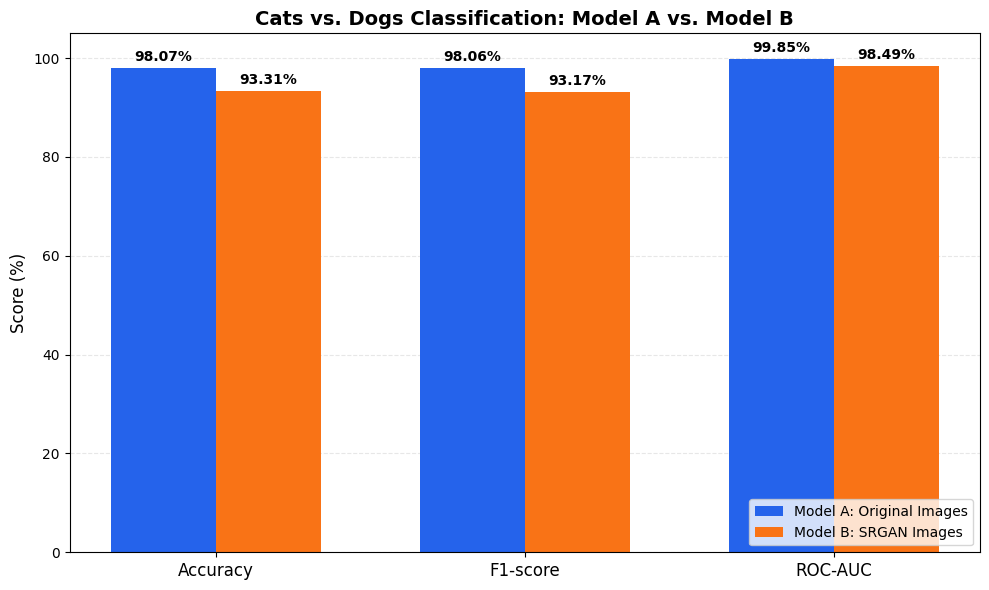


Figure saved: /kaggle/working/Applied_AI_Midterm/Figures/Model_A_vs_Model_B_Performance.png
Size (KB): 139.9

SUCCESS: COMPARISON FIGURE CREATED!


In [41]:

# ==========================================
# STEP K197: MODEL A VS MODEL B FIGURE
# ==========================================

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

print("===== STEP K197: GENERATE COMPARISON FIGURE =====")

figures_dir = Path(PROJECT_DIR) / "Figures"
figures_dir.mkdir(parents=True, exist_ok=True)

metrics = ["Accuracy", "F1", "ROC_AUC"]

model_a_values = comparison_df.iloc[0][metrics].astype(float).to_numpy()
model_b_values = comparison_df.iloc[1][metrics].astype(float).to_numpy()

x = np.arange(len(metrics))
width = 0.34

fig, ax = plt.subplots(figsize=(10, 6))

bars_a = ax.bar(
    x - width / 2,
    model_a_values * 100,
    width,
    label="Model A: Original Images",
    color="#2563EB"
)

bars_b = ax.bar(
    x + width / 2,
    model_b_values * 100,
    width,
    label="Model B: SRGAN Images",
    color="#F97316"
)

ax.set_ylabel("Score (%)", fontsize=12)
ax.set_title(
    "Cats vs. Dogs Classification: Model A vs. Model B",
    fontsize=14,
    fontweight="bold"
)

ax.set_xticks(x)
ax.set_xticklabels(
    ["Accuracy", "F1-score", "ROC-AUC"],
    fontsize=12
)

ax.set_ylim(0, 105)
ax.legend(loc="lower right")
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

for bars in [bars_a, bars_b]:
    for bar in bars:
        height = bar.get_height()
        ax.annotate(
            f"{height:.2f}%",
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            fontsize=10,
            fontweight="bold"
        )

plt.tight_layout()

figure_path = (
    figures_dir / "Model_A_vs_Model_B_Performance.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

assert figure_path.is_file()

print("\nFigure saved:", figure_path)
print("Size (KB):", round(figure_path.stat().st_size / 1024, 2))
print("\nSUCCESS: COMPARISON FIGURE CREATED!")


===== STEP K198: MODEL B CONFUSION MATRIX =====


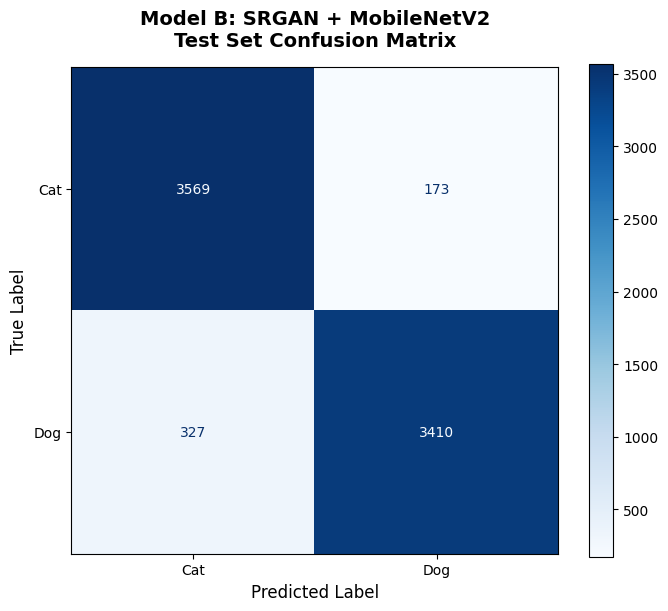


Figure saved: /kaggle/working/Applied_AI_Midterm/Figures/Model_B_Confusion_Matrix.png
Size (KB): 109.21
Correct predictions: 6979
Incorrect predictions: 500

SUCCESS: MODEL B CONFUSION MATRIX CREATED!


In [42]:

# ==========================================
# STEP K198: MODEL B CONFUSION MATRIX FIGURE
# ==========================================

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import ConfusionMatrixDisplay

print("===== STEP K198: MODEL B CONFUSION MATRIX =====")

figures_dir = Path(PROJECT_DIR) / "Figures"
figures_dir.mkdir(parents=True, exist_ok=True)

cm = np.asarray(model_b_confusion_matrix)

assert cm.shape == (2, 2)
assert cm.sum() == 7479

fig, ax = plt.subplots(figsize=(7, 6))

display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Cat", "Dog"]
)

display_cm.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=True
)

ax.set_title(
    "Model B: SRGAN + MobileNetV2\nTest Set Confusion Matrix",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Predicted Label", fontsize=12)
ax.set_ylabel("True Label", fontsize=12)

plt.tight_layout()

figure_path = figures_dir / "Model_B_Confusion_Matrix.png"

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("\nFigure saved:", figure_path)
print("Size (KB):", round(figure_path.stat().st_size / 1024, 2))
print("Correct predictions:", int(np.trace(cm)))
print("Incorrect predictions:", int(cm.sum() - np.trace(cm)))

assert figure_path.is_file()

print("\nSUCCESS: MODEL B CONFUSION MATRIX CREATED!")


===== STEP K199: MODEL B ROC CURVE =====


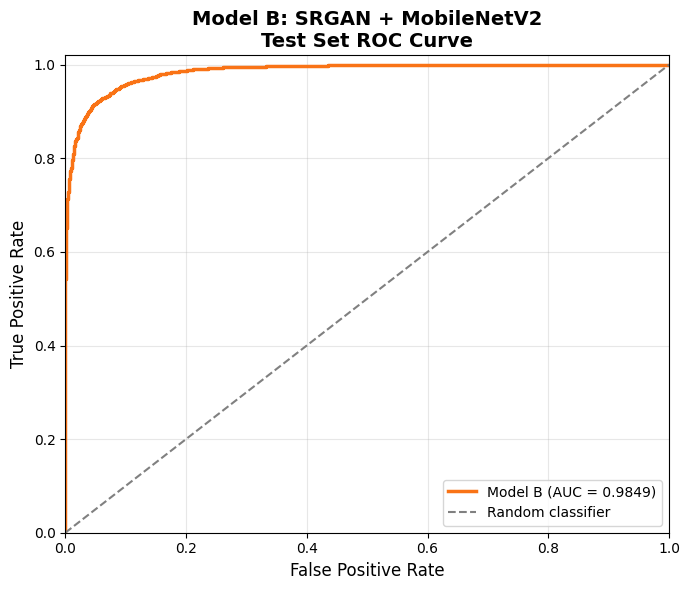


ROC-AUC: 0.984887
Figure saved: /kaggle/working/Applied_AI_Midterm/Figures/Model_B_ROC_Curve.png
Size (KB): 150.01

SUCCESS: MODEL B ROC CURVE CREATED!


In [43]:

# ==========================================
# STEP K199: MODEL B ROC CURVE
# ==========================================

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import roc_curve, roc_auc_score

print("===== STEP K199: MODEL B ROC CURVE =====")

figures_dir = Path(PROJECT_DIR) / "Figures"
figures_dir.mkdir(parents=True, exist_ok=True)

assert len(y_true_b) == 7479
assert len(model_b_probabilities) == 7479

fpr_b, tpr_b, thresholds_b = roc_curve(
    y_true_b,
    model_b_probabilities
)

auc_b = roc_auc_score(
    y_true_b,
    model_b_probabilities
)

fig, ax = plt.subplots(figsize=(7, 6))

ax.plot(
    fpr_b,
    tpr_b,
    linewidth=2.5,
    color="#F97316",
    label=f"Model B (AUC = {auc_b:.4f})"
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    linewidth=1.5,
    label="Random classifier"
)

ax.set_xlabel("False Positive Rate", fontsize=12)
ax.set_ylabel("True Positive Rate", fontsize=12)

ax.set_title(
    "Model B: SRGAN + MobileNetV2\nTest Set ROC Curve",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.grid(alpha=0.3)
ax.legend(loc="lower right")

plt.tight_layout()

figure_path = figures_dir / "Model_B_ROC_Curve.png"

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

assert figure_path.is_file()

print("\nROC-AUC:", round(auc_b, 6))
print("Figure saved:", figure_path)
print("Size (KB):", round(figure_path.stat().st_size / 1024, 2))

print("\nSUCCESS: MODEL B ROC CURVE CREATED!")


In [44]:

# ==========================================
# STEP K200: FIND MODEL A TEST PREDICTIONS
# ==========================================

from pathlib import Path
import pandas as pd

print("===== STEP K200: LOCATE MODEL A PREDICTIONS =====")

project_path = Path(PROJECT_DIR)

# Search for previously saved Model A prediction files
candidate_files = sorted(
    path for path in project_path.rglob("*.csv")
    if (
        "model_a" in path.name.lower()
        or "prediction" in path.name.lower()
        or "test_result" in path.name.lower()
    )
)

print("\nPotential prediction files:")

if not candidate_files:
    print("No matching CSV files found.")

for path in candidate_files:
    print("\nFile:", path.relative_to(project_path))

    try:
        df_preview = pd.read_csv(path, nrows=3)
        print("Columns:", df_preview.columns.tolist())
        print(df_preview.to_string(index=False))
    except Exception as error:
        print("Could not preview:", str(error)[:200])

# Check whether prediction arrays already exist in memory
possible_variables = [
    "model_a_probabilities",
    "model_a_predictions",
    "y_prob_a",
    "y_pred_proba_a",
    "model_a_prediction_df"
]

print("\nPreviously defined prediction variables:")

for name in possible_variables:
    if name in globals():
        value = globals()[name]
        print(name, "| type:", type(value).__name__)
    else:
        print(name, "| not found")

print("\nSUCCESS: MODEL A PREDICTION SEARCH COMPLETE!")
print("No training or evaluation performed.")


===== STEP K200: LOCATE MODEL A PREDICTIONS =====

Potential prediction files:

File: model_A_test_results.csv
Columns: ['Model', 'Accuracy', 'Precision', 'Recall', 'F1', 'ROC_AUC']
  Model  Accuracy  Precision   Recall       F1  ROC_AUC
Model A  0.980746   0.988047 0.973241 0.980588  0.99847

File: model_b_test_predictions.csv
Columns: ['filepath', 'true_label', 'predicted_label', 'dog_probability']
                                                                                                                  filepath  true_label  predicted_label  dog_probability
/kaggle/input/datasets/blourdhuraju/dogs-vs-cats-classification/dogs-vs-cats-classification/train/dogs/dog_train_02395.jpg           1                1         0.998958
/kaggle/input/datasets/blourdhuraju/dogs-vs-cats-classification/dogs-vs-cats-classification/train/dogs/dog_train_00131.jpg           1                1         0.999897
/kaggle/input/datasets/blourdhuraju/dogs-vs-cats-classification/dogs-vs-cats-classificati

In [45]:

# ==========================================
# STEP K201: RECOVER MODEL A TEST PREDICTIONS
# ==========================================

import numpy as np
import pandas as pd
import tensorflow as tf
from pathlib import Path
import time

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score
)

print("===== STEP K201: RECOVER MODEL A PREDICTIONS =====")

model_a_path = (
    Path(PROJECT_DIR)
    / "Model_A_Checkpoints"
    / "Fine_Tuning"
    / "model_A_finetuned_best.keras"
)

assert model_a_path.is_file()
assert len(test_df) == 7479

# Load the existing trained Model A
model_a_final = tf.keras.models.load_model(
    str(model_a_path),
    compile=False
)

# Match Model A's original 128x128 input preprocessing.
# Do not use SRGAN for Model A.
def load_model_a_test_image(filepath, label):
    _, original_128 = load_srgan_pair(filepath)
    return original_128, tf.cast(label, tf.float32)

model_a_test_dataset = (
    tf.data.Dataset.from_tensor_slices((
        test_df["filepath"].astype(str).to_numpy(),
        test_df["label"].astype(np.float32).to_numpy()
    ))
    .map(
        load_model_a_test_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )
    .batch(16)
    .prefetch(tf.data.AUTOTUNE)
)

start_time = time.time()

model_a_probabilities = model_a_final.predict(
    model_a_test_dataset,
    verbose=1
).reshape(-1)

model_a_predictions = (
    model_a_probabilities >= 0.5
).astype(int)

y_true_a = test_df["label"].to_numpy().astype(int)

assert len(model_a_probabilities) == 7479
assert np.isfinite(model_a_probabilities).all()
assert np.array_equal(y_true_a, y_true_b)

recovered_accuracy = accuracy_score(
    y_true_a, model_a_predictions
)
recovered_f1 = f1_score(
    y_true_a, model_a_predictions
)
recovered_auc = roc_auc_score(
    y_true_a, model_a_probabilities
)

# Save probabilities for ROC analysis and reproducibility
model_a_prediction_path = (
    Path(PROJECT_DIR) / "model_a_test_predictions.csv"
)

pd.DataFrame({
    "filepath": test_df["filepath"].to_numpy(),
    "true_label": y_true_a,
    "predicted_label": model_a_predictions,
    "dog_probability": model_a_probabilities
}).to_csv(model_a_prediction_path, index=False)

# Check consistency with the original saved evaluation
original_metrics = pd.read_csv(
    Path(PROJECT_DIR) / "model_A_test_results.csv"
).iloc[0]

print("\n===== RECOVERED MODEL A METRICS =====")
print("Accuracy:", round(recovered_accuracy, 6))
print("F1-score:", round(recovered_f1, 6))
print("ROC-AUC:", round(recovered_auc, 6))

print("\n===== ORIGINAL MODEL A METRICS =====")
print("Accuracy:", round(float(original_metrics["Accuracy"]), 6))
print("F1-score:", round(float(original_metrics["F1"]), 6))
print("ROC-AUC:", round(float(original_metrics["ROC_AUC"]), 6))

print("\nElapsed minutes:",
      round((time.time() - start_time) / 60, 2))

print("Saved:", model_a_prediction_path)

# Do not silently accept a mismatch in preprocessing
assert abs(
    recovered_accuracy - float(original_metrics["Accuracy"])
) < 0.001, "Model A accuracy mismatch: inspect preprocessing."

assert abs(
    recovered_auc - float(original_metrics["ROC_AUC"])
) < 0.001, "Model A AUC mismatch: inspect preprocessing."

print("\nSUCCESS: MODEL A PREDICTIONS RECOVERED!")
print("No model training performed.")


===== STEP K201: RECOVER MODEL A PREDICTIONS =====
189/468 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step

Corrupt JPEG data: 128 extraneous bytes before marker 0xd9
Corrupt JPEG data: 228 extraneous bytes before marker 0xd9


426/468 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step

Corrupt JPEG data: 162 extraneous bytes before marker 0xd9


468/468 ━━━━━━━━━━━━━━━━━━━━ 16s 25ms/step

===== RECOVERED MODEL A METRICS =====
Accuracy: 0.980345
F1-score: 0.980186
ROC-AUC: 0.998392

===== ORIGINAL MODEL A METRICS =====
Accuracy: 0.980746
F1-score: 0.980588
ROC-AUC: 0.99847

Elapsed minutes: 0.26
Saved: /kaggle/working/Applied_AI_Midterm/model_a_test_predictions.csv

SUCCESS: MODEL A PREDICTIONS RECOVERED!
No model training performed.


===== STEP K202: COMBINED ROC CURVES =====


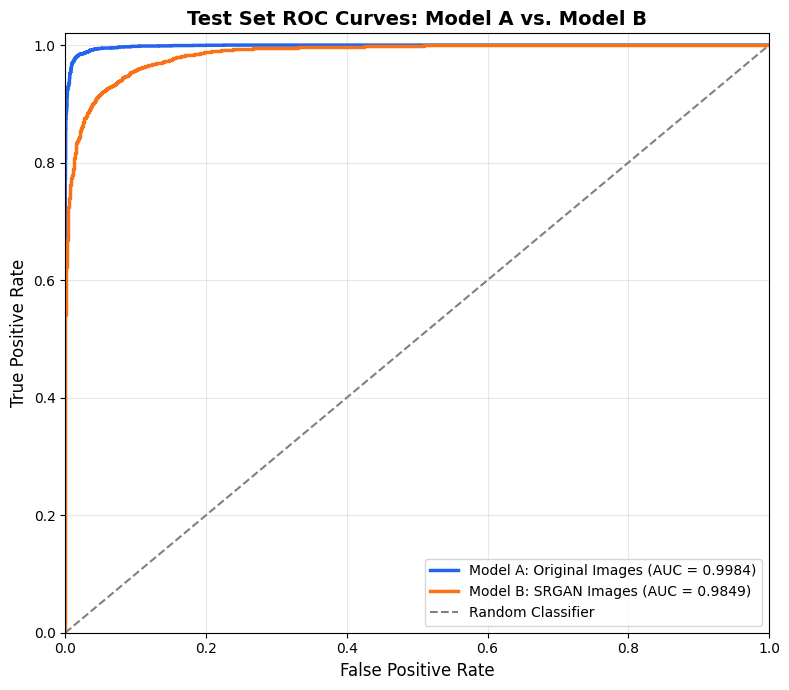


Model A ROC-AUC: 0.998392
Model B ROC-AUC: 0.984887
ROC-AUC difference (A - B): 0.013505

Saved: /kaggle/working/Applied_AI_Midterm/Figures/Model_A_vs_Model_B_ROC_Curves.png

SUCCESS: COMBINED ROC CURVES CREATED!


In [46]:

# ==========================================
# STEP K202: COMBINED MODEL A AND MODEL B ROC
# ==========================================

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import roc_curve, roc_auc_score

print("===== STEP K202: COMBINED ROC CURVES =====")

# Confirm both models were evaluated in the same order
assert len(y_true_a) == 7479
assert len(y_true_b) == 7479
assert np.array_equal(y_true_a, y_true_b)

# Calculate ROC curves from actual predicted probabilities
fpr_a, tpr_a, _ = roc_curve(
    y_true_a, model_a_probabilities
)

fpr_b, tpr_b, _ = roc_curve(
    y_true_b, model_b_probabilities
)

auc_a = roc_auc_score(y_true_a, model_a_probabilities)
auc_b = roc_auc_score(y_true_b, model_b_probabilities)

fig, ax = plt.subplots(figsize=(8, 7))

ax.plot(
    fpr_a,
    tpr_a,
    color="#2563EB",
    linewidth=2.5,
    label=f"Model A: Original Images (AUC = {auc_a:.4f})"
)

ax.plot(
    fpr_b,
    tpr_b,
    color="#F97316",
    linewidth=2.5,
    label=f"Model B: SRGAN Images (AUC = {auc_b:.4f})"
)

ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    linewidth=1.5,
    label="Random Classifier"
)

ax.set_title(
    "Test Set ROC Curves: Model A vs. Model B",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("False Positive Rate", fontsize=12)
ax.set_ylabel("True Positive Rate", fontsize=12)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.grid(alpha=0.3)
ax.legend(loc="lower right")

plt.tight_layout()

figure_path = (
    Path(PROJECT_DIR)
    / "Figures"
    / "Model_A_vs_Model_B_ROC_Curves.png"
)

plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

assert figure_path.is_file()

print("\nModel A ROC-AUC:", round(auc_a, 6))
print("Model B ROC-AUC:", round(auc_b, 6))
print("ROC-AUC difference (A - B):", round(auc_a - auc_b, 6))
print("\nSaved:", figure_path)

print("\nSUCCESS: COMBINED ROC CURVES CREATED!")


===== STEP K203: SRGAN VISUAL COMPARISON =====


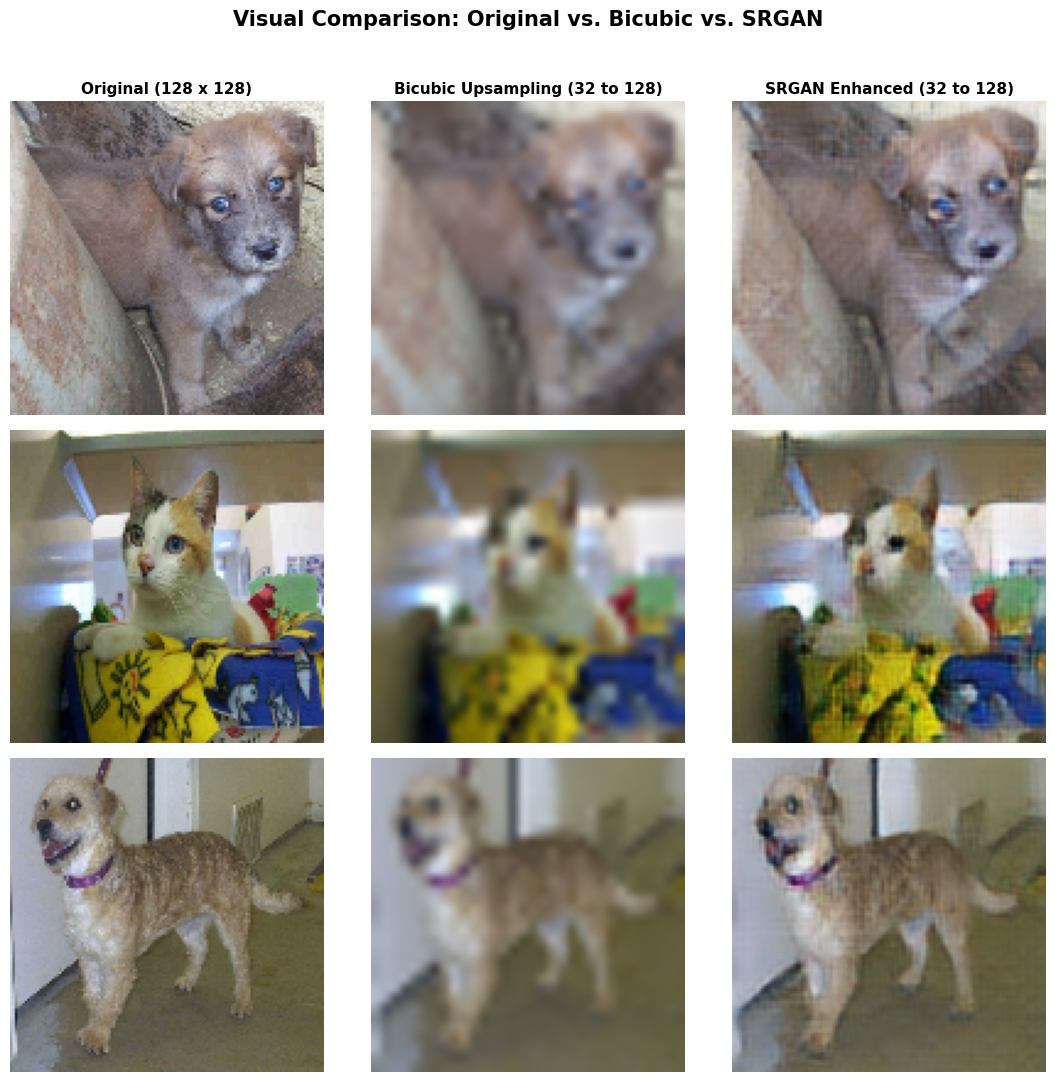


Figure saved: /kaggle/working/Applied_AI_Midterm/Figures/SRGAN_Visual_Comparison.png
Size (KB): 578.2

SUCCESS: SRGAN VISUAL COMPARISON CREATED!


In [47]:

# ==========================================
# STEP K203: SRGAN IMAGE QUALITY COMPARISON
# ==========================================

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from pathlib import Path

print("===== STEP K203: SRGAN VISUAL COMPARISON =====")

assert generator.trainable is False
assert len(test_df) == 7479

figures_dir = Path(PROJECT_DIR) / "Figures"
figures_dir.mkdir(parents=True, exist_ok=True)

# Use fixed test indices for reproducibility
sample_indices = [0, 100, 200]

fig, axes = plt.subplots(
    len(sample_indices),
    3,
    figsize=(11, 11)
)

column_titles = [
    "Original (128 x 128)",
    "Bicubic Upsampling (32 to 128)",
    "SRGAN Enhanced (32 to 128)"
]

for row, index in enumerate(sample_indices):

    image_path = test_df.iloc[index]["filepath"]
    label = int(test_df.iloc[index]["label"])
    class_name = "Cat" if label == 0 else "Dog"

    lr_image, hr_image = load_srgan_pair(image_path)

    bicubic = tf.image.resize(
        lr_image,
        [128, 128],
        method="bicubic"
    )
    bicubic = tf.clip_by_value(bicubic, 0.0, 1.0)

    srgan_image = generator(
        tf.expand_dims(lr_image, axis=0),
        training=False
    )[0]
    srgan_image = tf.clip_by_value(
        srgan_image, 0.0, 1.0
    )

    images = [
        hr_image.numpy(),
        bicubic.numpy(),
        srgan_image.numpy()
    ]

    for col, image in enumerate(images):
        axes[row, col].imshow(image)
        axes[row, col].axis("off")

        if row == 0:
            axes[row, col].set_title(
                column_titles[col],
                fontsize=11,
                fontweight="bold"
            )

        if col == 0:
            axes[row, col].set_ylabel(
                f"Sample {index} ({class_name})",
                fontsize=11
            )

fig.suptitle(
    "Visual Comparison: Original vs. Bicubic vs. SRGAN",
    fontsize=15,
    fontweight="bold",
    y=0.98
)

plt.tight_layout(rect=[0, 0, 1, 0.96])

figure_path = (
    figures_dir / "SRGAN_Visual_Comparison.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

assert figure_path.is_file()

print("\nFigure saved:", figure_path)
print("Size (KB):", round(figure_path.stat().st_size / 1024, 2))

print("\nSUCCESS: SRGAN VISUAL COMPARISON CREATED!")


===== STEP K204: TRAINING CURVES =====

Model_A available CSV logs:
 - Model_A_Checkpoints/Fine_Tuning/finetuning_log.csv
 - Model_A_Checkpoints/training_log.csv

Model_B available CSV logs:
 - Model_B_Checkpoints/Fine_Tuning/finetuning_log.csv
 - Model_B_Checkpoints/Initial_Training/training_log.csv


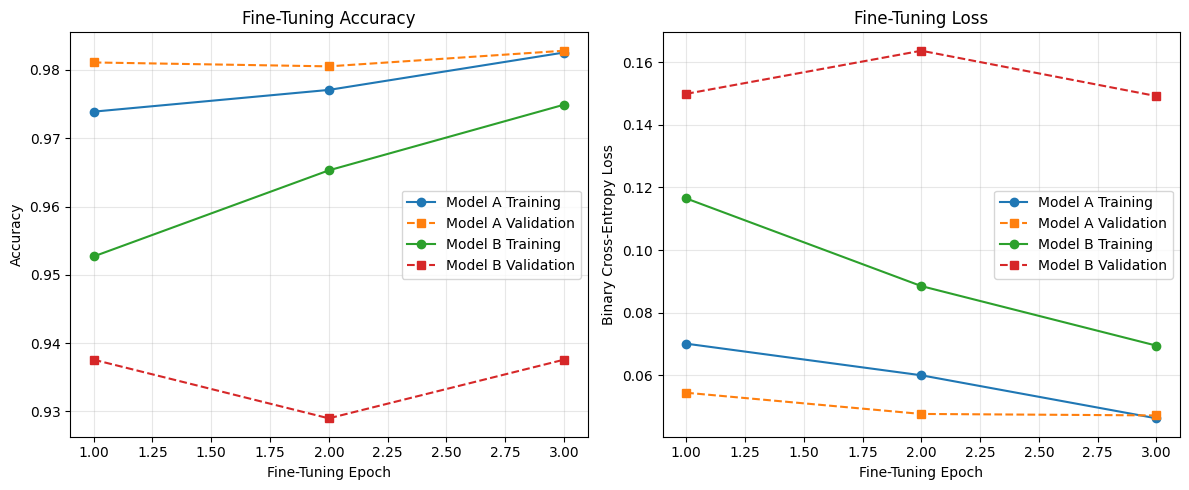


Figure saved: /kaggle/working/Applied_AI_Midterm/Figures/Model_A_vs_Model_B_Fine_Tuning_Curves.png

SUCCESS: FINE-TUNING CURVES CREATED!


In [48]:

# ==========================================
# STEP K204: CLASSIFIER TRAINING CURVES
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

print("===== STEP K204: TRAINING CURVES =====")

project_path = Path(PROJECT_DIR)
figures_dir = project_path / "Figures"
figures_dir.mkdir(parents=True, exist_ok=True)

# Locate existing training histories; never retrain
for model_name in ["Model_A", "Model_B"]:
    print(f"\n{model_name} available CSV logs:")
    for path in sorted(
        (project_path / f"{model_name}_Checkpoints").rglob("*.csv")
    ):
        print(" -", path.relative_to(project_path))

# Model A and Model B fine-tuning logs are known.
a_fine_path = (
    project_path / "Model_A_Checkpoints"
    / "Fine_Tuning" / "finetuning_log.csv"
)
b_fine_path = (
    project_path / "Model_B_Checkpoints"
    / "Fine_Tuning" / "finetuning_log.csv"
)

assert a_fine_path.is_file()
assert b_fine_path.is_file()

a_fine = pd.read_csv(a_fine_path)
b_fine = pd.read_csv(b_fine_path)

# Plot fine-tuning curves for both models
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

epochs = np.arange(1, len(a_fine) + 1)

axes[0].plot(
    epochs, a_fine["accuracy"],
    "o-", label="Model A Training"
)
axes[0].plot(
    epochs, a_fine["val_accuracy"],
    "s--", label="Model A Validation"
)

epochs_b = np.arange(1, len(b_fine) + 1)

axes[0].plot(
    epochs_b, b_fine["accuracy"],
    "o-", label="Model B Training"
)
axes[0].plot(
    epochs_b, b_fine["val_accuracy"],
    "s--", label="Model B Validation"
)

axes[0].set_title("Fine-Tuning Accuracy")
axes[0].set_xlabel("Fine-Tuning Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].plot(
    np.arange(1, len(a_fine) + 1),
    a_fine["loss"],
    "o-", label="Model A Training"
)
axes[1].plot(
    np.arange(1, len(a_fine) + 1),
    a_fine["val_loss"],
    "s--", label="Model A Validation"
)
axes[1].plot(
    np.arange(1, len(b_fine) + 1),
    b_fine["loss"],
    "o-", label="Model B Training"
)
axes[1].plot(
    np.arange(1, len(b_fine) + 1),
    b_fine["val_loss"],
    "s--", label="Model B Validation"
)

axes[1].set_title("Fine-Tuning Loss")
axes[1].set_xlabel("Fine-Tuning Epoch")
axes[1].set_ylabel("Binary Cross-Entropy Loss")
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()

figure_path = (
    figures_dir / "Model_A_vs_Model_B_Fine_Tuning_Curves.png"
)

plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

assert figure_path.is_file()

print("\nFigure saved:", figure_path)
print("\nSUCCESS: FINE-TUNING CURVES CREATED!")


===== STEP K205: COMPLETE TRAINING CURVES =====


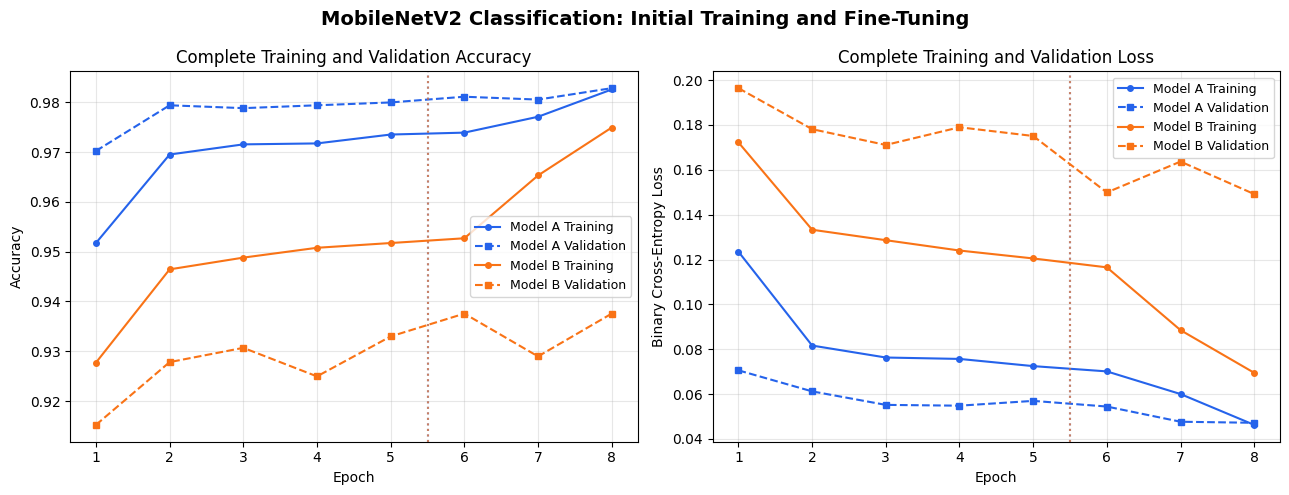


Model A initial epochs: 5
Model A fine-tuning epochs: 3
Model B initial epochs: 5
Model B fine-tuning epochs: 3

Saved: /kaggle/working/Applied_AI_Midterm/Figures/Model_A_vs_Model_B_Complete_Training.png

SUCCESS: COMPLETE TRAINING CURVES CREATED!


In [49]:

# ==========================================
# STEP K205: COMPLETE CLASSIFIER TRAINING CURVES
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

print("===== STEP K205: COMPLETE TRAINING CURVES =====")

project_path = Path(PROJECT_DIR)
figures_dir = project_path / "Figures"

a_initial = pd.read_csv(
    project_path / "Model_A_Checkpoints" / "training_log.csv"
)

a_fine = pd.read_csv(
    project_path / "Model_A_Checkpoints"
    / "Fine_Tuning" / "finetuning_log.csv"
)

b_initial = pd.read_csv(
    project_path / "Model_B_Checkpoints"
    / "Initial_Training" / "training_log.csv"
)

b_fine = pd.read_csv(
    project_path / "Model_B_Checkpoints"
    / "Fine_Tuning" / "finetuning_log.csv"
)

def combine_history(initial, fine):
    columns = ["accuracy", "val_accuracy", "loss", "val_loss"]

    assert all(col in initial.columns for col in columns)
    assert all(col in fine.columns for col in columns)

    combined = pd.concat(
        [initial[columns], fine[columns]],
        ignore_index=True
    )

    combined["epoch_number"] = np.arange(1, len(combined) + 1)

    return combined

a_history = combine_history(a_initial, a_fine)
b_history = combine_history(b_initial, b_fine)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

colors = {
    "Model A": "#2563EB",
    "Model B": "#F97316"
}

for model_name, history, initial_length in [
    ("Model A", a_history, len(a_initial)),
    ("Model B", b_history, len(b_initial))
]:
    color = colors[model_name]

    axes[0].plot(
        history["epoch_number"],
        history["accuracy"],
        "-o",
        color=color,
        label=f"{model_name} Training",
        markersize=4
    )

    axes[0].plot(
        history["epoch_number"],
        history["val_accuracy"],
        "--s",
        color=color,
        label=f"{model_name} Validation",
        markersize=4
    )

    axes[1].plot(
        history["epoch_number"],
        history["loss"],
        "-o",
        color=color,
        label=f"{model_name} Training",
        markersize=4
    )

    axes[1].plot(
        history["epoch_number"],
        history["val_loss"],
        "--s",
        color=color,
        label=f"{model_name} Validation",
        markersize=4
    )

    for ax in axes:
        ax.axvline(
            initial_length + 0.5,
            color=color,
            linestyle=":",
            alpha=0.65
        )

axes[0].set_title("Complete Training and Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")

axes[1].set_title("Complete Training and Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Binary Cross-Entropy Loss")

for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend(fontsize=9)

fig.suptitle(
    "MobileNetV2 Classification: Initial Training and Fine-Tuning",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

figure_path = (
    figures_dir / "Model_A_vs_Model_B_Complete_Training.png"
)

plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print("\nModel A initial epochs:", len(a_initial))
print("Model A fine-tuning epochs:", len(a_fine))
print("Model B initial epochs:", len(b_initial))
print("Model B fine-tuning epochs:", len(b_fine))

print("\nSaved:", figure_path)
print("\nSUCCESS: COMPLETE TRAINING CURVES CREATED!")


In [50]:

# ==========================================
# STEP K206: AUDIT PROJECT FILES
# ==========================================

from pathlib import Path
import pandas as pd

print("===== STEP K206: PROJECT FILE AUDIT =====")

project_path = Path(PROJECT_DIR)

required_files = {
    "Model A best checkpoint":
        "Model_A_Checkpoints/Fine_Tuning/model_A_finetuned_best.keras",

    "Model B best checkpoint":
        "Model_B_Checkpoints/Fine_Tuning/model_B_finetuned_best.keras",

    "Model A test metrics":
        "model_A_test_results.csv",

    "Model B test metrics":
        "model_b_test_metrics.csv",

    "Model A predictions":
        "model_a_test_predictions.csv",

    "Model B predictions":
        "model_b_test_predictions.csv",

    "Final model comparison":
        "final_model_comparison.csv",

    "SRGAN quality metrics":
        "srgan_final_quality_metrics.csv",

    "Performance comparison figure":
        "Figures/Model_A_vs_Model_B_Performance.png",

    "Combined ROC curves":
        "Figures/Model_A_vs_Model_B_ROC_Curves.png",

    "Model B confusion matrix":
        "Figures/Model_B_Confusion_Matrix.png",

    "SRGAN visual comparison":
        "Figures/SRGAN_Visual_Comparison.png",

    "Complete training curves":
        "Figures/Model_A_vs_Model_B_Complete_Training.png",
}

missing_files = []

print("\n===== REQUIRED FILES =====")

for description, relative_path in required_files.items():
    file_path = project_path / relative_path
    exists = file_path.is_file()

    status = "FOUND" if exists else "MISSING"
    print(f"{status:8} | {description}")

    if not exists:
        missing_files.append(relative_path)

print("\n===== TOP-LEVEL PROJECT CONTENTS =====")

for path in sorted(project_path.iterdir()):
    if path.is_dir():
        print("[DIR] ", path.name)
    else:
        print("[FILE]", path.name)

print("\n===== PYTHON AND NOTEBOOK FILES =====")

code_files = sorted(
    path for path in project_path.rglob("*")
    if path.is_file()
    and path.suffix.lower() in [".py", ".ipynb"]
)

for path in code_files[:50]:
    print(path.relative_to(project_path))

print("\nTotal Python/notebook files:", len(code_files))
print("Missing required files:", len(missing_files))

if missing_files:
    print("\nMissing files:")
    for name in missing_files:
        print(" -", name)

print("\nSUCCESS: PROJECT AUDIT COMPLETE!")
print("No files modified and no training performed.")


===== STEP K206: PROJECT FILE AUDIT =====

===== REQUIRED FILES =====
FOUND    | Model A best checkpoint
FOUND    | Model B best checkpoint
FOUND    | Model A test metrics
FOUND    | Model B test metrics
FOUND    | Model A predictions
FOUND    | Model B predictions
FOUND    | Final model comparison
FOUND    | SRGAN quality metrics
FOUND    | Performance comparison figure
FOUND    | Combined ROC curves
FOUND    | Model B confusion matrix
FOUND    | SRGAN visual comparison
FOUND    | Complete training curves

===== TOP-LEVEL PROJECT CONTENTS =====
[DIR]  Figures
[DIR]  Model_A_Checkpoints
[DIR]  Model_B_Cache
[DIR]  Model_B_Checkpoints
[DIR]  Repaired_Images
[DIR]  SRGAN_Checkpoints
[DIR]  __pycache__
[FILE] data_pipeline.py
[FILE] dataset_verification.pkl
[FILE] final_model_comparison.csv
[FILE] model_A_test_results.csv
[FILE] model_a_test_predictions.csv
[FILE] model_b_test_metrics.csv
[FILE] model_b_test_predictions.csv
[FILE] model_train_split.csv
[FILE] model_train_split.csv.origina

In [51]:

# ==========================================
# STEP K207: CHECK NOTEBOOK AND PROJECT SIZES
# ==========================================

from pathlib import Path

print("===== STEP K207: NOTEBOOK AND PROJECT INVENTORY =====")

working_dir = Path("/kaggle/working")
project_path = Path(PROJECT_DIR)

print("\nNotebook files in Kaggle working directory:")

notebooks = sorted(working_dir.rglob("*.ipynb"))

if notebooks:
    for notebook in notebooks[:30]:
        print(
            notebook,
            "| MB:",
            round(notebook.stat().st_size / 1024**2, 2)
        )
else:
    print("No notebook files found in /kaggle/working.")

print("\nProject directory sizes:")

for folder in sorted(project_path.iterdir()):
    if folder.is_dir():
        total_bytes = sum(
            f.stat().st_size
            for f in folder.rglob("*")
            if f.is_file()
        )
        print(
            folder.name,
            "| GB:",
            round(total_bytes / 1024**3, 3)
        )

print("\nExisting Python scripts:")

for script in sorted(project_path.glob("*.py")):
    print(
        script.name,
        "| KB:",
        round(script.stat().st_size / 1024, 2)
    )

print("\nSUCCESS: INVENTORY COMPLETE!")
print("No files modified and no training performed.")


===== STEP K207: NOTEBOOK AND PROJECT INVENTORY =====

Notebook files in Kaggle working directory:
/kaggle/working/.virtual_documents/__notebook_source__.ipynb | MB: 0.29

Project directory sizes:
Figures | GB: 0.002
Model_A_Checkpoints | GB: 0.135
Model_B_Cache | GB: 4.565
Model_B_Checkpoints | GB: 0.125
Repaired_Images | GB: 0.0
SRGAN_Checkpoints | GB: 0.345
__pycache__ | GB: 0.0

Existing Python scripts:
data_pipeline.py | KB: 1.61
srgan_models.py | KB: 2.48

SUCCESS: INVENTORY COMPLETE!
No files modified and no training performed.


In [52]:

# ==========================================
# STEP K208: EXPORT KAGGLE NOTEBOOK
# ==========================================

from pathlib import Path
import shutil
import json
from IPython.display import FileLink, display

print("===== STEP K208: EXPORT KAGGLE NOTEBOOK =====")

source_notebook = Path(
    "/kaggle/working/.virtual_documents/__notebook_source__.ipynb"
)

export_folder = Path(PROJECT_DIR) / "Notebooks"
export_folder.mkdir(parents=True, exist_ok=True)

export_path = export_folder / "02_Kaggle_Training_and_Evaluation.ipynb"

assert source_notebook.is_file(), "Kaggle notebook source not found."

# Prevent overwriting an existing backup
assert not export_path.exists(), (
    "Notebook export already exists. "
    "Check it before creating another copy."
)

shutil.copy2(source_notebook, export_path)

# Verify that the exported notebook is valid
with open(export_path, "r", encoding="utf-8") as f:
    notebook_data = json.load(f)

assert notebook_data.get("nbformat") == 4
assert "cells" in notebook_data
assert len(notebook_data["cells"]) > 0

code_cells = sum(
    cell.get("cell_type") == "code"
    for cell in notebook_data["cells"]
)

print("Notebook:", export_path.name)
print("Total cells:", len(notebook_data["cells"]))
print("Code cells:", code_cells)
print("File size (MB):", round(export_path.stat().st_size / 1024**2, 3))

print("\nSUCCESS: KAGGLE NOTEBOOK EXPORTED!")
print("No training performed.")

display(FileLink(str(export_path)))


===== STEP K208: EXPORT KAGGLE NOTEBOOK =====


JSONDecodeError: Expecting value: line 1 column 1 (char 0)

In [53]:

# ==========================================
# STEP K209: DIAGNOSE NOTEBOOK EXPORT
# ==========================================

from pathlib import Path
import json

print("===== STEP K209: DIAGNOSE NOTEBOOK EXPORT =====")

source_path = Path(
    "/kaggle/working/.virtual_documents/__notebook_source__.ipynb"
)

copied_path = (
    Path(PROJECT_DIR)
    / "Notebooks"
    / "02_Kaggle_Training_and_Evaluation.ipynb"
)

for description, path in [
    ("Kaggle virtual source", source_path),
    ("Previously copied notebook", copied_path)
]:
    print(f"\n===== {description} =====")
    print("Exists:", path.is_file())

    if not path.is_file():
        continue

    print("Size (bytes):", path.stat().st_size)

    raw = path.read_bytes()
    print("First 120 bytes:", repr(raw[:120]))

    try:
        content = json.loads(raw.decode("utf-8"))
        print("Valid JSON: YES")
        print("Notebook format:", content.get("nbformat"))
        print("Number of cells:", len(content.get("cells", [])))
    except Exception as error:
        print("Valid notebook JSON: NO")
        print("Reason:", str(error)[:200])

print("\nSUCCESS: DIAGNOSTIC CHECK COMPLETE!")
print("No files modified.")
print("No training performed.")


===== STEP K209: DIAGNOSE NOTEBOOK EXPORT =====

===== Kaggle virtual source =====
Exists: True
Size (bytes): 302978
First 120 bytes: b'# This Python 3 environment comes with many helpful analytics libraries installed\n# It is defined by the kaggle/python D'
Valid notebook JSON: NO
Reason: Expecting value: line 1 column 1 (char 0)

===== Previously copied notebook =====
Exists: True
Size (bytes): 301741
First 120 bytes: b'# This Python 3 environment comes with many helpful analytics libraries installed\n# It is defined by the kaggle/python D'
Valid notebook JSON: NO
Reason: Expecting value: line 1 column 1 (char 0)

SUCCESS: DIAGNOSTIC CHECK COMPLETE!
No files modified.
No training performed.
